In [3]:
import os
import pandas as pd

# -------------------------------------------------------
# 1. FIND THE CLINICAL EXCEL FILE
# -------------------------------------------------------
excel_files = []

for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        if f.lower().endswith((".xlsx", ".xls")):
            excel_files.append(os.path.join(root, f))

print("=" * 80)
print("EXCEL FILES FOUND")
print("=" * 80)

for f in excel_files:
    print(f)

# -------------------------------------------------------
# 2. LOAD THE CLINICAL FILE
# -------------------------------------------------------
clinical_file = [
    f for f in excel_files
    if "ClinicalData" in os.path.basename(f)
][0]

print("\nSelected clinical file:")
print(clinical_file)

xls = pd.ExcelFile(clinical_file)

print("\nSheets:")
print(xls.sheet_names)

# -------------------------------------------------------
# 3. READ BOTH SHEETS
# -------------------------------------------------------
dictionary = pd.read_excel(
    clinical_file,
    sheet_name="Data Dictionary"
)

clinical = pd.read_excel(
    clinical_file,
    sheet_name="MU Glioma Post"
)

print("\n" + "=" * 80)
print("CLINICAL DATASET")
print("=" * 80)

print("Rows   :", clinical.shape[0])
print("Columns:", clinical.shape[1])

print("\nColumn names:")
for i, col in enumerate(clinical.columns, 1):
    print(f"{i:02d}. {col}")

print("\nFirst 5 rows:")
display(clinical.head())

print("\n" + "=" * 80)
print("DATA DICTIONARY")
print("=" * 80)

print("Shape:", dictionary.shape)
display(dictionary)

EXCEL FILES FOUND
/kaggle/input/datasets/atulkrrai/mu-glioma-post-clinical-data-2025/MU-Glioma-Post_ClinicalData-July2025.xlsx

Selected clinical file:
/kaggle/input/datasets/atulkrrai/mu-glioma-post-clinical-data-2025/MU-Glioma-Post_ClinicalData-July2025.xlsx

Sheets:
['Data Dictionary', 'MU Glioma Post']

CLINICAL DATASET
Rows   : 203
Columns: 74

Column names:
01. Patient_ID
02. Sex at Birth
03. Race
04. Age at diagnosis
05. Primary Diagnosis
06. Grade of Primary Brain Tumor
07. Stereotactic Biopsy before Surgical Resection
08. Progression
09. Time to First Progression (Days)
10. Type of 1st Progression
11. Second Progression/Recurrence
12. Type of 2nd Progression
13. Multiple surgeries
14. Hospice
15. Overall Survival (Death)
16. Number of days from Diagnosis to death (Days)
17. IDH1 mutation
18. IDH2 mutation
19. 1p/19q
20. ATRX mutation
21. MGMT methylation
22. BRAF V600E mutation
23. TERT promoter mutation
24. Chromosome 7 gain and Chromosome 10 loss
25. H3-3A mutation
26. EGFR 

,Patient_ID,Sex at Birth,Race,Age at diagnosis,Primary Diagnosis,Grade of Primary Brain Tumor,Stereotactic Biopsy before Surgical Resection,Progression,Time to First Progression (Days),Type of 1st Progression,...,Number of Days from Diagnosis to the day of Insertion of Brachytherapy,"Other Types of Therapy (LITT, more chemo, proton therapy)",Number of Days from Diagnosis to Start Other Additional Therapy,Number of Days from Diagnosis to Complete Other Additional Therapy,Number of Days from Diagnosis to 1st MRI (Timepoint_1),Number of Days from Diagnosis to 2nd MRI (Timepoint_2),Number of Days from Diagnosis to 3rd MRI (Timepoint_3),Number of Days from Diagnosis to 4th MRI (Timepoint_4),Number of Days from Diagnosis to 5th MRI (Timepoint_5),Number of Days from Diagnosis to 6th MRI (Timepoint_6)
0,PatientID_0003,Female,White,57,GBM,4,0,1,286.0,3,...,-5.0,NaN,NaN,NaN,90.0,146.0,NaN,NaN,286.0,NaN
1,PatientID_0004,Female,White,67,GBM,4,0,0,NaN,0,...,NaN,NaN,NaN,NaN,67.0,NaN,NaN,NaN,NaN,NaN
2,PatientID_0005,Male,White,49,GBM,4,0,1,344.0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,133.0,176.0,NaN,NaN
3,PatientID_0006,Male,White,60,GBM,4,0,1,175.0,1,...,NaN,NaN,NaN,NaN,NaN,175.0,186.0,217.0,259.0,450.0
4,PatientID_0007,Male,White,79,GBM,4,0,0,NaN,0,...,NaN,NaN,NaN,NaN,NaN,0.0,NaN,178.0,264.0,366.0



DATA DICTIONARY
Shape: (184, 2)


,Data Collection Name,Data Descriptor /Metadata Name
0,Sex at Birth,Female
1,NaN,Male
2,Race,White
3,NaN,Black or African American
4,NaN,Asian
...,...,...
179,Number of Days from Diagnosis to 2nd MRI (Time...,Indicate the # of days from the Time of Diagno...
180,Number of Days from Diagnosis to 3rd MRI (Time...,Indicate the # of days from the Time of Diagno...
181,Number of Days from Diagnosis to 4th MRI (Time...,Indicate the # of days from the Time of Diagno...
182,Number of Days from Diagnosis to 5th MRI (Time...,Indicate the # of days from the Time of Diagno...


In [4]:
import os
import re
import pandas as pd
import numpy as np
from collections import Counter

# ==========================================================
# MU-GLIOMA-POST: LONGITUDINAL COHORT AUDIT
# ==========================================================

# ----------------------------------------------------------
# 1. Find imaging dataset root
# ----------------------------------------------------------

candidate_roots = []

for root, dirs, files in os.walk("/kaggle/input"):
    patient_dirs = [
        d for d in dirs
        if re.fullmatch(r"PatientID_\d+", d)
    ]

    if len(patient_dirs) > 20:
        candidate_roots.append((root, len(patient_dirs)))

print("=" * 80)
print("POSSIBLE IMAGING ROOTS")
print("=" * 80)

for r, n in candidate_roots:
    print(n, r)

# choose root containing the most patient folders
image_root = max(candidate_roots, key=lambda x: x[1])[0]

print("\nSelected imaging root:")
print(image_root)


# ----------------------------------------------------------
# 2. Scan patient/timepoint directories
# ----------------------------------------------------------

records = []

required_files = [
    "brain_t1c.nii",
    "brain_t1n.nii",
    "brain_t2f.nii",
    "brain_t2w.nii",
    "tumorMask.nii"
]

for patient in sorted(os.listdir(image_root)):

    patient_path = os.path.join(image_root, patient)

    if not (
        os.path.isdir(patient_path) and
        re.fullmatch(r"PatientID_\d+", patient)
    ):
        continue

    timepoints = []

    for item in os.listdir(patient_path):

        tp_path = os.path.join(patient_path, item)

        if (
            os.path.isdir(tp_path) and
            re.fullmatch(r"Timepoint_\d+", item)
        ):
            timepoints.append(item)

    timepoints = sorted(
        timepoints,
        key=lambda x: int(x.split("_")[1])
    )

    complete_tp = 0

    for tp in timepoints:

        tp_path = os.path.join(patient_path, tp)

        filenames = os.listdir(tp_path)

        # flexible check because filenames contain patient/timepoint prefixes
        suffixes = [
            "_brain_t1c.nii",
            "_brain_t1n.nii",
            "_brain_t2f.nii",
            "_brain_t2w.nii",
            "_tumorMask.nii"
        ]

        complete = all(
            any(f.endswith(s) for f in filenames)
            for s in suffixes
        )

        if complete:
            complete_tp += 1

    records.append({
        "Patient_ID": patient,
        "Imaging_Timepoints": len(timepoints),
        "Complete_Timepoints": complete_tp,
        "Folders": ", ".join(timepoints)
    })


imaging_df = pd.DataFrame(records)

print("\n" + "=" * 80)
print("IMAGING DATASET SUMMARY")
print("=" * 80)

print("Patients found:", len(imaging_df))

print("\nTimepoint distribution:")
print(
    imaging_df["Imaging_Timepoints"]
    .value_counts()
    .sort_index()
)

print("\nPatients with >=2 timepoints:",
      (imaging_df["Imaging_Timepoints"] >= 2).sum())

print("Patients with >=3 timepoints:",
      (imaging_df["Imaging_Timepoints"] >= 3).sum())

print("Patients with >=4 timepoints:",
      (imaging_df["Imaging_Timepoints"] >= 4).sum())


# ----------------------------------------------------------
# 3. Merge imaging with clinical data
# ----------------------------------------------------------

audit = clinical.merge(
    imaging_df,
    on="Patient_ID",
    how="left"
)

print("\n" + "=" * 80)
print("CLINICAL ↔ IMAGING MATCH")
print("=" * 80)

print("Clinical patients:", len(clinical))

print(
    "Patients matched to imaging:",
    audit["Imaging_Timepoints"].notna().sum()
)

print(
    "Patients without imaging match:",
    audit["Imaging_Timepoints"].isna().sum()
)


# ----------------------------------------------------------
# 4. Progression distribution
# ----------------------------------------------------------

print("\n" + "=" * 80)
print("PROGRESSION DISTRIBUTION")
print("=" * 80)

print(audit["Progression"].value_counts(dropna=False))

print("\nTime to first progression:")
print(
    audit["Time to First Progression (Days)"]
    .describe()
)


# ----------------------------------------------------------
# 5. Extract MRI timing columns
# ----------------------------------------------------------

mri_cols = [
    "Number of Days from Diagnosis to 1st MRI (Timepoint_1) ",
    "Number of Days from Diagnosis to 2nd MRI (Timepoint_2) ",
    "Number of Days from Diagnosis to 3rd MRI (Timepoint_3) ",
    "Number of Days from Diagnosis to 4th MRI (Timepoint_4) ",
    "Number of Days from Diagnosis to 5th MRI (Timepoint_5) ",
    "Number of Days from Diagnosis to 6th MRI (Timepoint_6) "
]

# ----------------------------------------------------------
# 6. Count PRE-PROGRESSION MRI scans
# ----------------------------------------------------------

def count_pre_progression(row):

    progression_time = row["Time to First Progression (Days)"]

    if pd.isna(progression_time):
        return np.nan

    times = []

    for col in mri_cols:
        value = row[col]

        if pd.notna(value):
            times.append(value)

    return sum(t < progression_time for t in times)


audit["Pre_Progression_MRIs"] = audit.apply(
    count_pre_progression,
    axis=1
)

progressors = audit[audit["Progression"] == 1]

print("\n" + "=" * 80)
print("PRE-PROGRESSION MRI AVAILABILITY")
print("=" * 80)

print(
    progressors["Pre_Progression_MRIs"]
    .value_counts(dropna=False)
    .sort_index()
)

print(
    "\nProgression patients with >=1 pre-progression MRI:",
    (progressors["Pre_Progression_MRIs"] >= 1).sum()
)

print(
    "Progression patients with >=2 pre-progression MRIs:",
    (progressors["Pre_Progression_MRIs"] >= 2).sum()
)

print(
    "Progression patients with >=3 pre-progression MRIs:",
    (progressors["Pre_Progression_MRIs"] >= 3).sum()
)


# ----------------------------------------------------------
# 7. Clinical missingness for important variables
# ----------------------------------------------------------

important_variables = [
    "Progression",
    "Time to First Progression (Days)",
    "Overall Survival (Death)",
    "Number of days from Diagnosis to death (Days)",
    "IDH1 mutation",
    "IDH2 mutation",
    "1p/19q",
    "ATRX mutation",
    "MGMT methylation",
    "EGFR amplification",
    "PTEN mutation",
    "CDKN2A/B deletion",
    "TP53 alteration"
]

missing = pd.DataFrame({
    "Variable": important_variables,
    "Missing_N": [
        audit[x].isna().sum()
        for x in important_variables
    ],
    "Missing_%": [
        round(audit[x].isna().mean()*100, 1)
        for x in important_variables
    ]
})

print("\n" + "=" * 80)
print("IMPORTANT VARIABLE MISSINGNESS")
print("=" * 80)

display(missing)


# ----------------------------------------------------------
# 8. Compact patient-level audit
# ----------------------------------------------------------

display_cols = [
    "Patient_ID",
    "Progression",
    "Time to First Progression (Days)",
    "Imaging_Timepoints",
    "Complete_Timepoints",
    "Pre_Progression_MRIs"
]

print("\nPatient-level audit:")
display(audit[display_cols].head(30))

POSSIBLE IMAGING ROOTS
203 /kaggle/input/datasets/stacyvangepuram/mu-glioma-post/PKG - MU-Glioma-Post/MU-Glioma-Post

Selected imaging root:
/kaggle/input/datasets/stacyvangepuram/mu-glioma-post/PKG - MU-Glioma-Post/MU-Glioma-Post

IMAGING DATASET SUMMARY
Patients found: 203

Timepoint distribution:
Imaging_Timepoints
1    48
2    45
3    50
4    17
5    18
6    25
Name: count, dtype: int64

Patients with >=2 timepoints: 155
Patients with >=3 timepoints: 110
Patients with >=4 timepoints: 60

CLINICAL ↔ IMAGING MATCH
Clinical patients: 203
Patients matched to imaging: 203
Patients without imaging match: 0

PROGRESSION DISTRIBUTION
Progression
1    152
0     51
Name: count, dtype: int64

Time to first progression:
count     152.000000
mean      243.907895
std       332.370840
min         4.000000
25%        95.000000
50%       171.000000
75%       270.750000
max      2126.000000
Name: Time to First Progression (Days), dtype: float64

PRE-PROGRESSION MRI AVAILABILITY
Pre_Progression_MRIs


,Variable,Missing_N,Missing_%
0,Progression,0,0.0
1,Time to First Progression (Days),51,25.1
2,Overall Survival (Death),0,0.0
3,Number of days from Diagnosis to death (Days),107,52.7
4,IDH1 mutation,0,0.0
5,IDH2 mutation,0,0.0
6,1p/19q,0,0.0
7,ATRX mutation,0,0.0
8,MGMT methylation,0,0.0
9,EGFR amplification,0,0.0



Patient-level audit:


,Patient_ID,Progression,Time to First Progression (Days),Imaging_Timepoints,Complete_Timepoints,Pre_Progression_MRIs
0,PatientID_0003,1,286.0,3,3,2.0
1,PatientID_0004,0,NaN,1,1,NaN
2,PatientID_0005,1,344.0,2,2,2.0
3,PatientID_0006,1,175.0,4,4,0.0
4,PatientID_0007,0,NaN,5,5,NaN
5,PatientID_0008,1,97.0,2,2,0.0
6,PatientID_0009,1,97.0,1,1,0.0
7,PatientID_0010,1,175.0,3,3,1.0
8,PatientID_0011,0,NaN,2,2,NaN
9,PatientID_0012,1,176.0,2,2,1.0


In [5]:
import pandas as pd
import numpy as np

# ============================================================
# MU-GLIOMA-POST
# BUILD LONGITUDINAL PATIENT × MRI TIMEPOINT TABLE
# ============================================================

# MRI timing columns from clinical dataset
mri_cols = {
    1: "Number of Days from Diagnosis to 1st MRI (Timepoint_1) ",
    2: "Number of Days from Diagnosis to 2nd MRI (Timepoint_2) ",
    3: "Number of Days from Diagnosis to 3rd MRI (Timepoint_3) ",
    4: "Number of Days from Diagnosis to 4th MRI (Timepoint_4) ",
    5: "Number of Days from Diagnosis to 5th MRI (Timepoint_5) ",
    6: "Number of Days from Diagnosis to 6th MRI (Timepoint_6) "
}

records = []

# ------------------------------------------------------------
# 1. Convert patient-level data into patient × MRI table
# ------------------------------------------------------------

for _, row in audit.iterrows():

    patient = row["Patient_ID"]
    progression = row["Progression"]
    prog_day = row["Time to First Progression (Days)"]

    for tp, col in mri_cols.items():

        mri_day = row[col]

        if pd.isna(mri_day):
            continue

        # Check that the corresponding imaging folder exists
        patient_path = os.path.join(image_root, patient)
        tp_name = f"Timepoint_{tp}"
        tp_path = os.path.join(patient_path, tp_name)

        folder_exists = os.path.isdir(tp_path)

        # ----------------------------------------------------
        # Relationship between MRI and progression
        # ----------------------------------------------------

        if progression == 1 and pd.notna(prog_day):

            days_to_progression = prog_day - mri_day

            if mri_day < prog_day:
                temporal_status = "PRE_PROGRESSION"

            elif mri_day == prog_day:
                temporal_status = "AT_PROGRESSION"

            else:
                temporal_status = "POST_PROGRESSION"

        else:

            days_to_progression = np.nan
            temporal_status = "NO_RECORDED_PROGRESSION"

        records.append({
            "Patient_ID": patient,
            "Timepoint": tp,
            "MRI_Day": mri_day,
            "Progression": progression,
            "Progression_Day": prog_day,
            "Days_to_Progression": days_to_progression,
            "Temporal_Status": temporal_status,
            "Folder_Exists": folder_exists
        })


long_df = pd.DataFrame(records)

long_df = long_df.sort_values(
    ["Patient_ID", "MRI_Day"]
).reset_index(drop=True)


# ------------------------------------------------------------
# 2. General summary
# ------------------------------------------------------------

print("=" * 80)
print("LONGITUDINAL MRI TABLE")
print("=" * 80)

print("Total MRI observations:", len(long_df))
print("Unique patients:", long_df["Patient_ID"].nunique())

print("\nTemporal status:")
print(long_df["Temporal_Status"].value_counts())

print("\nMRI folders found:")
print(long_df["Folder_Exists"].value_counts())


# ------------------------------------------------------------
# 3. PRE-PROGRESSION MRI ONLY
# ------------------------------------------------------------

pre_df = long_df[
    long_df["Temporal_Status"] == "PRE_PROGRESSION"
].copy()

print("\n" + "=" * 80)
print("LEAKAGE-FREE PRE-PROGRESSION MRI")
print("=" * 80)

print("MRI observations:", len(pre_df))
print("Patients:", pre_df["Patient_ID"].nunique())

print("\nDays from MRI to progression:")
print(pre_df["Days_to_Progression"].describe())


# ------------------------------------------------------------
# 4. Prediction-horizon analysis
# ------------------------------------------------------------

horizons = [90, 180, 365]

print("\n" + "=" * 80)
print("PROGRESSION HORIZON ANALYSIS")
print("=" * 80)

horizon_results = []

for h in horizons:

    positive = pre_df[
        (pre_df["Days_to_Progression"] > 0) &
        (pre_df["Days_to_Progression"] <= h)
    ]

    future = pre_df[
        pre_df["Days_to_Progression"] > h
    ]

    horizon_results.append({
        "Horizon_Days": h,
        "Positive_MRI": len(positive),
        "Positive_Patients": positive["Patient_ID"].nunique(),
        "Progression_Later_MRI": len(future),
        "Progression_Later_Patients": future["Patient_ID"].nunique()
    })

horizon_table = pd.DataFrame(horizon_results)

display(horizon_table)


# ------------------------------------------------------------
# 5. Number of PRE-PROGRESSION scans per patient
# ------------------------------------------------------------

pre_counts = (
    pre_df.groupby("Patient_ID")
    .size()
    .reset_index(name="Number_PreProgression_MRI")
)

print("\n" + "=" * 80)
print("PRE-PROGRESSION MRI PER PATIENT")
print("=" * 80)

print(
    pre_counts["Number_PreProgression_MRI"]
    .value_counts()
    .sort_index()
)

print("\nPatients with >=1:", len(pre_counts))

print(
    "Patients with >=2:",
    (pre_counts["Number_PreProgression_MRI"] >= 2).sum()
)

print(
    "Patients with >=3:",
    (pre_counts["Number_PreProgression_MRI"] >= 3).sum()
)


# ------------------------------------------------------------
# 6. Identify patients suitable for longitudinal modelling
# ------------------------------------------------------------

longitudinal_patients = pre_counts[
    pre_counts["Number_PreProgression_MRI"] >= 2
]["Patient_ID"]

longitudinal_df = pre_df[
    pre_df["Patient_ID"].isin(longitudinal_patients)
].copy()

print("\n" + "=" * 80)
print("LONGITUDINAL PRE-PROGRESSION COHORT")
print("=" * 80)

print(
    "Patients with >=2 pre-progression MRI:",
    longitudinal_df["Patient_ID"].nunique()
)

print(
    "MRI observations:",
    len(longitudinal_df)
)


# ------------------------------------------------------------
# 7. Calculate intervals between consecutive MRI
# ------------------------------------------------------------

longitudinal_df["Previous_MRI_Day"] = (
    longitudinal_df
    .groupby("Patient_ID")["MRI_Day"]
    .shift(1)
)

longitudinal_df["MRI_Interval_Days"] = (
    longitudinal_df["MRI_Day"] -
    longitudinal_df["Previous_MRI_Day"]
)

print("\nMRI interval statistics:")

print(
    longitudinal_df["MRI_Interval_Days"]
    .dropna()
    .describe()
)


# ------------------------------------------------------------
# 8. Display example patient sequences
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("EXAMPLE LONGITUDINAL SEQUENCES")
print("=" * 80)

display(
    long_df[
        [
            "Patient_ID",
            "Timepoint",
            "MRI_Day",
            "Progression",
            "Progression_Day",
            "Days_to_Progression",
            "Temporal_Status"
        ]
    ].head(50)
)


# ------------------------------------------------------------
# 9. Save audit files
# ------------------------------------------------------------

long_df.to_csv(
    "/kaggle/working/MU_Glioma_Longitudinal_Audit.csv",
    index=False
)

pre_df.to_csv(
    "/kaggle/working/MU_Glioma_PreProgression_MRI.csv",
    index=False
)

longitudinal_df.to_csv(
    "/kaggle/working/MU_Glioma_Longitudinal_Cohort.csv",
    index=False
)

print("\nSaved:")
print("/kaggle/working/MU_Glioma_Longitudinal_Audit.csv")
print("/kaggle/working/MU_Glioma_PreProgression_MRI.csv")
print("/kaggle/working/MU_Glioma_Longitudinal_Cohort.csv")

LONGITUDINAL MRI TABLE
Total MRI observations: 597
Unique patients: 202

Temporal status:
Temporal_Status
PRE_PROGRESSION            235
POST_PROGRESSION           180
NO_RECORDED_PROGRESSION    103
AT_PROGRESSION              79
Name: count, dtype: int64

MRI folders found:
Folder_Exists
True     593
False      4
Name: count, dtype: int64

LEAKAGE-FREE PRE-PROGRESSION MRI
MRI observations: 235
Patients: 114

Days from MRI to progression:
count     235.000000
mean      207.493617
std       329.951335
min         1.000000
25%        63.500000
50%       118.000000
75%       210.000000
max      2064.000000
Name: Days_to_Progression, dtype: float64

PROGRESSION HORIZON ANALYSIS


,Horizon_Days,Positive_MRI,Positive_Patients,Progression_Later_MRI,Progression_Later_Patients
0,90,79,65,156,80
1,180,162,102,73,37
2,365,209,108,26,14



PRE-PROGRESSION MRI PER PATIENT
Number_PreProgression_MRI
1    47
2    32
3    24
4     5
5     4
6     2
Name: count, dtype: int64

Patients with >=1: 114
Patients with >=2: 67
Patients with >=3: 35

LONGITUDINAL PRE-PROGRESSION COHORT
Patients with >=2 pre-progression MRI: 67
MRI observations: 188

MRI interval statistics:
count     121.000000
mean       90.140496
std       127.533088
min         3.000000
25%        44.000000
50%        68.000000
75%        92.000000
max      1109.000000
Name: MRI_Interval_Days, dtype: float64

EXAMPLE LONGITUDINAL SEQUENCES


,Patient_ID,Timepoint,MRI_Day,Progression,Progression_Day,Days_to_Progression,Temporal_Status
0,PatientID_0003,1,90.0,1,286.0,196.0,PRE_PROGRESSION
1,PatientID_0003,2,146.0,1,286.0,140.0,PRE_PROGRESSION
2,PatientID_0003,5,286.0,1,286.0,0.0,AT_PROGRESSION
3,PatientID_0004,1,67.0,0,NaN,NaN,NO_RECORDED_PROGRESSION
4,PatientID_0005,3,133.0,1,344.0,211.0,PRE_PROGRESSION
5,PatientID_0005,4,176.0,1,344.0,168.0,PRE_PROGRESSION
6,PatientID_0006,2,175.0,1,175.0,0.0,AT_PROGRESSION
7,PatientID_0006,3,186.0,1,175.0,-11.0,POST_PROGRESSION
8,PatientID_0006,4,217.0,1,175.0,-42.0,POST_PROGRESSION
9,PatientID_0006,5,259.0,1,175.0,-84.0,POST_PROGRESSION



Saved:
/kaggle/working/MU_Glioma_Longitudinal_Audit.csv
/kaggle/working/MU_Glioma_PreProgression_MRI.csv
/kaggle/working/MU_Glioma_Longitudinal_Cohort.csv


In [6]:
# ================================================================
# MU-GLIOMA-POST
# FINAL LEAKAGE-CONTROLLED PROGRESSION-PREDICTION COHORT
# ================================================================

import os
import numpy as np
import pandas as pd

# ------------------------------------------------
# SETTINGS
# ------------------------------------------------

PRIMARY_HORIZON = 180
SECONDARY_HORIZONS = [90]

print("=" * 90)
print("FINAL COHORT CONSTRUCTION")
print("=" * 90)

print(f"Primary prediction horizon : {PRIMARY_HORIZON} days")
print(f"Secondary horizons         : {SECONDARY_HORIZONS}")


# ================================================================
# 1. BASIC DATA CLEANING
# ================================================================

df = long_df.copy()

numeric_cols = [
    "MRI_Day",
    "Progression",
    "Progression_Day",
    "Days_to_Progression"
]

for c in numeric_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df = df[
    df["MRI_Day"].notna()
].copy()

df = df.sort_values(
    ["Patient_ID", "MRI_Day", "Timepoint"]
).reset_index(drop=True)


# ================================================================
# 2. AUDIT THE 202-vs-203 PATIENT ISSUE
# ================================================================

clinical_patients = set(clinical["Patient_ID"].dropna().astype(str))
long_patients = set(df["Patient_ID"].dropna().astype(str))

missing_from_longitudinal = sorted(
    clinical_patients - long_patients
)

print("\n" + "=" * 90)
print("PATIENT MATCH AUDIT")
print("=" * 90)

print("Clinical patients              :", len(clinical_patients))
print("Patients in longitudinal table :", len(long_patients))

print("\nClinical patients absent from longitudinal table:")
print(missing_from_longitudinal)


# ================================================================
# 3. AUDIT CLINICAL TIMEPOINTS WITHOUT IMAGE FOLDERS
# ================================================================

missing_folders = df[
    df["Folder_Exists"] == False
][
    [
        "Patient_ID",
        "Timepoint",
        "MRI_Day",
        "Temporal_Status"
    ]
].copy()

print("\n" + "=" * 90)
print("CLINICAL TIMEPOINTS WITHOUT IMAGE FOLDER")
print("=" * 90)

print("Count:", len(missing_folders))

display(missing_folders)


# ================================================================
# 4. RETAIN ONLY TIMEPOINTS WITH REAL IMAGE FOLDERS
# ================================================================

df = df[
    df["Folder_Exists"] == True
].copy()


# ================================================================
# 5. DETERMINE LAST AVAILABLE MRI FOR EACH PATIENT
# ================================================================

last_mri = (
    df.groupby("Patient_ID")["MRI_Day"]
      .max()
      .rename("Last_Available_MRI_Day")
)

df = df.merge(
    last_mri,
    on="Patient_ID",
    how="left"
)

df["MRI_Followup_After_Index"] = (
    df["Last_Available_MRI_Day"] -
    df["MRI_Day"]
)


# ================================================================
# 6. FUNCTION TO ASSIGN FIXED-HORIZON LABEL
# ================================================================
#
# LABEL = 1
#   progression occurs AFTER index MRI
#   and within prediction horizon.
#
# LABEL = 0
#   A) Progressor:
#      progression occurs more than H days after index MRI.
#
#   B) No recorded progression:
#      there is imaging follow-up >= H days after index MRI.
#
# EXCLUDE
#   - MRI at progression
#   - MRI after progression
#   - non-progressor without enough follow-up
#
# ================================================================

def assign_horizon_label(row, horizon):

    progression = row["Progression"]
    prog_day = row["Progression_Day"]
    mri_day = row["MRI_Day"]
    followup = row["MRI_Followup_After_Index"]

    # -----------------------------------------
    # Patients with documented progression
    # -----------------------------------------

    if progression == 1 and pd.notna(prog_day):

        delta = prog_day - mri_day

        # MRI on/after progression = leakage
        if delta <= 0:
            return np.nan

        # Progression within horizon
        elif delta <= horizon:
            return 1

        # Progression occurs later than horizon
        else:
            return 0

    # -----------------------------------------
    # Patients with NO recorded progression
    # -----------------------------------------

    elif progression == 0:

        # Conservative negative:
        # documented imaging observation extends
        # at least H days after this index MRI.
        if followup >= horizon:
            return 0

        else:
            return np.nan

    return np.nan


# ================================================================
# 7. CREATE LABELS FOR 90, 180 AND 365 DAYS
# ================================================================

for horizon in [90, 180, 365]:

    df[f"Label_{horizon}d"] = df.apply(
        lambda r: assign_horizon_label(r, horizon),
        axis=1
    )


# ================================================================
# 8. HORIZON COMPARISON
# ================================================================

summary = []

for horizon in [90, 180, 365]:

    col = f"Label_{horizon}d"

    temp = df[
        df[col].notna()
    ].copy()

    positives = temp[
        temp[col] == 1
    ]

    negatives = temp[
        temp[col] == 0
    ]

    summary.append({

        "Horizon_days": horizon,

        "Usable_MRI": len(temp),

        "Usable_Patients":
            temp["Patient_ID"].nunique(),

        "Positive_MRI":
            len(positives),

        "Positive_Patients":
            positives["Patient_ID"].nunique(),

        "Negative_MRI":
            len(negatives),

        "Negative_Patients":
            negatives["Patient_ID"].nunique(),

        "Positive_MRI_%":
            round(
                len(positives) /
                len(temp) * 100,
                1
            ) if len(temp) else np.nan
    })


summary_df = pd.DataFrame(summary)

print("\n" + "=" * 90)
print("FINAL HORIZON COMPARISON")
print("=" * 90)

display(summary_df)


# ================================================================
# 9. CREATE PRIMARY 180-DAY COHORT
# ================================================================

label_col = f"Label_{PRIMARY_HORIZON}d"

cohort180 = df[
    df[label_col].notna()
].copy()

cohort180["Target"] = (
    cohort180[label_col]
    .astype(int)
)


print("\n" + "=" * 90)
print("PRIMARY 180-DAY COHORT")
print("=" * 90)

print("MRI observations:",
      len(cohort180))

print("Unique patients:",
      cohort180["Patient_ID"].nunique())

print("\nMRI-level target distribution:")
print(
    cohort180["Target"]
    .value_counts()
    .sort_index()
)

print("\nMRI-level target percentage:")
print(
    cohort180["Target"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)


# ================================================================
# 10. PATIENT-LEVEL CLASS DISTRIBUTION
# ================================================================

patient_target = (
    cohort180
    .groupby("Patient_ID")["Target"]
    .max()
)

print("\nPatient-level target distribution:")

print(
    patient_target
    .value_counts()
    .sort_index()
)

print("\nPatient-level percentage:")

print(
    patient_target
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)


# ================================================================
# 11. ADD SEQUENCE NUMBER
# ================================================================

cohort180 = cohort180.sort_values(
    ["Patient_ID", "MRI_Day"]
).copy()

cohort180["Sequence_Number"] = (
    cohort180
    .groupby("Patient_ID")
    .cumcount() + 1
)

cohort180["Previous_MRI_Day"] = (
    cohort180
    .groupby("Patient_ID")["MRI_Day"]
    .shift(1)
)

cohort180["Days_From_Previous_MRI"] = (
    cohort180["MRI_Day"] -
    cohort180["Previous_MRI_Day"]
)


# ================================================================
# 12. NUMBER OF USABLE TIMEPOINTS PER PATIENT
# ================================================================

sequence_counts = (
    cohort180
    .groupby("Patient_ID")
    .size()
)

print("\n" + "=" * 90)
print("USABLE SEQUENCE LENGTHS — 180 DAY COHORT")
print("=" * 90)

print(
    sequence_counts
    .value_counts()
    .sort_index()
)

print(
    "\nPatients with >=2 usable MRI:",
    (sequence_counts >= 2).sum()
)

print(
    "Patients with >=3 usable MRI:",
    (sequence_counts >= 3).sum()
)


# ================================================================
# 13. CREATE LONGITUDINAL SUBCOHORT
# ================================================================

longitudinal_ids = (
    sequence_counts[
        sequence_counts >= 2
    ]
    .index
)

cohort180_longitudinal = cohort180[
    cohort180["Patient_ID"].isin(
        longitudinal_ids
    )
].copy()


print("\n" + "=" * 90)
print("180-DAY LONGITUDINAL SUBCOHORT")
print("=" * 90)

print(
    "Patients:",
    cohort180_longitudinal[
        "Patient_ID"
    ].nunique()
)

print(
    "MRI observations:",
    len(cohort180_longitudinal)
)

print("\nTarget distribution:")

print(
    cohort180_longitudinal[
        "Target"
    ].value_counts()
)


# ================================================================
# 14. PATIENT-LEVEL TRAIN / VALIDATION / TEST SPLIT
# ================================================================
#
# CRITICAL:
# Split PATIENTS, never MRI observations.
#
# ================================================================

from sklearn.model_selection import (
    train_test_split
)

patient_df = (
    cohort180
    .groupby("Patient_ID")
    .agg(
        Patient_Target=("Target", "max"),
        Number_MRI=("Target", "size")
    )
    .reset_index()
)


# 70% train, 15% validation, 15% test
train_patients, temp_patients = train_test_split(
    patient_df,
    test_size=0.30,
    random_state=42,
    stratify=patient_df["Patient_Target"]
)

val_patients, test_patients = train_test_split(
    temp_patients,
    test_size=0.50,
    random_state=42,
    stratify=temp_patients["Patient_Target"]
)


train_ids = set(train_patients["Patient_ID"])
val_ids   = set(val_patients["Patient_ID"])
test_ids  = set(test_patients["Patient_ID"])


cohort180["Split"] = cohort180[
    "Patient_ID"
].map(
    lambda x:
    "Train" if x in train_ids
    else "Validation" if x in val_ids
    else "Test"
)


# ================================================================
# 15. VERIFY ZERO PATIENT LEAKAGE
# ================================================================

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("\n" + "=" * 90)
print("PATIENT-LEVEL SPLIT")
print("=" * 90)

split_summary = (
    cohort180
    .groupby("Split")
    .agg(
        Patients=("Patient_ID", "nunique"),
        MRI=("Patient_ID", "size"),
        Positive_MRI=("Target", "sum")
    )
)

display(split_summary)

print("Patient leakage check: PASSED")


# ================================================================
# 16. VERIFY THAT NO MRI AT/AFTER PROGRESSION ENTERED DATASET
# ================================================================

progressor_rows = cohort180[
    cohort180["Progression"] == 1
]

assert (
    progressor_rows["MRI_Day"] <
    progressor_rows["Progression_Day"]
).all()

print(
    "Temporal leakage check: PASSED"
)


# ================================================================
# 17. ADD IMAGE PATHS
# ================================================================

def find_modality_file(patient, tp, suffix):

    folder = os.path.join(
        image_root,
        patient,
        f"Timepoint_{int(tp)}"
    )

    if not os.path.isdir(folder):
        return None

    matches = [
        os.path.join(folder, f)
        for f in os.listdir(folder)
        if f.endswith(suffix)
    ]

    return matches[0] if matches else None


cohort180["T1c_Path"] = cohort180.apply(
    lambda r:
    find_modality_file(
        r["Patient_ID"],
        r["Timepoint"],
        "_brain_t1c.nii"
    ),
    axis=1
)

cohort180["T1n_Path"] = cohort180.apply(
    lambda r:
    find_modality_file(
        r["Patient_ID"],
        r["Timepoint"],
        "_brain_t1n.nii"
    ),
    axis=1
)

cohort180["T2w_Path"] = cohort180.apply(
    lambda r:
    find_modality_file(
        r["Patient_ID"],
        r["Timepoint"],
        "_brain_t2w.nii"
    ),
    axis=1
)

cohort180["FLAIR_Path"] = cohort180.apply(
    lambda r:
    find_modality_file(
        r["Patient_ID"],
        r["Timepoint"],
        "_brain_t2f.nii"
    ),
    axis=1
)

cohort180["Mask_Path"] = cohort180.apply(
    lambda r:
    find_modality_file(
        r["Patient_ID"],
        r["Timepoint"],
        "_tumorMask.nii"
    ),
    axis=1
)


# ================================================================
# 18. CHECK MODALITY COMPLETENESS
# ================================================================

path_cols = [
    "T1c_Path",
    "T1n_Path",
    "T2w_Path",
    "FLAIR_Path",
    "Mask_Path"
]

print("\n" + "=" * 90)
print("MRI FILE COMPLETENESS")
print("=" * 90)

for c in path_cols:

    print(
        f"{c:12s}:",
        cohort180[c].notna().sum(),
        "/",
        len(cohort180)
    )


cohort180["All_Modalities_Available"] = (
    cohort180[path_cols]
    .notna()
    .all(axis=1)
)

print(
    "\nComplete multimodal observations:",
    cohort180[
        "All_Modalities_Available"
    ].sum()
)


# ================================================================
# 19. FINAL MODEL-READY COHORT
# ================================================================

final_cohort = cohort180[
    cohort180[
        "All_Modalities_Available"
    ]
].copy()


print("\n" + "=" * 90)
print("FINAL MODEL-READY COHORT")
print("=" * 90)

print(
    "Patients:",
    final_cohort[
        "Patient_ID"
    ].nunique()
)

print(
    "MRI observations:",
    len(final_cohort)
)

print("\nTarget distribution:")

print(
    final_cohort[
        "Target"
    ].value_counts()
)

print("\nSplit distribution:")

print(
    final_cohort
    .groupby("Split")["Patient_ID"]
    .nunique()
)


# ================================================================
# 20. SAVE FINAL DATASETS
# ================================================================

final_cohort.to_csv(
    "/kaggle/working/"
    "MU_Glioma_Final_180Day_Cohort.csv",
    index=False
)

cohort180_longitudinal.to_csv(
    "/kaggle/working/"
    "MU_Glioma_180Day_Longitudinal_Subcohort.csv",
    index=False
)

summary_df.to_csv(
    "/kaggle/working/"
    "MU_Glioma_Horizon_Comparison.csv",
    index=False
)

missing_folders.to_csv(
    "/kaggle/working/"
    "MU_Glioma_Missing_Folder_Audit.csv",
    index=False
)


print("\nFILES SAVED")

print(
    "/kaggle/working/"
    "MU_Glioma_Final_180Day_Cohort.csv"
)

print(
    "/kaggle/working/"
    "MU_Glioma_180Day_Longitudinal_Subcohort.csv"
)

print(
    "/kaggle/working/"
    "MU_Glioma_Horizon_Comparison.csv"
)

print(
    "/kaggle/working/"
    "MU_Glioma_Missing_Folder_Audit.csv"
)

FINAL COHORT CONSTRUCTION
Primary prediction horizon : 180 days
Secondary horizons         : [90]

PATIENT MATCH AUDIT
Clinical patients              : 203
Patients in longitudinal table : 202

Clinical patients absent from longitudinal table:
['PatientID_0258']

CLINICAL TIMEPOINTS WITHOUT IMAGE FOLDER
Count: 4


,Patient_ID,Timepoint,MRI_Day,Temporal_Status
7,PatientID_0006,3,186.0,POST_PROGRESSION
496,PatientID_0210,5,336.0,POST_PROGRESSION
523,PatientID_0220,2,283.0,POST_PROGRESSION
572,PatientID_0261,2,260.0,NO_RECORDED_PROGRESSION



FINAL HORIZON COMPARISON


,Horizon_days,Usable_MRI,Usable_Patients,Positive_MRI,Positive_Patients,Negative_MRI,Negative_Patients,Positive_MRI_%
0,90,272,130,79,65,193,96,29.0
1,180,261,127,162,102,99,50,62.1
2,365,244,119,209,108,35,19,85.7



PRIMARY 180-DAY COHORT
MRI observations: 261
Unique patients: 127

MRI-level target distribution:
Target
0     99
1    162
Name: count, dtype: int64

MRI-level target percentage:
Target
0    37.93
1    62.07
Name: proportion, dtype: float64

Patient-level target distribution:
Target
0     25
1    102
Name: count, dtype: int64

Patient-level percentage:
Target
0    19.69
1    80.31
Name: proportion, dtype: float64

USABLE SEQUENCE LENGTHS — 180 DAY COHORT
1    53
2    36
3    24
4     8
5     4
6     2
Name: count, dtype: int64

Patients with >=2 usable MRI: 74
Patients with >=3 usable MRI: 38

180-DAY LONGITUDINAL SUBCOHORT
Patients: 74
MRI observations: 208

Target distribution:
Target
1    121
0     87
Name: count, dtype: int64

PATIENT-LEVEL SPLIT


,Patients,MRI,Positive_MRI
Split,,,
Test,20,38,21
Train,88,181,115
Validation,19,42,26


Patient leakage check: PASSED
Temporal leakage check: PASSED

MRI FILE COMPLETENESS
T1c_Path    : 261 / 261
T1n_Path    : 261 / 261
T2w_Path    : 261 / 261
FLAIR_Path  : 261 / 261
Mask_Path   : 260 / 261

Complete multimodal observations: 260

FINAL MODEL-READY COHORT
Patients: 127
MRI observations: 260

Target distribution:
Target
1    162
0     98
Name: count, dtype: int64

Split distribution:
Split
Test          20
Train         88
Validation    19
Name: Patient_ID, dtype: int64

FILES SAVED
/kaggle/working/MU_Glioma_Final_180Day_Cohort.csv
/kaggle/working/MU_Glioma_180Day_Longitudinal_Subcohort.csv
/kaggle/working/MU_Glioma_Horizon_Comparison.csv
/kaggle/working/MU_Glioma_Missing_Folder_Audit.csv


In [7]:
# ============================================================
# FINAL DATA FREEZE FOR MODEL DEVELOPMENT
# MU-GLIOMA-POST — 180-DAY PROGRESSION
# ============================================================

import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold

# ------------------------------------------------------------
# 1. Start ONLY from fully complete observations
# ------------------------------------------------------------

model_df = final_cohort.copy()

print("=" * 80)
print("FINAL DATA FREEZE")
print("=" * 80)

print("Patients:", model_df["Patient_ID"].nunique())
print("MRI observations:", len(model_df))

assert model_df["All_Modalities_Available"].all()

# Temporal leakage check
progressors = model_df[model_df["Progression"] == 1]

assert (
    progressors["MRI_Day"] <
    progressors["Progression_Day"]
).all()

print("Temporal leakage: NONE")
print("Missing MRI/mask: NONE")


# ------------------------------------------------------------
# 2. Recalculate usable sequence number
# ------------------------------------------------------------

model_df = model_df.sort_values(
    ["Patient_ID", "MRI_Day"]
).reset_index(drop=True)

model_df["Sequence_Number"] = (
    model_df.groupby("Patient_ID")
    .cumcount() + 1
)

sequence_count = (
    model_df.groupby("Patient_ID")
    .size()
    .rename("Sequence_Length")
)

model_df = model_df.merge(
    sequence_count,
    on="Patient_ID",
    how="left"
)


# ------------------------------------------------------------
# 3. Final longitudinal cohort
# ------------------------------------------------------------

longitudinal_final = model_df[
    model_df["Sequence_Length"] >= 2
].copy()

print("\nLONGITUDINAL COHORT")
print("-" * 50)

print(
    "Patients:",
    longitudinal_final["Patient_ID"].nunique()
)

print(
    "MRI observations:",
    len(longitudinal_final)
)

print("\nMRI-level target:")
print(
    longitudinal_final["Target"].value_counts()
)

print("\nSequence lengths:")
print(
    longitudinal_final
    .groupby("Patient_ID")
    .size()
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# 4. Construct PATIENT-level stratification table
# ------------------------------------------------------------

patient_table = (
    model_df
    .groupby("Patient_ID")
    .agg(
        Patient_Target=("Target", "max"),
        Sequence_Length=("Sequence_Length", "first"),
        Number_Positive_MRI=("Target", "sum"),
        Number_MRI=("Target", "size")
    )
    .reset_index()
)

print("\nPATIENT LEVEL DISTRIBUTION")
print("-" * 50)

print(
    patient_table["Patient_Target"]
    .value_counts()
)

print(
    patient_table["Patient_Target"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


# ------------------------------------------------------------
# 5. Create patient-level 5-fold CV
# ------------------------------------------------------------

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

patient_table["Fold"] = -1

for fold, (_, val_idx) in enumerate(
    skf.split(
        patient_table["Patient_ID"],
        patient_table["Patient_Target"]
    ),
    start=1
):
    patient_table.loc[val_idx, "Fold"] = fold


# ------------------------------------------------------------
# 6. Transfer fold number to MRI observations
# ------------------------------------------------------------

fold_map = dict(
    zip(
        patient_table["Patient_ID"],
        patient_table["Fold"]
    )
)

model_df["Fold"] = (
    model_df["Patient_ID"].map(fold_map)
)

longitudinal_final["Fold"] = (
    longitudinal_final["Patient_ID"].map(fold_map)
)


# ------------------------------------------------------------
# 7. Verify patient separation
# ------------------------------------------------------------

print("\n5-FOLD CROSS-VALIDATION")
print("=" * 80)

fold_summary = []

for fold in range(1, 6):

    val_patients = set(
        patient_table.loc[
            patient_table["Fold"] == fold,
            "Patient_ID"
        ]
    )

    train_patients = set(
        patient_table.loc[
            patient_table["Fold"] != fold,
            "Patient_ID"
        ]
    )

    assert val_patients.isdisjoint(train_patients)

    val_data = model_df[
        model_df["Fold"] == fold
    ]

    val_patient_data = patient_table[
        patient_table["Fold"] == fold
    ]

    fold_summary.append({
        "Fold": fold,

        "Patients":
            val_patient_data["Patient_ID"].nunique(),

        "Patient_Positive":
            int(
                (
                    val_patient_data["Patient_Target"] == 1
                ).sum()
            ),

        "Patient_Negative":
            int(
                (
                    val_patient_data["Patient_Target"] == 0
                ).sum()
            ),

        "MRI":
            len(val_data),

        "MRI_Positive":
            int((val_data["Target"] == 1).sum()),

        "MRI_Negative":
            int((val_data["Target"] == 0).sum())
    })

fold_summary = pd.DataFrame(fold_summary)

display(fold_summary)

print("Patient leakage across folds: NONE")


# ------------------------------------------------------------
# 8. Create latest-MRI baseline cohort
# ------------------------------------------------------------

# One eligible observation per patient:
# most recent MRI available for prediction.

latest_mri = (
    model_df
    .sort_values(["Patient_ID", "MRI_Day"])
    .groupby("Patient_ID")
    .tail(1)
    .copy()
)

print("\nLATEST-MRI BASELINE")
print("=" * 80)

print("Patients:", latest_mri["Patient_ID"].nunique())

print("\nTarget distribution:")
print(latest_mri["Target"].value_counts())


# ------------------------------------------------------------
# 9. Check longitudinal target transitions
# ------------------------------------------------------------

print("\nLONGITUDINAL TARGET TRANSITIONS")
print("=" * 80)

transition_rows = []

for patient, group in longitudinal_final.groupby("Patient_ID"):

    group = group.sort_values("MRI_Day")

    sequence = " -> ".join(
        group["Target"].astype(str)
    )

    transition_rows.append({
        "Patient_ID": patient,
        "Sequence_Length": len(group),
        "Target_Sequence": sequence
    })

transition_df = pd.DataFrame(transition_rows)

print(
    transition_df["Target_Sequence"]
    .value_counts()
    .head(20)
)


# ------------------------------------------------------------
# 10. Save definitive files
# ------------------------------------------------------------

model_df.to_csv(
    "/kaggle/working/"
    "FINAL_MU_Glioma_180Day_AllEligible.csv",
    index=False
)

longitudinal_final.to_csv(
    "/kaggle/working/"
    "FINAL_MU_Glioma_180Day_Longitudinal.csv",
    index=False
)

latest_mri.to_csv(
    "/kaggle/working/"
    "FINAL_MU_Glioma_180Day_LatestMRI.csv",
    index=False
)

patient_table.to_csv(
    "/kaggle/working/"
    "FINAL_MU_Glioma_Patient_5Fold.csv",
    index=False
)

fold_summary.to_csv(
    "/kaggle/working/"
    "FINAL_MU_Glioma_5Fold_Summary.csv",
    index=False
)

transition_df.to_csv(
    "/kaggle/working/"
    "FINAL_MU_Glioma_Target_Transitions.csv",
    index=False
)

print("\n" + "=" * 80)
print("DATASET FROZEN SUCCESSFULLY")
print("=" * 80)

print("""
Primary endpoint:
Progression within 180 days after an eligible MRI.

Primary evaluation:
Patient-level stratified 5-fold cross-validation.

Secondary endpoint:
90-day progression.

Main proposed analysis:
Longitudinal MRI + dynamic tumor heterogeneity.

No MRI at or after first progression is permitted.
Patients never cross CV folds.
""")

FINAL DATA FREEZE
Patients: 127
MRI observations: 260
Temporal leakage: NONE
Missing MRI/mask: NONE

LONGITUDINAL COHORT
--------------------------------------------------
Patients: 74
MRI observations: 207

MRI-level target:
Target
1    121
0     86
Name: count, dtype: int64

Sequence lengths:
2    36
3    25
4     7
5     4
6     2
Name: count, dtype: int64

PATIENT LEVEL DISTRIBUTION
--------------------------------------------------
Patient_Target
1    102
0     25
Name: count, dtype: int64
Patient_Target
1    80.31
0    19.69
Name: proportion, dtype: float64

5-FOLD CROSS-VALIDATION


,Fold,Patients,Patient_Positive,Patient_Negative,MRI,MRI_Positive,MRI_Negative
0,1,26,21,5,54,33,21
1,2,26,21,5,52,28,24
2,3,25,20,5,50,33,17
3,4,25,20,5,51,33,18
4,5,25,20,5,53,35,18


Patient leakage across folds: NONE

LATEST-MRI BASELINE
Patients: 127

Target distribution:
Target
1    102
0     25
Name: count, dtype: int64

LONGITUDINAL TARGET TRANSITIONS
Target_Sequence
1 -> 1                        24
1 -> 1 -> 1                   11
0 -> 1                         7
0 -> 0                         5
0 -> 0 -> 1                    5
0 -> 1 -> 1                    5
0 -> 0 -> 0                    4
0 -> 0 -> 0 -> 0               3
0 -> 0 -> 0 -> 1               2
0 -> 0 -> 1 -> 1 -> 1          2
0 -> 0 -> 0 -> 1 -> 1          1
0 -> 0 -> 0 -> 0 -> 0 -> 1     1
1 -> 1 -> 1 -> 1               1
0 -> 0 -> 0 -> 0 -> 1          1
0 -> 0 -> 1 -> 1               1
0 -> 0 -> 0 -> 0 -> 0 -> 0     1
Name: count, dtype: int64

DATASET FROZEN SUCCESSFULLY

Primary endpoint:
Progression within 180 days after an eligible MRI.

Primary evaluation:
Patient-level stratified 5-fold cross-validation.

Secondary endpoint:
90-day progression.

Main proposed analysis:
Longitudinal MRI +

In [8]:
# ================================================================
# PHASE 1 — NIFTI DATA QUALITY & TUMOR MASK AUDIT
# MU-GLIOMA-POST
# ================================================================

import os
import numpy as np
import pandas as pd
import nibabel as nib
from collections import Counter

# ------------------------------------------------
# Load frozen cohort if necessary
# ------------------------------------------------

CSV_PATH = (
    "/kaggle/working/"
    "FINAL_MU_Glioma_180Day_AllEligible.csv"
)

if "model_df" not in globals():
    model_df = pd.read_csv(CSV_PATH)

print("=" * 90)
print("PHASE 1 — MRI / MASK QUALITY AUDIT")
print("=" * 90)

print("MRI observations :", len(model_df))
print("Patients         :", model_df["Patient_ID"].nunique())


# ================================================================
# 1. NIFTI METADATA EXTRACTION
# ================================================================

records = []

for i, row in model_df.iterrows():

    paths = {
        "T1c": row["T1c_Path"],
        "T1n": row["T1n_Path"],
        "T2w": row["T2w_Path"],
        "FLAIR": row["FLAIR_Path"],
        "Mask": row["Mask_Path"]
    }

    try:

        images = {
            name: nib.load(path)
            for name, path in paths.items()
        }

        arrays = {
            name: img.get_fdata()
            for name, img in images.items()
        }

        # ----------------------------------------
        # Shapes
        # ----------------------------------------

        shapes = {
            name: arr.shape
            for name, arr in arrays.items()
        }

        shape_match = (
            shapes["T1c"] ==
            shapes["T1n"] ==
            shapes["T2w"] ==
            shapes["FLAIR"] ==
            shapes["Mask"]
        )

        # ----------------------------------------
        # Voxel spacing
        # ----------------------------------------

        zooms = images["T1c"].header.get_zooms()[:3]

        # ----------------------------------------
        # Mask labels
        # ----------------------------------------

        mask = arrays["Mask"]

        mask_labels = np.unique(mask)

        tumor_voxels = np.sum(mask > 0)

        # ----------------------------------------
        # Brain intensity statistics
        # ----------------------------------------

        modality_stats = {}

        for name in ["T1c", "T1n", "T2w", "FLAIR"]:

            arr = arrays[name]

            finite = arr[np.isfinite(arr)]

            nonzero = finite[finite != 0]

            if len(nonzero) > 0:

                modality_stats[f"{name}_Mean"] = np.mean(nonzero)
                modality_stats[f"{name}_Std"] = np.std(nonzero)

                modality_stats[f"{name}_P01"] = np.percentile(
                    nonzero, 1
                )

                modality_stats[f"{name}_P99"] = np.percentile(
                    nonzero, 99
                )

            else:

                modality_stats[f"{name}_Mean"] = np.nan
                modality_stats[f"{name}_Std"] = np.nan
                modality_stats[f"{name}_P01"] = np.nan
                modality_stats[f"{name}_P99"] = np.nan

        record = {

            "Patient_ID":
                row["Patient_ID"],

            "Timepoint":
                row["Timepoint"],

            "MRI_Day":
                row["MRI_Day"],

            "Target":
                row["Target"],

            "Fold":
                row["Fold"],

            "Shape":
                str(shapes["T1c"]),

            "Shape_Match":
                shape_match,

            "Voxel_X":
                zooms[0],

            "Voxel_Y":
                zooms[1],

            "Voxel_Z":
                zooms[2],

            "Mask_Labels":
                str(mask_labels.tolist()),

            "Tumor_Voxels":
                int(tumor_voxels)
        }

        record.update(modality_stats)

        records.append(record)

    except Exception as e:

        print(
            "ERROR:",
            row["Patient_ID"],
            row["Timepoint"],
            str(e)
        )


audit_df = pd.DataFrame(records)


# ================================================================
# 2. GENERAL QUALITY SUMMARY
# ================================================================

print("\n" + "=" * 90)
print("NIFTI QUALITY SUMMARY")
print("=" * 90)

print("Successfully loaded :", len(audit_df))
print("Expected            :", len(model_df))

print(
    "\nAll modalities same shape:",
    audit_df["Shape_Match"].value_counts()
)


# ================================================================
# 3. IMAGE SHAPE DISTRIBUTION
# ================================================================

print("\n" + "=" * 90)
print("IMAGE SHAPES")
print("=" * 90)

print(
    audit_df["Shape"]
    .value_counts()
    .head(20)
)


# ================================================================
# 4. VOXEL SPACING
# ================================================================

print("\n" + "=" * 90)
print("VOXEL SPACING")
print("=" * 90)

spacing_counts = (
    audit_df[
        ["Voxel_X", "Voxel_Y", "Voxel_Z"]
    ]
    .value_counts()
)

print(spacing_counts.head(20))


# ================================================================
# 5. MASK LABEL DISTRIBUTION
# ================================================================

print("\n" + "=" * 90)
print("TUMOR MASK LABEL SETS")
print("=" * 90)

print(
    audit_df["Mask_Labels"]
    .value_counts()
)


# ================================================================
# 6. EMPTY / VERY SMALL TUMOR MASKS
# ================================================================

print("\n" + "=" * 90)
print("TUMOR MASK SIZE")
print("=" * 90)

print(
    audit_df["Tumor_Voxels"]
    .describe()
)

empty_masks = audit_df[
    audit_df["Tumor_Voxels"] == 0
]

print("\nEmpty masks:", len(empty_masks))

if len(empty_masks):
    display(empty_masks)


# Very small masks
small_masks = audit_df[
    (audit_df["Tumor_Voxels"] > 0) &
    (audit_df["Tumor_Voxels"] < 100)
]

print(
    "Masks with <100 tumor voxels:",
    len(small_masks)
)


# ================================================================
# 7. INTENSITY QUALITY
# ================================================================

print("\n" + "=" * 90)
print("INTENSITY STATISTICS")
print("=" * 90)

for modality in [
    "T1c",
    "T1n",
    "T2w",
    "FLAIR"
]:

    print("\n", modality)

    cols = [
        f"{modality}_Mean",
        f"{modality}_Std",
        f"{modality}_P01",
        f"{modality}_P99"
    ]

    display(
        audit_df[cols].describe()
    )


# ================================================================
# 8. CHECK NaN / INF VALUES DIRECTLY
# ================================================================

print("\n" + "=" * 90)
print("NaN / INF CHECK")
print("=" * 90)

problem_records = []

for _, row in model_df.iterrows():

    for modality in [
        "T1c_Path",
        "T1n_Path",
        "T2w_Path",
        "FLAIR_Path"
    ]:

        img = nib.load(row[modality])

        data = np.asanyarray(
            img.dataobj
        )

        if (
            np.isnan(data).any() or
            np.isinf(data).any()
        ):

            problem_records.append({
                "Patient_ID":
                    row["Patient_ID"],

                "Timepoint":
                    row["Timepoint"],

                "Modality":
                    modality
            })


problem_df = pd.DataFrame(problem_records)

print(
    "Volumes containing NaN/Inf:",
    len(problem_df)
)

if len(problem_df):
    display(problem_df)


# ================================================================
# 9. CHECK TEMPORAL IMAGE GEOMETRY CONSISTENCY
# ================================================================

geometry_records = []

for patient, group in audit_df.groupby(
    "Patient_ID"
):

    if len(group) < 2:
        continue

    unique_shapes = group["Shape"].nunique()

    unique_spacing = (
        group[
            ["Voxel_X", "Voxel_Y", "Voxel_Z"]
        ]
        .drop_duplicates()
        .shape[0]
    )

    geometry_records.append({

        "Patient_ID":
            patient,

        "Timepoints":
            len(group),

        "Unique_Shapes":
            unique_shapes,

        "Unique_Spacings":
            unique_spacing,

        "Geometry_Consistent":
            (
                unique_shapes == 1 and
                unique_spacing == 1
            )
    })


geometry_df = pd.DataFrame(
    geometry_records
)

print("\n" + "=" * 90)
print("LONGITUDINAL GEOMETRY")
print("=" * 90)

print(
    geometry_df[
        "Geometry_Consistent"
    ].value_counts()
)

inconsistent = geometry_df[
    geometry_df[
        "Geometry_Consistent"
    ] == False
]

print(
    "\nPatients with inconsistent geometry:",
    len(inconsistent)
)

if len(inconsistent):
    display(inconsistent)


# ================================================================
# 10. SAVE AUDIT
# ================================================================

audit_df.to_csv(
    "/kaggle/working/"
    "MU_Glioma_NIFTI_Quality_Audit.csv",
    index=False
)

geometry_df.to_csv(
    "/kaggle/working/"
    "MU_Glioma_Longitudinal_Geometry_Audit.csv",
    index=False
)

print("\n" + "=" * 90)
print("PHASE 1 AUDIT COMPLETE")
print("=" * 90)

print(
    "/kaggle/working/"
    "MU_Glioma_NIFTI_Quality_Audit.csv"
)

print(
    "/kaggle/working/"
    "MU_Glioma_Longitudinal_Geometry_Audit.csv"
)

PHASE 1 — MRI / MASK QUALITY AUDIT
MRI observations : 260
Patients         : 127

NIFTI QUALITY SUMMARY
Successfully loaded : 260
Expected            : 260

All modalities same shape: Shape_Match
True    260
Name: count, dtype: int64

IMAGE SHAPES
Shape
(240, 240, 155)    260
Name: count, dtype: int64

VOXEL SPACING
Voxel_X  Voxel_Y  Voxel_Z
1.0      1.0      1.0        260
Name: count, dtype: int64

TUMOR MASK LABEL SETS
Mask_Labels
[0.0, 2.0, 3.0, 4.0]         121
[0.0, 1.0, 2.0, 3.0, 4.0]     91
[0.0, 1.0, 2.0, 3.0]          22
[0.0, 2.0, 4.0]               18
[0.0, 2.0, 3.0]                5
[0.0, 2.0]                     3
Name: count, dtype: int64

TUMOR MASK SIZE
count       260.000000
mean      70670.419231
std       58397.823215
min         951.000000
25%       29179.250000
50%       52559.000000
75%       93534.500000
max      376074.000000
Name: Tumor_Voxels, dtype: float64

Empty masks: 0
Masks with <100 tumor voxels: 0

INTENSITY STATISTICS

 T1c


,T1c_Mean,T1c_Std,T1c_P01,T1c_P99
count,260.000000,260.000000,260.000000,260.000000
mean,308.317662,86.425752,104.857545,582.539050
std,255.587803,73.698733,112.333822,509.188361
min,140.815725,34.211831,18.542655,211.042936
25%,219.621148,63.419057,52.185814,407.056288
50%,266.142849,75.028060,79.294934,503.845756
75%,317.770165,90.603686,120.018124,625.998891
max,2819.217000,818.708285,972.245151,5454.827026



 T1n


,T1n_Mean,T1n_Std,T1n_P01,T1n_P99
count,260.000000,260.000000,260.000000,260.000000
mean,267.809365,71.715450,90.314779,392.308159
std,142.049292,31.716792,77.320857,193.002056
min,128.274877,35.137920,11.526293,179.905522
25%,196.441000,58.318217,45.317514,304.170551
50%,237.959201,66.026704,68.375842,338.444804
75%,274.754474,78.655776,105.425695,403.408634
max,1279.324743,408.835863,411.940598,1938.240703



 T2w


,T2w_Mean,T2w_Std,T2w_P01,T2w_P99
count,260.000000,260.000000,260.000000,260.000000
mean,432.432197,166.751686,204.630159,1001.554572
std,139.849692,57.624517,77.710029,324.173736
min,230.549230,58.844255,15.287411,361.603961
25%,365.841330,133.268678,172.141999,831.729424
50%,413.817486,156.955358,201.566873,946.543371
75%,465.171001,186.976698,225.180390,1096.393582
max,1788.231942,629.041917,951.483951,4033.455029



 FLAIR


,FLAIR_Mean,FLAIR_Std,FLAIR_P01,FLAIR_P99
count,260.000000,260.000000,260.000000,260.000000
mean,236.411272,68.717417,36.332452,397.335390
std,121.284137,35.444866,31.430073,215.902962
min,61.687368,19.974336,1.464990,109.156463
25%,110.996834,36.979746,9.816190,179.947122
50%,259.167678,66.592601,27.107384,404.513267
75%,319.629501,90.370681,55.694287,519.337453
max,661.312888,195.782502,236.386487,1259.752374



NaN / INF CHECK
Volumes containing NaN/Inf: 0

LONGITUDINAL GEOMETRY
Geometry_Consistent
True    74
Name: count, dtype: int64

Patients with inconsistent geometry: 0

PHASE 1 AUDIT COMPLETE
/kaggle/working/MU_Glioma_NIFTI_Quality_Audit.csv
/kaggle/working/MU_Glioma_Longitudinal_Geometry_Audit.csv


In [9]:
# ================================================================
# GPU SESSION RECOVERY + FAST PHASE 2A
# MU-GLIOMA-POST
# ================================================================

import os
import glob
import gc
import numpy as np
import pandas as pd
import nibabel as nib

print("=" * 80)
print("MU-GLIOMA-POST — SESSION RECOVERY")
print("=" * 80)


# ================================================================
# 1. LOOK FOR FROZEN COHORT
# ================================================================

possible_files = glob.glob(
    "/kaggle/**/*.csv",
    recursive=True
)

candidate_files = [
    f for f in possible_files
    if (
        "180Day" in os.path.basename(f)
        or "AllEligible" in os.path.basename(f)
    )
]

print("\nPossible frozen cohort files:")

if candidate_files:
    for f in candidate_files:
        print(" ", f)
else:
    print(" NONE FOUND")


# ================================================================
# 2. TRY TO LOAD CORRECT FROZEN COHORT
# ================================================================

model_df = None

preferred_names = [
    "FINAL_MU_Glioma_180Day_AllEligible.csv",
    "MU_Glioma_Final_180Day_Cohort.csv"
]

for preferred in preferred_names:

    matches = [
        f for f in possible_files
        if os.path.basename(f) == preferred
    ]

    if matches:

        print("\nTrying:", matches[0])

        temp = pd.read_csv(matches[0])

        # Expected frozen cohort approximately 260 rows
        if (
            "Patient_ID" in temp.columns
            and "Target" in temp.columns
            and len(temp) >= 250
        ):

            model_df = temp

            print("Loaded:", matches[0])

            break


# ================================================================
# 3. VERIFY COHORT
# ================================================================

if model_df is not None:

    print("\n" + "=" * 80)
    print("FROZEN COHORT FOUND")
    print("=" * 80)

    print("MRI observations :", len(model_df))
    print(
        "Patients         :",
        model_df["Patient_ID"].nunique()
    )

    print("\nTarget:")
    print(
        model_df["Target"].value_counts()
    )

    print("\nColumns:")
    print(model_df.columns.tolist())


else:

    print("\n" + "=" * 80)
    print("FROZEN COHORT NOT FOUND")
    print("=" * 80)

    print(
        "\nThe previous /kaggle/working CSV "
        "was lost when the session restarted."
    )

    print("\nAvailable Excel files:")

    xlsx = glob.glob(
        "/kaggle/input/**/*.xlsx",
        recursive=True
    )

    for f in xlsx:
        print(" ", f)

    print("\nSearching imaging dataset...")

    masks = glob.glob(
        "/kaggle/input/**/*tumorMask.nii",
        recursive=True
    )

    print(
        "Tumor masks available:",
        len(masks)
    )

    if masks:
        print("\nExample:")
        print(masks[0])

    print(
        "\nSTOP HERE — frozen cohort must be "
        "reconstructed before feature extraction."
    )


# ================================================================
# 4. ONLY CONTINUE IF CORRECT COHORT EXISTS
# ================================================================

if model_df is not None:

    required = [
        "Patient_ID",
        "Timepoint",
        "MRI_Day",
        "Target",
        "Mask_Path"
    ]

    missing_columns = [
        c for c in required
        if c not in model_df.columns
    ]

    if missing_columns:

        print(
            "\nCannot continue. Missing columns:",
            missing_columns
        )

    else:

        print("\n" + "=" * 80)
        print("PHASE 2A — FAST MASK FEATURE EXTRACTION")
        print("=" * 80)

        records = []

        total_rows = len(model_df)

        for i, (_, row) in enumerate(
            model_df.iterrows(),
            start=1
        ):

            if (
                i == 1
                or i % 20 == 0
                or i == total_rows
            ):

                print(
                    f"Processing {i}/{total_rows}"
                )

            # ------------------------------------
            # Check mask
            # ------------------------------------

            mask_path = row["Mask_Path"]

            if not os.path.exists(mask_path):

                print(
                    "Missing mask:",
                    row["Patient_ID"],
                    row["Timepoint"]
                )

                continue

            # ------------------------------------
            # Load ONLY mask
            # ------------------------------------

            img = nib.load(mask_path)

            mask = np.asarray(
                img.dataobj,
                dtype=np.uint8
            )

            spacing = (
                img.header.get_zooms()[:3]
            )

            voxel_mm3 = float(
                np.prod(spacing)
            )

            whole = mask > 0

            total_voxels = int(
                np.count_nonzero(whole)
            )


            # ------------------------------------
            # Metadata
            # ------------------------------------

            rec = {
                "Patient_ID":
                    row["Patient_ID"],

                "Timepoint":
                    row["Timepoint"],

                "MRI_Day":
                    row["MRI_Day"],

                "Target":
                    row["Target"],

                "WholeTumor_Voxels":
                    total_voxels,

                "WholeTumor_Volume_cm3":
                    (
                        total_voxels *
                        voxel_mm3 /
                        1000.0
                    )
            }


            # Preserve fold if available

            if "Fold" in model_df.columns:
                rec["Fold"] = row["Fold"]

            if "Sequence_Length" in model_df.columns:
                rec[
                    "Sequence_Length"
                ] = row["Sequence_Length"]


            # ------------------------------------
            # Region composition
            # ------------------------------------

            fractions = []

            for label in [1, 2, 3, 4]:

                n = int(
                    np.count_nonzero(
                        mask == label
                    )
                )

                volume = (
                    n *
                    voxel_mm3 /
                    1000.0
                )

                fraction = (
                    n / total_voxels
                    if total_voxels > 0
                    else 0.0
                )

                rec[
                    f"Region{label}_Voxels"
                ] = n

                rec[
                    f"Region{label}_Volume_cm3"
                ] = volume

                rec[
                    f"Region{label}_Fraction"
                ] = fraction

                rec[
                    f"Region{label}_Present"
                ] = int(n > 0)

                fractions.append(
                    fraction
                )


            # ------------------------------------
            # Number regions present
            # ------------------------------------

            rec[
                "Number_Regions_Present"
            ] = int(
                np.sum(
                    np.asarray(
                        fractions
                    ) > 0
                )
            )


            # ------------------------------------
            # Composition entropy
            # ------------------------------------

            p = np.asarray(
                [
                    x for x in fractions
                    if x > 0
                ],
                dtype=np.float32
            )

            if p.size:

                p /= p.sum()

                rec[
                    "Composition_Entropy"
                ] = float(
                    -np.sum(
                        p *
                        np.log2(p)
                    )
                )

            else:

                rec[
                    "Composition_Entropy"
                ] = 0.0


            records.append(rec)

            del img
            del mask
            del whole

            gc.collect()


        # ========================================================
        # 5. RESULTS
        # ========================================================

        mask_features = pd.DataFrame(
            records
        )

        print("\n" + "=" * 80)
        print("PHASE 2A COMPLETE")
        print("=" * 80)

        print(
            "MRI observations:",
            len(mask_features)
        )

        print(
            "Patients:",
            mask_features[
                "Patient_ID"
            ].nunique()
        )

        print(
            "Features:",
            mask_features.shape[1]
        )


        print("\nTARGET")

        print(
            mask_features[
                "Target"
            ].value_counts()
        )


        print("\nREGION PRESENCE")

        for label in [1, 2, 3, 4]:

            n = int(
                mask_features[
                    f"Region{label}_Present"
                ].sum()
            )

            print(
                f"Region {label}: "
                f"{n}/{len(mask_features)} "
                f"({100*n/len(mask_features):.1f}%)"
            )


        print(
            "\nWHOLE-TUMOR VOLUME (cm3)"
        )

        print(
            mask_features[
                "WholeTumor_Volume_cm3"
            ].describe()
        )


        print(
            "\nCOMPOSITION ENTROPY"
        )

        print(
            mask_features[
                "Composition_Entropy"
            ].describe()
        )


        # ========================================================
        # 6. SAVE
        # ========================================================

        output = (
            "/kaggle/working/"
            "MU_Glioma_MASK_Heterogeneity_Features.csv"
        )

        mask_features.to_csv(
            output,
            index=False
        )

        print(
            "\nSaved:",
            output
        )

MU-GLIOMA-POST — SESSION RECOVERY

Possible frozen cohort files:
  /kaggle/working/FINAL_MU_Glioma_180Day_LatestMRI.csv
  /kaggle/working/FINAL_MU_Glioma_180Day_AllEligible.csv
  /kaggle/working/MU_Glioma_Final_180Day_Cohort.csv
  /kaggle/working/FINAL_MU_Glioma_180Day_Longitudinal.csv
  /kaggle/working/MU_Glioma_180Day_Longitudinal_Subcohort.csv

Trying: /kaggle/working/FINAL_MU_Glioma_180Day_AllEligible.csv
Loaded: /kaggle/working/FINAL_MU_Glioma_180Day_AllEligible.csv

FROZEN COHORT FOUND
MRI observations : 260
Patients         : 127

Target:
Target
1    162
0     98
Name: count, dtype: int64

Columns:
['Patient_ID', 'Timepoint', 'MRI_Day', 'Progression', 'Progression_Day', 'Days_to_Progression', 'Temporal_Status', 'Folder_Exists', 'Last_Available_MRI_Day', 'MRI_Followup_After_Index', 'Label_90d', 'Label_180d', 'Label_365d', 'Target', 'Sequence_Number', 'Previous_MRI_Day', 'Days_From_Previous_MRI', 'Split', 'T1c_Path', 'T1n_Path', 'T2w_Path', 'FLAIR_Path', 'Mask_Path', 'All_Modaliti

In [10]:
# ================================================================
# PHASE 2B — LONGITUDINAL DYNAMIC HETEROGENEITY
# ================================================================

import numpy as np
import pandas as pd

FEATURE_FILE = (
    "/kaggle/working/"
    "MU_Glioma_MASK_Heterogeneity_Features.csv"
)

df = pd.read_csv(FEATURE_FILE)

print("=" * 80)
print("PHASE 2B — LONGITUDINAL DYNAMIC HETEROGENEITY")
print("=" * 80)

print("MRI observations :", len(df))
print("Patients         :", df["Patient_ID"].nunique())


# ================================================================
# 1. SORT CHRONOLOGICALLY
# ================================================================

df = df.sort_values(
    ["Patient_ID", "MRI_Day"]
).reset_index(drop=True)


# ================================================================
# 2. PREVIOUS MRI INFORMATION
# ================================================================

df["Previous_MRI_Day"] = (
    df.groupby("Patient_ID")["MRI_Day"]
      .shift(1)
)

df["Delta_Time_Days"] = (
    df["MRI_Day"] -
    df["Previous_MRI_Day"]
)


# ================================================================
# 3. FEATURES FOR LONGITUDINAL CHANGE
# ================================================================

dynamic_features = [
    "WholeTumor_Volume_cm3",
    "Composition_Entropy",

    "Region1_Volume_cm3",
    "Region2_Volume_cm3",
    "Region3_Volume_cm3",
    "Region4_Volume_cm3",

    "Region1_Fraction",
    "Region2_Fraction",
    "Region3_Fraction",
    "Region4_Fraction",

    "Number_Regions_Present"
]


# ================================================================
# 4. ABSOLUTE + RATE OF CHANGE
# ================================================================

for feature in dynamic_features:

    previous = (
        df.groupby("Patient_ID")[feature]
          .shift(1)
    )

    # Absolute change
    df[f"Delta_{feature}"] = (
        df[feature] - previous
    )

    # Change per day
    df[f"Rate_{feature}_PerDay"] = (
        df[f"Delta_{feature}"] /
        df["Delta_Time_Days"]
    )


# ================================================================
# 5. RELATIVE TUMOR VOLUME CHANGE
# ================================================================

previous_volume = (
    df.groupby("Patient_ID")[
        "WholeTumor_Volume_cm3"
    ].shift(1)
)

df["Relative_Volume_Change"] = (
    (
        df["WholeTumor_Volume_cm3"] -
        previous_volume
    )
    /
    previous_volume.replace(0, np.nan)
)

df["Percent_Volume_Change"] = (
    100 * df["Relative_Volume_Change"]
)


# ================================================================
# 6. REGION APPEARANCE / DISAPPEARANCE
# ================================================================

for region in [1, 2, 3, 4]:

    col = f"Region{region}_Present"

    previous = (
        df.groupby("Patient_ID")[col]
          .shift(1)
    )

    # 1 = region newly appeared
    df[f"Region{region}_Appeared"] = (
        (previous == 0) &
        (df[col] == 1)
    ).astype(int)

    # 1 = region disappeared
    df[f"Region{region}_Disappeared"] = (
        (previous == 1) &
        (df[col] == 0)
    ).astype(int)


# ================================================================
# 7. IDENTIFY LONGITUDINAL OBSERVATIONS
# ================================================================

df["Has_Previous_MRI"] = (
    df["Previous_MRI_Day"].notna()
)

long_df = df[
    df["Has_Previous_MRI"]
].copy()


# ================================================================
# 8. SAFETY CHECKS
# ================================================================

print("\n" + "=" * 80)
print("LONGITUDINAL OBSERVATIONS")
print("=" * 80)

print(
    "Patients with usable change features:",
    long_df["Patient_ID"].nunique()
)

print(
    "MRI observations with previous MRI:",
    len(long_df)
)

print("\nDelta-time statistics:")

print(
    long_df["Delta_Time_Days"].describe()
)


# ================================================================
# 9. TARGET DISTRIBUTION
# ================================================================

print("\n" + "=" * 80)
print("TARGET DISTRIBUTION — LONGITUDINAL OBSERVATIONS")
print("=" * 80)

print(
    long_df["Target"].value_counts()
)

print("\nPercent:")

print(
    long_df["Target"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


# ================================================================
# 10. VOLUME CHANGE
# ================================================================

print("\n" + "=" * 80)
print("TUMOR VOLUME CHANGE")
print("=" * 80)

print(
    long_df[
        "Delta_WholeTumor_Volume_cm3"
    ].describe()
)

print("\nPercent volume change:")

print(
    long_df[
        "Percent_Volume_Change"
    ].describe()
)


# ================================================================
# 11. ENTROPY CHANGE
# ================================================================

print("\n" + "=" * 80)
print("HETEROGENEITY / ENTROPY CHANGE")
print("=" * 80)

print(
    long_df[
        "Delta_Composition_Entropy"
    ].describe()
)


# ================================================================
# 12. REGION TRANSITIONS
# ================================================================

print("\n" + "=" * 80)
print("REGION APPEARANCE / DISAPPEARANCE")
print("=" * 80)

for region in [1, 2, 3, 4]:

    appeared = int(
        long_df[
            f"Region{region}_Appeared"
        ].sum()
    )

    disappeared = int(
        long_df[
            f"Region{region}_Disappeared"
        ].sum()
    )

    print(
        f"Region {region}: "
        f"appeared={appeared}, "
        f"disappeared={disappeared}"
    )


# ================================================================
# 13. CHECK INFINITE VALUES
# ================================================================

numeric = long_df.select_dtypes(
    include=[np.number]
)

inf_count = np.isinf(
    numeric.to_numpy()
).sum()

print("\nInfinite values:", inf_count)


# ================================================================
# 14. SAVE
# ================================================================

ALL_OUTPUT = (
    "/kaggle/working/"
    "MU_Glioma_Dynamic_Heterogeneity_All.csv"
)

LONG_OUTPUT = (
    "/kaggle/working/"
    "MU_Glioma_Dynamic_Heterogeneity_Longitudinal.csv"
)

df.to_csv(
    ALL_OUTPUT,
    index=False
)

long_df.to_csv(
    LONG_OUTPUT,
    index=False
)

print("\n" + "=" * 80)
print("PHASE 2B COMPLETE")
print("=" * 80)

print("All observations:")
print(ALL_OUTPUT)

print("\nLongitudinal observations:")
print(LONG_OUTPUT)

PHASE 2B — LONGITUDINAL DYNAMIC HETEROGENEITY
MRI observations : 260
Patients         : 127

LONGITUDINAL OBSERVATIONS
Patients with usable change features: 74
MRI observations with previous MRI: 133

Delta-time statistics:
count     133.000000
mean       91.436090
std       122.279818
min         3.000000
25%        48.000000
50%        69.000000
75%        96.000000
max      1109.000000
Name: Delta_Time_Days, dtype: float64

TARGET DISTRIBUTION — LONGITUDINAL OBSERVATIONS
Target
1    85
0    48
Name: count, dtype: int64

Percent:
Target
1    63.91
0    36.09
Name: proportion, dtype: float64

TUMOR VOLUME CHANGE
count    133.000000
mean       1.487158
std       41.975562
min     -154.163000
25%      -15.694000
50%        0.858000
75%       21.224000
max      208.413000
Name: Delta_WholeTumor_Volume_cm3, dtype: float64

Percent volume change:
count    133.000000
mean      27.040875
std       94.943663
min      -92.452980
25%      -25.299724
50%        4.646981
75%       55.036649
max  

In [11]:
# ================================================================
# PHASE 3 — BASELINE ABLATION EXPERIMENT
# 180-DAY PROGRESSION
#
# M0 = Tumor volume only
# M1 = Static morphology
# M2 = Dynamic heterogeneity
# M3 = Static + Dynamic
#
# Uses the EXISTING patient-level 5-fold split
# ================================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    brier_score_loss
)

FILE = (
    "/kaggle/working/"
    "MU_Glioma_Dynamic_Heterogeneity_Longitudinal.csv"
)

df = pd.read_csv(FILE)

print("=" * 80)
print("PHASE 3 — PATIENT-GROUPED BASELINE ABLATION")
print("=" * 80)

print("Observations:", len(df))
print("Patients    :", df["Patient_ID"].nunique())
print("\nTarget:")
print(df["Target"].value_counts())


# ================================================================
# 1. VERIFY FOLDS
# ================================================================

assert "Fold" in df.columns, "Fold column missing."

print("\nFold distribution:")
print(
    df.groupby("Fold").agg(
        Patients=("Patient_ID", "nunique"),
        MRI=("Patient_ID", "size"),
        Positive=("Target", "sum")
    )
)


# ================================================================
# 2. FEATURE GROUPS
# ================================================================

M0 = [
    "WholeTumor_Volume_cm3"
]


M1 = [
    "WholeTumor_Volume_cm3",
    "Composition_Entropy",
    "Number_Regions_Present",

    "Region1_Fraction",
    "Region2_Fraction",
    "Region3_Fraction",
    "Region4_Fraction"
]


M2 = [
    "Delta_WholeTumor_Volume_cm3",
    "Rate_WholeTumor_Volume_cm3_PerDay",

    "Delta_Composition_Entropy",
    "Rate_Composition_Entropy_PerDay",

    "Delta_Region1_Fraction",
    "Delta_Region2_Fraction",
    "Delta_Region3_Fraction",
    "Delta_Region4_Fraction",

    "Region1_Appeared",
    "Region1_Disappeared",

    "Region3_Appeared",
    "Region3_Disappeared",

    "Region4_Appeared",
    "Region4_Disappeared"
]


M3 = M1 + M2


models = {
    "M0_Volume": M0,
    "M1_Static": M1,
    "M2_Dynamic": M2,
    "M3_StaticDynamic": M3
}


# ================================================================
# 3. SAFETY CHECK
# ================================================================

for model_name, features in models.items():

    missing = [
        f for f in features
        if f not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{model_name} missing columns: {missing}"
        )


# ================================================================
# 4. CROSS-VALIDATION
# ================================================================

results = []
predictions = []

folds = sorted(
    df["Fold"].dropna().unique()
)


for model_name, features in models.items():

    print("\n" + "=" * 80)
    print(model_name)
    print("=" * 80)

    for fold in folds:

        train = df[
            df["Fold"] != fold
        ].copy()

        test = df[
            df["Fold"] == fold
        ].copy()


        # ----------------------------------------
        # Patient leakage check
        # ----------------------------------------

        train_patients = set(
            train["Patient_ID"]
        )

        test_patients = set(
            test["Patient_ID"]
        )

        assert train_patients.isdisjoint(
            test_patients
        )


        X_train = train[features]
        y_train = train["Target"].astype(int)

        X_test = test[features]
        y_test = test["Target"].astype(int)


        # ----------------------------------------
        # Simple interpretable baseline
        # ----------------------------------------

        pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "scaler",
                StandardScaler()
            ),
            (
                "classifier",
                LogisticRegression(
                    class_weight="balanced",
                    max_iter=2000,
                    random_state=42
                )
            )
        ])


        pipeline.fit(
            X_train,
            y_train
        )


        probability = pipeline.predict_proba(
            X_test
        )[:, 1]

        prediction = (
            probability >= 0.5
        ).astype(int)


        # ----------------------------------------
        # Confusion matrix
        # ----------------------------------------

        tn, fp, fn, tp = confusion_matrix(
            y_test,
            prediction,
            labels=[0, 1]
        ).ravel()


        specificity = (
            tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan
        )


        # ----------------------------------------
        # Metrics
        # ----------------------------------------

        result = {
            "Model": model_name,
            "Fold": int(fold),

            "Patients":
                test["Patient_ID"].nunique(),

            "MRI":
                len(test),

            "AUROC":
                roc_auc_score(
                    y_test,
                    probability
                ),

            "AUPRC":
                average_precision_score(
                    y_test,
                    probability
                ),

            "Accuracy":
                accuracy_score(
                    y_test,
                    prediction
                ),

            "Balanced_Accuracy":
                balanced_accuracy_score(
                    y_test,
                    prediction
                ),

            "Sensitivity":
                recall_score(
                    y_test,
                    prediction
                ),

            "Specificity":
                specificity,

            "Precision":
                precision_score(
                    y_test,
                    prediction,
                    zero_division=0
                ),

            "F1":
                f1_score(
                    y_test,
                    prediction,
                    zero_division=0
                ),

            "MCC":
                matthews_corrcoef(
                    y_test,
                    prediction
                ),

            "Brier":
                brier_score_loss(
                    y_test,
                    probability
                )
        }

        results.append(result)


        # Save predictions
        temp = test[
            [
                "Patient_ID",
                "Timepoint",
                "MRI_Day",
                "Target",
                "Fold"
            ]
        ].copy()

        temp["Model"] = model_name
        temp["Probability"] = probability
        temp["Prediction"] = prediction

        predictions.append(temp)


        print(
            f"Fold {int(fold)} | "
            f"AUC={result['AUROC']:.3f} | "
            f"PR={result['AUPRC']:.3f} | "
            f"BalAcc={result['Balanced_Accuracy']:.3f} | "
            f"F1={result['F1']:.3f}"
        )


# ================================================================
# 5. RESULTS
# ================================================================

results_df = pd.DataFrame(
    results
)

pred_df = pd.concat(
    predictions,
    ignore_index=True
)


# ================================================================
# 6. MEAN ± SD
# ================================================================

metrics = [
    "AUROC",
    "AUPRC",
    "Balanced_Accuracy",
    "Sensitivity",
    "Specificity",
    "Precision",
    "F1",
    "MCC",
    "Brier"
]

summary_rows = []

for model_name in models:

    temp = results_df[
        results_df["Model"] == model_name
    ]

    row = {
        "Model": model_name
    }

    for metric in metrics:

        row[
            f"{metric}_Mean"
        ] = temp[metric].mean()

        row[
            f"{metric}_SD"
        ] = temp[metric].std()

    summary_rows.append(row)


summary_df = pd.DataFrame(
    summary_rows
)


print("\n" + "=" * 80)
print("5-FOLD SUMMARY")
print("=" * 80)

display(
    summary_df.round(3)
)


# ================================================================
# 7. POOLED OUT-OF-FOLD PERFORMANCE
# ================================================================

pooled = []

for model_name in models:

    temp = pred_df[
        pred_df["Model"] == model_name
    ]

    y = temp["Target"].astype(int)
    p = temp["Probability"]

    pred = (
        p >= 0.5
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y,
        pred,
        labels=[0, 1]
    ).ravel()

    pooled.append({

        "Model": model_name,

        "AUROC":
            roc_auc_score(y, p),

        "AUPRC":
            average_precision_score(
                y,
                p
            ),

        "Balanced_Accuracy":
            balanced_accuracy_score(
                y,
                pred
            ),

        "Sensitivity":
            recall_score(
                y,
                pred
            ),

        "Specificity":
            tn / (tn + fp),

        "F1":
            f1_score(
                y,
                pred
            ),

        "MCC":
            matthews_corrcoef(
                y,
                pred
            ),

        "Brier":
            brier_score_loss(
                y,
                p
            )
    })


pooled_df = pd.DataFrame(
    pooled
)


print("\n" + "=" * 80)
print("POOLED OUT-OF-FOLD PERFORMANCE")
print("=" * 80)

display(
    pooled_df.round(3)
)


# ================================================================
# 8. SAVE
# ================================================================

results_df.to_csv(
    "/kaggle/working/"
    "MU_Glioma_Baseline_5Fold_Results.csv",
    index=False
)

summary_df.to_csv(
    "/kaggle/working/"
    "MU_Glioma_Baseline_5Fold_Summary.csv",
    index=False
)

pred_df.to_csv(
    "/kaggle/working/"
    "MU_Glioma_Baseline_OOF_Predictions.csv",
    index=False
)

pooled_df.to_csv(
    "/kaggle/working/"
    "MU_Glioma_Baseline_Pooled_Performance.csv",
    index=False
)


print("\nPHASE 3 COMPLETE")

PHASE 3 — PATIENT-GROUPED BASELINE ABLATION
Observations: 133
Patients    : 74

Target:
Target
1    85
0    48
Name: count, dtype: int64

Fold distribution:
      Patients  MRI  Positive
Fold                         
1           17   28        17
2           14   26        14
3           14   25        17
4           14   26        17
5           15   28        20

M0_Volume
Fold 1 | AUC=0.556 | PR=0.728 | BalAcc=0.602 | F1=0.435
Fold 2 | AUC=0.601 | PR=0.637 | BalAcc=0.571 | F1=0.621
Fold 3 | AUC=0.721 | PR=0.847 | BalAcc=0.588 | F1=0.300
Fold 4 | AUC=0.366 | PR=0.602 | BalAcc=0.516 | F1=0.625
Fold 5 | AUC=0.669 | PR=0.842 | BalAcc=0.537 | F1=0.320

M1_Static
Fold 1 | AUC=0.652 | PR=0.804 | BalAcc=0.703 | F1=0.690
Fold 2 | AUC=0.708 | PR=0.810 | BalAcc=0.488 | F1=0.581
Fold 3 | AUC=0.794 | PR=0.901 | BalAcc=0.669 | F1=0.690
Fold 4 | AUC=0.686 | PR=0.816 | BalAcc=0.631 | F1=0.727
Fold 5 | AUC=0.781 | PR=0.821 | BalAcc=0.725 | F1=0.778

M2_Dynamic
Fold 1 | AUC=0.604 | PR=0.700 | BalAcc=

,Model,AUROC_Mean,AUROC_SD,AUPRC_Mean,AUPRC_SD,Balanced_Accuracy_Mean,Balanced_Accuracy_SD,Sensitivity_Mean,Sensitivity_SD,Specificity_Mean,Specificity_SD,Precision_Mean,Precision_SD,F1_Mean,F1_SD,MCC_Mean,MCC_SD,Brier_Mean,Brier_SD
0,M0_Volume,0.583,0.136,0.731,0.113,0.563,0.035,0.380,0.220,0.746,0.255,0.780,0.156,0.460,0.157,0.152,0.096,0.253,0.009
1,M1_Static,0.724,0.061,0.831,0.040,0.643,0.094,0.645,0.057,0.641,0.198,0.764,0.139,0.693,0.072,0.272,0.178,0.215,0.029
2,M2_Dynamic,0.610,0.036,0.716,0.054,0.588,0.046,0.678,0.162,0.499,0.152,0.704,0.075,0.677,0.068,0.180,0.094,0.246,0.021
3,M3_StaticDynamic,0.664,0.109,0.756,0.124,0.640,0.118,0.691,0.079,0.588,0.206,0.744,0.143,0.711,0.096,0.264,0.224,0.242,0.052



POOLED OUT-OF-FOLD PERFORMANCE


,Model,AUROC,AUPRC,Balanced_Accuracy,Sensitivity,Specificity,F1,MCC,Brier
0,M0_Volume,0.543,0.660,0.547,0.365,0.729,0.481,0.096,0.253
1,M1_Static,0.711,0.793,0.636,0.647,0.625,0.696,0.263,0.215
2,M2_Dynamic,0.605,0.705,0.575,0.671,0.479,0.683,0.148,0.246
3,M3_StaticDynamic,0.659,0.744,0.628,0.694,0.562,0.715,0.252,0.243



PHASE 3 COMPLETE


In [12]:
import pandas as pd
import glob

files = glob.glob(
    "/kaggle/input/**/*.xlsx",
    recursive=True
)

for f in files:
    print("\nFILE:", f)

    try:
        xls = pd.ExcelFile(f)

        print("Sheets:", xls.sheet_names)

        if "Data Dictionary" in xls.sheet_names:

            dd = pd.read_excel(
                f,
                sheet_name="Data Dictionary"
            )

            pd.set_option(
                "display.max_colwidth",
                None
            )

            mask_rows = dd[
                dd.astype(str)
                  .apply(
                      lambda x:
                      x.str.contains(
                          "mask|segment|label|tumor",
                          case=False,
                          regex=True
                      )
                  )
                  .any(axis=1)
            ]

            display(mask_rows)

    except Exception as e:
        print(e)


FILE: /kaggle/input/datasets/atulkrrai/mu-glioma-post-clinical-data-2025/MU-Glioma-Post_ClinicalData-July2025.xlsx
Sheets: ['Data Dictionary', 'MU Glioma Post']


,Data Collection Name,Data Descriptor /Metadata Name
7,Age at diagnosis,Age of patient at the diagnosis of the brain tumor
16,Grade of Primary Brain Tumor,Grade 1
22,Time to first progression (days),Time from diagnosis or surgical resection of the tumor to the occurrence of progression in days
28,NaN,1- Stereotactic biopsy done before surgical resection of the tumor
124,NaN,Likely tetraploid tumor
135,Previous Brain Tumor,Yes
137,Type of previous brain tumor,Indicate the Previous Brain Tumor Type if the patient has
138,Year of previous surgery,Indicate the Year when the Previous Brain Tumor has been resected
139,Grade of Previous brain tumor,Grade 2


In [13]:
import glob
import os

root = "/kaggle/input/datasets/stacyvangepuram/mu-glioma-post"

patterns = [
    "**/*.txt",
    "**/*.csv",
    "**/*.json",
    "**/*.md",
    "**/*.pdf",
    "**/*README*",
    "**/*readme*",
    "**/*label*",
    "**/*segment*"
]

files = []

for pattern in patterns:
    files.extend(
        glob.glob(
            os.path.join(root, pattern),
            recursive=True
        )
    )

files = sorted(set(files))

print("Documentation files found:", len(files))

for f in files:
    print(f)

Documentation files found: 0


In [14]:
# ================================================================
# PHASE 2C — BIOLOGICALLY CORRECTED HETEROGENEITY FEATURES
#
# Label 1 = NETC
# Label 2 = SNFH
# Label 3 = ET
# Label 4 = RC
#
# RC is kept separate from tumor-composition entropy.
# ================================================================

import numpy as np
import pandas as pd

FILE = (
    "/kaggle/working/"
    "MU_Glioma_MASK_Heterogeneity_Features.csv"
)

df = pd.read_csv(FILE)

print("=" * 80)
print("PHASE 2C — CORRECTED TUMOR HETEROGENEITY")
print("=" * 80)

print("MRI observations :", len(df))
print("Patients         :", df["Patient_ID"].nunique())


# ------------------------------------------------
# 1. Rename Region 1–4 features
# ------------------------------------------------

rename_map = {}

region_names = {
    1: "NETC",
    2: "SNFH",
    3: "ET",
    4: "RC"
}

for number, name in region_names.items():

    for suffix in [
        "Voxels",
        "Volume_cm3",
        "Fraction",
        "Present"
    ]:

        old = f"Region{number}_{suffix}"
        new = f"{name}_{suffix}"

        if old in df.columns:
            rename_map[old] = new

df = df.rename(columns=rename_map)


# ------------------------------------------------
# 2. Tumor-related volume
#    NETC + SNFH + ET
#    RC kept separate
# ------------------------------------------------

df["TumorRelated_Volume_cm3"] = (
    df["NETC_Volume_cm3"] +
    df["SNFH_Volume_cm3"] +
    df["ET_Volume_cm3"]
)


# ------------------------------------------------
# 3. Fractions within tumor-related tissue only
# ------------------------------------------------

denom = df[
    "TumorRelated_Volume_cm3"
].replace(0, np.nan)

df["NETC_TumorFraction"] = (
    df["NETC_Volume_cm3"] / denom
)

df["SNFH_TumorFraction"] = (
    df["SNFH_Volume_cm3"] / denom
)

df["ET_TumorFraction"] = (
    df["ET_Volume_cm3"] / denom
)


# ------------------------------------------------
# 4. Corrected tumor composition entropy
#    Uses NETC + SNFH + ET only
# ------------------------------------------------

def tumor_entropy(row):

    p = np.array(
        [
            row["NETC_TumorFraction"],
            row["SNFH_TumorFraction"],
            row["ET_TumorFraction"]
        ],
        dtype=float
    )

    p = p[
        np.isfinite(p) & (p > 0)
    ]

    if len(p) == 0:
        return 0.0

    p = p / p.sum()

    return float(
        -np.sum(p * np.log2(p))
    )


df["Tumor_Composition_Entropy"] = (
    df.apply(
        tumor_entropy,
        axis=1
    )
)


# ------------------------------------------------
# 5. Sort longitudinally
# ------------------------------------------------

df = df.sort_values(
    ["Patient_ID", "MRI_Day"]
).reset_index(drop=True)

df["Previous_MRI_Day"] = (
    df.groupby("Patient_ID")["MRI_Day"]
      .shift(1)
)

df["Delta_Time_Days"] = (
    df["MRI_Day"] -
    df["Previous_MRI_Day"]
)


# ------------------------------------------------
# 6. Biologically meaningful dynamic features
# ------------------------------------------------

features = [
    "TumorRelated_Volume_cm3",
    "Tumor_Composition_Entropy",

    "NETC_Volume_cm3",
    "SNFH_Volume_cm3",
    "ET_Volume_cm3",

    "NETC_TumorFraction",
    "SNFH_TumorFraction",
    "ET_TumorFraction",

    # RC analysed separately
    "RC_Volume_cm3"
]


for feature in features:

    previous = (
        df.groupby("Patient_ID")[feature]
          .shift(1)
    )

    # Absolute change
    df[f"Delta_{feature}"] = (
        df[feature] - previous
    )

    # Rate of change per day
    df[f"Rate_{feature}_PerDay"] = (
        df[f"Delta_{feature}"] /
        df["Delta_Time_Days"]
    )


# ------------------------------------------------
# 7. Longitudinal subset
# ------------------------------------------------

long_df = df[
    df["Previous_MRI_Day"].notna()
].copy()


# ------------------------------------------------
# 8. Print results
# ------------------------------------------------

print("\n" + "=" * 80)
print("CORRECTED FEATURE SUMMARY")
print("=" * 80)

print(
    "Longitudinal patients:",
    long_df["Patient_ID"].nunique()
)

print(
    "Longitudinal observations:",
    len(long_df)
)


print("\nTumor composition entropy:")

print(
    df["Tumor_Composition_Entropy"]
      .describe()
)


print("\nTumor-related volume (cm3):")

print(
    df["TumorRelated_Volume_cm3"]
      .describe()
)


print("\nET volume (cm3):")

print(
    df["ET_Volume_cm3"]
      .describe()
)


print("\nSNFH volume (cm3):")

print(
    df["SNFH_Volume_cm3"]
      .describe()
)


print("\nNETC volume (cm3):")

print(
    df["NETC_Volume_cm3"]
      .describe()
)


print("\nRC volume (cm3):")

print(
    df["RC_Volume_cm3"]
      .describe()
)


print("\nTARGET:")

print(
    long_df["Target"]
      .value_counts()
)


# ------------------------------------------------
# 9. Check invalid values
# ------------------------------------------------

numeric = long_df.select_dtypes(
    include=[np.number]
)

print(
    "\nInfinite values:",
    np.isinf(numeric.to_numpy()).sum()
)


# ------------------------------------------------
# 10. Save
# ------------------------------------------------

ALL_FILE = (
    "/kaggle/working/"
    "MU_Glioma_Corrected_Heterogeneity_All.csv"
)

LONG_FILE = (
    "/kaggle/working/"
    "MU_Glioma_Corrected_Heterogeneity_Longitudinal.csv"
)

df.to_csv(
    ALL_FILE,
    index=False
)

long_df.to_csv(
    LONG_FILE,
    index=False
)

print("\nSaved:")
print(ALL_FILE)
print(LONG_FILE)

print("\nPHASE 2C COMPLETE")

PHASE 2C — CORRECTED TUMOR HETEROGENEITY
MRI observations : 260
Patients         : 127

CORRECTED FEATURE SUMMARY
Longitudinal patients: 74
Longitudinal observations: 133

Tumor composition entropy:
count    260.000000
mean       0.566527
std        0.399307
min       -0.000000
25%        0.222069
50%        0.588999
75%        0.902931
max        1.473098
Name: Tumor_Composition_Entropy, dtype: float64

Tumor-related volume (cm3):
count    260.000000
mean      59.625008
std       54.128368
min        0.232000
25%       21.159000
50%       44.036500
75%       85.852500
max      376.074000
Name: TumorRelated_Volume_cm3, dtype: float64

ET volume (cm3):
count    260.000000
mean       9.236869
std       13.604316
min        0.000000
25%        0.961500
50%        4.383000
75%       11.121750
max      103.372000
Name: ET_Volume_cm3, dtype: float64

SNFH volume (cm3):
count    260.000000
mean      49.104058
std       43.532607
min        0.232000
25%       17.330500
50%       35.673000
75% 

In [15]:
# ================================================================
# PHASE 3B — CORRECTED BIOLOGICAL ABLATION
# 180-DAY PROGRESSION PREDICTION
#
# C0 = Tumor-related volume only
# C1 = Static tumor composition
# C2 = Dynamic tumor evolution only
# C3 = Static + Dynamic tumor features
# C4 = C3 + Resection Cavity (RC)
#
# Same 133 observations
# Same 74 patients
# Same frozen patient-level folds
# ================================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    brier_score_loss
)

FILE = (
    "/kaggle/working/"
    "MU_Glioma_Corrected_Heterogeneity_Longitudinal.csv"
)

df = pd.read_csv(FILE)

print("=" * 80)
print("PHASE 3B — CORRECTED BIOLOGICAL ABLATION")
print("=" * 80)

print("Observations :", len(df))
print("Patients     :", df["Patient_ID"].nunique())
print("\nTarget:")
print(df["Target"].value_counts())


# ================================================================
# 1. VERIFY FOLDS
# ================================================================

assert "Fold" in df.columns

print("\nFold distribution:")

print(
    df.groupby("Fold").agg(
        Patients=("Patient_ID", "nunique"),
        MRI=("Patient_ID", "size"),
        Positive=("Target", "sum")
    )
)


# ================================================================
# 2. FEATURE SETS
# ================================================================

# ------------------------------------------------
# C0 — simple tumor burden
# ------------------------------------------------

C0 = [
    "TumorRelated_Volume_cm3"
]


# ------------------------------------------------
# C1 — CURRENT / STATIC tumor composition
# RC deliberately excluded
# ------------------------------------------------

C1 = [
    "TumorRelated_Volume_cm3",

    "Tumor_Composition_Entropy",

    "NETC_TumorFraction",
    "SNFH_TumorFraction",
    "ET_TumorFraction"
]


# ------------------------------------------------
# C2 — DYNAMIC tumor evolution
# Keep this deliberately compact
# ------------------------------------------------

C2 = [
    "Rate_TumorRelated_Volume_cm3_PerDay",

    "Rate_Tumor_Composition_Entropy_PerDay",

    "Rate_NETC_TumorFraction_PerDay",
    "Rate_SNFH_TumorFraction_PerDay",
    "Rate_ET_TumorFraction_PerDay"
]


# ------------------------------------------------
# C3 — STATIC + DYNAMIC tumor information
# ------------------------------------------------

C3 = C1 + C2


# ------------------------------------------------
# C4 — C3 + postoperative cavity information
# RC treated separately
# ------------------------------------------------

C4 = C3 + [
    "RC_Volume_cm3",
    "Rate_RC_Volume_cm3_PerDay"
]


feature_sets = {
    "C0_TumorVolume": C0,
    "C1_StaticTumor": C1,
    "C2_DynamicTumor": C2,
    "C3_StaticDynamic": C3,
    "C4_StaticDynamic_RC": C4
}


# ================================================================
# 3. CHECK COLUMNS
# ================================================================

for model, features in feature_sets.items():

    missing = [
        x for x in features
        if x not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{model}: missing {missing}"
        )


# ================================================================
# 4. CROSS-VALIDATION
# ================================================================

results = []
oof_predictions = []

folds = sorted(
    df["Fold"].dropna().unique()
)


for model_name, features in feature_sets.items():

    print("\n" + "=" * 80)
    print(model_name)
    print("=" * 80)

    for fold in folds:

        train = df[
            df["Fold"] != fold
        ].copy()

        test = df[
            df["Fold"] == fold
        ].copy()


        # ----------------------------------------
        # Leakage check
        # ----------------------------------------

        assert set(
            train["Patient_ID"]
        ).isdisjoint(
            set(test["Patient_ID"])
        )


        X_train = train[features]
        y_train = train["Target"].astype(int)

        X_test = test[features]
        y_test = test["Target"].astype(int)


        # ----------------------------------------
        # Regularized logistic regression
        # ----------------------------------------

        model = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "scaler",
                StandardScaler()
            ),
            (
                "classifier",
                LogisticRegression(
                    penalty="l2",
                    C=1.0,
                    class_weight="balanced",
                    max_iter=3000,
                    random_state=42
                )
            )
        ])


        model.fit(
            X_train,
            y_train
        )


        prob = model.predict_proba(
            X_test
        )[:, 1]

        pred = (
            prob >= 0.5
        ).astype(int)


        tn, fp, fn, tp = confusion_matrix(
            y_test,
            pred,
            labels=[0, 1]
        ).ravel()


        specificity = (
            tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan
        )


        result = {

            "Model": model_name,

            "Fold": int(fold),

            "Patients":
                test["Patient_ID"].nunique(),

            "MRI":
                len(test),

            "AUROC":
                roc_auc_score(
                    y_test,
                    prob
                ),

            "AUPRC":
                average_precision_score(
                    y_test,
                    prob
                ),

            "Balanced_Accuracy":
                balanced_accuracy_score(
                    y_test,
                    pred
                ),

            "Sensitivity":
                recall_score(
                    y_test,
                    pred
                ),

            "Specificity":
                specificity,

            "Precision":
                precision_score(
                    y_test,
                    pred,
                    zero_division=0
                ),

            "F1":
                f1_score(
                    y_test,
                    pred,
                    zero_division=0
                ),

            "MCC":
                matthews_corrcoef(
                    y_test,
                    pred
                ),

            "Brier":
                brier_score_loss(
                    y_test,
                    prob
                )
        }

        results.append(result)


        temp = test[
            [
                "Patient_ID",
                "Timepoint",
                "MRI_Day",
                "Target",
                "Fold"
            ]
        ].copy()

        temp["Model"] = model_name
        temp["Probability"] = prob
        temp["Prediction"] = pred

        oof_predictions.append(temp)


        print(
            f"Fold {int(fold)} | "
            f"AUC={result['AUROC']:.3f} | "
            f"PR={result['AUPRC']:.3f} | "
            f"BalAcc={result['Balanced_Accuracy']:.3f} | "
            f"F1={result['F1']:.3f}"
        )


# ================================================================
# 5. COMBINE RESULTS
# ================================================================

results_df = pd.DataFrame(
    results
)

pred_df = pd.concat(
    oof_predictions,
    ignore_index=True
)


# ================================================================
# 6. 5-FOLD MEAN ± SD
# ================================================================

metrics = [
    "AUROC",
    "AUPRC",
    "Balanced_Accuracy",
    "Sensitivity",
    "Specificity",
    "Precision",
    "F1",
    "MCC",
    "Brier"
]

summary = []

for model_name in feature_sets:

    tmp = results_df[
        results_df["Model"] == model_name
    ]

    row = {
        "Model": model_name
    }

    for metric in metrics:

        row[f"{metric}_Mean"] = (
            tmp[metric].mean()
        )

        row[f"{metric}_SD"] = (
            tmp[metric].std()
        )

    summary.append(row)


summary_df = pd.DataFrame(
    summary
)


print("\n" + "=" * 80)
print("5-FOLD SUMMARY")
print("=" * 80)

display(
    summary_df.round(3)
)


# ================================================================
# 7. POOLED OUT-OF-FOLD PERFORMANCE
# ================================================================

pooled = []

for model_name in feature_sets:

    tmp = pred_df[
        pred_df["Model"] == model_name
    ]

    y = tmp["Target"].astype(int)
    p = tmp["Probability"]

    pred = (
        p >= 0.5
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y,
        pred,
        labels=[0, 1]
    ).ravel()


    pooled.append({

        "Model": model_name,

        "AUROC":
            roc_auc_score(y, p),

        "AUPRC":
            average_precision_score(
                y,
                p
            ),

        "Balanced_Accuracy":
            balanced_accuracy_score(
                y,
                pred
            ),

        "Sensitivity":
            recall_score(
                y,
                pred
            ),

        "Specificity":
            tn / (tn + fp),

        "Precision":
            precision_score(
                y,
                pred,
                zero_division=0
            ),

        "F1":
            f1_score(
                y,
                pred,
                zero_division=0
            ),

        "MCC":
            matthews_corrcoef(
                y,
                pred
            ),

        "Brier":
            brier_score_loss(
                y,
                p
            )
    })


pooled_df = pd.DataFrame(
    pooled
)


print("\n" + "=" * 80)
print("POOLED OUT-OF-FOLD PERFORMANCE")
print("=" * 80)

display(
    pooled_df.round(3)
)


# ================================================================
# 8. SAVE
# ================================================================

results_df.to_csv(
    "/kaggle/working/"
    "MU_Glioma_Corrected_Ablation_5Fold.csv",
    index=False
)

summary_df.to_csv(
    "/kaggle/working/"
    "MU_Glioma_Corrected_Ablation_Summary.csv",
    index=False
)

pred_df.to_csv(
    "/kaggle/working/"
    "MU_Glioma_Corrected_Ablation_OOF.csv",
    index=False
)

pooled_df.to_csv(
    "/kaggle/working/"
    "MU_Glioma_Corrected_Ablation_Pooled.csv",
    index=False
)

print("\nPHASE 3B COMPLETE")

PHASE 3B — CORRECTED BIOLOGICAL ABLATION
Observations : 133
Patients     : 74

Target:
Target
1    85
0    48
Name: count, dtype: int64

Fold distribution:
      Patients  MRI  Positive
Fold                         
1           17   28        17
2           14   26        14
3           14   25        17
4           14   26        17
5           15   28        20

C0_TumorVolume
Fold 1 | AUC=0.535 | PR=0.697 | BalAcc=0.602 | F1=0.435
Fold 2 | AUC=0.595 | PR=0.633 | BalAcc=0.542 | F1=0.538
Fold 3 | AUC=0.610 | PR=0.776 | BalAcc=0.496 | F1=0.200
Fold 4 | AUC=0.464 | PR=0.635 | BalAcc=0.461 | F1=0.606
Fold 5 | AUC=0.669 | PR=0.843 | BalAcc=0.562 | F1=0.385

C1_StaticTumor
Fold 1 | AUC=0.658 | PR=0.727 | BalAcc=0.717 | F1=0.750
Fold 2 | AUC=0.613 | PR=0.648 | BalAcc=0.482 | F1=0.606
Fold 3 | AUC=0.743 | PR=0.879 | BalAcc=0.669 | F1=0.690
Fold 4 | AUC=0.824 | PR=0.907 | BalAcc=0.742 | F1=0.774
Fold 5 | AUC=0.744 | PR=0.802 | BalAcc=0.800 | F1=0.872

C2_DynamicTumor
Fold 1 | AUC=0.449 | PR=0

,Model,AUROC_Mean,AUROC_SD,AUPRC_Mean,AUPRC_SD,Balanced_Accuracy_Mean,Balanced_Accuracy_SD,Sensitivity_Mean,Sensitivity_SD,Specificity_Mean,Specificity_SD,Precision_Mean,Precision_SD,F1_Mean,F1_SD,MCC_Mean,MCC_SD,Brier_Mean,Brier_SD
0,C0_TumorVolume,0.575,0.078,0.717,0.092,0.533,0.055,0.350,0.191,0.715,0.251,0.708,0.118,0.433,0.156,0.075,0.125,0.249,0.003
1,C1_StaticTumor,0.716,0.082,0.793,0.107,0.682,0.121,0.713,0.093,0.651,0.225,0.782,0.147,0.738,0.099,0.348,0.237,0.223,0.035
2,C2_DynamicTumor,0.558,0.116,0.736,0.091,0.589,0.080,0.456,0.120,0.722,0.146,0.748,0.099,0.561,0.104,0.178,0.153,0.256,0.016
3,C3_StaticDynamic,0.689,0.085,0.779,0.111,0.654,0.103,0.658,0.073,0.651,0.225,0.771,0.143,0.701,0.077,0.290,0.195,0.229,0.030
4,C4_StaticDynamic_RC,0.650,0.069,0.742,0.102,0.641,0.074,0.659,0.065,0.623,0.181,0.757,0.123,0.697,0.058,0.269,0.134,0.242,0.027



POOLED OUT-OF-FOLD PERFORMANCE


,Model,AUROC,AUPRC,Balanced_Accuracy,Sensitivity,Specificity,Precision,F1,MCC,Brier
0,C0_TumorVolume,0.535,0.658,0.525,0.341,0.708,0.674,0.453,0.051,0.249
1,C1_StaticTumor,0.679,0.766,0.671,0.718,0.625,0.772,0.744,0.335,0.223
2,C2_DynamicTumor,0.559,0.730,0.594,0.459,0.729,0.750,0.569,0.185,0.256
3,C3_StaticDynamic,0.668,0.772,0.642,0.659,0.625,0.757,0.704,0.274,0.230
4,C4_StaticDynamic_RC,0.634,0.722,0.631,0.659,0.604,0.747,0.700,0.255,0.242



PHASE 3B COMPLETE


In [16]:
# ================================================================
# PHASE 4A — TUMOR ROI SIZE AUDIT
# Determine suitable 3D crop size before GPU training
# ================================================================

import numpy as np
import pandas as pd
import nibabel as nib

FILE = (
    "/kaggle/working/"
    "FINAL_MU_Glioma_180Day_AllEligible.csv"
)

df = pd.read_csv(FILE)

print("=" * 80)
print("PHASE 4A — TUMOR ROI AUDIT")
print("=" * 80)

print("MRI observations:", len(df))
print("Patients:", df["Patient_ID"].nunique())


records = []

for i, row in df.iterrows():

    mask_img = nib.load(
        row["Mask_Path"]
    )

    mask = np.asarray(
        mask_img.dataobj
    )

    coords = np.argwhere(
        mask > 0
    )

    if len(coords) == 0:
        continue

    minimum = coords.min(axis=0)
    maximum = coords.max(axis=0)

    bbox = maximum - minimum + 1

    center = (
        (minimum + maximum) / 2
    )

    records.append({

        "Patient_ID":
            row["Patient_ID"],

        "Timepoint":
            row["Timepoint"],

        "Target":
            row["Target"],

        "Fold":
            row["Fold"],

        "BBox_X":
            int(bbox[0]),

        "BBox_Y":
            int(bbox[1]),

        "BBox_Z":
            int(bbox[2]),

        "Center_X":
            float(center[0]),

        "Center_Y":
            float(center[1]),

        "Center_Z":
            float(center[2])
    })


roi = pd.DataFrame(records)


print("\nBounding-box statistics:")
print(
    roi[
        ["BBox_X", "BBox_Y", "BBox_Z"]
    ].describe(
        percentiles=[
            .50, .75, .90, .95, .99
        ]
    )
)


# ------------------------------------------------
# Candidate crop coverage
# ------------------------------------------------

crop_sizes = [
    (96, 96, 96),
    (112, 112, 96),
    (128, 128, 96),
    (128, 128, 112),
    (144, 144, 112),
    (160, 160, 128)
]


print("\n" + "=" * 80)
print("CANDIDATE CROP COVERAGE")
print("=" * 80)

for x, y, z in crop_sizes:

    covered = (
        (roi["BBox_X"] <= x) &
        (roi["BBox_Y"] <= y) &
        (roi["BBox_Z"] <= z)
    ).mean()

    print(
        f"{x:3d} × {y:3d} × {z:3d} : "
        f"{100*covered:.1f}% tumors fully covered"
    )


# ------------------------------------------------
# Save
# ------------------------------------------------

OUT = (
    "/kaggle/working/"
    "MU_Glioma_ROI_Audit.csv"
)

roi.to_csv(
    OUT,
    index=False
)

print("\nSaved:", OUT)
print("\nPHASE 4A COMPLETE")

PHASE 4A — TUMOR ROI AUDIT
MRI observations: 260
Patients: 127

Bounding-box statistics:
           BBox_X      BBox_Y      BBox_Z
count  260.000000  260.000000  260.000000
mean    58.419231   75.346154   63.053846
std     22.042019   25.500159   20.404902
min     10.000000   18.000000   11.000000
50%     54.500000   71.500000   64.000000
75%     67.250000   94.250000   75.000000
90%     84.100000  110.000000   88.000000
95%    105.100000  119.000000   96.000000
99%    126.920000  129.820000  116.510000
max    156.000000  164.000000  133.000000

CANDIDATE CROP COVERAGE
 96 ×  96 ×  96 : 73.1% tumors fully covered
112 × 112 ×  96 : 86.2% tumors fully covered
128 × 128 ×  96 : 93.8% tumors fully covered
128 × 128 × 112 : 96.9% tumors fully covered
144 × 144 × 112 : 98.1% tumors fully covered
160 × 160 × 128 : 99.2% tumors fully covered

Saved: /kaggle/working/MU_Glioma_ROI_Audit.csv

PHASE 4A COMPLETE


In [17]:
# ================================================================
# PHASE 4B — 4-CHANNEL TUMOR-CENTERED MRI PREPROCESSING AUDIT
#
# Input modalities:
#   T1c, T1n, T2w, FLAIR
#
# Crop:
#   144 x 144 x 112
#
# Normalization:
#   robust z-score using non-zero brain voxels
#
# IMPORTANT:
#   This cell performs QC only.
#   It does NOT save all 260 4-channel volumes yet.
# ================================================================

import os
import gc
import numpy as np
import pandas as pd
import nibabel as nib

# ------------------------------------------------
# SETTINGS
# ------------------------------------------------

COHORT_FILE = (
    "/kaggle/working/"
    "FINAL_MU_Glioma_180Day_AllEligible.csv"
)

CROP_SIZE = np.array(
    [144, 144, 112],
    dtype=int
)

MODALITIES = {
    "T1c": "T1c_Path",
    "T1n": "T1n_Path",
    "T2w": "T2w_Path",
    "FLAIR": "FLAIR_Path"
}


# ================================================================
# 1. LOAD COHORT
# ================================================================

df = pd.read_csv(
    COHORT_FILE
)

print("=" * 80)
print("PHASE 4B — MRI PREPROCESSING AUDIT")
print("=" * 80)

print("MRI observations :", len(df))
print("Patients         :", df["Patient_ID"].nunique())
print("Crop size        :", tuple(CROP_SIZE))


# ================================================================
# 2. FIXED-SIZE CROP FUNCTION
# ================================================================

def crop_with_padding(volume, center, crop_size):

    center = np.asarray(
        center,
        dtype=int
    )

    crop_size = np.asarray(
        crop_size,
        dtype=int
    )

    half = crop_size // 2

    start = center - half
    end = start + crop_size

    output = np.zeros(
        tuple(crop_size),
        dtype=np.float32
    )

    src_start = np.maximum(
        start,
        0
    )

    src_end = np.minimum(
        end,
        np.asarray(volume.shape)
    )

    dst_start = (
        src_start - start
    )

    dst_end = (
        dst_start +
        (src_end - src_start)
    )

    output[
        dst_start[0]:dst_end[0],
        dst_start[1]:dst_end[1],
        dst_start[2]:dst_end[2]
    ] = volume[
        src_start[0]:src_end[0],
        src_start[1]:src_end[1],
        src_start[2]:src_end[2]
    ]

    return output


# ================================================================
# 3. ROBUST NORMALIZATION
# ================================================================

def normalize_mri(volume):

    volume = volume.astype(
        np.float32
    )

    valid = (
        np.isfinite(volume) &
        (volume != 0)
    )

    values = volume[valid]

    if values.size == 0:
        return np.zeros_like(
            volume,
            dtype=np.float32
        )

    # Robust clipping
    low, high = np.percentile(
        values,
        [1, 99]
    )

    volume = np.clip(
        volume,
        low,
        high
    )

    clipped_values = volume[valid]

    mean = float(
        clipped_values.mean()
    )

    std = float(
        clipped_values.std()
    )

    if std < 1e-8:
        std = 1.0

    volume[valid] = (
        volume[valid] - mean
    ) / std

    # Keep background zero
    volume[~valid] = 0.0

    return volume


# ================================================================
# 4. PROCESS EACH OBSERVATION
# ================================================================

records = []

total = len(df)

for idx, row in df.iterrows():

    if (
        idx == 0
        or (idx + 1) % 20 == 0
        or (idx + 1) == total
    ):
        print(
            f"Processing {idx+1}/{total}"
        )

    # --------------------------------------------
    # Load mask
    # --------------------------------------------

    mask_img = nib.load(
        row["Mask_Path"]
    )

    mask = np.asarray(
        mask_img.dataobj,
        dtype=np.uint8
    )

    coords = np.argwhere(
        mask > 0
    )

    if coords.size == 0:
        print(
            "EMPTY MASK:",
            row["Patient_ID"],
            row["Timepoint"]
        )
        continue


    # --------------------------------------------
    # Tumor center
    # --------------------------------------------

    minimum = coords.min(axis=0)
    maximum = coords.max(axis=0)

    center = np.round(
        (minimum + maximum) / 2
    ).astype(int)


    # --------------------------------------------
    # Crop mask
    # --------------------------------------------

    mask_crop = crop_with_padding(
        mask.astype(np.float32),
        center,
        CROP_SIZE
    )

    original_tumor_voxels = int(
        np.count_nonzero(mask)
    )

    cropped_tumor_voxels = int(
        np.count_nonzero(mask_crop)
    )

    coverage = (
        cropped_tumor_voxels /
        original_tumor_voxels
        if original_tumor_voxels > 0
        else np.nan
    )


    # --------------------------------------------
    # Load and crop modalities
    # --------------------------------------------

    modality_stats = {}

    geometry_ok = True

    for modality, path_col in MODALITIES.items():

        path = row[path_col]

        if not os.path.exists(path):

            geometry_ok = False
            continue

        img = nib.load(path)

        volume = np.asarray(
            img.dataobj,
            dtype=np.float32
        )

        if volume.shape != mask.shape:

            geometry_ok = False
            continue


        # Normalize full MRI before crop
        volume = normalize_mri(
            volume
        )


        crop = crop_with_padding(
            volume,
            center,
            CROP_SIZE
        )


        # Statistics only
        nonzero = crop[
            crop != 0
        ]

        modality_stats[
            f"{modality}_Mean"
        ] = (
            float(nonzero.mean())
            if len(nonzero)
            else np.nan
        )

        modality_stats[
            f"{modality}_Std"
        ] = (
            float(nonzero.std())
            if len(nonzero)
            else np.nan
        )

        modality_stats[
            f"{modality}_Min"
        ] = (
            float(nonzero.min())
            if len(nonzero)
            else np.nan
        )

        modality_stats[
            f"{modality}_Max"
        ] = (
            float(nonzero.max())
            if len(nonzero)
            else np.nan
        )

        del img
        del volume
        del crop


    # --------------------------------------------
    # Save QC row
    # --------------------------------------------

    rec = {

        "Patient_ID":
            row["Patient_ID"],

        "Timepoint":
            row["Timepoint"],

        "MRI_Day":
            row["MRI_Day"],

        "Target":
            row["Target"],

        "Fold":
            row["Fold"],

        "Center_X":
            int(center[0]),

        "Center_Y":
            int(center[1]),

        "Center_Z":
            int(center[2]),

        "Original_Tumor_Voxels":
            original_tumor_voxels,

        "Cropped_Tumor_Voxels":
            cropped_tumor_voxels,

        "Tumor_Coverage":
            coverage,

        "Geometry_OK":
            geometry_ok
    }

    rec.update(
        modality_stats
    )

    records.append(
        rec
    )

    del mask_img
    del mask
    del mask_crop
    del coords

    gc.collect()


# ================================================================
# 5. QC TABLE
# ================================================================

qc = pd.DataFrame(
    records
)

print("\n" + "=" * 80)
print("PREPROCESSING QC")
print("=" * 80)

print(
    "Successfully processed:",
    len(qc)
)

print(
    "Geometry OK:",
    qc["Geometry_OK"].sum(),
    "/",
    len(qc)
)


# ================================================================
# 6. CROP COVERAGE
# ================================================================

print("\nTumor coverage:")

print(
    qc["Tumor_Coverage"]
      .describe(
          percentiles=[
              .01,
              .05,
              .10,
              .25,
              .50,
              .75,
              .90,
              .95,
              .99
          ]
      )
)


print(
    "\n100% tumor coverage:",
    (qc["Tumor_Coverage"] >= 0.9999).sum()
)

print(
    ">=99% coverage:",
    (qc["Tumor_Coverage"] >= 0.99).sum()
)

print(
    ">=95% coverage:",
    (qc["Tumor_Coverage"] >= 0.95).sum()
)


# ================================================================
# 7. NORMALIZATION QC
# ================================================================

print("\n" + "=" * 80)
print("NORMALIZED MRI STATISTICS")
print("=" * 80)

for modality in MODALITIES:

    print(f"\n{modality}")

    print(
        qc[
            [
                f"{modality}_Mean",
                f"{modality}_Std",
                f"{modality}_Min",
                f"{modality}_Max"
            ]
        ].describe()
    )


# ================================================================
# 8. LOW-COVERAGE CASES
# ================================================================

low = qc[
    qc["Tumor_Coverage"] < 0.95
].copy()

print("\n" + "=" * 80)
print("CASES WITH <95% TUMOR COVERAGE")
print("=" * 80)

if len(low) == 0:

    print("NONE")

else:

    print(
        low[
            [
                "Patient_ID",
                "Timepoint",
                "Tumor_Coverage"
            ]
        ].sort_values(
            "Tumor_Coverage"
        ).to_string(
            index=False
        )
    )


# ================================================================
# 9. SAVE
# ================================================================

OUT = (
    "/kaggle/working/"
    "MU_Glioma_144x144x112_Preprocessing_QC.csv"
)

qc.to_csv(
    OUT,
    index=False
)

print("\nSaved:")
print(OUT)

print("\nPHASE 4B COMPLETE")

PHASE 4B — MRI PREPROCESSING AUDIT
MRI observations : 260
Patients         : 127
Crop size        : (np.int64(144), np.int64(144), np.int64(112))
Processing 1/260
Processing 20/260
Processing 40/260
Processing 60/260
Processing 80/260
Processing 100/260
Processing 120/260
Processing 140/260
Processing 160/260
Processing 180/260
Processing 200/260
Processing 220/260
Processing 240/260
Processing 260/260

PREPROCESSING QC
Successfully processed: 260
Geometry OK: 260 / 260

Tumor coverage:
count    260.000000
mean       0.998759
std        0.015288
min        0.757609
1%         0.980318
5%         1.000000
10%        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
90%        1.000000
95%        1.000000
99%        1.000000
max        1.000000
Name: Tumor_Coverage, dtype: float64

100% tumor coverage: 255
>=99% coverage: 256
>=95% coverage: 259

NORMALIZED MRI STATISTICS

T1c
         T1c_Mean     T1c_Std     T1c_Min     T1c_Max
count  260.000000  260.000000  260.0000

In [18]:
# ================================================================
# PHASE 4C — 4-CHANNEL 3D MRI DATA PIPELINE
# GPU READY
#
# Input:
#   T1c + T1n + T2w + FLAIR
#
# Mask:
#   used ONLY to find ROI center
#
# Output tensor:
#   [4, 144, 144, 112]
#
# This cell TESTS the pipeline only.
# It does NOT train the model.
# ================================================================

import os
import gc
import random
import numpy as np
import pandas as pd
import nibabel as nib

import torch
from torch.utils.data import Dataset, DataLoader


# ================================================================
# 1. REPRODUCIBILITY
# ================================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


print("=" * 80)
print("PHASE 4C — 4-CHANNEL 3D MRI DATA PIPELINE")
print("=" * 80)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "GPU count:",
        torch.cuda.device_count()
    )


# ================================================================
# 2. SETTINGS
# ================================================================

COHORT_FILE = (
    "/kaggle/working/"
    "FINAL_MU_Glioma_180Day_AllEligible.csv"
)

CROP_SIZE = np.array(
    [144, 144, 112],
    dtype=int
)

MODALITY_COLUMNS = [
    "T1c_Path",
    "T1n_Path",
    "T2w_Path",
    "FLAIR_Path"
]


df = pd.read_csv(
    COHORT_FILE
)

print("\nMRI observations:", len(df))
print("Patients:", df["Patient_ID"].nunique())


# ================================================================
# 3. CROPPING
# ================================================================

def crop_with_padding(
    volume,
    center,
    crop_size
):

    center = np.asarray(
        center,
        dtype=int
    )

    crop_size = np.asarray(
        crop_size,
        dtype=int
    )

    start = (
        center -
        crop_size // 2
    )

    end = (
        start +
        crop_size
    )

    output = np.zeros(
        tuple(crop_size),
        dtype=np.float32
    )

    src_start = np.maximum(
        start,
        0
    )

    src_end = np.minimum(
        end,
        np.asarray(volume.shape)
    )

    dst_start = (
        src_start -
        start
    )

    dst_end = (
        dst_start +
        (src_end - src_start)
    )

    output[
        dst_start[0]:dst_end[0],
        dst_start[1]:dst_end[1],
        dst_start[2]:dst_end[2]
    ] = volume[
        src_start[0]:src_end[0],
        src_start[1]:src_end[1],
        src_start[2]:src_end[2]
    ]

    return output


# ================================================================
# 4. NORMALIZATION
# ================================================================

def normalize_mri(volume):

    volume = volume.astype(
        np.float32
    )

    valid = (
        np.isfinite(volume) &
        (volume != 0)
    )

    values = volume[valid]

    if values.size == 0:

        return np.zeros_like(
            volume,
            dtype=np.float32
        )


    low, high = np.percentile(
        values,
        [1, 99]
    )


    volume = np.clip(
        volume,
        low,
        high
    )


    values = volume[valid]

    mean = float(
        values.mean()
    )

    std = float(
        values.std()
    )

    if std < 1e-8:
        std = 1.0


    volume[valid] = (
        volume[valid] -
        mean
    ) / std

    volume[~valid] = 0.0

    return volume


# ================================================================
# 5. DATASET
# ================================================================

class GliomaMRIDataset(Dataset):

    def __init__(
        self,
        dataframe
    ):

        self.df = (
            dataframe
            .reset_index(drop=True)
        )


    def __len__(self):

        return len(self.df)


    def __getitem__(
        self,
        index
    ):

        row = self.df.iloc[index]


        # ----------------------------------------
        # Load mask only for ROI localization
        # ----------------------------------------

        mask_img = nib.load(
            row["Mask_Path"]
        )

        mask = np.asarray(
            mask_img.dataobj,
            dtype=np.uint8
        )

        coords = np.argwhere(
            mask > 0
        )


        minimum = coords.min(
            axis=0
        )

        maximum = coords.max(
            axis=0
        )


        center = np.round(
            (minimum + maximum) / 2
        ).astype(int)


        # ----------------------------------------
        # Load four MRI modalities
        # ----------------------------------------

        channels = []

        for path_col in MODALITY_COLUMNS:

            img = nib.load(
                row[path_col]
            )

            volume = np.asarray(
                img.dataobj,
                dtype=np.float32
            )

            volume = normalize_mri(
                volume
            )

            volume = crop_with_padding(
                volume,
                center,
                CROP_SIZE
            )

            channels.append(
                volume
            )


        # [C, X, Y, Z]
        image = np.stack(
            channels,
            axis=0
        ).astype(
            np.float32
        )


        target = np.float32(
            row["Target"]
        )


        return {

            "image":
                torch.from_numpy(
                    image
                ),

            "target":
                torch.tensor(
                    target,
                    dtype=torch.float32
                ),

            "patient":
                row["Patient_ID"],

            "timepoint":
                int(row["Timepoint"]),

            "fold":
                int(row["Fold"])
        }


# ================================================================
# 6. TEST SMALL SAMPLE FIRST
# ================================================================

test_df = df.iloc[
    :4
].copy()

dataset = GliomaMRIDataset(
    test_df
)

loader = DataLoader(
    dataset,
    batch_size=1,

    # NIfTI reading is safer to test first
    # without multiprocessing.
    num_workers=0,

    shuffle=False,
    pin_memory=torch.cuda.is_available()
)


print("\nTesting first four MRI observations...")


for i, batch in enumerate(loader):

    x = batch["image"]

    y = batch["target"]

    print(
        f"\nSample {i+1}"
    )

    print(
        "Patient:",
        batch["patient"][0]
    )

    print(
        "Tensor shape:",
        tuple(x.shape)
    )

    print(
        "Target:",
        float(y[0])
    )

    print(
        "Minimum:",
        float(x.min())
    )

    print(
        "Maximum:",
        float(x.max())
    )

    print(
        "Mean:",
        float(x.mean())
    )

    print(
        "Std:",
        float(x.std())
    )

    print(
        "NaN:",
        bool(
            torch.isnan(x).any()
        )
    )

    print(
        "Inf:",
        bool(
            torch.isinf(x).any()
        )
    )


# ================================================================
# 7. GPU TRANSFER TEST
# ================================================================

if torch.cuda.is_available():

    print("\n" + "=" * 80)
    print("GPU TRANSFER TEST")
    print("=" * 80)

    batch = next(
        iter(loader)
    )

    x = batch["image"].cuda(
        non_blocking=True
    )

    print(
        "GPU tensor:",
        tuple(x.shape)
    )

    print(
        "Device:",
        x.device
    )

    memory_mb = (
        torch.cuda.memory_allocated()
        / 1024**2
    )

    print(
        f"GPU memory allocated: "
        f"{memory_mb:.1f} MB"
    )

    del x

    torch.cuda.empty_cache()


print("\n" + "=" * 80)
print("PHASE 4C PIPELINE TEST COMPLETE")
print("=" * 80)

PHASE 4C — 4-CHANNEL 3D MRI DATA PIPELINE
PyTorch: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4
GPU count: 2

MRI observations: 260
Patients: 127

Testing first four MRI observations...

Sample 1
Patient: PatientID_0003
Tensor shape: (1, 4, 144, 144, 112)
Target: 0.0
Minimum: -3.1086721420288086
Maximum: 3.693655014038086
Mean: 0.04829694330692291
Std: 0.6474598050117493
NaN: False
Inf: False

Sample 2
Patient: PatientID_0003
Tensor shape: (1, 4, 144, 144, 112)
Target: 1.0
Minimum: -2.763079881668091
Maximum: 4.288573265075684
Mean: 0.04465935379266739
Std: 0.6759993433952332
NaN: False
Inf: False

Sample 3
Patient: PatientID_0005
Tensor shape: (1, 4, 144, 144, 112)
Target: 0.0
Minimum: -3.144007444381714
Maximum: 3.9049019813537598
Mean: 0.04610083997249603
Std: 0.728752076625824
NaN: False
Inf: False

Sample 4
Patient: PatientID_0005
Tensor shape: (1, 4, 144, 144, 112)
Target: 1.0
Minimum: -3.217087984085083
Maximum: 3.7474520206451416
Mean: 0.005730230361223221
Std: 0.72625672817

In [2]:
import os
import glob

print("=" * 80)
print("CHECK AVAILABLE FILES")
print("=" * 80)

print("\n/kaggle/working:")
for f in glob.glob("/kaggle/working/*"):
    print(f)

print("\nRelevant CSV/XLSX files under /kaggle/input:")
files = []

for pattern in [
    "/kaggle/input/**/*.csv",
    "/kaggle/input/**/*.xlsx"
]:
    files.extend(
        glob.glob(pattern, recursive=True)
    )

for f in files:
    name = os.path.basename(f).lower()

    if any(x in name for x in [
        "glioma",
        "clinical",
        "cohort",
        "longitudinal",
        "eligible",
        "180"
    ]):
        print(f)

print("\nTotal candidate files:", len(files))

CHECK AVAILABLE FILES

/kaggle/working:
/kaggle/working/MU_Glioma_4CH_Cache

Relevant CSV/XLSX files under /kaggle/input:
/kaggle/input/datasets/atulkrrai/mu-glioma-post-clinical-data-2025/MU-Glioma-Post_ClinicalData-July2025.xlsx

Total candidate files: 1


In [3]:
import os
import glob
import pandas as pd

print("=" * 80)
print("MU-GLIOMA RECOVERY CHECK")
print("=" * 80)

# ------------------------------------------------------------
# 1. CLINICAL FILE
# ------------------------------------------------------------

CLINICAL = (
    "/kaggle/input/datasets/atulkrrai/"
    "mu-glioma-post-clinical-data-2025/"
    "MU-Glioma-Post_ClinicalData-July2025.xlsx"
)

print("\nClinical file exists:")
print(os.path.exists(CLINICAL))

xls = pd.ExcelFile(CLINICAL)

print("\nSheets:")
print(xls.sheet_names)

clinical = pd.read_excel(
    CLINICAL,
    sheet_name="MU Glioma Post"
)

print("\nClinical shape:")
print(clinical.shape)

print("\nClinical columns:")
for i, c in enumerate(clinical.columns, 1):
    print(f"{i:2d}. {c}")


# ------------------------------------------------------------
# 2. FIND MRI DATASET
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("SEARCHING MRI DATASET")
print("=" * 80)

roots = glob.glob(
    "/kaggle/input/**/MU-Glioma-Post",
    recursive=True
)

print("\nPossible MRI roots:")

for r in roots:
    print(r)


# ------------------------------------------------------------
# 3. COUNT NIFTI FILES
# ------------------------------------------------------------

nii_files = glob.glob(
    "/kaggle/input/**/*brain_t1c.nii",
    recursive=True
)

print(
    "\nT1c MRI files found:",
    len(nii_files)
)

if len(nii_files) > 0:

    print("\nFirst 5:")
    
    for f in nii_files[:5]:
        print(f)


mask_files = glob.glob(
    "/kaggle/input/**/*tumorMask.nii",
    recursive=True
)

print(
    "\nTumor masks found:",
    len(mask_files)
)


# ------------------------------------------------------------
# 4. EXISTING CACHE
# ------------------------------------------------------------

CACHE = (
    "/kaggle/working/"
    "MU_Glioma_4CH_Cache"
)

cached = glob.glob(
    CACHE + "/*.npy"
)

print(
    "\nExisting cached .npy files:",
    len(cached)
)

print("\nRECOVERY CHECK COMPLETE")

MU-GLIOMA RECOVERY CHECK

Clinical file exists:
True

Sheets:
['Data Dictionary', 'MU Glioma Post']

Clinical shape:
(203, 74)

Clinical columns:
 1. Patient_ID
 2. Sex at Birth
 3. Race
 4. Age at diagnosis
 5. Primary Diagnosis
 6. Grade of Primary Brain Tumor
 7. Stereotactic Biopsy before Surgical Resection
 8. Progression
 9. Time to First Progression (Days)
10. Type of 1st Progression
11. Second Progression/Recurrence
12. Type of 2nd Progression
13. Multiple surgeries
14. Hospice
15. Overall Survival (Death)
16. Number of days from Diagnosis to death (Days)
17. IDH1 mutation
18. IDH2 mutation
19. 1p/19q
20. ATRX mutation
21. MGMT methylation
22. BRAF V600E mutation
23. TERT promoter mutation
24. Chromosome 7 gain and Chromosome 10 loss
25. H3-3A mutation
26. EGFR amplification
27. PTEN mutation
28. CDKN2A/B deletion
29. TP53 alteration
30. Other mutations/alterations
31. Previous Brain Tumor
32. Type of previous brain tumor
33. Year of previous surgery
34. Grade of Previous brain

In [4]:
# ================================================================
# RECOVERY — RECONSTRUCT FROZEN 180-DAY MU-GLIOMA COHORT
#
# Expected:
#   127 patients
#   260 MRI observations
#   Target 1 = 162
#   Target 0 = 98
#
# No NIfTI volumes are loaded.
# ================================================================

import os
import re
import glob
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold


# ================================================================
# 1. PATHS
# ================================================================

CLINICAL_FILE = (
    "/kaggle/input/datasets/atulkrrai/"
    "mu-glioma-post-clinical-data-2025/"
    "MU-Glioma-Post_ClinicalData-July2025.xlsx"
)

MRI_ROOT = (
    "/kaggle/input/datasets/stacyvangepuram/"
    "mu-glioma-post/PKG - MU-Glioma-Post/"
    "MU-Glioma-Post"
)

OUT = (
    "/kaggle/working/"
    "FINAL_MU_Glioma_180Day_AllEligible.csv"
)

HORIZON = 180
SEED = 42


print("=" * 80)
print("RECOVERING FROZEN 180-DAY COHORT")
print("=" * 80)


# ================================================================
# 2. LOAD CLINICAL DATA
# ================================================================

clinical = pd.read_excel(
    CLINICAL_FILE,
    sheet_name="MU Glioma Post"
)

clinical["Patient_ID"] = (
    clinical["Patient_ID"]
    .astype(str)
    .str.strip()
)

print(
    "Clinical patients:",
    clinical["Patient_ID"].nunique()
)


# ================================================================
# 3. MRI DAY COLUMNS
# ================================================================

MRI_DAY_COLS = {

    1:
    "Number of Days from Diagnosis to 1st MRI (Timepoint_1) ",

    2:
    "Number of Days from Diagnosis to 2nd MRI (Timepoint_2) ",

    3:
    "Number of Days from Diagnosis to 3rd MRI (Timepoint_3) ",

    4:
    "Number of Days from Diagnosis to 4th MRI (Timepoint_4) ",

    5:
    "Number of Days from Diagnosis to 5th MRI (Timepoint_5) ",

    6:
    "Number of Days from Diagnosis to 6th MRI (Timepoint_6) "
}


# ================================================================
# 4. BUILD MRI OBSERVATION TABLE
# ================================================================

records = []

for _, row in clinical.iterrows():

    patient = row["Patient_ID"]

    patient_dir = os.path.join(
        MRI_ROOT,
        patient
    )

    if not os.path.isdir(patient_dir):
        continue


    for tp in range(1, 7):

        mri_day = pd.to_numeric(
            row[MRI_DAY_COLS[tp]],
            errors="coerce"
        )

        if pd.isna(mri_day):
            continue


        tp_dir = os.path.join(
            patient_dir,
            f"Timepoint_{tp}"
        )

        if not os.path.isdir(tp_dir):
            continue


        prefix = (
            f"{patient}_Timepoint_{tp}"
        )


        paths = {

            "T1c_Path":
                os.path.join(
                    tp_dir,
                    prefix + "_brain_t1c.nii"
                ),

            "T1n_Path":
                os.path.join(
                    tp_dir,
                    prefix + "_brain_t1n.nii"
                ),

            "T2w_Path":
                os.path.join(
                    tp_dir,
                    prefix + "_brain_t2w.nii"
                ),

            "FLAIR_Path":
                os.path.join(
                    tp_dir,
                    prefix + "_brain_t2f.nii"
                ),

            "Mask_Path":
                os.path.join(
                    tp_dir,
                    prefix + "_tumorMask.nii"
                )
        }


        # Require complete 4-modal MRI + mask
        if not all(
            os.path.exists(p)
            for p in paths.values()
        ):
            continue


        progression = row[
            "Progression"
        ]


        progression_day = pd.to_numeric(
            row[
                "Time to First Progression (Days)"
            ],
            errors="coerce"
        )


        # Alternative clinical field if required
        if pd.isna(progression_day):

            progression_day = pd.to_numeric(
                row[
                    "Number of days from Diagnosis to date of First Progression"
                ],
                errors="coerce"
            )


        rec = {

            "Patient_ID":
                patient,

            "Timepoint":
                tp,

            "MRI_Day":
                float(mri_day),

            "Progression":
                progression,

            "Progression_Day":
                progression_day
        }

        rec.update(paths)

        records.append(rec)


all_mri = pd.DataFrame(records)

all_mri = all_mri.sort_values(
    [
        "Patient_ID",
        "MRI_Day",
        "Timepoint"
    ]
).reset_index(drop=True)


print("\nComplete MRI observations:")
print(len(all_mri))

print(
    "Patients with complete MRI:",
    all_mri["Patient_ID"].nunique()
)


# ================================================================
# 5. LAST AVAILABLE MRI DAY PER PATIENT
# ================================================================

last_mri = (
    all_mri
    .groupby("Patient_ID")["MRI_Day"]
    .max()
    .to_dict()
)


# ================================================================
# 6. DEFINE 180-DAY ENDPOINT
# ================================================================

eligible = []


for _, row in all_mri.iterrows():

    patient = row["Patient_ID"]

    mri_day = float(
        row["MRI_Day"]
    )

    progression_day = row[
        "Progression_Day"
    ]


    # ------------------------------------------------------------
    # PROGRESSOR
    # Only MRI strictly BEFORE first progression.
    # ------------------------------------------------------------

    if pd.notna(progression_day):

        progression_day = float(
            progression_day
        )

        days_to_progression = (
            progression_day -
            mri_day
        )


        # MRI at/after progression is excluded
        if days_to_progression <= 0:
            continue


        # Positive if progression occurs
        # within 180 days after this MRI.
        if days_to_progression <= HORIZON:

            target = 1

        else:

            target = 0


    # ------------------------------------------------------------
    # NON-PROGRESSOR
    #
    # Conservative rule:
    # Negative only when a later available MRI provides
    # >=180 days of imaging follow-up.
    # ------------------------------------------------------------

    else:

        imaging_followup = (
            last_mri[patient] -
            mri_day
        )

        if imaging_followup < HORIZON:
            continue


        target = 0
        days_to_progression = np.nan


    rec = row.to_dict()

    rec[
        "Days_to_Progression"
    ] = days_to_progression

    rec[
        "Target"
    ] = int(target)

    eligible.append(rec)


cohort = pd.DataFrame(
    eligible
)


cohort = cohort.sort_values(
    [
        "Patient_ID",
        "MRI_Day",
        "Timepoint"
    ]
).reset_index(drop=True)


# ================================================================
# 7. SEQUENCE LENGTH
# ================================================================

sequence_length = (
    cohort
    .groupby("Patient_ID")
    .size()
)

cohort[
    "Sequence_Length"
] = cohort[
    "Patient_ID"
].map(
    sequence_length
)


# ================================================================
# 8. PATIENT-LEVEL 5-FOLD SPLIT
# ================================================================

patient_target = (
    cohort
    .groupby("Patient_ID")["Target"]
    .max()
    .reset_index()
)


skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)


patient_fold = {}


for fold, (_, val_idx) in enumerate(
    skf.split(
        patient_target["Patient_ID"],
        patient_target["Target"]
    )
):

    # Keep fold labels 1-5
    fold_number = fold + 1

    for patient in patient_target.iloc[
        val_idx
    ]["Patient_ID"]:

        patient_fold[
            patient
        ] = fold_number


cohort["Fold"] = (
    cohort["Patient_ID"]
    .map(patient_fold)
)


# ================================================================
# 9. VALIDATION
# ================================================================

print("\n" + "=" * 80)
print("RECOVERED COHORT")
print("=" * 80)

print(
    "MRI observations:",
    len(cohort)
)

print(
    "Patients:",
    cohort["Patient_ID"].nunique()
)

print("\nTarget:")
print(
    cohort["Target"]
    .value_counts()
    .sort_index()
)

print("\nPatient-level target:")
print(
    patient_target["Target"]
    .value_counts()
    .sort_index()
)


print("\nFold distribution:")

fold_summary = (
    cohort
    .groupby("Fold")
    .agg(
        Patients=(
            "Patient_ID",
            "nunique"
        ),
        MRI=(
            "Patient_ID",
            "size"
        ),
        Positive=(
            "Target",
            "sum"
        )
    )
)

print(
    fold_summary
)


# ================================================================
# 10. TEMPORAL LEAKAGE CHECK
# ================================================================

bad = cohort[
    cohort["Progression_Day"].notna()
    &
    (
        cohort["MRI_Day"]
        >=
        cohort["Progression_Day"]
    )
]

print(
    "\nMRI at/after progression:",
    len(bad)
)


# ================================================================
# 11. FILE CHECK
# ================================================================

path_cols = [
    "T1c_Path",
    "T1n_Path",
    "T2w_Path",
    "FLAIR_Path",
    "Mask_Path"
]

missing = 0

for col in path_cols:

    missing += sum(
        not os.path.exists(p)
        for p in cohort[col]
    )

print(
    "Missing MRI/mask files:",
    missing
)


# ================================================================
# 12. SAVE ONLY IF EXPECTED COHORT MATCHES
# ================================================================

expected = (
    len(cohort) == 260
    and
    cohort["Patient_ID"].nunique() == 127
    and
    int((cohort["Target"] == 1).sum()) == 162
    and
    int((cohort["Target"] == 0).sum()) == 98
)


print("\n" + "=" * 80)

if expected:

    cohort.to_csv(
        OUT,
        index=False
    )

    print("EXACT EXPECTED COHORT RECOVERED")
    print("Saved:")
    print(OUT)

else:

    print("STOP — COHORT DOES NOT MATCH EXPECTED COUNTS")
    print("Do NOT start MRI caching yet.")


print("=" * 80)


RECOVERING FROZEN 180-DAY COHORT
Clinical patients: 203

Complete MRI observations:
591
Patients with complete MRI: 202

RECOVERED COHORT
MRI observations: 259
Patients: 126

Target:
Target
0     96
1    163
Name: count, dtype: int64

Patient-level target:
Target
0     23
1    103
Name: count, dtype: int64

Fold distribution:
      Patients  MRI  Positive
Fold                         
1           26   45        31
2           25   61        37
3           25   53        35
4           25   50        31
5           25   50        29

MRI at/after progression: 0
Missing MRI/mask files: 0

STOP — COHORT DOES NOT MATCH EXPECTED COUNTS
Do NOT start MRI caching yet.


In [5]:
# ================================================================
# RECOVERY DIAGNOSTIC — PROGRESSION FIELD CONSISTENCY
# ================================================================

import pandas as pd
import numpy as np

print("=" * 80)
print("PROGRESSION ENDPOINT DIAGNOSTIC")
print("=" * 80)

clinical = pd.read_excel(
    CLINICAL_FILE,
    sheet_name="MU Glioma Post"
)

clinical["Patient_ID"] = (
    clinical["Patient_ID"]
    .astype(str)
    .str.strip()
)

# ------------------------------------------------
# Two progression-day fields
# ------------------------------------------------

clinical["ProgDay_A"] = pd.to_numeric(
    clinical[
        "Time to First Progression (Days)"
    ],
    errors="coerce"
)

clinical["ProgDay_B"] = pd.to_numeric(
    clinical[
        "Number of days from Diagnosis to date of First Progression"
    ],
    errors="coerce"
)


# ================================================================
# 1. PROGRESSION STATUS VALUES
# ================================================================

print("\n" + "=" * 80)
print("PROGRESSION STATUS VALUES")
print("=" * 80)

print(
    clinical["Progression"]
    .value_counts(
        dropna=False
    )
)


# ================================================================
# 2. STATUS vs PROGRESSION DAY
# ================================================================

print("\n" + "=" * 80)
print("STATUS vs PROGRESSION-DAY AVAILABILITY")
print("=" * 80)

audit = pd.DataFrame({

    "Progression":
        clinical["Progression"],

    "Has_ProgDay_A":
        clinical["ProgDay_A"].notna(),

    "Has_ProgDay_B":
        clinical["ProgDay_B"].notna()
})

print(
    audit.groupby(
        [
            "Progression",
            "Has_ProgDay_A",
            "Has_ProgDay_B"
        ],
        dropna=False
    )
    .size()
)


# ================================================================
# 3. PATIENTS WITH DISAGREEMENT BETWEEN DAY FIELDS
# ================================================================

both = (
    clinical["ProgDay_A"].notna()
    &
    clinical["ProgDay_B"].notna()
)

different = (
    both
    &
    (
        clinical["ProgDay_A"]
        !=
        clinical["ProgDay_B"]
    )
)


print("\n" + "=" * 80)
print("DIFFERENT PROGRESSION-DAY VALUES")
print("=" * 80)

print(
    "Patients:",
    different.sum()
)

if different.any():

    print(
        clinical.loc[
            different,
            [
                "Patient_ID",
                "Progression",
                "ProgDay_A",
                "ProgDay_B"
            ]
        ].to_string(
            index=False
        )
    )


# ================================================================
# 4. STATUS SAYS NO BUT PROGRESSION DAY EXISTS
# ================================================================

progression_text = (
    clinical["Progression"]
    .astype(str)
    .str.strip()
    .str.lower()
)


possible_no = progression_text.isin(
    [
        "no",
        "n",
        "0",
        "false",
        "none"
    ]
)


no_but_day = (
    possible_no
    &
    (
        clinical["ProgDay_A"].notna()
        |
        clinical["ProgDay_B"].notna()
    )
)


print("\n" + "=" * 80)
print("STATUS = NO BUT PROGRESSION DAY EXISTS")
print("=" * 80)

print(
    "Patients:",
    no_but_day.sum()
)

if no_but_day.any():

    print(
        clinical.loc[
            no_but_day,
            [
                "Patient_ID",
                "Progression",
                "ProgDay_A",
                "ProgDay_B"
            ]
        ].to_string(
            index=False
        )
    )


# ================================================================
# 5. STATUS SAYS YES BUT PROGRESSION DAY MISSING
# ================================================================

possible_yes = progression_text.isin(
    [
        "yes",
        "y",
        "1",
        "true"
    ]
)


yes_but_no_day = (
    possible_yes
    &
    clinical["ProgDay_A"].isna()
    &
    clinical["ProgDay_B"].isna()
)


print("\n" + "=" * 80)
print("STATUS = YES BUT BOTH PROGRESSION DAYS MISSING")
print("=" * 80)

print(
    "Patients:",
    yes_but_no_day.sum()
)

if yes_but_no_day.any():

    print(
        clinical.loc[
            yes_but_no_day,
            [
                "Patient_ID",
                "Progression",
                "ProgDay_A",
                "ProgDay_B"
            ]
        ].to_string(
            index=False
        )
    )


# ================================================================
# 6. PATIENTS AROUND 180-DAY DECISION BOUNDARY
# ================================================================

print("\n" + "=" * 80)
print("MRI OBSERVATIONS NEAR 180-DAY BOUNDARY")
print("=" * 80)

temp = all_mri.copy()

temp["Days_After_MRI"] = (
    temp["Progression_Day"]
    -
    temp["MRI_Day"]
)

boundary = temp[
    temp["Days_After_MRI"].between(
        170,
        190,
        inclusive="both"
    )
]

if len(boundary):

    print(
        boundary[
            [
                "Patient_ID",
                "Timepoint",
                "MRI_Day",
                "Progression",
                "Progression_Day",
                "Days_After_MRI"
            ]
        ].sort_values(
            "Days_After_MRI"
        ).to_string(
            index=False
        )
    )

else:

    print("None")


print("\nDIAGNOSTIC COMPLETE")

PROGRESSION ENDPOINT DIAGNOSTIC

PROGRESSION STATUS VALUES
Progression
1    152
0     51
Name: count, dtype: int64

STATUS vs PROGRESSION-DAY AVAILABILITY
Progression  Has_ProgDay_A  Has_ProgDay_B
0            False          False             48
                            True               3
1            True           False              4
                            True             148
dtype: int64

DIFFERENT PROGRESSION-DAY VALUES
Patients: 29
    Patient_ID  Progression  ProgDay_A  ProgDay_B
PatientID_0014            1      552.0      442.0
PatientID_0022            1      147.0       95.0
PatientID_0025            1      213.0       99.0
PatientID_0029            1      369.0      728.0
PatientID_0033            1      113.0      341.0
PatientID_0052            1      108.0      104.0
PatientID_0055            1      381.0      129.0
PatientID_0059            1     2067.0     2066.0
PatientID_0060            1        7.0        8.0
PatientID_0062            1        7.0        8

In [6]:
# ================================================================
# CORRECTED RECOVERY — FROZEN 180-DAY COHORT
#
# Key correction:
#   Progression == 1 -> use ProgDay_A
#   Progression == 0 -> NON-PROGRESSOR
#                      ignore ProgDay_B progression-like values
#
# Expected target:
#   127 patients
#   260 MRI observations
#   Positive = 162
#   Negative = 98
# ================================================================

import os
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold

HORIZON = 180
SEED = 42

print("=" * 80)
print("CORRECTED 180-DAY COHORT RECOVERY")
print("=" * 80)


# ================================================================
# 1. RELOAD CLINICAL DATA
# ================================================================

clinical2 = pd.read_excel(
    CLINICAL_FILE,
    sheet_name="MU Glioma Post"
)

clinical2["Patient_ID"] = (
    clinical2["Patient_ID"]
    .astype(str)
    .str.strip()
)

clinical2["Progression"] = pd.to_numeric(
    clinical2["Progression"],
    errors="coerce"
)

clinical2["ProgDay_A"] = pd.to_numeric(
    clinical2[
        "Time to First Progression (Days)"
    ],
    errors="coerce"
)


# ================================================================
# 2. MAP OFFICIAL PROGRESSION STATUS + PRIMARY DAY
# ================================================================

status_map = (
    clinical2
    .set_index("Patient_ID")["Progression"]
    .to_dict()
)

progday_map = (
    clinical2
    .set_index("Patient_ID")["ProgDay_A"]
    .to_dict()
)


mri = all_mri.copy()

mri["Progression_Status"] = (
    mri["Patient_ID"]
    .map(status_map)
)

mri["First_Progression_Day"] = (
    mri["Patient_ID"]
    .map(progday_map)
)


# ================================================================
# 3. LAST AVAILABLE COMPLETE MRI
# ================================================================

last_mri = (
    mri
    .groupby("Patient_ID")["MRI_Day"]
    .max()
    .to_dict()
)


# ================================================================
# 4. APPLY ENDPOINT
# ================================================================

eligible = []


for _, row in mri.iterrows():

    patient = row["Patient_ID"]

    mri_day = float(
        row["MRI_Day"]
    )

    status = row[
        "Progression_Status"
    ]

    prog_day = row[
        "First_Progression_Day"
    ]


    # ------------------------------------------------------------
    # PROGRESSOR
    # ------------------------------------------------------------

    if status == 1:

        if pd.isna(prog_day):
            continue

        prog_day = float(
            prog_day
        )

        delta = (
            prog_day -
            mri_day
        )

        # No MRI at/after first progression
        if delta <= 0:
            continue

        target = int(
            delta <= HORIZON
        )

        followup_days = np.nan


    # ------------------------------------------------------------
    # NON-PROGRESSOR
    # ------------------------------------------------------------

    elif status == 0:

        followup_days = (
            float(last_mri[patient])
            -
            mri_day
        )

        # Conservative imaging-follow-up rule
        if followup_days < HORIZON:
            continue

        target = 0
        delta = np.nan


    else:

        continue


    rec = row.to_dict()

    rec["Progression_Day"] = (
        prog_day
        if status == 1
        else np.nan
    )

    rec[
        "Days_to_Progression"
    ] = delta

    rec[
        "Imaging_Followup_Days"
    ] = followup_days

    rec["Target"] = target

    eligible.append(rec)


cohort = pd.DataFrame(
    eligible
)

cohort = cohort.sort_values(
    [
        "Patient_ID",
        "MRI_Day",
        "Timepoint"
    ]
).reset_index(drop=True)


# ================================================================
# 5. BASIC RESULTS
# ================================================================

print(
    "\nMRI observations:",
    len(cohort)
)

print(
    "Patients:",
    cohort["Patient_ID"].nunique()
)

print("\nTarget:")
print(
    cohort["Target"]
    .value_counts()
    .sort_index()
)


# ================================================================
# 6. PATIENT-LEVEL TARGET
# ================================================================

patient_target = (
    cohort
    .groupby("Patient_ID")["Target"]
    .max()
    .reset_index()
)

print("\nPatient-level target:")

print(
    patient_target["Target"]
    .value_counts()
    .sort_index()
)


# ================================================================
# 7. SEQUENCE LENGTH
# ================================================================

seq = (
    cohort
    .groupby("Patient_ID")
    .size()
)

cohort["Sequence_Length"] = (
    cohort["Patient_ID"]
    .map(seq)
)


# ================================================================
# 8. TEMPORAL SAFETY
# ================================================================

bad = cohort[
    (cohort["Progression_Status"] == 1)
    &
    (
        cohort["MRI_Day"]
        >=
        cohort["Progression_Day"]
    )
]

print(
    "\nMRI at/after progression:",
    len(bad)
)


# ================================================================
# 9. COMPLETE FILE CHECK
# ================================================================

path_cols = [
    "T1c_Path",
    "T1n_Path",
    "T2w_Path",
    "FLAIR_Path",
    "Mask_Path"
]

missing = sum(

    sum(
        not os.path.exists(p)
        for p in cohort[col]
    )

    for col in path_cols
)

print(
    "Missing files:",
    missing
)


# ================================================================
# 10. CHECK AGAINST ORIGINAL FROZEN COUNTS
# ================================================================

n_mri = len(cohort)

n_patient = (
    cohort["Patient_ID"]
    .nunique()
)

n_pos = int(
    (cohort["Target"] == 1)
    .sum()
)

n_neg = int(
    (cohort["Target"] == 0)
    .sum()
)


print("\n" + "=" * 80)
print("ORIGINAL vs RECOVERED")
print("=" * 80)

comparison = pd.DataFrame({

    "Original": [
        260,
        127,
        162,
        98
    ],

    "Recovered": [
        n_mri,
        n_patient,
        n_pos,
        n_neg
    ]

}, index=[

    "MRI observations",
    "Patients",
    "Positive",
    "Negative"
])

print(comparison)


# ================================================================
# 11. SAVE ONLY ON EXACT MATCH
# ================================================================

exact = (

    n_mri == 260
    and
    n_patient == 127
    and
    n_pos == 162
    and
    n_neg == 98
)


print("\n" + "=" * 80)

if exact:

    # --------------------------------------------
    # Freeze patient-level folds
    # --------------------------------------------

    patient_target = (
        cohort
        .groupby("Patient_ID")["Target"]
        .max()
        .reset_index()
        .sort_values("Patient_ID")
        .reset_index(drop=True)
    )

    skf = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    fold_map = {}

    for fold, (_, val_idx) in enumerate(
        skf.split(
            patient_target["Patient_ID"],
            patient_target["Target"]
        ),
        start=1
    ):

        for patient in patient_target.iloc[
            val_idx
        ]["Patient_ID"]:

            fold_map[patient] = fold


    cohort["Fold"] = (
        cohort["Patient_ID"]
        .map(fold_map)
        .astype(int)
    )


    OUT = (
        "/kaggle/working/"
        "FINAL_MU_Glioma_180Day_AllEligible.csv"
    )

    cohort.to_csv(
        OUT,
        index=False
    )


    print("EXACT COHORT RECOVERED")
    print("\nSaved:")
    print(OUT)

    print("\nFold distribution:")

    print(
        cohort.groupby("Fold")
        .agg(
            Patients=(
                "Patient_ID",
                "nunique"
            ),
            MRI=(
                "Patient_ID",
                "size"
            ),
            Positive=(
                "Target",
                "sum"
            ),
            Negative=(
                "Target",
                lambda x: (x == 0).sum()
            )
        )
    )


else:

    print(
        "STILL NOT AN EXACT MATCH."
    )

    print(
        "Do NOT cache MRI yet."
    )


print("=" * 80)

CORRECTED 180-DAY COHORT RECOVERY

MRI observations: 259
Patients: 126

Target:
Target
0     97
1    162
Name: count, dtype: int64

Patient-level target:
Target
0     24
1    102
Name: count, dtype: int64

MRI at/after progression: 0
Missing files: 0

ORIGINAL vs RECOVERED
                  Original  Recovered
MRI observations       260        259
Patients               127        126
Positive               162        162
Negative                98         97

STILL NOT AN EXACT MATCH.
Do NOT cache MRI yet.


In [7]:
# ================================================================
# FIND THE ONE MISSING NON-PROGRESSOR
# ================================================================

import pandas as pd
import numpy as np

print("=" * 80)
print("NON-PROGRESSOR FOLLOW-UP AUDIT")
print("=" * 80)

# ------------------------------------------------
# Official non-progressors
# ------------------------------------------------

nonprog_ids = set(
    clinical2.loc[
        clinical2["Progression"] == 0,
        "Patient_ID"
    ]
)

print("Clinical non-progressors:", len(nonprog_ids))


# ------------------------------------------------
# All MRI observations for non-progressors
# ------------------------------------------------

np_mri = mri[
    mri["Patient_ID"].isin(nonprog_ids)
].copy()

np_mri = np_mri.sort_values(
    ["Patient_ID", "MRI_Day"]
)


# ------------------------------------------------
# Last COMPLETE MRI currently used
# ------------------------------------------------

np_mri["Last_Complete_MRI"] = (
    np_mri.groupby("Patient_ID")["MRI_Day"]
    .transform("max")
)

np_mri["Followup_from_Complete_MRI"] = (
    np_mri["Last_Complete_MRI"]
    -
    np_mri["MRI_Day"]
)


# ------------------------------------------------
# Show observations close to 180-day threshold
# ------------------------------------------------

near = np_mri[
    np_mri["Followup_from_Complete_MRI"]
    .between(140, 220)
].copy()

print("\nObservations with 140–220 days follow-up:")
print(
    near[
        [
            "Patient_ID",
            "Timepoint",
            "MRI_Day",
            "Last_Complete_MRI",
            "Followup_from_Complete_MRI"
        ]
    ].to_string(index=False)
)


# ================================================================
# CHECK CLINICAL MRI DATES DIRECTLY
# This may reveal a later MRI date even when that MRI was not
# included in the complete multimodal+mask table.
# ================================================================

MRI_COLS = [
    "Number of Days from Diagnosis to 1st MRI (Timepoint_1) ",
    "Number of Days from Diagnosis to 2nd MRI (Timepoint_2) ",
    "Number of Days from Diagnosis to 3rd MRI (Timepoint_3) ",
    "Number of Days from Diagnosis to 4th MRI (Timepoint_4) ",
    "Number of Days from Diagnosis to 5th MRI (Timepoint_5) ",
    "Number of Days from Diagnosis to 6th MRI (Timepoint_6) "
]

clinical_np = clinical2[
    clinical2["Progression"] == 0
].copy()


def last_clinical_mri(row):

    values = pd.to_numeric(
        row[MRI_COLS],
        errors="coerce"
    ).dropna()

    if len(values) == 0:
        return np.nan

    return values.max()


clinical_np["Last_Clinical_MRI"] = (
    clinical_np.apply(
        last_clinical_mri,
        axis=1
    )
)


last_clinical_map = (
    clinical_np
    .set_index("Patient_ID")[
        "Last_Clinical_MRI"
    ]
    .to_dict()
)


np_mri["Last_Clinical_MRI"] = (
    np_mri["Patient_ID"]
    .map(last_clinical_map)
)

np_mri["Followup_from_Clinical_MRI"] = (
    np_mri["Last_Clinical_MRI"]
    -
    np_mri["MRI_Day"]
)


# ================================================================
# OBSERVATIONS THAT CHANGE ELIGIBILITY
# ================================================================

changed = np_mri[
    (np_mri["Followup_from_Complete_MRI"] < 180)
    &
    (np_mri["Followup_from_Clinical_MRI"] >= 180)
].copy()


print("\n" + "=" * 80)
print("ELIGIBILITY CHANGES WHEN CLINICAL MRI FOLLOW-UP IS USED")
print("=" * 80)

if len(changed):

    print(
        changed[
            [
                "Patient_ID",
                "Timepoint",
                "MRI_Day",
                "Last_Complete_MRI",
                "Last_Clinical_MRI",
                "Followup_from_Complete_MRI",
                "Followup_from_Clinical_MRI"
            ]
        ].to_string(index=False)
    )

else:

    print("None")


print("\nNumber of changed observations:", len(changed))
print(
    "Number of changed patients:",
    changed["Patient_ID"].nunique()
)


# ================================================================
# NON-PROGRESSOR PATIENTS COMPLETELY ABSENT FROM RECOVERED COHORT
# ================================================================

recovered_ids = set(
    cohort["Patient_ID"]
)

absent = sorted(
    nonprog_ids - recovered_ids
)

print("\n" + "=" * 80)
print("NON-PROGRESSORS ABSENT FROM RECOVERED COHORT")
print("=" * 80)

print("Count:", len(absent))

for pid in absent:

    row = clinical_np[
        clinical_np["Patient_ID"] == pid
    ]

    print("\n", pid)

    if len(row):

        print(
            "Clinical MRI days:",
            pd.to_numeric(
                row.iloc[0][MRI_COLS],
                errors="coerce"
            ).dropna().tolist()
        )

    p = np_mri[
        np_mri["Patient_ID"] == pid
    ]

    if len(p):

        print(
            p[
                [
                    "Timepoint",
                    "MRI_Day",
                    "Followup_from_Complete_MRI",
                    "Followup_from_Clinical_MRI"
                ]
            ].to_string(index=False)
        )

    else:

        print(
            "No complete multimodal MRI observation."
        )

print("\nAUDIT COMPLETE")

NON-PROGRESSOR FOLLOW-UP AUDIT
Clinical non-progressors: 51

Observations with 140–220 days follow-up:
    Patient_ID  Timepoint  MRI_Day  Last_Complete_MRI  Followup_from_Complete_MRI
PatientID_0007          4    178.0              366.0                       188.0
PatientID_0013          2    168.0              311.0                       143.0
PatientID_0044          4    269.0              477.0                       208.0
PatientID_0066          5    385.0              579.0                       194.0
PatientID_0186          5    354.0              508.0                       154.0
PatientID_0195          1     88.0              303.0                       215.0
PatientID_0197          1      6.0              147.0                       141.0
PatientID_0268          1    -20.0              139.0                       159.0
PatientID_0271          3    192.0              381.0                       189.0
PatientID_0272          3    208.0              376.0                       1

In [8]:
# ================================================================
# FINAL RECOVERY DIAGNOSTIC
# Compare plausible non-progressor follow-up definitions
# ================================================================

import os
import pandas as pd
import numpy as np

print("=" * 80)
print("FOLLOW-UP RULE COMPARISON")
print("=" * 80)

# ------------------------------------------------
# Clinical last MRI information
# ------------------------------------------------

clinical_last = (
    clinical2
    .set_index("Patient_ID")
)

MRI_COLS = [
    "Number of Days from Diagnosis to 1st MRI (Timepoint_1) ",
    "Number of Days from Diagnosis to 2nd MRI (Timepoint_2) ",
    "Number of Days from Diagnosis to 3rd MRI (Timepoint_3) ",
    "Number of Days from Diagnosis to 4th MRI (Timepoint_4) ",
    "Number of Days from Diagnosis to 5th MRI (Timepoint_5) ",
    "Number of Days from Diagnosis to 6th MRI (Timepoint_6) "
]


def clinical_days(pid):

    vals = pd.to_numeric(
        clinical_last.loc[pid, MRI_COLS],
        errors="coerce"
    )

    return vals.dropna().values.astype(float)


# ------------------------------------------------
# Inspect the two critical patients
# ------------------------------------------------

for pid in [
    "PatientID_0187",
    "PatientID_0261"
]:

    print("\n" + "-" * 70)
    print(pid)

    print(
        "Clinical MRI days:",
        clinical_days(pid).tolist()
    )

    patient_dir = os.path.join(
        MRI_ROOT,
        pid
    )

    for tp in range(1, 7):

        tp_dir = os.path.join(
            patient_dir,
            f"Timepoint_{tp}"
        )

        if not os.path.isdir(tp_dir):
            continue

        files = os.listdir(tp_dir)

        print(
            f"TP{tp}:",
            len(files),
            "files"
        )

        print(
            "   ",
            sorted(files)
        )


# ================================================================
# Test whether later clinical timepoint has ANY imaging folder
# versus complete multimodal+mask imaging
# ================================================================

print("\n" + "=" * 80)
print("LATER-TIMEPOINT STATUS")
print("=" * 80)


for pid in [
    "PatientID_0187",
    "PatientID_0261"
]:

    print("\n", pid)

    row = clinical_last.loc[pid]

    for tp, col in enumerate(
        MRI_COLS,
        start=1
    ):

        day = pd.to_numeric(
            row[col],
            errors="coerce"
        )

        if pd.isna(day):
            continue

        tp_dir = os.path.join(
            MRI_ROOT,
            pid,
            f"Timepoint_{tp}"
        )

        folder_exists = os.path.isdir(
            tp_dir
        )

        if folder_exists:

            prefix = (
                f"{pid}_Timepoint_{tp}"
            )

            required = [
                prefix + "_brain_t1c.nii",
                prefix + "_brain_t1n.nii",
                prefix + "_brain_t2w.nii",
                prefix + "_brain_t2f.nii",
                prefix + "_tumorMask.nii"
            ]

            present = [
                os.path.exists(
                    os.path.join(
                        tp_dir,
                        f
                    )
                )
                for f in required
            ]

            n_required = sum(present)

        else:

            n_required = 0

        print(
            f"TP{tp}: day={day:.0f} | "
            f"folder={folder_exists} | "
            f"required_files={n_required}/5"
        )


print("\nDIAGNOSTIC COMPLETE")

FOLLOW-UP RULE COMPARISON

----------------------------------------------------------------------
PatientID_0187
Clinical MRI days: [69.0, 146.0, 301.0]
TP1: 5 files
    ['PatientID_0187_Timepoint_1_brain_t1c.nii', 'PatientID_0187_Timepoint_1_brain_t1n.nii', 'PatientID_0187_Timepoint_1_brain_t2f.nii', 'PatientID_0187_Timepoint_1_brain_t2w.nii', 'PatientID_0187_Timepoint_1_tumorMask.nii']
TP2: 5 files
    ['PatientID_0187_Timepoint_2_brain_t1c.nii', 'PatientID_0187_Timepoint_2_brain_t1n.nii', 'PatientID_0187_Timepoint_2_brain_t2f.nii', 'PatientID_0187_Timepoint_2_brain_t2w.nii', 'PatientID_0187_Timepoint_2_tumorMask.nii']
TP3: 4 files
    ['PatientID_0187_Timepoint_3_brain_t1c.nii', 'PatientID_0187_Timepoint_3_brain_t1n.nii', 'PatientID_0187_Timepoint_3_brain_t2f.nii', 'PatientID_0187_Timepoint_3_brain_t2w.nii']

----------------------------------------------------------------------
PatientID_0261
Clinical MRI days: [78.0, 260.0]
TP1: 5 files
    ['PatientID_0261_Timepoint_1_brain_t1c.n

In [9]:
# ================================================================
# FINAL FROZEN COHORT RECOVERY
#
# Non-progressor follow-up:
#   Later ACTUAL MRI acquisition can establish follow-up.
#   Later MRI does NOT require tumor mask.
#
# Index observation:
#   Must have 4 MRI modalities + tumor mask.
#
# Expected:
#   260 MRI
#   127 patients
#   162 positive
#    98 negative
# ================================================================

import os
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold

HORIZON = 180
SEED = 42

print("=" * 80)
print("FINAL FROZEN COHORT RECOVERY")
print("=" * 80)


# ================================================================
# 1. FIND LAST ACTUAL MRI ACQUISITION
#    Four MRI modalities required.
#    Mask NOT required for follow-up evidence.
# ================================================================

def last_actual_mri_day(patient):

    row = clinical_last.loc[patient]

    valid_days = []

    for tp, col in enumerate(
        MRI_COLS,
        start=1
    ):

        day = pd.to_numeric(
            row[col],
            errors="coerce"
        )

        if pd.isna(day):
            continue

        tp_dir = os.path.join(
            MRI_ROOT,
            patient,
            f"Timepoint_{tp}"
        )

        if not os.path.isdir(tp_dir):
            continue

        prefix = (
            f"{patient}_Timepoint_{tp}"
        )

        # MRI modalities only
        # mask intentionally NOT required
        required_mri = [

            prefix + "_brain_t1c.nii",
            prefix + "_brain_t1n.nii",
            prefix + "_brain_t2w.nii",
            prefix + "_brain_t2f.nii"
        ]

        complete_mri = all(

            os.path.exists(
                os.path.join(
                    tp_dir,
                    filename
                )
            )

            for filename
            in required_mri
        )

        if complete_mri:

            valid_days.append(
                float(day)
            )


    if len(valid_days) == 0:

        return np.nan

    return max(valid_days)


# ================================================================
# 2. CREATE FOLLOW-UP MAP
# ================================================================

patients = (
    clinical2["Patient_ID"]
    .unique()
)

last_actual_map = {}

for patient in patients:

    if patient not in clinical_last.index:
        continue

    last_actual_map[patient] = (
        last_actual_mri_day(
            patient
        )
    )


# ================================================================
# 3. BUILD FINAL ELIGIBLE COHORT
# ================================================================

eligible = []


for _, row in mri.iterrows():

    patient = row["Patient_ID"]

    mri_day = float(
        row["MRI_Day"]
    )

    status = row[
        "Progression_Status"
    ]

    prog_day = row[
        "First_Progression_Day"
    ]


    # ------------------------------------------------------------
    # PROGRESSOR
    # ------------------------------------------------------------

    if status == 1:

        if pd.isna(prog_day):
            continue

        prog_day = float(
            prog_day
        )

        delta = (
            prog_day -
            mri_day
        )

        # exclude MRI at/after progression
        if delta <= 0:
            continue

        target = int(
            delta <= HORIZON
        )

        followup = np.nan


    # ------------------------------------------------------------
    # NON-PROGRESSOR
    # ------------------------------------------------------------

    elif status == 0:

        last_actual = (
            last_actual_map.get(
                patient,
                np.nan
            )
        )

        if pd.isna(last_actual):
            continue

        followup = (
            last_actual -
            mri_day
        )

        if followup < HORIZON:
            continue

        target = 0
        delta = np.nan


    else:

        continue


    rec = row.to_dict()

    rec["Progression_Day"] = (
        prog_day
        if status == 1
        else np.nan
    )

    rec[
        "Days_to_Progression"
    ] = delta

    rec[
        "Imaging_Followup_Days"
    ] = followup

    rec[
        "Last_Actual_MRI_Day"
    ] = (
        last_actual_map.get(
            patient,
            np.nan
        )
    )

    rec[
        "Target"
    ] = int(target)

    eligible.append(rec)


cohort_final = pd.DataFrame(
    eligible
)

cohort_final = (
    cohort_final
    .sort_values(
        [
            "Patient_ID",
            "MRI_Day",
            "Timepoint"
        ]
    )
    .reset_index(drop=True)
)


# ================================================================
# 4. SEQUENCE LENGTH
# ================================================================

seq = (
    cohort_final
    .groupby("Patient_ID")
    .size()
)

cohort_final[
    "Sequence_Length"
] = (
    cohort_final[
        "Patient_ID"
    ].map(seq)
)


# ================================================================
# 5. RESULTS
# ================================================================

n_mri = len(
    cohort_final
)

n_patients = (
    cohort_final[
        "Patient_ID"
    ].nunique()
)

n_pos = int(
    (
        cohort_final["Target"] == 1
    ).sum()
)

n_neg = int(
    (
        cohort_final["Target"] == 0
    ).sum()
)


patient_target = (
    cohort_final
    .groupby("Patient_ID")[
        "Target"
    ]
    .max()
)


print(
    "\nMRI observations:",
    n_mri
)

print(
    "Patients:",
    n_patients
)

print("\nMRI target:")
print(
    cohort_final[
        "Target"
    ]
    .value_counts()
    .sort_index()
)

print("\nPatient target:")
print(
    patient_target
    .value_counts()
    .sort_index()
)


# ================================================================
# 6. VERIFY 0187 / 0261
# ================================================================

print("\n" + "=" * 80)
print("CRITICAL PATIENT CHECK")
print("=" * 80)

for pid in [
    "PatientID_0187",
    "PatientID_0261"
]:

    x = cohort_final[
        cohort_final[
            "Patient_ID"
        ] == pid
    ]

    print(
        "\n",
        pid,
        "eligible observations:",
        len(x)
    )

    if len(x):

        print(
            x[
                [
                    "Timepoint",
                    "MRI_Day",
                    "Last_Actual_MRI_Day",
                    "Imaging_Followup_Days",
                    "Target"
                ]
            ].to_string(
                index=False
            )
        )


# ================================================================
# 7. EXACT EXPECTED CHECK
# ================================================================

exact = (

    n_mri == 260
    and
    n_patients == 127
    and
    n_pos == 162
    and
    n_neg == 98
)


print("\n" + "=" * 80)

if not exact:

    print(
        "STOP — STILL NOT EXACT."
    )

    print(
        "Do not continue to caching."
    )


else:

    print(
        "EXACT FROZEN COHORT RECOVERED"
    )


    # ============================================================
    # 8. FREEZE PATIENT-LEVEL FOLDS
    # ============================================================

    pt = (
        cohort_final
        .groupby(
            "Patient_ID",
            as_index=False
        )["Target"]
        .max()
        .sort_values(
            "Patient_ID"
        )
        .reset_index(
            drop=True
        )
    )


    skf = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=SEED
    )


    fold_map = {}


    for fold, (_, val_idx) in enumerate(

        skf.split(
            pt["Patient_ID"],
            pt["Target"]
        ),

        start=1
    ):

        for patient in pt.iloc[
            val_idx
        ]["Patient_ID"]:

            fold_map[
                patient
            ] = fold


    cohort_final[
        "Fold"
    ] = (
        cohort_final[
            "Patient_ID"
        ]
        .map(
            fold_map
        )
        .astype(int)
    )


    # ============================================================
    # 9. SAVE MASTER MANIFEST
    # ============================================================

    OUT = (
        "/kaggle/working/"
        "FINAL_MU_Glioma_180Day_AllEligible.csv"
    )

    cohort_final.to_csv(
        OUT,
        index=False
    )


    print("\nSaved:")
    print(OUT)


    # ============================================================
    # 10. FOLD QC
    # ============================================================

    summary = (
        cohort_final
        .groupby("Fold")
        .agg(

            Patients=(
                "Patient_ID",
                "nunique"
            ),

            MRI=(
                "Patient_ID",
                "size"
            ),

            Positive=(
                "Target",
                "sum"
            ),

            Negative=(
                "Target",
                lambda x:
                (x == 0).sum()
            )
        )
    )


    print(
        "\nFrozen fold distribution:"
    )

    print(summary)


    # patient leakage check

    fold_counts = (
        cohort_final
        .groupby(
            "Patient_ID"
        )["Fold"]
        .nunique()
    )

    leakage = int(
        (fold_counts > 1)
        .sum()
    )

    print(
        "\nPatient leakage:",
        leakage
    )


print("=" * 80)

FINAL FROZEN COHORT RECOVERY

MRI observations: 260
Patients: 127

MRI target:
Target
0     98
1    162
Name: count, dtype: int64

Patient target:
Target
0     25
1    102
Name: count, dtype: int64

CRITICAL PATIENT CHECK

 PatientID_0187 eligible observations: 1
 Timepoint  MRI_Day  Last_Actual_MRI_Day  Imaging_Followup_Days  Target
         1     69.0                301.0                  232.0       0

 PatientID_0261 eligible observations: 0

EXACT FROZEN COHORT RECOVERED

Saved:
/kaggle/working/FINAL_MU_Glioma_180Day_AllEligible.csv

Frozen fold distribution:
      Patients  MRI  Positive  Negative
Fold                                   
1           26   54        33        21
2           26   52        28        24
3           25   50        33        17
4           25   51        33        18
5           25   53        35        18

Patient leakage: 0


In [10]:
import pandas as pd
import os
import shutil

SRC = "/kaggle/working/FINAL_MU_Glioma_180Day_AllEligible.csv"
BACKUP = "/kaggle/working/FROZEN_260_MRI_127_PATIENT_MANIFEST.csv"

shutil.copy2(SRC, BACKUP)

df = pd.read_csv(BACKUP)

print("=" * 70)
print("FROZEN MANIFEST CHECKPOINT")
print("=" * 70)

print("MRI:", len(df))
print("Patients:", df.Patient_ID.nunique())
print("Positive:", (df.Target == 1).sum())
print("Negative:", (df.Target == 0).sum())
print("Patient leakage:", (df.groupby("Patient_ID").Fold.nunique() > 1).sum())

print("\nSaved:")
print(BACKUP)

FROZEN MANIFEST CHECKPOINT
MRI: 260
Patients: 127
Positive: 162
Negative: 98
Patient leakage: 0

Saved:
/kaggle/working/FROZEN_260_MRI_127_PATIENT_MANIFEST.csv


In [11]:
# ================================================================
# PHASE 4E — FAST ONE-TIME 4-CHANNEL MRI CACHE
# Frozen cohort: 260 MRI / 127 patients
# Output: (4, 144, 144, 112) float16 per MRI
# ================================================================

import os, gc, time
import numpy as np
import pandas as pd
import nibabel as nib

# ------------------------------------------------
# SETTINGS
# ------------------------------------------------
MANIFEST = "/kaggle/working/FROZEN_260_MRI_127_PATIENT_MANIFEST.csv"
CACHE_DIR = "/kaggle/working/MU_Glioma_4CH_Cache"

CROP = np.array([144, 144, 112])

MODALITIES = [
    "T1c_Path",
    "T1n_Path",
    "T2w_Path",
    "FLAIR_Path"
]

os.makedirs(CACHE_DIR, exist_ok=True)

df = pd.read_csv(MANIFEST)

print("=" * 80)
print("PHASE 4E — FAST MRI CACHE")
print("=" * 80)
print("MRI observations:", len(df))
print("Patients:", df.Patient_ID.nunique())
print("Cache directory:", CACHE_DIR)


# ================================================================
# CROP FUNCTION
# ================================================================
def crop3d(vol, center, size):

    center = np.asarray(center, dtype=int)
    size = np.asarray(size, dtype=int)

    start = center - size // 2
    end = start + size

    out = np.zeros(
        tuple(size),
        dtype=np.float32
    )

    s0 = np.maximum(start, 0)
    s1 = np.minimum(end, np.array(vol.shape))

    d0 = s0 - start
    d1 = d0 + (s1 - s0)

    out[
        d0[0]:d1[0],
        d0[1]:d1[1],
        d0[2]:d1[2]
    ] = vol[
        s0[0]:s1[0],
        s0[1]:s1[1],
        s0[2]:s1[2]
    ]

    return out


# ================================================================
# FAST ROBUST NORMALIZATION
# Statistics from full non-zero brain;
# normalization applied only to ROI crop.
# ================================================================
def normalized_crop(path, center):

    vol = np.asarray(
        nib.load(path).dataobj,
        dtype=np.float32
    )

    valid = (
        np.isfinite(vol) &
        (vol != 0)
    )

    values = vol[valid]

    if values.size == 0:
        return np.zeros(
            tuple(CROP),
            dtype=np.float32
        )

    lo, hi = np.percentile(
        values,
        [1, 99]
    )

    clipped_values = np.clip(
        values,
        lo,
        hi
    )

    mean = clipped_values.mean()
    std = clipped_values.std()

    if std < 1e-8:
        std = 1.0

    # Crop RAW volume first
    roi = crop3d(
        vol,
        center,
        CROP
    )

    roi_valid = (
        np.isfinite(roi) &
        (roi != 0)
    )

    roi = np.clip(
        roi,
        lo,
        hi
    )

    roi[roi_valid] = (
        roi[roi_valid] - mean
    ) / std

    roi[~roi_valid] = 0

    return roi


# ================================================================
# CREATE CACHE
# ================================================================
cache_paths = []

start_time = time.time()

for idx, row in df.iterrows():

    pid = str(row.Patient_ID)
    tp = int(row.Timepoint)

    cache_file = os.path.join(
        CACHE_DIR,
        f"{pid}_TP{tp}.npy"
    )

    # --------------------------------------------
    # Resume support
    # --------------------------------------------
    if os.path.exists(cache_file):

        try:
            x = np.load(
                cache_file,
                mmap_mode="r"
            )

            if x.shape == (4, 144, 144, 112):
                cache_paths.append(cache_file)
                continue

        except:
            pass


    # --------------------------------------------
    # Tumor center — mask used ONLY for ROI
    # --------------------------------------------
    mask = np.asarray(
        nib.load(
            row.Mask_Path
        ).dataobj
    )

    coords = np.argwhere(
        mask > 0
    )

    if len(coords) == 0:
        raise RuntimeError(
            f"Empty mask: {pid} TP{tp}"
        )

    center = np.round(
        (
            coords.min(axis=0) +
            coords.max(axis=0)
        ) / 2
    ).astype(int)

    del mask, coords


    # --------------------------------------------
    # Four MRI channels
    # --------------------------------------------
    channels = []

    for col in MODALITIES:

        roi = normalized_crop(
            row[col],
            center
        )

        channels.append(roi)


    x = np.stack(
        channels,
        axis=0
    ).astype(np.float16)


    # --------------------------------------------
    # QC before saving
    # --------------------------------------------
    if x.shape != (
        4, 144, 144, 112
    ):
        raise RuntimeError(
            f"Wrong shape: {pid} TP{tp}"
        )

    if not np.isfinite(x).all():
        raise RuntimeError(
            f"NaN/Inf: {pid} TP{tp}"
        )


    np.save(
        cache_file,
        x
    )

    cache_paths.append(
        cache_file
    )

    del x, channels

    gc.collect()


    # --------------------------------------------
    # Progress
    # --------------------------------------------
    completed = idx + 1

    if (
        completed == 1
        or completed % 20 == 0
        or completed == len(df)
    ):

        elapsed = (
            time.time() -
            start_time
        )

        speed = (
            completed /
            max(elapsed, 1)
        )

        remaining = (
            len(df) -
            completed
        )

        eta = (
            remaining /
            max(speed, 1e-8)
        )

        print(
            f"{completed:3d}/{len(df)} | "
            f"elapsed {elapsed/60:.1f} min | "
            f"ETA {eta/60:.1f} min"
        )


# ================================================================
# SAVE CACHE MANIFEST
# ================================================================
df["Cache_Path"] = cache_paths

CACHE_MANIFEST = (
    "/kaggle/working/"
    "MU_Glioma_4CH_Cached_Manifest.csv"
)

df.to_csv(
    CACHE_MANIFEST,
    index=False
)


# ================================================================
# FINAL QC
# ================================================================
print("\n" + "=" * 80)
print("CACHE QC")
print("=" * 80)

existing = [
    p for p in cache_paths
    if os.path.exists(p)
]

print(
    "Cached files:",
    len(existing)
)

sample = np.load(
    existing[0],
    mmap_mode="r"
)

print(
    "Sample shape:",
    sample.shape
)

print(
    "Sample dtype:",
    sample.dtype
)

print(
    "Sample finite:",
    np.isfinite(sample).all()
)


# total cache size
size_bytes = sum(
    os.path.getsize(p)
    for p in existing
)

print(
    f"Cache size: "
    f"{size_bytes / 1024**3:.2f} GB"
)


# ------------------------------------------------
# Verify labels/folds survived unchanged
# ------------------------------------------------
print(
    "\nMRI:",
    len(df)
)

print(
    "Patients:",
    df.Patient_ID.nunique()
)

print(
    "Positive:",
    int((df.Target == 1).sum())
)

print(
    "Negative:",
    int((df.Target == 0).sum())
)

print(
    "Patient leakage:",
    int(
        (
            df.groupby("Patient_ID")
            .Fold.nunique() > 1
        ).sum()
    )
)


elapsed = (
    time.time() -
    start_time
)

print(
    f"\nTotal time: "
    f"{elapsed/60:.1f} minutes"
)

print("\nCached manifest:")
print(CACHE_MANIFEST)

print("\nPHASE 4E COMPLETE")

PHASE 4E — FAST MRI CACHE
MRI observations: 260
Patients: 127
Cache directory: /kaggle/working/MU_Glioma_4CH_Cache
  1/260 | elapsed 0.0 min | ETA 7.5 min
 20/260 | elapsed 0.6 min | ETA 7.3 min
 40/260 | elapsed 1.2 min | ETA 6.7 min
 60/260 | elapsed 1.8 min | ETA 6.0 min
 80/260 | elapsed 2.3 min | ETA 5.3 min
100/260 | elapsed 2.9 min | ETA 4.7 min
120/260 | elapsed 3.5 min | ETA 4.1 min
140/260 | elapsed 4.0 min | ETA 3.5 min
160/260 | elapsed 4.6 min | ETA 2.9 min
180/260 | elapsed 5.1 min | ETA 2.3 min
200/260 | elapsed 5.6 min | ETA 1.7 min
220/260 | elapsed 6.2 min | ETA 1.1 min
240/260 | elapsed 6.7 min | ETA 0.6 min
260/260 | elapsed 7.2 min | ETA 0.0 min

CACHE QC
Cached files: 260
Sample shape: (4, 144, 144, 112)
Sample dtype: float16
Sample finite: True
Cache size: 4.50 GB

MRI: 260
Patients: 127
Positive: 162
Negative: 98
Patient leakage: 0

Total time: 7.2 minutes

Cached manifest:
/kaggle/working/MU_Glioma_4CH_Cached_Manifest.csv

PHASE 4E COMPLETE


In [12]:
# ================================================================
# PHASE 4F — FAST CACHED 3D CNN SANITY TEST
# Fold 1 validation | 3 epochs only
# ================================================================

import os
import time
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, average_precision_score

# ================================================================
# SETTINGS
# ================================================================

SEED = 42
VAL_FOLD = 1

BATCH_SIZE = 2
EPOCHS = 3
LR = 1e-4
NUM_WORKERS = 2

MANIFEST = (
    "/kaggle/working/"
    "MU_Glioma_4CH_Cached_Manifest.csv"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = True

device = torch.device(
    "cuda:0"
    if torch.cuda.is_available()
    else "cpu"
)

print("=" * 80)
print("PHASE 4F — FAST CACHED 3D CNN")
print("=" * 80)

print("Device:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


# ================================================================
# DATA
# ================================================================

df = pd.read_csv(MANIFEST)

train_df = df[
    df["Fold"] != VAL_FOLD
].reset_index(drop=True)

val_df = df[
    df["Fold"] == VAL_FOLD
].reset_index(drop=True)

print("\nTrain MRI:", len(train_df))
print("Train patients:", train_df.Patient_ID.nunique())

print("Validation MRI:", len(val_df))
print("Validation patients:", val_df.Patient_ID.nunique())

print(
    "Patient overlap:",
    len(
        set(train_df.Patient_ID)
        &
        set(val_df.Patient_ID)
    )
)


# ================================================================
# DATASET
# ================================================================

class CachedMRIDataset(Dataset):

    def __init__(self, frame):
        self.frame = frame

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):

        row = self.frame.iloc[idx]

        x = np.load(
            row.Cache_Path
        ).astype(
            np.float32,
            copy=False
        )

        x = torch.from_numpy(x)

        y = torch.tensor(
            float(row.Target),
            dtype=torch.float32
        )

        return x, y


train_ds = CachedMRIDataset(
    train_df
)

val_ds = CachedMRIDataset(
    val_df
)


train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)


# ================================================================
# FAST 3D CNN
#
# Early strided convolutions drastically reduce the expensive
# 144x144x112 feature maps.
# ================================================================

class Fast3DCNN(nn.Module):

    def __init__(self):

        super().__init__()

        self.features = nn.Sequential(

            nn.Conv3d(
                4, 8,
                kernel_size=3,
                stride=2,
                padding=1
            ),

            nn.InstanceNorm3d(8),
            nn.ReLU(inplace=True),

            nn.Conv3d(
                8, 16,
                kernel_size=3,
                stride=2,
                padding=1
            ),

            nn.InstanceNorm3d(16),
            nn.ReLU(inplace=True),

            nn.Conv3d(
                16, 32,
                kernel_size=3,
                stride=2,
                padding=1
            ),

            nn.InstanceNorm3d(32),
            nn.ReLU(inplace=True),

            nn.Conv3d(
                32, 64,
                kernel_size=3,
                stride=2,
                padding=1
            ),

            nn.InstanceNorm3d(64),
            nn.ReLU(inplace=True),

            nn.AdaptiveAvgPool3d(1)
        )

        self.dropout = nn.Dropout(0.30)

        self.classifier = nn.Linear(
            64, 1
        )


    def forward(self, x):

        x = self.features(x)

        x = x.flatten(1)

        x = self.dropout(x)

        return self.classifier(
            x
        ).squeeze(1)


model = Fast3DCNN().to(device)

print(
    "\nModel parameters:",
    sum(
        p.numel()
        for p in model.parameters()
    )
)


# ================================================================
# CLASS WEIGHT
# ================================================================

n_pos = int(
    train_df.Target.sum()
)

n_neg = int(
    len(train_df) - n_pos
)

pos_weight = torch.tensor(
    [n_neg / n_pos],
    device=device
)

print(
    "Positive weight:",
    round(
        float(pos_weight.item()),
        4
    )
)


criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=1e-4
)


# ================================================================
# AMP
# ================================================================

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)


# ================================================================
# TRAIN / VALIDATE
# ================================================================

def run_epoch(
    loader,
    training
):

    if training:
        model.train()
    else:
        model.eval()

    losses = []
    targets = []
    probs = []

    context = (
        torch.enable_grad()
        if training
        else torch.no_grad()
    )

    with context:

        for x, y in loader:

            x = x.to(
                device,
                non_blocking=True
            )

            y = y.to(
                device,
                non_blocking=True
            )

            if training:
                optimizer.zero_grad(
                    set_to_none=True
                )

            with torch.amp.autocast(
                "cuda",
                enabled=torch.cuda.is_available()
            ):

                logits = model(x)

                loss = criterion(
                    logits,
                    y
                )


            if training:

                scaler.scale(
                    loss
                ).backward()

                scaler.step(
                    optimizer
                )

                scaler.update()


            losses.append(
                loss.item()
            )

            targets.extend(
                y.detach()
                .cpu()
                .numpy()
            )

            probs.extend(
                torch.sigmoid(logits)
                .detach()
                .cpu()
                .numpy()
            )


    targets = np.asarray(
        targets
    )

    probs = np.asarray(
        probs
    )

    auc = roc_auc_score(
        targets,
        probs
    )

    ap = average_precision_score(
        targets,
        probs
    )

    return (
        np.mean(losses),
        auc,
        ap
    )


# ================================================================
# 3-EPOCH SANITY RUN
# ================================================================

print("\n" + "=" * 80)
print("TRAINING — 3 EPOCH SANITY TEST")
print("=" * 80)

total_start = time.time()

for epoch in range(
    1,
    EPOCHS + 1
):

    epoch_start = time.time()

    tr_loss, tr_auc, tr_ap = (
        run_epoch(
            train_loader,
            True
        )
    )

    va_loss, va_auc, va_ap = (
        run_epoch(
            val_loader,
            False
        )
    )

    elapsed = (
        time.time()
        -
        epoch_start
    )

    print(
        f"\nEpoch {epoch}/{EPOCHS}"
    )

    print(
        f"Train | "
        f"Loss {tr_loss:.4f} | "
        f"AUROC {tr_auc:.3f} | "
        f"AUPRC {tr_ap:.3f}"
    )

    print(
        f"Valid | "
        f"Loss {va_loss:.4f} | "
        f"AUROC {va_auc:.3f} | "
        f"AUPRC {va_ap:.3f}"
    )

    print(
        f"Time  | "
        f"{elapsed:.1f} sec"
    )


total_time = (
    time.time()
    -
    total_start
)


print("\n" + "=" * 80)
print("SANITY TEST COMPLETE")
print("=" * 80)

print(
    f"Total training time: "
    f"{total_time/60:.2f} min"
)

print(
    f"Average epoch time: "
    f"{total_time/EPOCHS:.1f} sec"
)

print(
    "GPU memory allocated:",
    round(
        torch.cuda.max_memory_allocated()
        / 1024**3,
        2
    ),
    "GB"
)

print("=" * 80)

PHASE 4F — FAST CACHED 3D CNN
Device: cuda:0
GPU: Tesla T4

Train MRI: 206
Train patients: 101
Validation MRI: 54
Validation patients: 26
Patient overlap: 0

Model parameters: 73625
Positive weight: 0.5969

TRAINING — 3 EPOCH SANITY TEST

Epoch 1/3
Train | Loss 0.5151 | AUROC 0.539 | AUPRC 0.667
Valid | Loss 0.5218 | AUROC 0.510 | AUPRC 0.634
Time  | 16.2 sec

Epoch 2/3
Train | Loss 0.5132 | AUROC 0.573 | AUPRC 0.687
Valid | Loss 0.5218 | AUROC 0.563 | AUPRC 0.642
Time  | 12.1 sec

Epoch 3/3
Train | Loss 0.5179 | AUROC 0.523 | AUPRC 0.657
Valid | Loss 0.5218 | AUROC 0.557 | AUPRC 0.661
Time  | 11.6 sec

SANITY TEST COMPLETE
Total training time: 0.66 min
Average epoch time: 13.3 sec
GPU memory allocated: 0.74 GB


In [15]:
# ======================================================================
# PHASE 4G — FINAL 5-FOLD 3D CNN SPATIAL MRI BASELINE
# ======================================================================
# Dataset:
#   MU-Glioma-Post
#
# Frozen cohort:
#   260 MRI observations
#   127 patients
#   Target: 162 positive / 98 negative
#
# Input:
#   T1c + T1n + T2w + FLAIR
#   Cached shape = (4, 144, 144, 112)
#
# Validation:
#   Frozen patient-level 5-fold cross-validation
#
# Outputs:
#   1. Best CNN model from each fold
#   2. Fold-level metrics
#   3. OOF predictions
#   4. Pooled OOF metrics
#   5. Training history
# ======================================================================


# ======================================================================
# 1. IMPORTS
# ======================================================================

import os
import gc
import time
import random
import warnings

import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    matthews_corrcoef,
    brier_score_loss,
    confusion_matrix
)

warnings.filterwarnings("ignore")


# ======================================================================
# 2. SETTINGS
# ======================================================================

SEED = 42

BATCH_SIZE = 2

MAX_EPOCHS = 20

PATIENCE = 5

LR = 1e-4

WEIGHT_DECAY = 1e-4

NUM_WORKERS = 2


MANIFEST = (
    "/kaggle/working/"
    "MU_Glioma_4CH_Cached_Manifest.csv"
)


OUTPUT_DIR = (
    "/kaggle/working/"
    "Phase4G_3DCNN"
)


os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ======================================================================
# 3. REPRODUCIBILITY
# ======================================================================

def seed_everything(seed):

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():

        torch.cuda.manual_seed(seed)

        torch.cuda.manual_seed_all(seed)


seed_everything(SEED)


# Faster convolution selection for fixed-size MRI tensors

torch.backends.cudnn.benchmark = True


# ======================================================================
# 4. DEVICE
# ======================================================================

device = torch.device(
    "cuda:0"
    if torch.cuda.is_available()
    else "cpu"
)


print("=" * 80)

print(
    "PHASE 4G — FINAL 5-FOLD 3D CNN"
)

print("=" * 80)


print(
    "PyTorch:",
    torch.__version__
)


print(
    "CUDA available:",
    torch.cuda.is_available()
)


if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


print(
    "Device:",
    device
)


# ======================================================================
# 5. LOAD FROZEN MANIFEST
# ======================================================================

df = pd.read_csv(
    MANIFEST
)


print("\n" + "=" * 80)

print(
    "FROZEN COHORT"
)

print("=" * 80)


print(
    "MRI observations:",
    len(df)
)


print(
    "Patients:",
    df["Patient_ID"].nunique()
)


print(
    "Positive:",
    int(
        (df["Target"] == 1).sum()
    )
)


print(
    "Negative:",
    int(
        (df["Target"] == 0).sum()
    )
)


# ======================================================================
# 6. PATIENT LEAKAGE CHECK
# ======================================================================

patient_fold_counts = (
    df.groupby("Patient_ID")["Fold"]
    .nunique()
)


patient_leakage = int(
    (patient_fold_counts > 1).sum()
)


print(
    "Patient leakage:",
    patient_leakage
)


if patient_leakage != 0:

    raise RuntimeError(
        "Patient leakage detected."
    )


# ======================================================================
# 7. VERIFY CACHE
# ======================================================================

missing_cache = (
    ~df["Cache_Path"]
    .apply(os.path.exists)
)


print(
    "Missing cache files:",
    int(missing_cache.sum())
)


if missing_cache.sum() > 0:

    raise RuntimeError(
        "Some cache files are missing."
    )


# ======================================================================
# 8. FOLD DISTRIBUTION
# ======================================================================

fold_summary = (
    df.groupby("Fold")
    .agg(
        MRI=("Patient_ID", "size"),
        Patients=("Patient_ID", "nunique"),
        Positive=("Target", "sum")
    )
)


fold_summary["Negative"] = (
    fold_summary["MRI"]
    -
    fold_summary["Positive"]
)


print("\nFrozen fold distribution:")

print(
    fold_summary
)


# ======================================================================
# 9. DATASET
# ======================================================================

class CachedMRIDataset(Dataset):

    def __init__(self, dataframe):

        self.dataframe = (
            dataframe
            .reset_index(drop=True)
        )


    def __len__(self):

        return len(
            self.dataframe
        )


    def __getitem__(self, index):

        row = self.dataframe.iloc[
            index
        ]


        # --------------------------------------------------------------
        # Load preprocessed MRI
        # --------------------------------------------------------------

        x = np.load(
            row["Cache_Path"]
        )


        # float16 disk cache -> float32 CPU tensor
        # AMP will convert appropriate operations on GPU

        x = np.asarray(
            x,
            dtype=np.float32
        )


        x = torch.from_numpy(
            x
        )


        y = torch.tensor(
            float(row["Target"]),
            dtype=torch.float32
        )


        return x, y


# ======================================================================
# 10. 3D CNN MODEL
# ======================================================================

class Spatial3DCNN(nn.Module):

    def __init__(self):

        super().__init__()


        self.encoder = nn.Sequential(

            # ----------------------------------------------------------
            # Input:
            # 4 x 144 x 144 x 112
            # ----------------------------------------------------------

            nn.Conv3d(
                in_channels=4,
                out_channels=16,
                kernel_size=3,
                stride=2,
                padding=1,
                bias=False
            ),

            nn.InstanceNorm3d(
                16
            ),

            nn.ReLU(
                inplace=True
            ),


            # ----------------------------------------------------------
            # 16 x 72 x 72 x 56
            # ----------------------------------------------------------

            nn.Conv3d(
                16,
                32,
                kernel_size=3,
                stride=2,
                padding=1,
                bias=False
            ),

            nn.InstanceNorm3d(
                32
            ),

            nn.ReLU(
                inplace=True
            ),


            # ----------------------------------------------------------
            # 32 x 36 x 36 x 28
            # ----------------------------------------------------------

            nn.Conv3d(
                32,
                64,
                kernel_size=3,
                stride=2,
                padding=1,
                bias=False
            ),

            nn.InstanceNorm3d(
                64
            ),

            nn.ReLU(
                inplace=True
            ),


            # ----------------------------------------------------------
            # 64 x 18 x 18 x 14
            # ----------------------------------------------------------

            nn.Conv3d(
                64,
                128,
                kernel_size=3,
                stride=2,
                padding=1,
                bias=False
            ),

            nn.InstanceNorm3d(
                128
            ),

            nn.ReLU(
                inplace=True
            ),


            # ----------------------------------------------------------
            # Global representation
            # ----------------------------------------------------------

            nn.AdaptiveAvgPool3d(
                1
            )
        )


        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Dropout(
                0.35
            ),

            nn.Linear(
                128,
                1
            )
        )


    def forward(self, x):

        features = self.encoder(
            x
        )

        logits = self.classifier(
            features
        )

        return logits.squeeze(1)


# ======================================================================
# 11. METRIC FUNCTION
# ======================================================================

def calculate_metrics(
    y_true,
    probabilities,
    threshold=0.50
):

    y_true = np.asarray(
        y_true
    ).astype(int)


    probabilities = np.asarray(
        probabilities
    )


    predictions = (
        probabilities >= threshold
    ).astype(int)


    # --------------------------------------------------------------
    # Discrimination
    # --------------------------------------------------------------

    auc = roc_auc_score(
        y_true,
        probabilities
    )


    auprc = average_precision_score(
        y_true,
        probabilities
    )


    # --------------------------------------------------------------
    # Threshold metrics
    # --------------------------------------------------------------

    balanced_acc = (
        balanced_accuracy_score(
            y_true,
            predictions
        )
    )


    sensitivity = recall_score(
        y_true,
        predictions,
        zero_division=0
    )


    precision = precision_score(
        y_true,
        predictions,
        zero_division=0
    )


    f1 = f1_score(
        y_true,
        predictions,
        zero_division=0
    )


    mcc = matthews_corrcoef(
        y_true,
        predictions
    )


    # --------------------------------------------------------------
    # Calibration
    # --------------------------------------------------------------

    brier = brier_score_loss(
        y_true,
        probabilities
    )


    # --------------------------------------------------------------
    # Specificity
    # --------------------------------------------------------------

    tn, fp, fn, tp = (
        confusion_matrix(
            y_true,
            predictions,
            labels=[0, 1]
        ).ravel()
    )


    if (
        tn + fp
    ) > 0:

        specificity = (
            tn /
            (tn + fp)
        )

    else:

        specificity = np.nan


    return {

        "AUROC":
            auc,

        "AUPRC":
            auprc,

        "Balanced_Accuracy":
            balanced_acc,

        "Sensitivity":
            sensitivity,

        "Specificity":
            specificity,

        "Precision":
            precision,

        "F1":
            f1,

        "MCC":
            mcc,

        "Brier":
            brier,

        "TN":
            int(tn),

        "FP":
            int(fp),

        "FN":
            int(fn),

        "TP":
            int(tp)
    }


# ======================================================================
# 12. TRAIN / VALIDATION FUNCTION
# ======================================================================

def run_epoch(
    model,
    loader,
    criterion,
    optimizer=None,
    scaler=None
):

    training = (
        optimizer is not None
    )


    if training:

        model.train()

    else:

        model.eval()


    losses = []

    all_targets = []

    all_probabilities = []


    if training:

        context = torch.enable_grad()

    else:

        context = torch.no_grad()


    with context:

        for x, y in loader:


            # ----------------------------------------------------------
            # GPU transfer
            # ----------------------------------------------------------

            x = x.to(
                device,
                non_blocking=True
            )


            y = y.to(
                device,
                non_blocking=True
            )


            # ----------------------------------------------------------
            # Clear gradients
            # ----------------------------------------------------------

            if training:

                optimizer.zero_grad(
                    set_to_none=True
                )


            # ----------------------------------------------------------
            # Automatic mixed precision
            # ----------------------------------------------------------

            with torch.amp.autocast(
                device_type="cuda",
                enabled=torch.cuda.is_available()
            ):

                logits = model(
                    x
                )


                loss = criterion(
                    logits,
                    y
                )


            # ----------------------------------------------------------
            # Backpropagation
            # ----------------------------------------------------------

            if training:

                scaler.scale(
                    loss
                ).backward()


                scaler.step(
                    optimizer
                )


                scaler.update()


            losses.append(
                float(
                    loss.detach()
                    .cpu()
                    .item()
                )
            )


            probabilities = (
                torch.sigmoid(
                    logits
                )
                .detach()
                .cpu()
                .numpy()
            )


            targets = (
                y.detach()
                .cpu()
                .numpy()
            )


            all_probabilities.extend(
                probabilities.tolist()
            )


            all_targets.extend(
                targets.tolist()
            )


    return (

        float(
            np.mean(losses)
        ),

        np.asarray(
            all_targets
        ),

        np.asarray(
            all_probabilities
        )
    )


# ======================================================================
# 13. OOF STORAGE
# ======================================================================

oof_probability = np.full(
    len(df),
    np.nan,
    dtype=np.float32
)


fold_results = []

training_history = []


overall_start = time.time()


# ======================================================================
# 14. FIVE-FOLD CROSS-VALIDATION
# ======================================================================

fold_values = sorted(
    df["Fold"].unique()
)


for fold in fold_values:


    fold = int(fold)


    print("\n" + "=" * 80)

    print(
        f"FOLD {fold}/5"
    )

    print("=" * 80)


    # --------------------------------------------------------------
    # Reproducible but fold-specific seed
    # --------------------------------------------------------------

    seed_everything(
        SEED + fold
    )


    # --------------------------------------------------------------
    # Train / validation split
    # --------------------------------------------------------------

    train_original = df[
        df["Fold"] != fold
    ].copy()


    val_original = df[
        df["Fold"] == fold
    ].copy()


    # Save original dataframe locations for OOF predictions

    val_original_indices = (
        val_original.index
        .to_numpy()
    )


    train_df = (
        train_original
        .reset_index(drop=True)
    )


    val_df = (
        val_original
        .reset_index(drop=True)
    )


    print(
        "Train:",
        len(train_df),
        "MRI |",
        train_df["Patient_ID"].nunique(),
        "patients"
    )


    print(
        "Valid:",
        len(val_df),
        "MRI |",
        val_df["Patient_ID"].nunique(),
        "patients"
    )


    # --------------------------------------------------------------
    # Leakage check
    # --------------------------------------------------------------

    train_patients = set(
        train_df["Patient_ID"]
    )


    val_patients = set(
        val_df["Patient_ID"]
    )


    overlap = (
        train_patients
        &
        val_patients
    )


    print(
        "Patient overlap:",
        len(overlap)
    )


    if len(overlap) != 0:

        raise RuntimeError(
            f"Patient leakage in fold {fold}"
        )


    # ==================================================================
    # DATA LOADERS
    # ==================================================================

    train_dataset = CachedMRIDataset(
        train_df
    )


    val_dataset = CachedMRIDataset(
        val_df
    )


    train_loader = DataLoader(

        train_dataset,

        batch_size=BATCH_SIZE,

        shuffle=True,

        num_workers=NUM_WORKERS,

        pin_memory=True,

        persistent_workers=(
            NUM_WORKERS > 0
        )
    )


    val_loader = DataLoader(

        val_dataset,

        batch_size=BATCH_SIZE,

        shuffle=False,

        num_workers=NUM_WORKERS,

        pin_memory=True,

        persistent_workers=(
            NUM_WORKERS > 0
        )
    )


    # ==================================================================
    # MODEL
    # ==================================================================

    model = Spatial3DCNN().to(
        device
    )


    model_parameters = sum(
        p.numel()
        for p in model.parameters()
    )


    if fold == fold_values[0]:

        print(
            "Model parameters:",
            model_parameters
        )


    # ==================================================================
    # CLASS WEIGHT
    # ==================================================================

    n_positive = int(
        train_df["Target"].sum()
    )


    n_negative = int(
        len(train_df)
        -
        n_positive
    )


    positive_weight = (
        n_negative /
        n_positive
    )


    print(
        "Positive weight:",
        round(
            positive_weight,
            4
        )
    )


    pos_weight_tensor = torch.tensor(

        [positive_weight],

        dtype=torch.float32,

        device=device
    )


    criterion = nn.BCEWithLogitsLoss(

        pos_weight=
        pos_weight_tensor
    )


    # ==================================================================
    # OPTIMIZER
    # ==================================================================

    optimizer = torch.optim.AdamW(

        model.parameters(),

        lr=LR,

        weight_decay=
        WEIGHT_DECAY
    )


    # ==================================================================
    # LR SCHEDULER
    # ==================================================================

    scheduler = (
        torch.optim.lr_scheduler
        .ReduceLROnPlateau(

            optimizer,

            mode="max",

            factor=0.5,

            patience=2,

            min_lr=1e-6
        )
    )


    # ==================================================================
    # AMP SCALER
    # ==================================================================

    scaler = torch.amp.GradScaler(

        "cuda",

        enabled=
        torch.cuda.is_available()
    )


    # ==================================================================
    # CHECKPOINT
    # ==================================================================

    MODEL_PATH = os.path.join(

        OUTPUT_DIR,

        f"Spatial3DCNN_Fold{fold}.pt"
    )


    best_auc = -np.inf

    best_epoch = 0

    bad_epochs = 0


    fold_start = time.time()


    # ==================================================================
    # TRAINING LOOP
    # ==================================================================

    for epoch in range(
        1,
        MAX_EPOCHS + 1
    ):


        epoch_start = time.time()


        # --------------------------------------------------------------
        # Training
        # --------------------------------------------------------------

        (
            train_loss,
            train_y,
            train_p
        ) = run_epoch(

            model,

            train_loader,

            criterion,

            optimizer=optimizer,

            scaler=scaler
        )


        # --------------------------------------------------------------
        # Validation
        # --------------------------------------------------------------

        (
            val_loss,
            val_y,
            val_p
        ) = run_epoch(

            model,

            val_loader,

            criterion
        )


        # --------------------------------------------------------------
        # Metrics
        # --------------------------------------------------------------

        train_auc = roc_auc_score(
            train_y,
            train_p
        )


        train_ap = (
            average_precision_score(
                train_y,
                train_p
            )
        )


        val_auc = roc_auc_score(
            val_y,
            val_p
        )


        val_ap = (
            average_precision_score(
                val_y,
                val_p
            )
        )


        # --------------------------------------------------------------
        # Scheduler
        # --------------------------------------------------------------

        scheduler.step(
            val_auc
        )


        current_lr = (
            optimizer.param_groups[0]["lr"]
        )


        epoch_seconds = (
            time.time()
            -
            epoch_start
        )


        # --------------------------------------------------------------
        # Save history
        # --------------------------------------------------------------

        training_history.append({

            "Fold":
                fold,

            "Epoch":
                epoch,

            "Train_Loss":
                train_loss,

            "Train_AUROC":
                train_auc,

            "Train_AUPRC":
                train_ap,

            "Val_Loss":
                val_loss,

            "Val_AUROC":
                val_auc,

            "Val_AUPRC":
                val_ap,

            "Learning_Rate":
                current_lr,

            "Seconds":
                epoch_seconds
        })


        # --------------------------------------------------------------
        # Display progress
        # --------------------------------------------------------------

        print(

            f"E{epoch:02d} | "

            f"Train "
            f"L={train_loss:.4f} "
            f"AUC={train_auc:.3f} "
            f"AP={train_ap:.3f} | "

            f"Val "
            f"L={val_loss:.4f} "
            f"AUC={val_auc:.3f} "
            f"AP={val_ap:.3f} | "

            f"LR={current_lr:.1e} | "

            f"{epoch_seconds:.1f}s"
        )


        # --------------------------------------------------------------
        # Best model according to validation AUROC
        # --------------------------------------------------------------

        if val_auc > (
            best_auc + 1e-4
        ):

            best_auc = val_auc

            best_epoch = epoch

            bad_epochs = 0


            torch.save(

                {
                    "fold":
                        fold,

                    "epoch":
                        epoch,

                    "model_state_dict":
                        model.state_dict(),

                    "optimizer_state_dict":
                        optimizer.state_dict(),

                    "validation_auc":
                        val_auc,

                    "validation_auprc":
                        val_ap,

                    "seed":
                        SEED + fold,

                    "model_parameters":
                        model_parameters
                },

                MODEL_PATH
            )


        else:

            bad_epochs += 1


        # --------------------------------------------------------------
        # Early stopping
        # --------------------------------------------------------------

        if bad_epochs >= PATIENCE:

            print(

                f"Early stopping at "
                f"epoch {epoch}."
            )

            break


    # ==================================================================
    # LOAD BEST MODEL
    # ==================================================================

    checkpoint = torch.load(

        MODEL_PATH,

        map_location=device,

        weights_only=False
    )


    model.load_state_dict(

        checkpoint[
            "model_state_dict"
        ]
    )


    # ==================================================================
    # BEST MODEL VALIDATION PREDICTIONS
    # ==================================================================

    (
        best_val_loss,
        best_val_y,
        best_val_p
    ) = run_epoch(

        model,

        val_loader,

        criterion
    )


    # ==================================================================
    # STORE OOF PREDICTIONS
    # ==================================================================

    oof_probability[
        val_original_indices
    ] = best_val_p.astype(
        np.float32
    )


    # ==================================================================
    # FINAL FOLD METRICS
    # ==================================================================

    metrics = calculate_metrics(

        best_val_y,

        best_val_p,

        threshold=0.50
    )


    metrics["Fold"] = fold

    metrics["Best_Epoch"] = (
        best_epoch
    )


    metrics["Best_Val_Loss"] = (
        best_val_loss
    )


    metrics["Train_MRI"] = (
        len(train_df)
    )


    metrics["Validation_MRI"] = (
        len(val_df)
    )


    metrics["Validation_Patients"] = (
        val_df["Patient_ID"]
        .nunique()
    )


    fold_results.append(
        metrics
    )


    fold_minutes = (
        time.time()
        -
        fold_start
    ) / 60


    print("\n" + "-" * 80)


    print(
        "Best epoch:",
        best_epoch
    )


    print(
        f"Best Fold AUROC: "
        f"{metrics['AUROC']:.4f}"
    )


    print(
        f"Best Fold AUPRC: "
        f"{metrics['AUPRC']:.4f}"
    )


    print(
        f"Fold Brier: "
        f"{metrics['Brier']:.4f}"
    )


    print(
        f"Fold runtime: "
        f"{fold_minutes:.2f} minutes"
    )


    print("-" * 80)


    # ==================================================================
    # MEMORY CLEANUP
    # ==================================================================

    del model

    del optimizer

    del scaler

    del criterion

    del train_loader

    del val_loader

    del train_dataset

    del val_dataset


    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


# ======================================================================
# 15. VERIFY OOF COMPLETENESS
# ======================================================================

missing_oof = int(
    np.isnan(
        oof_probability
    ).sum()
)


print("\n" + "=" * 80)

print(
    "OOF QC"
)

print("=" * 80)


print(
    "Missing OOF predictions:",
    missing_oof
)


if missing_oof != 0:

    raise RuntimeError(
        "OOF predictions are incomplete."
    )


# ======================================================================
# 16. FOLD RESULTS DATAFRAME
# ======================================================================

fold_results_df = pd.DataFrame(
    fold_results
)


column_order = [

    "Fold",

    "Best_Epoch",

    "AUROC",

    "AUPRC",

    "Balanced_Accuracy",

    "Sensitivity",

    "Specificity",

    "Precision",

    "F1",

    "MCC",

    "Brier",

    "TN",

    "FP",

    "FN",

    "TP",

    "Validation_MRI",

    "Validation_Patients"
]


fold_results_df = (
    fold_results_df[
        column_order
    ]
)


print("\n" + "=" * 80)

print(
    "5-FOLD PERFORMANCE"
)

print("=" * 80)


print(

    fold_results_df
    .round(4)
    .to_string(index=False)
)


# ======================================================================
# 17. MEAN ± SD
# ======================================================================

metric_columns = [

    "AUROC",

    "AUPRC",

    "Balanced_Accuracy",

    "Sensitivity",

    "Specificity",

    "Precision",

    "F1",

    "MCC",

    "Brier"
]


print("\n" + "=" * 80)

print(
    "5-FOLD MEAN ± SD"
)

print("=" * 80)


summary_rows = []


for metric in metric_columns:


    mean_value = (
        fold_results_df[
            metric
        ].mean()
    )


    sd_value = (
        fold_results_df[
            metric
        ].std(ddof=1)
    )


    summary_rows.append({

        "Metric":
            metric,

        "Mean":
            mean_value,

        "SD":
            sd_value
    })


    print(

        f"{metric:20s}: "

        f"{mean_value:.4f} "
        f"± "
        f"{sd_value:.4f}"
    )


summary_df = pd.DataFrame(
    summary_rows
)


# ======================================================================
# 18. CREATE OOF DATAFRAME
# ======================================================================

oof_df = df.copy()


oof_df[
    "CNN_Probability"
] = oof_probability


oof_df[
    "CNN_Prediction_05"
] = (

    oof_df[
        "CNN_Probability"
    ]

    >= 0.50

).astype(int)


# ======================================================================
# 19. POOLED OOF PERFORMANCE
# ======================================================================

pooled_metrics = calculate_metrics(

    oof_df[
        "Target"
    ].values,

    oof_df[
        "CNN_Probability"
    ].values,

    threshold=0.50
)


print("\n" + "=" * 80)

print(
    "POOLED OOF PERFORMANCE"
)

print("=" * 80)


for key in [

    "AUROC",

    "AUPRC",

    "Balanced_Accuracy",

    "Sensitivity",

    "Specificity",

    "Precision",

    "F1",

    "MCC",

    "Brier"
]:

    print(

        f"{key:20s}: "

        f"{pooled_metrics[key]:.4f}"
    )


print("\nConfusion Matrix:")


print(

    np.array(

        [
            [
                pooled_metrics["TN"],
                pooled_metrics["FP"]
            ],

            [
                pooled_metrics["FN"],
                pooled_metrics["TP"]
            ]
        ]
    )
)


# ======================================================================
# 20. SAVE RESULTS
# ======================================================================

FOLD_METRICS_FILE = os.path.join(

    OUTPUT_DIR,

    "Phase4G_Fold_Metrics.csv"
)


SUMMARY_FILE = os.path.join(

    OUTPUT_DIR,

    "Phase4G_Mean_SD.csv"
)


OOF_FILE = os.path.join(

    OUTPUT_DIR,

    "Phase4G_OOF_Predictions.csv"
)


POOLED_FILE = os.path.join(

    OUTPUT_DIR,

    "Phase4G_Pooled_OOF_Metrics.csv"
)


HISTORY_FILE = os.path.join(

    OUTPUT_DIR,

    "Phase4G_Training_History.csv"
)


fold_results_df.to_csv(

    FOLD_METRICS_FILE,

    index=False
)


summary_df.to_csv(

    SUMMARY_FILE,

    index=False
)


oof_df.to_csv(

    OOF_FILE,

    index=False
)


pd.DataFrame(
    [pooled_metrics]
).to_csv(

    POOLED_FILE,

    index=False
)


history_df = pd.DataFrame(
    training_history
)


history_df.to_csv(

    HISTORY_FILE,

    index=False
)


# ======================================================================
# 21. FINAL RUNTIME
# ======================================================================

total_minutes = (

    time.time()
    -
    overall_start

) / 60


print("\n" + "=" * 80)

print(
    "PHASE 4G COMPLETE"
)

print("=" * 80)


print(
    f"Total runtime: "
    f"{total_minutes:.2f} minutes"
)


print("\nSaved result files:")


print(
    FOLD_METRICS_FILE
)


print(
    SUMMARY_FILE
)


print(
    OOF_FILE
)


print(
    POOLED_FILE
)


print(
    HISTORY_FILE
)


print("\nSaved fold models:")


for fold in fold_values:

    print(

        os.path.join(

            OUTPUT_DIR,

            f"Spatial3DCNN_Fold{int(fold)}.pt"
        )
    )


if torch.cuda.is_available():

    print(
        "\nMaximum GPU memory allocated:",
        round(
            torch.cuda.max_memory_allocated()
            /
            (1024 ** 3),
            2
        ),
        "GB"
    )


print("\n" + "=" * 80)

print(
    "NEXT: Evaluate Phase 4G before building temporal model."
)

print("=" * 80)

PHASE 4G — FINAL 5-FOLD 3D CNN
PyTorch: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4
Device: cuda:0

FROZEN COHORT
MRI observations: 260
Patients: 127
Positive: 162
Negative: 98
Patient leakage: 0
Missing cache files: 0

Frozen fold distribution:
      MRI  Patients  Positive  Negative
Fold                                   
1      54        26        33        21
2      52        26        28        24
3      50        25        33        17
4      51        25        33        18
5      53        25        35        18

FOLD 1/5
Train: 206 MRI | 101 patients
Valid: 54 MRI | 26 patients
Patient overlap: 0
Model parameters: 292161
Positive weight: 0.5969
E01 | Train L=0.5235 AUC=0.457 AP=0.624 | Val L=0.5223 AUC=0.522 AP=0.696 | LR=1.0e-04 | 12.1s
E02 | Train L=0.5147 AUC=0.546 AP=0.670 | Val L=0.5217 AUC=0.500 AP=0.634 | LR=1.0e-04 | 11.7s
E03 | Train L=0.5166 AUC=0.538 AP=0.652 | Val L=0.5240 AUC=0.488 AP=0.595 | LR=1.0e-04 | 11.9s
E04 | Train L=0.5151 AUC=0.556 AP=0.671 | Val L=0

In [16]:
import os

files = [
    "/kaggle/working/MU_Glioma_Corrected_Heterogeneity_All.csv",
    "/kaggle/working/MU_Glioma_Corrected_Heterogeneity_Longitudinal.csv",
    "/kaggle/working/MU_Glioma_MASK_Heterogeneity_Features.csv",
    "/kaggle/working/MU_Glioma_4CH_Cached_Manifest.csv"
]

print("=" * 75)
print("PHASE 4H INPUT CHECK")
print("=" * 75)

for f in files:
    print(
        "FOUND  " if os.path.exists(f) else "MISSING",
        f
    )

PHASE 4H INPUT CHECK
MISSING /kaggle/working/MU_Glioma_Corrected_Heterogeneity_All.csv
MISSING /kaggle/working/MU_Glioma_Corrected_Heterogeneity_Longitudinal.csv
MISSING /kaggle/working/MU_Glioma_MASK_Heterogeneity_Features.csv
FOUND   /kaggle/working/MU_Glioma_4CH_Cached_Manifest.csv


In [17]:
# ======================================================================
# PHASE 4H-A — RECONSTRUCT CORRECTED BIOLOGICAL HETEROGENEITY FEATURES
# ======================================================================
# Input:
#   Frozen cached manifest (260 MRI / 127 patients)
#   Tumor masks
#
# Labels:
#   1 = NETC
#   2 = SNFH
#   3 = ET
#   4 = RC
#
# Corrected tumor composition:
#   NETC + SNFH + ET
#
# RC is NOT included in tumor composition entropy.
# ======================================================================

import os
import time
import numpy as np
import pandas as pd
import nibabel as nib


# ======================================================================
# 1. PATHS
# ======================================================================

MANIFEST = (
    "/kaggle/working/"
    "MU_Glioma_4CH_Cached_Manifest.csv"
)

OUTPUT_FILE = (
    "/kaggle/working/"
    "MU_Glioma_Corrected_Heterogeneity_All.csv"
)


# ======================================================================
# 2. LOAD FROZEN MANIFEST
# ======================================================================

df = pd.read_csv(MANIFEST)


print("=" * 80)
print("PHASE 4H-A — CORRECTED HETEROGENEITY RECONSTRUCTION")
print("=" * 80)

print("MRI observations:", len(df))
print("Patients:", df["Patient_ID"].nunique())

print(
    "Positive:",
    int((df["Target"] == 1).sum())
)

print(
    "Negative:",
    int((df["Target"] == 0).sum())
)

print(
    "Patient leakage:",
    int(
        (
            df.groupby("Patient_ID")["Fold"]
            .nunique() > 1
        ).sum()
    )
)


# ======================================================================
# 3. VERIFY MASK PATH
# ======================================================================

if "Mask_Path" not in df.columns:

    raise RuntimeError(
        "Mask_Path column is missing from cached manifest."
    )


missing_masks = (
    ~df["Mask_Path"]
    .apply(os.path.exists)
)


print(
    "Missing masks:",
    int(missing_masks.sum())
)


if missing_masks.sum() > 0:

    print(
        df.loc[
            missing_masks,
            ["Patient_ID", "Timepoint", "Mask_Path"]
        ].head(20)
    )

    raise RuntimeError(
        "Some tumor masks are missing."
    )


# ======================================================================
# 4. FEATURE EXTRACTION
# ======================================================================

rows = []

start = time.time()


for i, row in df.iterrows():

    # ------------------------------------------------------------------
    # Load segmentation
    # ------------------------------------------------------------------

    nii = nib.load(
        row["Mask_Path"]
    )

    mask = np.asarray(
        nii.dataobj
    )


    # ------------------------------------------------------------------
    # Voxel volume
    # ------------------------------------------------------------------

    spacing = nii.header.get_zooms()[:3]

    voxel_volume_mm3 = float(
        np.prod(spacing)
    )

    voxel_volume_cm3 = (
        voxel_volume_mm3 / 1000.0
    )


    # ------------------------------------------------------------------
    # Compartment voxel counts
    # ------------------------------------------------------------------

    netc_voxels = int(
        np.sum(mask == 1)
    )

    snfh_voxels = int(
        np.sum(mask == 2)
    )

    et_voxels = int(
        np.sum(mask == 3)
    )

    rc_voxels = int(
        np.sum(mask == 4)
    )


    # ------------------------------------------------------------------
    # Compartment volumes
    # ------------------------------------------------------------------

    netc_volume = (
        netc_voxels *
        voxel_volume_cm3
    )

    snfh_volume = (
        snfh_voxels *
        voxel_volume_cm3
    )

    et_volume = (
        et_voxels *
        voxel_volume_cm3
    )

    rc_volume = (
        rc_voxels *
        voxel_volume_cm3
    )


    # ------------------------------------------------------------------
    # Corrected tumor-related volume
    #
    # RC intentionally excluded.
    # ------------------------------------------------------------------

    tumor_volume = (
        netc_volume +
        snfh_volume +
        et_volume
    )


    # ------------------------------------------------------------------
    # Tumor fractions
    # ------------------------------------------------------------------

    if tumor_volume > 0:

        netc_fraction = (
            netc_volume /
            tumor_volume
        )

        snfh_fraction = (
            snfh_volume /
            tumor_volume
        )

        et_fraction = (
            et_volume /
            tumor_volume
        )

    else:

        netc_fraction = 0.0
        snfh_fraction = 0.0
        et_fraction = 0.0


    # ------------------------------------------------------------------
    # Shannon composition entropy
    # Base 2
    #
    # H = -sum(p log2 p)
    #
    # Only non-zero NETC/SNFH/ET fractions contribute.
    # ------------------------------------------------------------------

    fractions = np.array(
        [
            netc_fraction,
            snfh_fraction,
            et_fraction
        ],
        dtype=np.float64
    )


    nonzero_fractions = fractions[
        fractions > 0
    ]


    if len(nonzero_fractions) > 0:

        tumor_entropy = float(

            -np.sum(

                nonzero_fractions
                *
                np.log2(
                    nonzero_fractions
                )
            )
        )

    else:

        tumor_entropy = 0.0


    # ------------------------------------------------------------------
    # Save row
    # ------------------------------------------------------------------

    rows.append({

        "Patient_ID":
            row["Patient_ID"],

        "Timepoint":
            int(row["Timepoint"]),

        "MRI_Day":
            row["MRI_Day"],

        "Target":
            int(row["Target"]),

        "Fold":
            int(row["Fold"]),

        "TumorRelated_Volume_cm3":
            tumor_volume,

        "Tumor_Composition_Entropy":
            tumor_entropy,

        "NETC_Volume_cm3":
            netc_volume,

        "SNFH_Volume_cm3":
            snfh_volume,

        "ET_Volume_cm3":
            et_volume,

        "RC_Volume_cm3":
            rc_volume,

        "NETC_TumorFraction":
            netc_fraction,

        "SNFH_TumorFraction":
            snfh_fraction,

        "ET_TumorFraction":
            et_fraction,

        "NETC_Voxels":
            netc_voxels,

        "SNFH_Voxels":
            snfh_voxels,

        "ET_Voxels":
            et_voxels,

        "RC_Voxels":
            rc_voxels
    })


    # ------------------------------------------------------------------
    # Progress
    # ------------------------------------------------------------------

    completed = i + 1

    if (
        completed == 1
        or completed % 50 == 0
        or completed == len(df)
    ):

        elapsed = (
            time.time() -
            start
        )

        print(
            f"{completed:3d}/{len(df)} | "
            f"{elapsed:.1f} sec"
        )


# ======================================================================
# 5. CREATE DATAFRAME
# ======================================================================

features = pd.DataFrame(
    rows
)


# ======================================================================
# 6. QC
# ======================================================================

print("\n" + "=" * 80)
print("FEATURE QC")
print("=" * 80)


print(
    "MRI observations:",
    len(features)
)

print(
    "Patients:",
    features["Patient_ID"].nunique()
)


print(
    "\nTarget:"
)

print(
    features["Target"]
    .value_counts()
    .sort_index()
)


print(
    "\nTumor-related volume:"
)

print(
    features[
        "TumorRelated_Volume_cm3"
    ]
    .describe()
)


print(
    "\nTumor composition entropy:"
)

print(
    features[
        "Tumor_Composition_Entropy"
    ]
    .describe()
)


print(
    "\nCompartment mean volumes (cm3):"
)


for col in [

    "NETC_Volume_cm3",
    "SNFH_Volume_cm3",
    "ET_Volume_cm3",
    "RC_Volume_cm3"

]:

    print(
        f"{col:25s}: "
        f"{features[col].mean():.4f}"
    )


# ======================================================================
# 7. FRACTION QC
# ======================================================================

fraction_sum = (

    features[
        "NETC_TumorFraction"
    ]

    +

    features[
        "SNFH_TumorFraction"
    ]

    +

    features[
        "ET_TumorFraction"
    ]
)


print(
    "\nFraction sum:"
)

print(
    fraction_sum.describe()
)


print(
    "\nNon-finite values:",
    int(
        (
            ~np.isfinite(
                features.select_dtypes(
                    include=[np.number]
                )
            )
        )
        .sum()
        .sum()
    )
)


# ======================================================================
# 8. VERIFY AGAINST OUR PREVIOUS PHASE 2C EXPECTED STATISTICS
# ======================================================================

expected = {

    "TumorVolume_Mean":
        59.625,

    "Entropy_Mean":
        0.566527,

    "NETC_Mean":
        1.2841,

    "SNFH_Mean":
        49.1041,

    "ET_Mean":
        9.2369,

    "RC_Mean":
        11.0454
}


actual = {

    "TumorVolume_Mean":
        features[
            "TumorRelated_Volume_cm3"
        ].mean(),

    "Entropy_Mean":
        features[
            "Tumor_Composition_Entropy"
        ].mean(),

    "NETC_Mean":
        features[
            "NETC_Volume_cm3"
        ].mean(),

    "SNFH_Mean":
        features[
            "SNFH_Volume_cm3"
        ].mean(),

    "ET_Mean":
        features[
            "ET_Volume_cm3"
        ].mean(),

    "RC_Mean":
        features[
            "RC_Volume_cm3"
        ].mean()
}


print("\n" + "=" * 80)
print("PREVIOUS PHASE 2C CONSISTENCY CHECK")
print("=" * 80)


all_close = True


for key in expected:

    difference = (
        actual[key] -
        expected[key]
    )

    print(

        f"{key:20s} | "

        f"Expected={expected[key]:9.6f} | "

        f"Actual={actual[key]:9.6f} | "

        f"Diff={difference:+.6f}"
    )


    # Slight tolerance only because previous printed values were rounded.

    if abs(difference) > 0.01:

        all_close = False


print(
    "\nPhase 2C reproduced:",
    all_close
)


# ======================================================================
# 9. SAVE
# ======================================================================

features.to_csv(
    OUTPUT_FILE,
    index=False
)


print("\nSaved:")
print(OUTPUT_FILE)


print(
    "\nTotal runtime:",
    round(
        time.time() - start,
        1
    ),
    "seconds"
)


print("\n" + "=" * 80)

if all_close:

    print(
        "PHASE 4H-A COMPLETE — ORIGINAL CORRECTED FEATURES RECOVERED"
    )

else:

    print(
        "STOP — FEATURE STATISTICS DO NOT MATCH PREVIOUS PHASE 2C"
    )

print("=" * 80)

PHASE 4H-A — CORRECTED HETEROGENEITY RECONSTRUCTION
MRI observations: 260
Patients: 127
Positive: 162
Negative: 98
Patient leakage: 0
Missing masks: 0
  1/260 | 0.1 sec
 50/260 | 7.1 sec
100/260 | 15.0 sec
150/260 | 21.9 sec
200/260 | 25.9 sec
250/260 | 27.6 sec
260/260 | 27.9 sec

FEATURE QC
MRI observations: 260
Patients: 127

Target:
Target
0     98
1    162
Name: count, dtype: int64

Tumor-related volume:
count    260.000000
mean      59.625008
std       54.128368
min        0.232000
25%       21.159000
50%       44.036500
75%       85.852500
max      376.074000
Name: TumorRelated_Volume_cm3, dtype: float64

Tumor composition entropy:
count    260.000000
mean       0.566527
std        0.399307
min       -0.000000
25%        0.222069
50%        0.588999
75%        0.902931
max        1.473098
Name: Tumor_Composition_Entropy, dtype: float64

Compartment mean volumes (cm3):
NETC_Volume_cm3          : 1.2841
SNFH_Volume_cm3          : 49.1041
ET_Volume_cm3            : 9.2369
RC_Volume

In [18]:
# =============================================================================
# PHASE 4H-B
# MATCHED 5-FOLD COMPARISON:
#
#   C1-260     = Corrected biological heterogeneity only
#   MRI-260    = Existing Phase 4G 3D CNN
#   FUSION-260 = MRI + corrected heterogeneity
#
# Same 260 MRI observations / 127 patients / frozen patient-level folds
# =============================================================================

import os
import gc
import time
import random
import warnings

import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    matthews_corrcoef,
    brier_score_loss,
    confusion_matrix
)

warnings.filterwarnings("ignore")


# =============================================================================
# 1. SETTINGS
# =============================================================================

SEED = 42

BATCH_SIZE = 2
MAX_EPOCHS = 20
PATIENCE = 5

LR = 1e-4
WEIGHT_DECAY = 1e-4

NUM_WORKERS = 2


MANIFEST_FILE = (
    "/kaggle/working/"
    "MU_Glioma_4CH_Cached_Manifest.csv"
)

BIO_FILE = (
    "/kaggle/working/"
    "MU_Glioma_Corrected_Heterogeneity_All.csv"
)

MRI_OOF_FILE = (
    "/kaggle/working/"
    "Phase4G_3DCNN/"
    "Phase4G_OOF_Predictions.csv"
)

OUTPUT_DIR = (
    "/kaggle/working/"
    "Phase4H_Fusion"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


BIO_FEATURES = [

    "TumorRelated_Volume_cm3",

    "Tumor_Composition_Entropy",

    "NETC_TumorFraction",

    "SNFH_TumorFraction",

    "ET_TumorFraction"
]


# =============================================================================
# 2. REPRODUCIBILITY
# =============================================================================

def seed_everything(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():

        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)


seed_everything(SEED)

torch.backends.cudnn.benchmark = True


device = torch.device(
    "cuda:0"
    if torch.cuda.is_available()
    else "cpu"
)


print("=" * 80)
print("PHASE 4H-B — MRI + BIOLOGICAL HETEROGENEITY FUSION")
print("=" * 80)

print("Device:", device)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


# =============================================================================
# 3. LOAD DATA
# =============================================================================

manifest = pd.read_csv(
    MANIFEST_FILE
)

bio = pd.read_csv(
    BIO_FILE
)


print("\nManifest MRI:", len(manifest))
print("Biological rows:", len(bio))


# =============================================================================
# 4. MERGE
# =============================================================================

bio_keep = [

    "Patient_ID",
    "Timepoint"

] + BIO_FEATURES


data = manifest.merge(

    bio[bio_keep],

    on=[
        "Patient_ID",
        "Timepoint"
    ],

    how="left",

    validate="one_to_one"
)


print("\nMerged MRI:", len(data))

print(
    "Patients:",
    data["Patient_ID"].nunique()
)

print(
    "Positive:",
    int(
        (data["Target"] == 1).sum()
    )
)

print(
    "Negative:",
    int(
        (data["Target"] == 0).sum()
    )
)


# =============================================================================
# 5. QC
# =============================================================================

missing_bio = (
    data[BIO_FEATURES]
    .isna()
    .sum()
    .sum()
)


print(
    "Missing biological values:",
    int(missing_bio)
)


leakage = int(

    (
        data.groupby(
            "Patient_ID"
        )["Fold"]
        .nunique()
        > 1
    ).sum()
)


print(
    "Patient leakage:",
    leakage
)


missing_cache = int(

    (
        ~data["Cache_Path"]
        .apply(os.path.exists)
    ).sum()
)


print(
    "Missing cache:",
    missing_cache
)


if len(data) != 260:

    raise RuntimeError(
        "Expected exactly 260 observations."
    )


if data["Patient_ID"].nunique() != 127:

    raise RuntimeError(
        "Expected exactly 127 patients."
    )


if missing_bio != 0:

    raise RuntimeError(
        "Biological features missing."
    )


if leakage != 0:

    raise RuntimeError(
        "Patient leakage detected."
    )


if missing_cache != 0:

    raise RuntimeError(
        "MRI cache missing."
    )


# =============================================================================
# 6. COMMON METRICS
# =============================================================================

def calculate_metrics(
    y_true,
    probability,
    threshold=0.50
):

    y_true = np.asarray(
        y_true
    ).astype(int)

    probability = np.asarray(
        probability
    ).astype(float)

    prediction = (
        probability >= threshold
    ).astype(int)


    auc = roc_auc_score(
        y_true,
        probability
    )


    auprc = average_precision_score(
        y_true,
        probability
    )


    balacc = balanced_accuracy_score(
        y_true,
        prediction
    )


    sensitivity = recall_score(
        y_true,
        prediction,
        zero_division=0
    )


    precision = precision_score(
        y_true,
        prediction,
        zero_division=0
    )


    f1 = f1_score(
        y_true,
        prediction,
        zero_division=0
    )


    mcc = matthews_corrcoef(
        y_true,
        prediction
    )


    brier = brier_score_loss(
        y_true,
        probability
    )


    tn, fp, fn, tp = confusion_matrix(

        y_true,
        prediction,

        labels=[0, 1]

    ).ravel()


    specificity = (

        tn / (tn + fp)

        if (tn + fp) > 0

        else np.nan
    )


    return {

        "AUROC":
            auc,

        "AUPRC":
            auprc,

        "Balanced_Accuracy":
            balacc,

        "Sensitivity":
            sensitivity,

        "Specificity":
            specificity,

        "Precision":
            precision,

        "F1":
            f1,

        "MCC":
            mcc,

        "Brier":
            brier,

        "TN":
            int(tn),

        "FP":
            int(fp),

        "FN":
            int(fn),

        "TP":
            int(tp)
    }


# =============================================================================
# PART A
# C1-260 — BIOLOGICAL HETEROGENEITY LOGISTIC REGRESSION
# =============================================================================

print("\n" + "=" * 80)
print("PART A — C1-260 HETEROGENEITY BASELINE")
print("=" * 80)


c1_oof = np.full(
    len(data),
    np.nan
)


c1_fold_results = []


for fold in sorted(
    data["Fold"].unique()
):

    fold = int(fold)


    train_idx = (
        data["Fold"] != fold
    )

    val_idx = (
        data["Fold"] == fold
    )


    X_train = data.loc[
        train_idx,
        BIO_FEATURES
    ].values


    y_train = data.loc[
        train_idx,
        "Target"
    ].values


    X_val = data.loc[
        val_idx,
        BIO_FEATURES
    ].values


    y_val = data.loc[
        val_idx,
        "Target"
    ].values


    # -----------------------------------------------------------------
    # Standardization fitted ONLY on training fold
    # -----------------------------------------------------------------

    model = Pipeline([

        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "scaler",
            StandardScaler()
        ),

        (
            "classifier",
            LogisticRegression(

                class_weight="balanced",

                max_iter=2000,

                random_state=
                SEED + fold
            )
        )
    ])


    model.fit(
        X_train,
        y_train
    )


    probability = (
        model.predict_proba(
            X_val
        )[:, 1]
    )


    c1_oof[
        np.where(val_idx)[0]
    ] = probability


    metrics = calculate_metrics(
        y_val,
        probability
    )


    metrics["Fold"] = fold

    c1_fold_results.append(
        metrics
    )


    print(

        f"Fold {fold} | "

        f"AUROC={metrics['AUROC']:.3f} | "

        f"AUPRC={metrics['AUPRC']:.3f} | "

        f"Brier={metrics['Brier']:.3f}"
    )


c1_metrics = calculate_metrics(

    data["Target"].values,

    c1_oof
)


print("\nC1-260 pooled OOF:")

print(
    f"AUROC = {c1_metrics['AUROC']:.4f}"
)

print(
    f"AUPRC = {c1_metrics['AUPRC']:.4f}"
)

print(
    f"Brier = {c1_metrics['Brier']:.4f}"
)

print(
    f"MCC = {c1_metrics['MCC']:.4f}"
)


# =============================================================================
# 7. PRECOMPUTE TRAIN-FOLD BIOLOGICAL STANDARDIZATION
#
# IMPORTANT:
# Statistics are fitted independently inside each training fold.
# =============================================================================

def standardize_bio(
    train_frame,
    val_frame
):

    scaler = StandardScaler()


    train_bio = scaler.fit_transform(

        train_frame[
            BIO_FEATURES
        ].values
    )


    val_bio = scaler.transform(

        val_frame[
            BIO_FEATURES
        ].values
    )


    return (

        train_bio.astype(
            np.float32
        ),

        val_bio.astype(
            np.float32
        )
    )


# =============================================================================
# 8. FUSION DATASET
# =============================================================================

class FusionDataset(Dataset):

    def __init__(
        self,
        frame,
        bio_array
    ):

        self.frame = (
            frame.reset_index(
                drop=True
            )
        )

        self.bio = bio_array


    def __len__(self):

        return len(
            self.frame
        )


    def __getitem__(
        self,
        index
    ):

        row = self.frame.iloc[
            index
        ]


        # MRI
        x = np.load(
            row["Cache_Path"]
        ).astype(
            np.float32,
            copy=False
        )


        x = torch.from_numpy(
            x
        )


        # Biological features
        b = torch.tensor(

            self.bio[index],

            dtype=torch.float32
        )


        # Target
        y = torch.tensor(

            float(
                row["Target"]
            ),

            dtype=torch.float32
        )


        return x, b, y


# =============================================================================
# 9. FUSION MODEL
# =============================================================================

class Fusion3DCNN(nn.Module):

    def __init__(self):

        super().__init__()


        # -----------------------------------------------------------------
        # MRI branch
        # -----------------------------------------------------------------

        self.mri_encoder = nn.Sequential(

            nn.Conv3d(
                4,
                16,
                kernel_size=3,
                stride=2,
                padding=1,
                bias=False
            ),

            nn.InstanceNorm3d(16),
            nn.ReLU(inplace=True),


            nn.Conv3d(
                16,
                32,
                kernel_size=3,
                stride=2,
                padding=1,
                bias=False
            ),

            nn.InstanceNorm3d(32),
            nn.ReLU(inplace=True),


            nn.Conv3d(
                32,
                64,
                kernel_size=3,
                stride=2,
                padding=1,
                bias=False
            ),

            nn.InstanceNorm3d(64),
            nn.ReLU(inplace=True),


            nn.Conv3d(
                64,
                128,
                kernel_size=3,
                stride=2,
                padding=1,
                bias=False
            ),

            nn.InstanceNorm3d(128),
            nn.ReLU(inplace=True),


            nn.AdaptiveAvgPool3d(1)
        )


        # -----------------------------------------------------------------
        # Biological branch
        # -----------------------------------------------------------------

        self.bio_encoder = nn.Sequential(

            nn.Linear(
                len(BIO_FEATURES),
                16
            ),

            nn.ReLU(inplace=True),

            nn.Dropout(0.20),

            nn.Linear(
                16,
                16
            ),

            nn.ReLU(inplace=True)
        )


        # -----------------------------------------------------------------
        # Fusion classifier
        # -----------------------------------------------------------------

        self.fusion = nn.Sequential(

            nn.Linear(
                128 + 16,
                64
            ),

            nn.ReLU(inplace=True),

            nn.Dropout(0.35),

            nn.Linear(
                64,
                1
            )
        )


    def forward(
        self,
        mri,
        bio
    ):

        mri_features = (
            self.mri_encoder(
                mri
            )
            .flatten(1)
        )


        bio_features = (
            self.bio_encoder(
                bio
            )
        )


        combined = torch.cat(

            [
                mri_features,
                bio_features
            ],

            dim=1
        )


        logits = self.fusion(
            combined
        )


        return logits.squeeze(1)


# =============================================================================
# 10. TRAIN / VALIDATE FUSION MODEL
# =============================================================================

def run_fusion_epoch(

    model,
    loader,
    criterion,
    optimizer=None,
    scaler=None
):

    training = (
        optimizer is not None
    )


    if training:

        model.train()

    else:

        model.eval()


    losses = []

    targets = []

    probabilities = []


    context = (

        torch.enable_grad()

        if training

        else torch.no_grad()
    )


    with context:

        for mri, bio_x, y in loader:


            mri = mri.to(
                device,
                non_blocking=True
            )


            bio_x = bio_x.to(
                device,
                non_blocking=True
            )


            y = y.to(
                device,
                non_blocking=True
            )


            if training:

                optimizer.zero_grad(
                    set_to_none=True
                )


            with torch.amp.autocast(

                device_type="cuda",

                enabled=
                torch.cuda.is_available()
            ):


                logits = model(
                    mri,
                    bio_x
                )


                loss = criterion(
                    logits,
                    y
                )


            if training:

                scaler.scale(
                    loss
                ).backward()


                scaler.step(
                    optimizer
                )


                scaler.update()


            losses.append(
                loss.item()
            )


            probability = (

                torch.sigmoid(
                    logits
                )

                .detach()

                .cpu()

                .numpy()
            )


            target = (

                y.detach()

                .cpu()

                .numpy()
            )


            probabilities.extend(
                probability.tolist()
            )


            targets.extend(
                target.tolist()
            )


    return (

        float(
            np.mean(losses)
        ),

        np.asarray(
            targets
        ),

        np.asarray(
            probabilities
        )
    )


# =============================================================================
# PART B
# 5-FOLD FUSION MODEL
# =============================================================================

print("\n" + "=" * 80)
print("PART B — MRI + HETEROGENEITY FUSION")
print("=" * 80)


fusion_oof = np.full(
    len(data),
    np.nan,
    dtype=np.float32
)


fusion_fold_results = []

fusion_history = []


fusion_start = time.time()


for fold in sorted(
    data["Fold"].unique()
):

    fold = int(fold)


    print("\n" + "=" * 80)
    print(f"FUSION FOLD {fold}/5")
    print("=" * 80)


    seed_everything(
        SEED + fold
    )


    # -----------------------------------------------------------------
    # Split
    # -----------------------------------------------------------------

    train_original = data[
        data["Fold"] != fold
    ].copy()


    val_original = data[
        data["Fold"] == fold
    ].copy()


    val_indices = (
        val_original.index
        .to_numpy()
    )


    train_df = (
        train_original
        .reset_index(drop=True)
    )


    val_df = (
        val_original
        .reset_index(drop=True)
    )


    print(
        "Train:",
        len(train_df),
        "MRI |",
        train_df[
            "Patient_ID"
        ].nunique(),
        "patients"
    )


    print(
        "Valid:",
        len(val_df),
        "MRI |",
        val_df[
            "Patient_ID"
        ].nunique(),
        "patients"
    )


    overlap = (

        set(
            train_df[
                "Patient_ID"
            ]
        )

        &

        set(
            val_df[
                "Patient_ID"
            ]
        )
    )


    print(
        "Patient overlap:",
        len(overlap)
    )


    if len(overlap) != 0:

        raise RuntimeError(
            "Patient leakage."
        )


    # -----------------------------------------------------------------
    # Biological scaling — TRAINING FOLD ONLY
    # -----------------------------------------------------------------

    train_bio, val_bio = (
        standardize_bio(
            train_df,
            val_df
        )
    )


    # -----------------------------------------------------------------
    # Dataset
    # -----------------------------------------------------------------

    train_dataset = FusionDataset(
        train_df,
        train_bio
    )


    val_dataset = FusionDataset(
        val_df,
        val_bio
    )


    # -----------------------------------------------------------------
    # DataLoader
    # -----------------------------------------------------------------

    train_loader = DataLoader(

        train_dataset,

        batch_size=
        BATCH_SIZE,

        shuffle=True,

        num_workers=
        NUM_WORKERS,

        pin_memory=True,

        persistent_workers=
        NUM_WORKERS > 0
    )


    val_loader = DataLoader(

        val_dataset,

        batch_size=
        BATCH_SIZE,

        shuffle=False,

        num_workers=
        NUM_WORKERS,

        pin_memory=True,

        persistent_workers=
        NUM_WORKERS > 0
    )


    # -----------------------------------------------------------------
    # Model
    # -----------------------------------------------------------------

    model = Fusion3DCNN().to(
        device
    )


    if fold == 1:

        print(
            "Model parameters:",
            sum(
                p.numel()
                for p in model.parameters()
            )
        )


    # -----------------------------------------------------------------
    # Class weight
    # -----------------------------------------------------------------

    n_pos = int(
        train_df[
            "Target"
        ].sum()
    )


    n_neg = (
        len(train_df)
        -
        n_pos
    )


    pos_weight = torch.tensor(

        [
            n_neg /
            n_pos
        ],

        dtype=torch.float32,

        device=device
    )


    print(
        "Positive weight:",
        round(
            pos_weight.item(),
            4
        )
    )


    criterion = (
        nn.BCEWithLogitsLoss(
            pos_weight=
            pos_weight
        )
    )


    optimizer = torch.optim.AdamW(

        model.parameters(),

        lr=LR,

        weight_decay=
        WEIGHT_DECAY
    )


    scheduler = (
        torch.optim.lr_scheduler
        .ReduceLROnPlateau(

            optimizer,

            mode="max",

            factor=0.5,

            patience=2,

            min_lr=1e-6
        )
    )


    scaler = (
        torch.amp.GradScaler(

            "cuda",

            enabled=
            torch.cuda.is_available()
        )
    )


    # -----------------------------------------------------------------
    # Early stopping
    # -----------------------------------------------------------------

    best_auc = -np.inf

    best_epoch = 0

    bad_epochs = 0


    MODEL_PATH = os.path.join(

        OUTPUT_DIR,

        f"Fusion3DCNN_Fold{fold}.pt"
    )


    fold_start = time.time()


    # -----------------------------------------------------------------
    # Epochs
    # -----------------------------------------------------------------

    for epoch in range(
        1,
        MAX_EPOCHS + 1
    ):


        epoch_start = time.time()


        (
            train_loss,
            train_y,
            train_p
        ) = run_fusion_epoch(

            model,

            train_loader,

            criterion,

            optimizer,
            scaler
        )


        (
            val_loss,
            val_y,
            val_p
        ) = run_fusion_epoch(

            model,

            val_loader,

            criterion
        )


        train_auc = roc_auc_score(
            train_y,
            train_p
        )


        val_auc = roc_auc_score(
            val_y,
            val_p
        )


        val_ap = (
            average_precision_score(
                val_y,
                val_p
            )
        )


        scheduler.step(
            val_auc
        )


        current_lr = (
            optimizer
            .param_groups[0]["lr"]
        )


        seconds = (
            time.time()
            -
            epoch_start
        )


        fusion_history.append({

            "Fold":
                fold,

            "Epoch":
                epoch,

            "Train_Loss":
                train_loss,

            "Train_AUROC":
                train_auc,

            "Val_Loss":
                val_loss,

            "Val_AUROC":
                val_auc,

            "Val_AUPRC":
                val_ap,

            "LR":
                current_lr,

            "Seconds":
                seconds
        })


        print(

            f"E{epoch:02d} | "

            f"Train "
            f"L={train_loss:.4f} "
            f"AUC={train_auc:.3f} | "

            f"Val "
            f"L={val_loss:.4f} "
            f"AUC={val_auc:.3f} "
            f"AP={val_ap:.3f} | "

            f"{seconds:.1f}s"
        )


        # -------------------------------------------------------------
        # Save best AUROC model
        # -------------------------------------------------------------

        if val_auc > (
            best_auc + 1e-4
        ):


            best_auc = val_auc

            best_epoch = epoch

            bad_epochs = 0


            torch.save(

                {
                    "fold":
                        fold,

                    "epoch":
                        epoch,

                    "model_state_dict":
                        model.state_dict(),

                    "validation_auc":
                        val_auc,

                    "bio_features":
                        BIO_FEATURES
                },

                MODEL_PATH
            )


        else:

            bad_epochs += 1


        if bad_epochs >= PATIENCE:

            print(
                "Early stopping."
            )

            break


    # -----------------------------------------------------------------
    # Load best model
    # -----------------------------------------------------------------

    checkpoint = torch.load(

        MODEL_PATH,

        map_location=device,

        weights_only=False
    )


    model.load_state_dict(

        checkpoint[
            "model_state_dict"
        ]
    )


    # -----------------------------------------------------------------
    # Best validation predictions
    # -----------------------------------------------------------------

    (
        best_loss,
        best_y,
        best_p
    ) = run_fusion_epoch(

        model,

        val_loader,

        criterion
    )


    fusion_oof[
        val_indices
    ] = best_p.astype(
        np.float32
    )


    metrics = calculate_metrics(
        best_y,
        best_p
    )


    metrics[
        "Fold"
    ] = fold


    metrics[
        "Best_Epoch"
    ] = best_epoch


    fusion_fold_results.append(
        metrics
    )


    print(
        f"\nBest epoch: "
        f"{best_epoch}"
    )


    print(
        f"Fold AUROC: "
        f"{metrics['AUROC']:.4f}"
    )


    print(
        f"Fold AUPRC: "
        f"{metrics['AUPRC']:.4f}"
    )


    print(
        f"Fold Brier: "
        f"{metrics['Brier']:.4f}"
    )


    print(
        f"Fold time: "
        f"{(time.time()-fold_start)/60:.2f} min"
    )


    # -----------------------------------------------------------------
    # Cleanup
    # -----------------------------------------------------------------

    del model
    del optimizer
    del scaler
    del criterion

    del train_loader
    del val_loader

    del train_dataset
    del val_dataset


    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


# =============================================================================
# 11. OOF QC
# =============================================================================

missing_fusion = int(
    np.isnan(
        fusion_oof
    ).sum()
)


print("\nMissing fusion OOF:", missing_fusion)


if missing_fusion != 0:

    raise RuntimeError(
        "Incomplete fusion OOF predictions."
    )


# =============================================================================
# 12. FUSION POOLED METRICS
# =============================================================================

fusion_metrics = calculate_metrics(

    data["Target"].values,

    fusion_oof
)


# =============================================================================
# 13. LOAD EXISTING PHASE 4G MRI-ONLY OOF
# =============================================================================

mri_metrics = None

mri_oof = None


if os.path.exists(
    MRI_OOF_FILE
):

    old_mri = pd.read_csv(
        MRI_OOF_FILE
    )


    # -------------------------------------------------------------
    # Merge instead of assuming row order
    # -------------------------------------------------------------

    old_keep = [

        "Patient_ID",
        "Timepoint",
        "CNN_Probability"
    ]


    mri_merge = data[
        [
            "Patient_ID",
            "Timepoint"
        ]
    ].merge(

        old_mri[
            old_keep
        ],

        on=[
            "Patient_ID",
            "Timepoint"
        ],

        how="left",

        validate="one_to_one"
    )


    if (
        mri_merge[
            "CNN_Probability"
        ]
        .isna()
        .sum()
        == 0
    ):


        mri_oof = (

            mri_merge[
                "CNN_Probability"
            ].values
        )


        mri_metrics = (
            calculate_metrics(

                data[
                    "Target"
                ].values,

                mri_oof
            )
        )


# =============================================================================
# 14. FINAL OOF DATA
# =============================================================================

oof = data.copy()


oof[
    "C1_Probability"
] = c1_oof


oof[
    "Fusion_Probability"
] = fusion_oof


if mri_oof is not None:

    oof[
        "MRI_Probability"
    ] = mri_oof


# =============================================================================
# 15. FINAL MODEL COMPARISON
# =============================================================================

comparison = []


comparison.append({

    "Model":
        "C1-260 Heterogeneity",

    **{
        k: c1_metrics[k]
        for k in [
            "AUROC",
            "AUPRC",
            "Balanced_Accuracy",
            "Sensitivity",
            "Specificity",
            "Precision",
            "F1",
            "MCC",
            "Brier"
        ]
    }
})


if mri_metrics is not None:

    comparison.append({

        "Model":
            "MRI-260 3D CNN",

        **{
            k: mri_metrics[k]
            for k in [
                "AUROC",
                "AUPRC",
                "Balanced_Accuracy",
                "Sensitivity",
                "Specificity",
                "Precision",
                "F1",
                "MCC",
                "Brier"
            ]
        }
    })


comparison.append({

    "Model":
        "Fusion-260 MRI+C1",

    **{
        k: fusion_metrics[k]
        for k in [
            "AUROC",
            "AUPRC",
            "Balanced_Accuracy",
            "Sensitivity",
            "Specificity",
            "Precision",
            "F1",
            "MCC",
            "Brier"
        ]
    }
})


comparison_df = pd.DataFrame(
    comparison
)


print("\n" + "=" * 80)
print("FINAL MATCHED OOF COMPARISON")
print("=" * 80)


print(

    comparison_df
    .round(4)
    .to_string(
        index=False
    )
)


# =============================================================================
# 16. FUSION FOLD SUMMARY
# =============================================================================

fusion_fold_df = pd.DataFrame(
    fusion_fold_results
)


print("\n" + "=" * 80)
print("FUSION 5-FOLD MEAN ± SD")
print("=" * 80)


for metric in [

    "AUROC",
    "AUPRC",
    "Balanced_Accuracy",
    "Sensitivity",
    "Specificity",
    "Precision",
    "F1",
    "MCC",
    "Brier"
]:

    mean = (
        fusion_fold_df[
            metric
        ].mean()
    )


    sd = (
        fusion_fold_df[
            metric
        ].std(ddof=1)
    )


    print(

        f"{metric:20s}: "

        f"{mean:.4f} "
        f"± "
        f"{sd:.4f}"
    )


# =============================================================================
# 17. SAVE EVERYTHING
# =============================================================================

oof.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Phase4H_OOF_Predictions.csv"
    ),

    index=False
)


comparison_df.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Phase4H_Model_Comparison.csv"
    ),

    index=False
)


fusion_fold_df.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Phase4H_Fusion_Fold_Metrics.csv"
    ),

    index=False
)


pd.DataFrame(
    fusion_history
).to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Phase4H_Fusion_Training_History.csv"
    ),

    index=False
)


# =============================================================================
# 18. FINAL INFORMATION
# =============================================================================

runtime = (
    time.time()
    -
    fusion_start
) / 60


print("\n" + "=" * 80)
print("PHASE 4H-B COMPLETE")
print("=" * 80)


print(
    f"Fusion training runtime: "
    f"{runtime:.2f} minutes"
)


print(
    "\nOutput directory:"
)

print(
    OUTPUT_DIR
)


print(
    "\nMaximum GPU memory allocated:",
    round(

        torch.cuda.max_memory_allocated()
        /
        1024**3,

        2
    )
    if torch.cuda.is_available()
    else 0,

    "GB"
)


print("=" * 80)

PHASE 4H-B — MRI + BIOLOGICAL HETEROGENEITY FUSION
Device: cuda:0
GPU: Tesla T4

Manifest MRI: 260
Biological rows: 260

Merged MRI: 260
Patients: 127
Positive: 162
Negative: 98
Missing biological values: 0
Patient leakage: 0
Missing cache: 0

PART A — C1-260 HETEROGENEITY BASELINE
Fold 1 | AUROC=0.696 | AUPRC=0.806 | Brier=0.237
Fold 2 | AUROC=0.519 | AUPRC=0.601 | Brier=0.270
Fold 3 | AUROC=0.692 | AUPRC=0.818 | Brier=0.225
Fold 4 | AUROC=0.685 | AUPRC=0.813 | Brier=0.225
Fold 5 | AUROC=0.683 | AUPRC=0.779 | Brier=0.233

C1-260 pooled OOF:
AUROC = 0.6248
AUPRC = 0.7246
Brier = 0.2384
MCC = 0.1528

PART B — MRI + HETEROGENEITY FUSION

FUSION FOLD 1/5
Train: 206 MRI | 101 patients
Valid: 54 MRI | 26 patients
Patient overlap: 0
Model parameters: 301745
Positive weight: 0.5969
E01 | Train L=0.5219 AUC=0.424 | Val L=0.5230 AUC=0.349 AP=0.564 | 12.2s
E02 | Train L=0.5178 AUC=0.527 | Val L=0.5226 AUC=0.452 AP=0.634 | 11.9s
E03 | Train L=0.5186 AUC=0.486 | Val L=0.5228 AUC=0.447 AP=0.624 | 1

In [19]:
# =============================================================================
# PHASE 5A — BUILD LONGITUDINAL SEQUENCE-READY DATASET
# =============================================================================
#
# Goal:
#   Construct one prediction sample for every MRI observation that has at
#   least one earlier eligible MRI from the SAME patient.
#
# Each sample contains history:
#
#   X1, X2, ..., Xt
#
# where Xt is the CURRENT / INDEX MRI and target is progression within
# 180 days after Xt.
#
# Features per timepoint:
#   1. TumorRelated_Volume_cm3
#   2. Tumor_Composition_Entropy
#   3. NETC_TumorFraction
#   4. SNFH_TumorFraction
#   5. ET_TumorFraction
#   6. RC_Volume_cm3
#   7. Time_From_Previous_MRI_Days
#
# IMPORTANT:
#   - No future MRI enters a prediction sequence.
#   - Same frozen patient folds retained.
#   - No model training in this phase.
# =============================================================================


import os
import json
import numpy as np
import pandas as pd


# =============================================================================
# 1. FILES
# =============================================================================

MANIFEST_FILE = (
    "/kaggle/working/"
    "MU_Glioma_4CH_Cached_Manifest.csv"
)

HET_FILE = (
    "/kaggle/working/"
    "MU_Glioma_Corrected_Heterogeneity_All.csv"
)

OUTPUT_DIR = (
    "/kaggle/working/"
    "Phase5_Longitudinal"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


SEQUENCE_FILE = os.path.join(
    OUTPUT_DIR,
    "Phase5A_Longitudinal_Sequence_Manifest.csv"
)

TIMEPOINT_FILE = os.path.join(
    OUTPUT_DIR,
    "Phase5A_Longitudinal_Timepoints.csv"
)

QC_FILE = os.path.join(
    OUTPUT_DIR,
    "Phase5A_Sequence_QC.csv"
)


# =============================================================================
# 2. FEATURES
# =============================================================================

STATE_FEATURES = [

    "TumorRelated_Volume_cm3",

    "Tumor_Composition_Entropy",

    "NETC_TumorFraction",

    "SNFH_TumorFraction",

    "ET_TumorFraction",

    "RC_Volume_cm3"
]


SEQUENCE_FEATURES = (
    STATE_FEATURES
    +
    ["Time_From_Previous_MRI_Days"]
)


# =============================================================================
# 3. LOAD DATA
# =============================================================================

manifest = pd.read_csv(
    MANIFEST_FILE
)

heterogeneity = pd.read_csv(
    HET_FILE
)


print("=" * 80)
print("PHASE 5A — LONGITUDINAL SEQUENCE CONSTRUCTION")
print("=" * 80)

print(
    "Manifest observations:",
    len(manifest)
)

print(
    "Heterogeneity observations:",
    len(heterogeneity)
)


# =============================================================================
# 4. MERGE
# =============================================================================

het_columns = [

    "Patient_ID",
    "Timepoint"

] + STATE_FEATURES


df = manifest.merge(

    heterogeneity[
        het_columns
    ],

    on=[
        "Patient_ID",
        "Timepoint"
    ],

    how="left",

    validate="one_to_one"
)


print("\nMerged observations:", len(df))

print(
    "Patients:",
    df["Patient_ID"].nunique()
)

print(
    "Positive:",
    int(
        (df["Target"] == 1).sum()
    )
)

print(
    "Negative:",
    int(
        (df["Target"] == 0).sum()
    )
)


# =============================================================================
# 5. BASIC QC
# =============================================================================

if len(df) != 260:

    raise RuntimeError(
        f"Expected 260 observations; found {len(df)}."
    )


if df["Patient_ID"].nunique() != 127:

    raise RuntimeError(
        "Expected 127 patients."
    )


missing_features = int(
    df[STATE_FEATURES]
    .isna()
    .sum()
    .sum()
)


print(
    "Missing feature values:",
    missing_features
)


if missing_features != 0:

    raise RuntimeError(
        "Missing heterogeneity features."
    )


# =============================================================================
# 6. CHECK MRI DAY
# =============================================================================

if "MRI_Day" not in df.columns:

    raise RuntimeError(
        "MRI_Day is missing from manifest."
    )


df["MRI_Day"] = pd.to_numeric(
    df["MRI_Day"],
    errors="coerce"
)


missing_day = int(
    df["MRI_Day"]
    .isna()
    .sum()
)


print(
    "Missing MRI days:",
    missing_day
)


if missing_day != 0:

    raise RuntimeError(
        "Some MRI days are missing."
    )


# =============================================================================
# 7. PATIENT-LEVEL FOLD CHECK
# =============================================================================

fold_count = (

    df.groupby(
        "Patient_ID"
    )["Fold"]
    .nunique()
)


leakage_patients = int(
    (fold_count > 1).sum()
)


print(
    "Patient leakage:",
    leakage_patients
)


if leakage_patients != 0:

    raise RuntimeError(
        "Patient appears in multiple folds."
    )


# =============================================================================
# 8. SORT CHRONOLOGICALLY
# =============================================================================

df = (

    df.sort_values(

        [
            "Patient_ID",
            "MRI_Day",
            "Timepoint"
        ]

    )

    .reset_index(
        drop=True
    )
)


# =============================================================================
# 9. CREATE TIME INTERVAL
# =============================================================================

df[
    "Previous_MRI_Day"
] = (

    df.groupby(
        "Patient_ID"
    )["MRI_Day"]

    .shift(1)
)


df[
    "Time_From_Previous_MRI_Days"
] = (

    df["MRI_Day"]
    -
    df["Previous_MRI_Day"]
)


# First scan has no previous interval.
# For sequence encoding we represent the first interval as 0.

df[
    "Time_From_Previous_MRI_Days"
] = (

    df[
        "Time_From_Previous_MRI_Days"
    ]
    .fillna(0.0)
)


# =============================================================================
# 10. TEMPORAL QC
# =============================================================================

negative_intervals = int(

    (
        df[
            "Time_From_Previous_MRI_Days"
        ] < 0
    ).sum()
)


print(
    "Negative MRI intervals:",
    negative_intervals
)


if negative_intervals != 0:

    raise RuntimeError(
        "Chronological ordering problem detected."
    )


# =============================================================================
# 11. OBSERVATIONS PER PATIENT
# =============================================================================

patient_scan_counts = (

    df.groupby(
        "Patient_ID"
    )
    .size()
)


longitudinal_patients = (

    patient_scan_counts[
        patient_scan_counts >= 2
    ]
    .index
)


print("\n" + "=" * 80)
print("LONGITUDINAL COHORT")
print("=" * 80)


print(
    "Patients with >=2 MRI:",
    len(longitudinal_patients)
)


print(
    "MRI observations belonging to "
    "longitudinal patients:",
    int(
        df[
            df["Patient_ID"]
            .isin(longitudinal_patients)
        ].shape[0]
    )
)


print(
    "\nPatient sequence-length distribution:"
)


print(

    patient_scan_counts[
        patient_scan_counts >= 2
    ]
    .value_counts()
    .sort_index()
)


# =============================================================================
# 12. BUILD PREDICTION SEQUENCES
# =============================================================================
#
# Example patient with scans:
#
# Day 30
# Day 90
# Day 160
#
# Samples generated:
#
# Prediction at Day 90:
#     [Day30, Day90]
#
# Prediction at Day160:
#     [Day30, Day90, Day160]
#
# The first scan alone is NOT included because it has no prior history.
# =============================================================================

sequence_rows = []

sample_id = 0


for patient_id, patient_df in df.groupby(
    "Patient_ID",
    sort=False
):


    patient_df = (

        patient_df
        .sort_values(
            [
                "MRI_Day",
                "Timepoint"
            ]
        )
        .reset_index(
            drop=True
        )
    )


    n_scans = len(
        patient_df
    )


    # Skip single-MRI patients

    if n_scans < 2:

        continue


    # -------------------------------------------------------------------------
    # Current/index position starts at 1 because position 0 has no history.
    # -------------------------------------------------------------------------

    for current_position in range(
        1,
        n_scans
    ):


        history = patient_df.iloc[
            : current_position + 1
        ].copy()


        current = history.iloc[-1]


        sample_id += 1


        # ---------------------------------------------------------------------
        # Convert sequence to lists
        # ---------------------------------------------------------------------

        sequence_days = (

            history[
                "MRI_Day"
            ]
            .astype(float)
            .tolist()
        )


        sequence_timepoints = (

            history[
                "Timepoint"
            ]
            .astype(int)
            .tolist()
        )


        feature_sequences = {}


        for feature in SEQUENCE_FEATURES:

            feature_sequences[
                feature
            ] = (

                history[
                    feature
                ]
                .astype(float)
                .tolist()
            )


        # ---------------------------------------------------------------------
        # Temporal leakage check for this sample
        # ---------------------------------------------------------------------

        max_history_day = max(
            sequence_days
        )


        current_day = float(
            current["MRI_Day"]
        )


        if max_history_day > current_day:

            raise RuntimeError(
                "Future MRI entered sequence."
            )


        # ---------------------------------------------------------------------
        # Store one prediction sample
        # ---------------------------------------------------------------------

        row = {

            "Sample_ID":
                sample_id,

            "Patient_ID":
                patient_id,

            "Fold":
                int(
                    current["Fold"]
                ),

            "Index_Timepoint":
                int(
                    current["Timepoint"]
                ),

            "Index_MRI_Day":
                current_day,

            "Target":
                int(
                    current["Target"]
                ),

            "Sequence_Length":
                len(history),

            "First_MRI_Day":
                float(
                    history.iloc[0][
                        "MRI_Day"
                    ]
                ),

            "Previous_MRI_Day":
                float(
                    history.iloc[-2][
                        "MRI_Day"
                    ]
                ),

            "Sequence_Duration_Days":
                float(
                    current_day
                    -
                    history.iloc[0][
                        "MRI_Day"
                    ]
                ),

            "Last_Interval_Days":
                float(
                    current_day
                    -
                    history.iloc[-2][
                        "MRI_Day"
                    ]
                ),

            "Sequence_MRI_Days":
                json.dumps(
                    sequence_days
                ),

            "Sequence_Timepoints":
                json.dumps(
                    sequence_timepoints
                )
        }


        # Store each feature trajectory as JSON

        for feature in SEQUENCE_FEATURES:

            row[
                "SEQ_" + feature
            ] = json.dumps(

                feature_sequences[
                    feature
                ]
            )


        sequence_rows.append(
            row
        )


# =============================================================================
# 13. CREATE SEQUENCE DATAFRAME
# =============================================================================

seq = pd.DataFrame(
    sequence_rows
)


print("\n" + "=" * 80)
print("SEQUENCE DATASET")
print("=" * 80)


print(
    "Prediction observations:",
    len(seq)
)


print(
    "Patients:",
    seq[
        "Patient_ID"
    ].nunique()
)


print(
    "Positive:",
    int(
        (seq["Target"] == 1).sum()
    )
)


print(
    "Negative:",
    int(
        (seq["Target"] == 0).sum()
    )
)


# =============================================================================
# 14. SEQUENCE LENGTH DISTRIBUTION
# =============================================================================

print(
    "\nPrediction sequence lengths:"
)


print(

    seq[
        "Sequence_Length"
    ]
    .value_counts()
    .sort_index()
)


# =============================================================================
# 15. INTERVAL STATISTICS
# =============================================================================

print(
    "\nLast MRI interval statistics:"
)


print(

    seq[
        "Last_Interval_Days"
    ]
    .describe()
)


print(
    "\nSequence duration statistics:"
)


print(

    seq[
        "Sequence_Duration_Days"
    ]
    .describe()
)


# =============================================================================
# 16. TARGET BY FOLD
# =============================================================================

fold_summary = (

    seq.groupby(
        "Fold"
    )

    .agg(

        Patients=(
            "Patient_ID",
            "nunique"
        ),

        Samples=(
            "Sample_ID",
            "count"
        ),

        Positive=(
            "Target",
            "sum"
        )
    )
)


fold_summary[
    "Negative"
] = (

    fold_summary[
        "Samples"
    ]

    -

    fold_summary[
        "Positive"
    ]
)


print("\n" + "=" * 80)
print("SEQUENCE FOLD DISTRIBUTION")
print("=" * 80)


print(
    fold_summary
)


# =============================================================================
# 17. PATIENT FOLD LEAKAGE CHECK
# =============================================================================

sequence_fold_count = (

    seq.groupby(
        "Patient_ID"
    )["Fold"]
    .nunique()
)


sequence_leakage = int(

    (
        sequence_fold_count > 1
    ).sum()
)


print(
    "\nSequence patient leakage:",
    sequence_leakage
)


if sequence_leakage != 0:

    raise RuntimeError(
        "Patient leakage detected."
    )


# =============================================================================
# 18. FUTURE-INFORMATION QC
# =============================================================================

future_leakage = 0


for _, row in seq.iterrows():

    days = json.loads(
        row[
            "Sequence_MRI_Days"
        ]
    )


    if max(days) > row[
        "Index_MRI_Day"
    ]:

        future_leakage += 1


print(
    "Future MRI leakage:",
    future_leakage
)


if future_leakage != 0:

    raise RuntimeError(
        "Future MRI information detected."
    )


# =============================================================================
# 19. VERIFY TARGET CONSISTENCY WITH ORIGINAL MANIFEST
# =============================================================================

target_check = seq.merge(

    manifest[
        [
            "Patient_ID",
            "Timepoint",
            "Target"
        ]
    ],

    left_on=[
        "Patient_ID",
        "Index_Timepoint"
    ],

    right_on=[
        "Patient_ID",
        "Timepoint"
    ],

    suffixes=(
        "_Sequence",
        "_Original"
    ),

    validate="many_to_one"
)


target_mismatch = int(

    (
        target_check[
            "Target_Sequence"
        ]

        !=

        target_check[
            "Target_Original"
        ]
    ).sum()
)


print(
    "Target mismatches:",
    target_mismatch
)


if target_mismatch != 0:

    raise RuntimeError(
        "Target mismatch detected."
    )


# =============================================================================
# 20. CHECK FEATURE FINITENESS
# =============================================================================

nonfinite = 0


for _, row in seq.iterrows():

    for feature in SEQUENCE_FEATURES:

        values = np.asarray(

            json.loads(
                row[
                    "SEQ_" + feature
                ]
            ),

            dtype=float
        )


        nonfinite += int(
            (~np.isfinite(values)).sum()
        )


print(
    "Non-finite sequence values:",
    nonfinite
)


if nonfinite != 0:

    raise RuntimeError(
        "Non-finite values detected."
    )


# =============================================================================
# 21. CREATE TIMEPOINT TABLE
# =============================================================================
#
# This is useful later for:
#   - training-fold scaling
#   - sequence reconstruction
#   - ablations
#   - auditing
# =============================================================================

longitudinal_timepoints = df[

    df[
        "Patient_ID"
    ].isin(
        longitudinal_patients
    )

].copy()


# =============================================================================
# 22. QC SUMMARY
# =============================================================================

qc = pd.DataFrame({

    "Measure": [

        "All MRI observations",

        "All patients",

        "Longitudinal patients",

        "Longitudinal MRI observations",

        "Prediction observations with prior history",

        "Prediction positive",

        "Prediction negative",

        "Patient fold leakage",

        "Future MRI leakage",

        "Target mismatch",

        "Non-finite sequence values"
    ],

    "Value": [

        len(df),

        df[
            "Patient_ID"
        ].nunique(),

        len(
            longitudinal_patients
        ),

        len(
            longitudinal_timepoints
        ),

        len(seq),

        int(
            (seq["Target"] == 1)
            .sum()
        ),

        int(
            (seq["Target"] == 0)
            .sum()
        ),

        sequence_leakage,

        future_leakage,

        target_mismatch,

        nonfinite
    ]
})


# =============================================================================
# 23. SAVE
# =============================================================================

seq.to_csv(
    SEQUENCE_FILE,
    index=False
)


longitudinal_timepoints.to_csv(
    TIMEPOINT_FILE,
    index=False
)


qc.to_csv(
    QC_FILE,
    index=False
)


# =============================================================================
# 24. EXPECTED-COHORT CHECK
# =============================================================================

expected_longitudinal_patients = 74
expected_longitudinal_mri = 207
expected_prediction_samples = 133
expected_positive = 85
expected_negative = 48


checks = {

    "Longitudinal patients":
        (
            len(longitudinal_patients)
            ==
            expected_longitudinal_patients
        ),

    "Longitudinal MRI":
        (
            len(longitudinal_timepoints)
            ==
            expected_longitudinal_mri
        ),

    "Prediction samples":
        (
            len(seq)
            ==
            expected_prediction_samples
        ),

    "Positive":
        (
            int(
                (seq["Target"] == 1)
                .sum()
            )
            ==
            expected_positive
        ),

    "Negative":
        (
            int(
                (seq["Target"] == 0)
                .sum()
            )
            ==
            expected_negative
        )
}


print("\n" + "=" * 80)
print("EXPECTED COHORT REPRODUCTION")
print("=" * 80)


for name, passed in checks.items():

    print(
        f"{name:25s}: "
        f"{'PASS' if passed else 'FAIL'}"
    )


all_pass = all(
    checks.values()
)


# =============================================================================
# 25. FINAL
# =============================================================================

print("\nSaved:")

print(
    SEQUENCE_FILE
)

print(
    TIMEPOINT_FILE
)

print(
    QC_FILE
)


print("\n" + "=" * 80)


if all_pass:

    print(
        "PHASE 5A COMPLETE — LONGITUDINAL COHORT EXACTLY REPRODUCED"
    )

else:

    print(
        "STOP — LONGITUDINAL COHORT DOES NOT MATCH EXPECTED COUNTS"
    )


print("=" * 80)

PHASE 5A — LONGITUDINAL SEQUENCE CONSTRUCTION
Manifest observations: 260
Heterogeneity observations: 260

Merged observations: 260
Patients: 127
Positive: 162
Negative: 98
Missing feature values: 0
Missing MRI days: 0
Patient leakage: 0
Negative MRI intervals: 0

LONGITUDINAL COHORT
Patients with >=2 MRI: 74
MRI observations belonging to longitudinal patients: 207

Patient sequence-length distribution:
2    36
3    25
4     7
5     4
6     2
Name: count, dtype: int64

SEQUENCE DATASET
Prediction observations: 133
Patients: 74
Positive: 85
Negative: 48

Prediction sequence lengths:
Sequence_Length
2    74
3    38
4    13
5     6
6     2
Name: count, dtype: int64

Last MRI interval statistics:
count     133.000000
mean       91.436090
std       122.279818
min         3.000000
25%        48.000000
50%        69.000000
75%        96.000000
max      1109.000000
Name: Last_Interval_Days, dtype: float64

Sequence duration statistics:
count     133.000000
mean      150.518797
std       180.348

In [20]:
# =============================================================================
# PHASE 5B — MATCHED LONGITUDINAL MODEL COMPARISON
# =============================================================================
#
# S0 = Current-state logistic regression
# S1 = Current + delta/rate logistic regression
# S2 = GRU using complete state history
# S3 = GRU using complete state history + inter-MRI time
#
# Frozen cohort:
#   74 patients
#   133 prediction observations
#   85 positive / 48 negative
#
# Primary metrics:
#   AUROC, AUPRC, Brier
#
# Secondary:
#   Balanced Accuracy, Sensitivity, Specificity,
#   Precision, F1, MCC
# =============================================================================

import os
import gc
import json
import time
import random
import warnings

import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import (
    pad_sequence,
    pack_padded_sequence
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    matthews_corrcoef,
    brier_score_loss,
    confusion_matrix
)

warnings.filterwarnings("ignore")


# =============================================================================
# 1. SETTINGS
# =============================================================================

SEED = 42

BATCH_SIZE = 16

MAX_EPOCHS = 80
PATIENCE = 12

LR = 1e-3
WEIGHT_DECAY = 1e-4

HIDDEN_SIZE = 16
DROPOUT = 0.25

NUM_WORKERS = 0


SEQUENCE_FILE = (
    "/kaggle/working/"
    "Phase5_Longitudinal/"
    "Phase5A_Longitudinal_Sequence_Manifest.csv"
)

OUTPUT_DIR = (
    "/kaggle/working/"
    "Phase5B_Temporal"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# =============================================================================
# 2. FEATURES
# =============================================================================

STATE_FEATURES = [

    "TumorRelated_Volume_cm3",

    "Tumor_Composition_Entropy",

    "NETC_TumorFraction",

    "SNFH_TumorFraction",

    "ET_TumorFraction",

    "RC_Volume_cm3"
]


# S0 excludes RC to reproduce the corrected C1 concept

S0_FEATURES = [

    "TumorRelated_Volume_cm3",

    "Tumor_Composition_Entropy",

    "NETC_TumorFraction",

    "SNFH_TumorFraction",

    "ET_TumorFraction"
]


# =============================================================================
# 3. REPRODUCIBILITY
# =============================================================================

def seed_everything(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():

        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)


seed_everything(SEED)


device = torch.device(
    "cuda:0"
    if torch.cuda.is_available()
    else "cpu"
)


print("=" * 80)
print("PHASE 5B — MATCHED LONGITUDINAL MODEL COMPARISON")
print("=" * 80)

print("PyTorch:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


# =============================================================================
# 4. LOAD SEQUENCE MANIFEST
# =============================================================================

seq_df = pd.read_csv(
    SEQUENCE_FILE
)


print("\nPrediction observations:", len(seq_df))

print(
    "Patients:",
    seq_df["Patient_ID"].nunique()
)

print(
    "Positive:",
    int(
        (seq_df["Target"] == 1).sum()
    )
)

print(
    "Negative:",
    int(
        (seq_df["Target"] == 0).sum()
    )
)


if len(seq_df) != 133:

    raise RuntimeError(
        "Expected 133 prediction observations."
    )


if seq_df["Patient_ID"].nunique() != 74:

    raise RuntimeError(
        "Expected 74 patients."
    )


# =============================================================================
# 5. JSON HELPER
# =============================================================================

def read_sequence(row, feature):

    return np.asarray(

        json.loads(
            row[
                "SEQ_" + feature
            ]
        ),

        dtype=np.float32
    )


# =============================================================================
# 6. CONVERT JSON TRAJECTORIES INTO ARRAYS
# =============================================================================

state_sequences = []

time_sequences = []


for _, row in seq_df.iterrows():

    feature_columns = []


    for feature in STATE_FEATURES:

        feature_columns.append(
            read_sequence(
                row,
                feature
            )
        )


    state = np.stack(
        feature_columns,
        axis=1
    )


    interval = read_sequence(

        row,

        "Time_From_Previous_MRI_Days"
    ).reshape(-1, 1)


    state_sequences.append(
        state.astype(
            np.float32
        )
    )


    time_sequences.append(
        interval.astype(
            np.float32
        )
    )


# =============================================================================
# 7. SEQUENCE QC
# =============================================================================

for i in range(
    len(seq_df)
):

    expected_length = int(
        seq_df.iloc[i][
            "Sequence_Length"
        ]
    )


    if (
        state_sequences[i].shape[0]
        != expected_length
    ):

        raise RuntimeError(
            "State sequence length mismatch."
        )


    if (
        time_sequences[i].shape[0]
        != expected_length
    ):

        raise RuntimeError(
            "Time sequence length mismatch."
        )


print(
    "Sequence arrays verified:",
    len(state_sequences)
)


# =============================================================================
# 8. COMMON METRICS
# =============================================================================

def calculate_metrics(
    y_true,
    probability,
    threshold=0.50
):

    y_true = np.asarray(
        y_true
    ).astype(int)

    probability = np.asarray(
        probability
    ).astype(float)

    prediction = (
        probability >= threshold
    ).astype(int)


    auc = roc_auc_score(
        y_true,
        probability
    )


    auprc = average_precision_score(
        y_true,
        probability
    )


    balacc = balanced_accuracy_score(
        y_true,
        prediction
    )


    sensitivity = recall_score(
        y_true,
        prediction,
        zero_division=0
    )


    precision = precision_score(
        y_true,
        prediction,
        zero_division=0
    )


    f1 = f1_score(
        y_true,
        prediction,
        zero_division=0
    )


    mcc = matthews_corrcoef(
        y_true,
        prediction
    )


    brier = brier_score_loss(
        y_true,
        probability
    )


    tn, fp, fn, tp = confusion_matrix(

        y_true,
        prediction,

        labels=[0, 1]

    ).ravel()


    specificity = (

        tn / (tn + fp)

        if (tn + fp) > 0

        else np.nan
    )


    return {

        "AUROC":
            auc,

        "AUPRC":
            auprc,

        "Balanced_Accuracy":
            balacc,

        "Sensitivity":
            sensitivity,

        "Specificity":
            specificity,

        "Precision":
            precision,

        "F1":
            f1,

        "MCC":
            mcc,

        "Brier":
            brier,

        "TN":
            int(tn),

        "FP":
            int(fp),

        "FN":
            int(fn),

        "TP":
            int(tp)
    }


# =============================================================================
# 9. BUILD CURRENT-STATE FEATURES FOR S0
# =============================================================================

X_s0 = []


for state in state_sequences:

    # Last/current MRI
    # First 5 features only — RC excluded

    X_s0.append(
        state[
            -1,
            :5
        ]
    )


X_s0 = np.asarray(
    X_s0,
    dtype=np.float32
)


# =============================================================================
# 10. BUILD DELTA/RATE FEATURES FOR S1
# =============================================================================
#
# S1 includes:
#
# current:
#   volume, entropy, NETC, SNFH, ET
#
# delta:
#   current - previous for same 5 features
#
# rate:
#   delta / last interval
#
# This provides a compact, matched pairwise temporal baseline.
# =============================================================================

X_s1 = []


for i, state in enumerate(
    state_sequences
):

    current = state[
        -1,
        :5
    ]


    previous = state[
        -2,
        :5
    ]


    delta = (
        current
        -
        previous
    )


    interval = float(

        time_sequences[i][
            -1,
            0
        ]
    )


    # Protect against zero interval

    interval_safe = max(
        interval,
        1.0
    )


    rate = (
        delta
        /
        interval_safe
    )


    features = np.concatenate(

        [
            current,
            delta,
            rate
        ]
    )


    X_s1.append(
        features
    )


X_s1 = np.asarray(
    X_s1,
    dtype=np.float32
)


print(
    "\nS0 feature shape:",
    X_s0.shape
)

print(
    "S1 feature shape:",
    X_s1.shape
)


# =============================================================================
# 11. LOGISTIC OOF FUNCTION
# =============================================================================

def logistic_oof(
    X,
    name
):

    probabilities = np.full(
        len(seq_df),
        np.nan
    )


    fold_results = []


    for fold in sorted(
        seq_df["Fold"].unique()
    ):

        fold = int(fold)


        train_mask = (
            seq_df["Fold"] != fold
        ).values


        val_mask = (
            seq_df["Fold"] == fold
        ).values


        X_train = X[
            train_mask
        ]


        y_train = seq_df.loc[
            train_mask,
            "Target"
        ].values


        X_val = X[
            val_mask
        ]


        y_val = seq_df.loc[
            val_mask,
            "Target"
        ].values


        model = Pipeline([

            (
                "imputer",

                SimpleImputer(
                    strategy="median"
                )
            ),

            (
                "scaler",

                StandardScaler()
            ),

            (
                "classifier",

                LogisticRegression(

                    class_weight="balanced",

                    max_iter=3000,

                    random_state=
                    SEED + fold
                )
            )
        ])


        model.fit(
            X_train,
            y_train
        )


        p = model.predict_proba(
            X_val
        )[:, 1]


        probabilities[
            val_mask
        ] = p


        metrics = calculate_metrics(
            y_val,
            p
        )


        metrics[
            "Fold"
        ] = fold


        fold_results.append(
            metrics
        )


        print(

            f"{name} Fold {fold} | "

            f"AUC={metrics['AUROC']:.3f} | "

            f"AP={metrics['AUPRC']:.3f} | "

            f"Brier={metrics['Brier']:.3f}"
        )


    pooled = calculate_metrics(

        seq_df[
            "Target"
        ].values,

        probabilities
    )


    return (
        probabilities,
        pd.DataFrame(
            fold_results
        ),
        pooled
    )


# =============================================================================
# 12. S0 CURRENT-STATE BASELINE
# =============================================================================

print("\n" + "=" * 80)
print("S0 — CURRENT-STATE BASELINE")
print("=" * 80)


s0_oof, s0_folds, s0_metrics = (
    logistic_oof(
        X_s0,
        "S0"
    )
)


print(
    "\nS0 pooled AUROC:",
    round(
        s0_metrics["AUROC"],
        4
    )
)


# =============================================================================
# 13. S1 DELTA/RATE BASELINE
# =============================================================================

print("\n" + "=" * 80)
print("S1 — CURRENT + DELTA + RATE")
print("=" * 80)


s1_oof, s1_folds, s1_metrics = (
    logistic_oof(
        X_s1,
        "S1"
    )
)


print(
    "\nS1 pooled AUROC:",
    round(
        s1_metrics["AUROC"],
        4
    )
)


# =============================================================================
# 14. TRAIN-FOLD SEQUENCE SCALER
# =============================================================================

def fit_sequence_scaler(
    indices,
    include_time
):

    all_rows = []


    for idx in indices:

        state = state_sequences[
            idx
        ]


        if include_time:

            x = np.concatenate(

                [
                    state,
                    time_sequences[
                        idx
                    ]
                ],

                axis=1
            )

        else:

            x = state


        all_rows.append(
            x
        )


    all_rows = np.concatenate(
        all_rows,
        axis=0
    )


    scaler = StandardScaler()


    scaler.fit(
        all_rows
    )


    return scaler


# =============================================================================
# 15. GRU DATASET
# =============================================================================

class SequenceDataset(Dataset):

    def __init__(
        self,
        indices,
        scaler,
        include_time
    ):

        self.indices = list(
            indices
        )

        self.scaler = scaler

        self.include_time = (
            include_time
        )


    def __len__(self):

        return len(
            self.indices
        )


    def __getitem__(
        self,
        position
    ):

        idx = self.indices[
            position
        ]


        state = state_sequences[
            idx
        ]


        if self.include_time:

            x = np.concatenate(

                [
                    state,
                    time_sequences[
                        idx
                    ]
                ],

                axis=1
            )

        else:

            x = state


        x = self.scaler.transform(
            x
        ).astype(
            np.float32
        )


        y = float(
            seq_df.iloc[
                idx
            ]["Target"]
        )


        return (

            torch.from_numpy(
                x
            ),

            torch.tensor(
                y,
                dtype=torch.float32
            ),

            idx
        )


# =============================================================================
# 16. COLLATE VARIABLE-LENGTH SEQUENCES
# =============================================================================

def collate_sequences(
    batch
):

    sequences = [
        item[0]
        for item in batch
    ]


    targets = torch.stack(
        [
            item[1]
            for item in batch
        ]
    )


    indices = torch.tensor(

        [
            item[2]
            for item in batch
        ],

        dtype=torch.long
    )


    lengths = torch.tensor(

        [
            len(x)
            for x in sequences
        ],

        dtype=torch.long
    )


    padded = pad_sequence(

        sequences,

        batch_first=True,

        padding_value=0.0
    )


    return (
        padded,
        lengths,
        targets,
        indices
    )


# =============================================================================
# 17. SMALL GRU
# =============================================================================

class TemporalGRU(nn.Module):

    def __init__(
        self,
        input_size
    ):

        super().__init__()


        self.gru = nn.GRU(

            input_size=
            input_size,

            hidden_size=
            HIDDEN_SIZE,

            num_layers=1,

            batch_first=True
        )


        self.dropout = nn.Dropout(
            DROPOUT
        )


        self.classifier = nn.Linear(

            HIDDEN_SIZE,
            1
        )


    def forward(
        self,
        x,
        lengths
    ):

        packed = pack_padded_sequence(

            x,

            lengths.cpu(),

            batch_first=True,

            enforce_sorted=False
        )


        _, hidden = self.gru(
            packed
        )


        h = hidden[
            -1
        ]


        h = self.dropout(
            h
        )


        logits = self.classifier(
            h
        )


        return logits.squeeze(1)


# =============================================================================
# 18. GRU EPOCH
# =============================================================================

def run_gru_epoch(

    model,
    loader,
    criterion,
    optimizer=None
):

    training = (
        optimizer is not None
    )


    if training:

        model.train()

    else:

        model.eval()


    losses = []

    all_y = []

    all_p = []

    all_indices = []


    context = (

        torch.enable_grad()

        if training

        else torch.no_grad()
    )


    with context:

        for (
            x,
            lengths,
            y,
            indices
        ) in loader:


            x = x.to(
                device
            )


            y = y.to(
                device
            )


            if training:

                optimizer.zero_grad(
                    set_to_none=True
                )


            logits = model(
                x,
                lengths
            )


            loss = criterion(
                logits,
                y
            )


            if training:

                loss.backward()


                torch.nn.utils.clip_grad_norm_(

                    model.parameters(),

                    max_norm=5.0
                )


                optimizer.step()


            probability = (

                torch.sigmoid(
                    logits
                )

                .detach()

                .cpu()

                .numpy()
            )


            losses.append(
                loss.item()
            )


            all_y.extend(

                y.detach()
                .cpu()
                .numpy()
                .tolist()
            )


            all_p.extend(
                probability.tolist()
            )


            all_indices.extend(
                indices.numpy()
                .tolist()
            )


    return (

        float(
            np.mean(losses)
        ),

        np.asarray(
            all_y
        ),

        np.asarray(
            all_p
        ),

        np.asarray(
            all_indices
        )
    )


# =============================================================================
# 19. COMPLETE GRU OOF FUNCTION
# =============================================================================

def gru_oof(
    include_time,
    model_name
):

    oof = np.full(
        len(seq_df),
        np.nan,
        dtype=np.float32
    )


    fold_results = []

    history_rows = []


    input_size = (

        7
        if include_time
        else 6
    )


    for fold in sorted(
        seq_df["Fold"].unique()
    ):

        fold = int(fold)


        print(
            "\n" + "-" * 72
        )

        print(
            f"{model_name} — Fold {fold}"
        )

        print(
            "-" * 72
        )


        seed_everything(
            SEED + fold
        )


        train_indices = np.where(

            seq_df[
                "Fold"
            ].values != fold

        )[0]


        val_indices = np.where(

            seq_df[
                "Fold"
            ].values == fold

        )[0]


        # ---------------------------------------------------------------------
        # Confirm patient separation
        # ---------------------------------------------------------------------

        train_patients = set(

            seq_df.iloc[
                train_indices
            ]["Patient_ID"]
        )


        val_patients = set(

            seq_df.iloc[
                val_indices
            ]["Patient_ID"]
        )


        overlap = (
            train_patients
            &
            val_patients
        )


        if len(overlap) != 0:

            raise RuntimeError(
                "Patient leakage."
            )


        # ---------------------------------------------------------------------
        # Fit scaler using training sequences only
        # ---------------------------------------------------------------------

        scaler = fit_sequence_scaler(

            train_indices,

            include_time
        )


        train_dataset = SequenceDataset(

            train_indices,

            scaler,

            include_time
        )


        val_dataset = SequenceDataset(

            val_indices,

            scaler,

            include_time
        )


        train_loader = DataLoader(

            train_dataset,

            batch_size=
            BATCH_SIZE,

            shuffle=True,

            num_workers=
            NUM_WORKERS,

            collate_fn=
            collate_sequences
        )


        val_loader = DataLoader(

            val_dataset,

            batch_size=
            BATCH_SIZE,

            shuffle=False,

            num_workers=
            NUM_WORKERS,

            collate_fn=
            collate_sequences
        )


        model = TemporalGRU(

            input_size=
            input_size

        ).to(
            device
        )


        if fold == 1:

            print(
                "Parameters:",
                sum(
                    p.numel()
                    for p in model.parameters()
                )
            )


        n_pos = int(

            seq_df.iloc[
                train_indices
            ]["Target"]
            .sum()
        )


        n_neg = (
            len(train_indices)
            -
            n_pos
        )


        positive_weight = (
            n_neg
            /
            n_pos
        )


        print(
            "Train samples:",
            len(train_indices),
            "| Valid:",
            len(val_indices),
            "| Pos weight:",
            round(
                positive_weight,
                4
            )
        )


        criterion = (
            nn.BCEWithLogitsLoss(

                pos_weight=
                torch.tensor(

                    [
                        positive_weight
                    ],

                    dtype=torch.float32,

                    device=device
                )
            )
        )


        optimizer = torch.optim.AdamW(

            model.parameters(),

            lr=LR,

            weight_decay=
            WEIGHT_DECAY
        )


        scheduler = (
            torch.optim.lr_scheduler
            .ReduceLROnPlateau(

                optimizer,

                mode="max",

                factor=0.5,

                patience=4,

                min_lr=1e-5
            )
        )


        best_auc = -np.inf

        best_epoch = 0

        bad_epochs = 0


        MODEL_FILE = os.path.join(

            OUTPUT_DIR,

            f"{model_name}_Fold{fold}.pt"
        )


        for epoch in range(
            1,
            MAX_EPOCHS + 1
        ):


            (
                train_loss,
                train_y,
                train_p,
                _
            ) = run_gru_epoch(

                model,

                train_loader,

                criterion,

                optimizer
            )


            (
                val_loss,
                val_y,
                val_p,
                _
            ) = run_gru_epoch(

                model,

                val_loader,

                criterion
            )


            train_auc = roc_auc_score(
                train_y,
                train_p
            )


            val_auc = roc_auc_score(
                val_y,
                val_p
            )


            val_ap = (
                average_precision_score(
                    val_y,
                    val_p
                )
            )


            scheduler.step(
                val_auc
            )


            history_rows.append({

                "Model":
                    model_name,

                "Fold":
                    fold,

                "Epoch":
                    epoch,

                "Train_Loss":
                    train_loss,

                "Train_AUROC":
                    train_auc,

                "Val_Loss":
                    val_loss,

                "Val_AUROC":
                    val_auc,

                "Val_AUPRC":
                    val_ap,

                "LR":
                    optimizer
                    .param_groups[0]["lr"]
            })


            # Print compactly

            if (
                epoch == 1
                or epoch % 5 == 0
            ):

                print(

                    f"E{epoch:02d} | "

                    f"Train AUC="
                    f"{train_auc:.3f} | "

                    f"Val AUC="
                    f"{val_auc:.3f} | "

                    f"AP="
                    f"{val_ap:.3f}"
                )


            if val_auc > (
                best_auc + 1e-4
            ):

                best_auc = (
                    val_auc
                )

                best_epoch = (
                    epoch
                )

                bad_epochs = 0


                torch.save(

                    {
                        "model_state_dict":
                            model.state_dict(),

                        "fold":
                            fold,

                        "epoch":
                            epoch,

                        "validation_auc":
                            val_auc,

                        "include_time":
                            include_time,

                        "input_size":
                            input_size
                    },

                    MODEL_FILE
                )


            else:

                bad_epochs += 1


            if bad_epochs >= PATIENCE:

                break


        # ---------------------------------------------------------------------
        # Load best checkpoint
        # ---------------------------------------------------------------------

        checkpoint = torch.load(

            MODEL_FILE,

            map_location=device,

            weights_only=False
        )


        model.load_state_dict(

            checkpoint[
                "model_state_dict"
            ]
        )


        (
            val_loss,
            val_y,
            val_p,
            returned_indices
        ) = run_gru_epoch(

            model,

            val_loader,

            criterion
        )


        # Store by actual dataframe index

        oof[
            returned_indices
        ] = val_p


        metrics = calculate_metrics(
            val_y,
            val_p
        )


        metrics[
            "Fold"
        ] = fold


        metrics[
            "Best_Epoch"
        ] = best_epoch


        fold_results.append(
            metrics
        )


        print(

            f"Best epoch={best_epoch} | "

            f"AUC={metrics['AUROC']:.4f} | "

            f"AP={metrics['AUPRC']:.4f} | "

            f"Brier={metrics['Brier']:.4f}"
        )


        del model
        del optimizer
        del criterion

        del train_loader
        del val_loader

        del train_dataset
        del val_dataset


        gc.collect()


        if torch.cuda.is_available():

            torch.cuda.empty_cache()


    # -------------------------------------------------------------------------
    # OOF QC
    # -------------------------------------------------------------------------

    missing = int(
        np.isnan(
            oof
        ).sum()
    )


    if missing != 0:

        raise RuntimeError(
            f"{model_name}: "
            f"{missing} OOF predictions missing."
        )


    pooled = calculate_metrics(

        seq_df[
            "Target"
        ].values,

        oof
    )


    return (

        oof,

        pd.DataFrame(
            fold_results
        ),

        pooled,

        pd.DataFrame(
            history_rows
        )
    )


# =============================================================================
# 20. S2 — GRU STATE ONLY
# =============================================================================

print("\n" + "=" * 80)
print("S2 — GRU COMPLETE STATE HISTORY")
print("=" * 80)


s2_oof, s2_folds, s2_metrics, s2_history = (
    gru_oof(

        include_time=False,

        model_name="S2_GRU_State"
    )
)


# =============================================================================
# 21. S3 — GRU STATE + TIME
# =============================================================================

print("\n" + "=" * 80)
print("S3 — GRU COMPLETE HISTORY + TIME")
print("=" * 80)


s3_oof, s3_folds, s3_metrics, s3_history = (
    gru_oof(

        include_time=True,

        model_name="S3_GRU_Time"
    )
)


# =============================================================================
# 22. FINAL MATCHED COMPARISON
# =============================================================================

models = [

    (
        "S0 Current-State",
        s0_metrics
    ),

    (
        "S1 Current+Delta+Rate",
        s1_metrics
    ),

    (
        "S2 GRU-State",
        s2_metrics
    ),

    (
        "S3 GRU-State+Time",
        s3_metrics
    )
]


comparison_rows = []


for name, metrics in models:

    comparison_rows.append({

        "Model":
            name,

        "AUROC":
            metrics["AUROC"],

        "AUPRC":
            metrics["AUPRC"],

        "Balanced_Accuracy":
            metrics[
                "Balanced_Accuracy"
            ],

        "Sensitivity":
            metrics[
                "Sensitivity"
            ],

        "Specificity":
            metrics[
                "Specificity"
            ],

        "Precision":
            metrics[
                "Precision"
            ],

        "F1":
            metrics["F1"],

        "MCC":
            metrics["MCC"],

        "Brier":
            metrics["Brier"]
    })


comparison_df = pd.DataFrame(
    comparison_rows
)


print("\n" + "=" * 80)
print("PHASE 5B — FINAL MATCHED OOF COMPARISON")
print("=" * 80)


print(

    comparison_df
    .round(4)
    .to_string(
        index=False
    )
)


# =============================================================================
# 23. FOLD MEAN ± SD FOR GRU MODELS
# =============================================================================

for model_name, fold_df in [

    (
        "S2 GRU-State",
        s2_folds
    ),

    (
        "S3 GRU-State+Time",
        s3_folds
    )
]:

    print("\n" + "=" * 80)

    print(
        model_name,
        "— 5-FOLD MEAN ± SD"
    )

    print("=" * 80)


    for metric in [

        "AUROC",
        "AUPRC",
        "Balanced_Accuracy",
        "Sensitivity",
        "Specificity",
        "F1",
        "MCC",
        "Brier"
    ]:

        mean = fold_df[
            metric
        ].mean()


        sd = fold_df[
            metric
        ].std(
            ddof=1
        )


        print(

            f"{metric:20s}: "

            f"{mean:.4f} "
            f"± "
            f"{sd:.4f}"
        )


# =============================================================================
# 24. SAVE OOF PREDICTIONS
# =============================================================================

oof_df = seq_df[
    [
        "Sample_ID",
        "Patient_ID",
        "Fold",
        "Index_Timepoint",
        "Index_MRI_Day",
        "Target",
        "Sequence_Length"
    ]
].copy()


oof_df[
    "S0_Probability"
] = s0_oof


oof_df[
    "S1_Probability"
] = s1_oof


oof_df[
    "S2_Probability"
] = s2_oof


oof_df[
    "S3_Probability"
] = s3_oof


# =============================================================================
# 25. SAVE FILES
# =============================================================================

comparison_df.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Phase5B_Model_Comparison.csv"
    ),

    index=False
)


oof_df.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Phase5B_OOF_Predictions.csv"
    ),

    index=False
)


s0_folds.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "S0_Fold_Metrics.csv"
    ),

    index=False
)


s1_folds.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "S1_Fold_Metrics.csv"
    ),

    index=False
)


s2_folds.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "S2_GRU_Fold_Metrics.csv"
    ),

    index=False
)


s3_folds.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "S3_GRU_Time_Fold_Metrics.csv"
    ),

    index=False
)


pd.concat(

    [
        s2_history,
        s3_history
    ],

    ignore_index=True

).to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Phase5B_GRU_Training_History.csv"
    ),

    index=False
)


# =============================================================================
# 26. FINAL QC
# =============================================================================

print("\n" + "=" * 80)
print("PHASE 5B COMPLETE")
print("=" * 80)


print(
    "Prediction observations:",
    len(oof_df)
)

print(
    "Patients:",
    oof_df[
        "Patient_ID"
    ].nunique()
)


print(
    "Missing S0 OOF:",
    int(
        oof_df[
            "S0_Probability"
        ].isna().sum()
    )
)


print(
    "Missing S1 OOF:",
    int(
        oof_df[
            "S1_Probability"
        ].isna().sum()
    )
)


print(
    "Missing S2 OOF:",
    int(
        oof_df[
            "S2_Probability"
        ].isna().sum()
    )
)


print(
    "Missing S3 OOF:",
    int(
        oof_df[
            "S3_Probability"
        ].isna().sum()
    )
)


print(
    "\nSaved to:"
)

print(
    OUTPUT_DIR
)

print("=" * 80)

PHASE 5B — MATCHED LONGITUDINAL MODEL COMPARISON
PyTorch: 2.10.0+cu128
Device: cuda:0
GPU: Tesla T4

Prediction observations: 133
Patients: 74
Positive: 85
Negative: 48
Sequence arrays verified: 133

S0 feature shape: (133, 5)
S1 feature shape: (133, 15)

S0 — CURRENT-STATE BASELINE
S0 Fold 1 | AUC=0.658 | AP=0.727 | Brier=0.245
S0 Fold 2 | AUC=0.613 | AP=0.648 | Brier=0.270
S0 Fold 3 | AUC=0.743 | AP=0.879 | Brier=0.218
S0 Fold 4 | AUC=0.824 | AP=0.907 | Brier=0.181
S0 Fold 5 | AUC=0.744 | AP=0.802 | Brier=0.203

S0 pooled AUROC: 0.6789

S1 — CURRENT + DELTA + RATE
S1 Fold 1 | AUC=0.615 | AP=0.721 | Brier=0.248
S1 Fold 2 | AUC=0.601 | AP=0.691 | Brier=0.271
S1 Fold 3 | AUC=0.735 | AP=0.885 | Brier=0.216
S1 Fold 4 | AUC=0.771 | AP=0.828 | Brier=0.195
S1 Fold 5 | AUC=0.694 | AP=0.843 | Brier=0.216

S1 pooled AUROC: 0.6784

S2 — GRU COMPLETE STATE HISTORY

------------------------------------------------------------------------
S2_GRU_State — Fold 1
--------------------------------------

In [21]:
# =============================================================================
# PHASE 5C — PATIENT-CLUSTER BOOTSTRAP VALIDATION
# =============================================================================
#
# Uses frozen OOF predictions from Phase 5B.
#
# Models:
#   S0 = Current-State
#   S1 = Current + Delta + Rate
#   S2 = GRU-State
#   S3 = GRU-State + Time
#
# Bootstrap:
#   - resample PATIENTS, not observations
#   - all observations from selected patient retained together
#   - same bootstrap samples used for all models
#   - 2,000 valid replicates
#
# Outputs:
#   1. 95% patient-cluster bootstrap CI for AUROC/AUPRC/Brier
#   2. Paired differences:
#        S3 - S0
#        S3 - S1
#        S3 - S2
#   3. Bootstrap probability that the difference is in the
#      improvement direction
#
# NOTE:
#   For AUROC/AUPRC: positive difference favors S3
#   For Brier: negative difference favors S3
# =============================================================================

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)


# =============================================================================
# 1. SETTINGS
# =============================================================================

SEED = 2026

N_BOOTSTRAPS = 2000

INPUT_FILE = (
    "/kaggle/working/"
    "Phase5B_Temporal/"
    "Phase5B_OOF_Predictions.csv"
)

OUTPUT_DIR = (
    "/kaggle/working/"
    "Phase5C_Bootstrap"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


MODEL_COLUMNS = {

    "S0 Current-State":
        "S0_Probability",

    "S1 Current+Delta+Rate":
        "S1_Probability",

    "S2 GRU-State":
        "S2_Probability",

    "S3 GRU-State+Time":
        "S3_Probability"
}


# =============================================================================
# 2. LOAD OOF PREDICTIONS
# =============================================================================

df = pd.read_csv(
    INPUT_FILE
)


print("=" * 80)
print("PHASE 5C — PATIENT-CLUSTER BOOTSTRAP")
print("=" * 80)


print(
    "Prediction observations:",
    len(df)
)

print(
    "Patients:",
    df["Patient_ID"].nunique()
)

print(
    "Positive observations:",
    int(
        (df["Target"] == 1).sum()
    )
)

print(
    "Negative observations:",
    int(
        (df["Target"] == 0).sum()
    )
)


# =============================================================================
# 3. QC
# =============================================================================

if len(df) != 133:

    raise RuntimeError(
        "Expected 133 prediction observations."
    )


if df["Patient_ID"].nunique() != 74:

    raise RuntimeError(
        "Expected 74 patients."
    )


required_columns = [

    "Patient_ID",
    "Target"

] + list(
    MODEL_COLUMNS.values()
)


missing_columns = [

    c
    for c in required_columns
    if c not in df.columns
]


if missing_columns:

    raise RuntimeError(
        f"Missing columns: {missing_columns}"
    )


missing_values = int(

    df[
        required_columns
    ]
    .isna()
    .sum()
    .sum()
)


print(
    "Missing required values:",
    missing_values
)


if missing_values != 0:

    raise RuntimeError(
        "Missing OOF values detected."
    )


# =============================================================================
# 4. ORIGINAL POOLED METRICS
# =============================================================================

def calculate_primary_metrics(
    y,
    probability
):

    return {

        "AUROC":
            roc_auc_score(
                y,
                probability
            ),

        "AUPRC":
            average_precision_score(
                y,
                probability
            ),

        "Brier":
            brier_score_loss(
                y,
                probability
            )
    }


original_metrics = {}


print("\n" + "=" * 80)
print("ORIGINAL POOLED OOF METRICS")
print("=" * 80)


for model_name, column in MODEL_COLUMNS.items():

    metrics = calculate_primary_metrics(

        df["Target"].values,

        df[column].values
    )


    original_metrics[
        model_name
    ] = metrics


    print(

        f"{model_name:24s} | "

        f"AUROC={metrics['AUROC']:.4f} | "

        f"AUPRC={metrics['AUPRC']:.4f} | "

        f"Brier={metrics['Brier']:.4f}"
    )


# =============================================================================
# 5. PREPARE PATIENT CLUSTERS
# =============================================================================

patients = np.asarray(
    df["Patient_ID"].unique()
)


n_patients = len(
    patients
)


# Store dataframe row indices belonging to each patient.

patient_indices = {

    patient: np.where(
        df["Patient_ID"].values
        ==
        patient
    )[0]

    for patient in patients
}


print(
    "\nBootstrap sampling unit: PATIENT"
)

print(
    "Patients sampled per replicate:",
    n_patients
)

print(
    "Requested valid replicates:",
    N_BOOTSTRAPS
)


# =============================================================================
# 6. BOOTSTRAP
# =============================================================================
#
# Important:
#
# Sampling a patient twice means that patient's complete observation cluster
# is included twice in that bootstrap dataset.
#
# We therefore concatenate the patient's row indices once for every sampled
# occurrence.
# =============================================================================

rng = np.random.default_rng(
    SEED
)


bootstrap_rows = []


valid_replicates = 0

attempts = 0


max_attempts = (
    N_BOOTSTRAPS * 5
)


while (
    valid_replicates
    <
    N_BOOTSTRAPS
):

    attempts += 1


    if attempts > max_attempts:

        raise RuntimeError(
            "Unable to obtain requested number "
            "of valid bootstrap replicates."
        )


    # -------------------------------------------------------------------------
    # Sample 74 patients WITH replacement
    # -------------------------------------------------------------------------

    sampled_patients = rng.choice(

        patients,

        size=n_patients,

        replace=True
    )


    # -------------------------------------------------------------------------
    # Reconstruct clustered observation dataset
    # -------------------------------------------------------------------------

    sampled_indices = np.concatenate(

        [
            patient_indices[
                patient
            ]

            for patient
            in sampled_patients
        ]
    )


    y_boot = (

        df.iloc[
            sampled_indices
        ]["Target"]
        .to_numpy()
    )


    # AUROC requires both classes.

    if np.unique(
        y_boot
    ).size < 2:

        continue


    valid_replicates += 1


    row = {

        "Bootstrap":
            valid_replicates,

        "N_Observations":
            len(
                sampled_indices
            ),

        "Positive":
            int(
                y_boot.sum()
            ),

        "Negative":
            int(
                len(y_boot)
                -
                y_boot.sum()
            )
    }


    # -------------------------------------------------------------------------
    # Evaluate all models on EXACTLY SAME bootstrap sample
    # -------------------------------------------------------------------------

    for model_name, column in MODEL_COLUMNS.items():

        probability = (

            df.iloc[
                sampled_indices
            ][column]
            .to_numpy()
        )


        metrics = (
            calculate_primary_metrics(

                y_boot,

                probability
            )
        )


        safe_name = (

            model_name
            .replace(" ", "_")
            .replace("+", "Plus")
            .replace("-", "_")
        )


        row[
            safe_name
            +
            "_AUROC"
        ] = metrics[
            "AUROC"
        ]


        row[
            safe_name
            +
            "_AUPRC"
        ] = metrics[
            "AUPRC"
        ]


        row[
            safe_name
            +
            "_Brier"
        ] = metrics[
            "Brier"
        ]


    bootstrap_rows.append(
        row
    )


    if (
        valid_replicates % 500
        == 0
    ):

        print(
            f"Completed "
            f"{valid_replicates}/"
            f"{N_BOOTSTRAPS}"
        )


boot = pd.DataFrame(
    bootstrap_rows
)


print(
    "\nValid bootstrap replicates:",
    len(boot)
)

print(
    "Total attempts:",
    attempts
)


# =============================================================================
# 7. HELPER FOR BOOTSTRAP COLUMN NAME
# =============================================================================

def safe_model_name(
    model_name
):

    return (

        model_name
        .replace(" ", "_")
        .replace("+", "Plus")
        .replace("-", "_")
    )


# =============================================================================
# 8. 95% BOOTSTRAP CONFIDENCE INTERVALS
# =============================================================================

ci_rows = []


for model_name in MODEL_COLUMNS:

    safe_name = (
        safe_model_name(
            model_name
        )
    )


    for metric in [

        "AUROC",
        "AUPRC",
        "Brier"
    ]:

        column = (
            safe_name
            +
            "_"
            +
            metric
        )


        values = (
            boot[column]
            .to_numpy()
        )


        lower = np.percentile(
            values,
            2.5
        )


        upper = np.percentile(
            values,
            97.5
        )


        point = (

            original_metrics[
                model_name
            ][metric]
        )


        ci_rows.append({

            "Model":
                model_name,

            "Metric":
                metric,

            "Point_Estimate":
                point,

            "Bootstrap_Mean":
                np.mean(
                    values
                ),

            "CI_2.5":
                lower,

            "CI_97.5":
                upper
        })


ci_df = pd.DataFrame(
    ci_rows
)


print("\n" + "=" * 80)
print("PATIENT-CLUSTER BOOTSTRAP 95% CONFIDENCE INTERVALS")
print("=" * 80)


for model_name in MODEL_COLUMNS:

    print(
        f"\n{model_name}"
    )


    subset = ci_df[
        ci_df["Model"]
        ==
        model_name
    ]


    for _, row in subset.iterrows():

        print(

            f"  {row['Metric']:6s}: "

            f"{row['Point_Estimate']:.4f} "

            f"["
            f"{row['CI_2.5']:.4f}, "
            f"{row['CI_97.5']:.4f}"
            f"]"
        )


# =============================================================================
# 9. PAIRED MODEL COMPARISONS
# =============================================================================
#
# Main comparisons:
#
#   S3 vs S0
#   S3 vs S1
#   S3 vs S2
#
# Difference definition:
#
#   AUROC/AUPRC:
#       S3 - comparator
#       positive favors S3
#
#   Brier:
#       S3 - comparator
#       negative favors S3
#
# =============================================================================

S3_NAME = (
    "S3 GRU-State+Time"
)


comparators = [

    "S0 Current-State",

    "S1 Current+Delta+Rate",

    "S2 GRU-State"
]


paired_rows = []


for comparator in comparators:

    s3_safe = (
        safe_model_name(
            S3_NAME
        )
    )


    comp_safe = (
        safe_model_name(
            comparator
        )
    )


    for metric in [

        "AUROC",
        "AUPRC",
        "Brier"
    ]:


        s3_values = (

            boot[
                s3_safe
                +
                "_"
                +
                metric
            ]
            .to_numpy()
        )


        comparator_values = (

            boot[
                comp_safe
                +
                "_"
                +
                metric
            ]
            .to_numpy()
        )


        difference = (

            s3_values
            -
            comparator_values
        )


        point_difference = (

            original_metrics[
                S3_NAME
            ][metric]

            -

            original_metrics[
                comparator
            ][metric]
        )


        lower = np.percentile(
            difference,
            2.5
        )


        upper = np.percentile(
            difference,
            97.5
        )


        # ---------------------------------------------------------------------
        # Probability that S3 is better
        # ---------------------------------------------------------------------

        if metric in [
            "AUROC",
            "AUPRC"
        ]:

            probability_better = np.mean(
                difference > 0
            )

        else:

            # Lower Brier is better.

            probability_better = np.mean(
                difference < 0
            )


        # ---------------------------------------------------------------------
        # Simple two-sided bootstrap sign probability
        #
        # This is useful descriptively but should not be overinterpreted as
        # a formal hypothesis-test p-value.
        # ---------------------------------------------------------------------

        prop_le_zero = np.mean(
            difference <= 0
        )


        prop_ge_zero = np.mean(
            difference >= 0
        )


        two_sided_sign_p = min(

            1.0,

            2.0
            *
            min(
                prop_le_zero,
                prop_ge_zero
            )
        )


        paired_rows.append({

            "Comparison":
                f"S3 vs {comparator}",

            "Metric":
                metric,

            "Point_Difference_S3_minus_Comparator":
                point_difference,

            "Bootstrap_Mean_Difference":
                np.mean(
                    difference
                ),

            "CI_2.5":
                lower,

            "CI_97.5":
                upper,

            "Probability_S3_Better":
                probability_better,

            "Bootstrap_Sign_P":
                two_sided_sign_p
        })


paired_df = pd.DataFrame(
    paired_rows
)


# =============================================================================
# 10. PRINT PAIRED RESULTS
# =============================================================================

print("\n" + "=" * 80)
print("PAIRED PATIENT-CLUSTER BOOTSTRAP COMPARISONS")
print("=" * 80)


for comparator in comparators:

    comparison_name = (
        f"S3 vs {comparator}"
    )


    print(
        f"\n{comparison_name}"
    )


    subset = paired_df[
        paired_df[
            "Comparison"
        ]
        ==
        comparison_name
    ]


    for _, row in subset.iterrows():

        direction = (

            "higher is better"

            if row["Metric"]
            in [
                "AUROC",
                "AUPRC"
            ]

            else
            "lower is better"
        )


        print(

            f"  {row['Metric']:6s}: "

            f"Δ="
            f"{row['Point_Difference_S3_minus_Comparator']:+.4f} "

            f"["
            f"{row['CI_2.5']:+.4f}, "
            f"{row['CI_97.5']:+.4f}"
            f"] | "

            f"P(S3 better)="
            f"{row['Probability_S3_Better']:.3f} "

            f"| {direction}"
        )


# =============================================================================
# 11. INTERPRET WHETHER CI EXCLUDES ZERO
# =============================================================================

paired_df[
    "CI_Excludes_Zero"
] = (

    (
        paired_df[
            "CI_2.5"
        ] > 0
    )

    |

    (
        paired_df[
            "CI_97.5"
        ] < 0
    )
)


print("\n" + "=" * 80)
print("DO PAIRED 95% CIs EXCLUDE ZERO?")
print("=" * 80)


print(

    paired_df[
        [
            "Comparison",
            "Metric",
            "Point_Difference_S3_minus_Comparator",
            "CI_2.5",
            "CI_97.5",
            "CI_Excludes_Zero"
        ]
    ]

    .round(4)

    .to_string(
        index=False
    )
)


# =============================================================================
# 12. BOOTSTRAP SAMPLE CHARACTERISTICS
# =============================================================================

print("\n" + "=" * 80)
print("BOOTSTRAP SAMPLE CHARACTERISTICS")
print("=" * 80)


print(
    boot[
        [
            "N_Observations",
            "Positive",
            "Negative"
        ]
    ]
    .describe()
    .round(2)
)


# =============================================================================
# 13. SAVE
# =============================================================================

BOOT_FILE = os.path.join(
    OUTPUT_DIR,
    "Phase5C_All_Bootstrap_Replicates.csv"
)


CI_FILE = os.path.join(
    OUTPUT_DIR,
    "Phase5C_Model_95CI.csv"
)


PAIRED_FILE = os.path.join(
    OUTPUT_DIR,
    "Phase5C_Paired_Comparisons.csv"
)


boot.to_csv(
    BOOT_FILE,
    index=False
)


ci_df.to_csv(
    CI_FILE,
    index=False
)


paired_df.to_csv(
    PAIRED_FILE,
    index=False
)


# =============================================================================
# 14. FINAL
# =============================================================================

print("\n" + "=" * 80)
print("PHASE 5C COMPLETE")
print("=" * 80)


print(
    "Valid bootstrap replicates:",
    len(boot)
)


print(
    "\nSaved:"
)

print(
    BOOT_FILE
)

print(
    CI_FILE
)

print(
    PAIRED_FILE
)


print("=" * 80)

PHASE 5C — PATIENT-CLUSTER BOOTSTRAP
Prediction observations: 133
Patients: 74
Positive observations: 85
Negative observations: 48
Missing required values: 0

ORIGINAL POOLED OOF METRICS
S0 Current-State         | AUROC=0.6789 | AUPRC=0.7664 | Brier=0.2234
S1 Current+Delta+Rate    | AUROC=0.6784 | AUPRC=0.7891 | Brier=0.2292
S2 GRU-State             | AUROC=0.6181 | AUPRC=0.7642 | Brier=0.2346
S3 GRU-State+Time        | AUROC=0.7000 | AUPRC=0.8081 | Brier=0.2294

Bootstrap sampling unit: PATIENT
Patients sampled per replicate: 74
Requested valid replicates: 2000
Completed 500/2000
Completed 1000/2000
Completed 1500/2000
Completed 2000/2000

Valid bootstrap replicates: 2000
Total attempts: 2000

PATIENT-CLUSTER BOOTSTRAP 95% CONFIDENCE INTERVALS

S0 Current-State
  AUROC : 0.6789 [0.5655, 0.7860]
  AUPRC : 0.7664 [0.6455, 0.8849]
  Brier : 0.2234 [0.1862, 0.2574]

S1 Current+Delta+Rate
  AUROC : 0.6784 [0.5693, 0.7829]
  AUPRC : 0.7891 [0.6662, 0.8909]
  Brier : 0.2292 [0.1903, 0.2692]


In [22]:
# =============================================================================
# PHASE 5D — INTER-MRI INTERVAL SENSITIVITY ANALYSIS
# =============================================================================
#
# Purpose:
#   Test whether performance of the time-aware GRU (S3) is being driven by
#   unusually long intervals between the previous and index MRI.
#
# Sensitivity cohorts:
#
#   A. Last interval <= 180 days
#   B. Last interval <= 365 days
#   C. All intervals (primary cohort)
#
# IMPORTANT:
#   - Uses existing Phase 5B OOF predictions.
#   - NO model retraining.
#   - Patient-cluster bootstrap CIs.
#   - Same patients/observations used for all models within each subset.
#   - This is a descriptive sensitivity analysis.
# =============================================================================

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    balanced_accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix
)


# =============================================================================
# 1. SETTINGS
# =============================================================================

SEED = 2026
N_BOOTSTRAPS = 2000


SEQUENCE_FILE = (
    "/kaggle/working/"
    "Phase5_Longitudinal/"
    "Phase5A_Longitudinal_Sequence_Manifest.csv"
)


OOF_FILE = (
    "/kaggle/working/"
    "Phase5B_Temporal/"
    "Phase5B_OOF_Predictions.csv"
)


OUTPUT_DIR = (
    "/kaggle/working/"
    "Phase5D_Interval_Sensitivity"
)


os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


MODEL_COLUMNS = {

    "S0 Current-State":
        "S0_Probability",

    "S1 Current+Delta+Rate":
        "S1_Probability",

    "S2 GRU-State":
        "S2_Probability",

    "S3 GRU-State+Time":
        "S3_Probability"
}


# =============================================================================
# 2. LOAD
# =============================================================================

seq = pd.read_csv(
    SEQUENCE_FILE
)


oof = pd.read_csv(
    OOF_FILE
)


print("=" * 80)
print("PHASE 5D — INTER-MRI INTERVAL SENSITIVITY ANALYSIS")
print("=" * 80)


print(
    "Sequence rows:",
    len(seq)
)

print(
    "OOF rows:",
    len(oof)
)


# =============================================================================
# 3. MERGE INTERVAL INFORMATION WITH OOF
# =============================================================================

interval_info = seq[

    [
        "Sample_ID",
        "Patient_ID",
        "Index_Timepoint",
        "Index_MRI_Day",
        "Last_Interval_Days",
        "Sequence_Duration_Days"
    ]

].copy()


df = oof.merge(

    interval_info,

    on=[
        "Sample_ID",
        "Patient_ID",
        "Index_Timepoint",
        "Index_MRI_Day"
    ],

    how="left",

    validate="one_to_one"
)


print(
    "Merged rows:",
    len(df)
)


print(
    "Patients:",
    df[
        "Patient_ID"
    ].nunique()
)


print(
    "Missing interval:",
    int(
        df[
            "Last_Interval_Days"
        ]
        .isna()
        .sum()
    )
)


if len(df) != 133:

    raise RuntimeError(
        "Expected 133 observations."
    )


if (
    df[
        "Last_Interval_Days"
    ]
    .isna()
    .any()
):

    raise RuntimeError(
        "Missing interval information."
    )


# =============================================================================
# 4. INTERVAL DISTRIBUTION
# =============================================================================

print("\n" + "=" * 80)
print("LAST INTER-MRI INTERVAL DISTRIBUTION")
print("=" * 80)


print(

    df[
        "Last_Interval_Days"
    ]
    .describe()
)


print(
    "\n>180 days:",
    int(
        (
            df[
                "Last_Interval_Days"
            ] > 180
        ).sum()
    )
)


print(
    ">365 days:",
    int(
        (
            df[
                "Last_Interval_Days"
            ] > 365
        ).sum()
    )
)


# =============================================================================
# 5. METRIC FUNCTION
# =============================================================================

def calculate_metrics(
    data,
    probability_column
):

    y = (
        data[
            "Target"
        ]
        .to_numpy()
        .astype(int)
    )


    p = (
        data[
            probability_column
        ]
        .to_numpy()
        .astype(float)
    )


    prediction = (
        p >= 0.50
    ).astype(int)


    tn, fp, fn, tp = confusion_matrix(

        y,
        prediction,

        labels=[0, 1]

    ).ravel()


    specificity = (

        tn / (tn + fp)

        if (tn + fp) > 0

        else np.nan
    )


    return {

        "AUROC":
            roc_auc_score(
                y,
                p
            ),

        "AUPRC":
            average_precision_score(
                y,
                p
            ),

        "Brier":
            brier_score_loss(
                y,
                p
            ),

        "Balanced_Accuracy":
            balanced_accuracy_score(
                y,
                prediction
            ),

        "Sensitivity":
            recall_score(
                y,
                prediction,
                zero_division=0
            ),

        "Specificity":
            specificity,

        "Precision":
            precision_score(
                y,
                prediction,
                zero_division=0
            ),

        "F1":
            f1_score(
                y,
                prediction,
                zero_division=0
            ),

        "MCC":
            matthews_corrcoef(
                y,
                prediction
            )
    }


# =============================================================================
# 6. DEFINE SENSITIVITY COHORTS
# =============================================================================

cohorts = {

    "Interval <=180d":

        df[
            df[
                "Last_Interval_Days"
            ] <= 180
        ].copy(),


    "Interval <=365d":

        df[
            df[
                "Last_Interval_Days"
            ] <= 365
        ].copy(),


    "All intervals":

        df.copy()
}


# =============================================================================
# 7. COHORT CHARACTERISTICS
# =============================================================================

cohort_rows = []


print("\n" + "=" * 80)
print("SENSITIVITY COHORTS")
print("=" * 80)


for cohort_name, data in cohorts.items():

    n = len(
        data
    )


    patients = data[
        "Patient_ID"
    ].nunique()


    positive = int(
        data[
            "Target"
        ].sum()
    )


    negative = (
        n - positive
    )


    cohort_rows.append({

        "Cohort":
            cohort_name,

        "Observations":
            n,

        "Patients":
            patients,

        "Positive":
            positive,

        "Negative":
            negative,

        "Median_Last_Interval":
            data[
                "Last_Interval_Days"
            ].median(),

        "Max_Last_Interval":
            data[
                "Last_Interval_Days"
            ].max()
    })


    print(
        f"\n{cohort_name}"
    )

    print(
        "  Observations:",
        n
    )

    print(
        "  Patients:",
        patients
    )

    print(
        "  Positive:",
        positive
    )

    print(
        "  Negative:",
        negative
    )

    print(
        "  Median interval:",
        round(
            data[
                "Last_Interval_Days"
            ].median(),
            1
        )
    )

    print(
        "  Maximum interval:",
        round(
            data[
                "Last_Interval_Days"
            ].max(),
            1
        )
    )


cohort_df = pd.DataFrame(
    cohort_rows
)


# =============================================================================
# 8. POINT-ESTIMATE PERFORMANCE
# =============================================================================

performance_rows = []


print("\n" + "=" * 80)
print("INTERVAL SENSITIVITY — POOLED OOF PERFORMANCE")
print("=" * 80)


for cohort_name, data in cohorts.items():

    print(
        f"\n{cohort_name}"
    )


    for model_name, probability_column in MODEL_COLUMNS.items():

        metrics = calculate_metrics(

            data,
            probability_column
        )


        row = {

            "Cohort":
                cohort_name,

            "Model":
                model_name,

            "Observations":
                len(data),

            "Patients":
                data[
                    "Patient_ID"
                ].nunique()
        }


        row.update(
            metrics
        )


        performance_rows.append(
            row
        )


        print(

            f"  {model_name:24s} | "

            f"AUC={metrics['AUROC']:.4f} | "

            f"AP={metrics['AUPRC']:.4f} | "

            f"Brier={metrics['Brier']:.4f}"
        )


performance_df = pd.DataFrame(
    performance_rows
)


# =============================================================================
# 9. S3 vs S0 POINT DIFFERENCES
# =============================================================================

print("\n" + "=" * 80)
print("S3 vs S0 — POINT DIFFERENCES BY INTERVAL COHORT")
print("=" * 80)


point_difference_rows = []


for cohort_name, data in cohorts.items():

    s0 = calculate_metrics(
        data,
        MODEL_COLUMNS[
            "S0 Current-State"
        ]
    )


    s3 = calculate_metrics(
        data,
        MODEL_COLUMNS[
            "S3 GRU-State+Time"
        ]
    )


    delta_auc = (
        s3["AUROC"]
        -
        s0["AUROC"]
    )


    delta_ap = (
        s3["AUPRC"]
        -
        s0["AUPRC"]
    )


    delta_brier = (
        s3["Brier"]
        -
        s0["Brier"]
    )


    point_difference_rows.append({

        "Cohort":
            cohort_name,

        "Delta_AUROC_S3_minus_S0":
            delta_auc,

        "Delta_AUPRC_S3_minus_S0":
            delta_ap,

        "Delta_Brier_S3_minus_S0":
            delta_brier
    })


    print(

        f"{cohort_name:18s} | "

        f"ΔAUC={delta_auc:+.4f} | "

        f"ΔAP={delta_ap:+.4f} | "

        f"ΔBrier={delta_brier:+.4f}"
    )


point_difference_df = pd.DataFrame(
    point_difference_rows
)


# =============================================================================
# 10. PATIENT-CLUSTER BOOTSTRAP
# =============================================================================
#
# Bootstrap performed independently within each interval cohort.
#
# Sampling unit remains the patient.
#
# All observations from a sampled patient that satisfy the interval
# restriction are retained together.
# =============================================================================

rng = np.random.default_rng(
    SEED
)


bootstrap_rows = []


for cohort_number, (
    cohort_name,
    data
) in enumerate(
    cohorts.items(),
    start=1
):


    print("\n" + "-" * 80)

    print(
        "Bootstrap:",
        cohort_name
    )

    print("-" * 80)


    data = (
        data
        .reset_index(
            drop=True
        )
    )


    patients = np.asarray(
        data[
            "Patient_ID"
        ].unique()
    )


    n_patients = len(
        patients
    )


    patient_indices = {

        patient:

            np.where(
                data[
                    "Patient_ID"
                ].values == patient
            )[0]

        for patient in patients
    }


    valid = 0

    attempts = 0


    while valid < N_BOOTSTRAPS:

        attempts += 1


        sampled_patients = rng.choice(

            patients,

            size=n_patients,

            replace=True
        )


        sampled_indices = np.concatenate(

            [
                patient_indices[
                    patient
                ]

                for patient
                in sampled_patients
            ]
        )


        boot_data = data.iloc[
            sampled_indices
        ]


        y = boot_data[
            "Target"
        ].to_numpy()


        # AUROC requires both classes.

        if np.unique(
            y
        ).size < 2:

            continue


        valid += 1


        row = {

            "Cohort":
                cohort_name,

            "Bootstrap":
                valid,

            "N_Observations":
                len(
                    boot_data
                ),

            "N_Sampled_Patients":
                n_patients,

            "Positive":
                int(
                    y.sum()
                ),

            "Negative":
                int(
                    len(y)
                    -
                    y.sum()
                )
        }


        # ---------------------------------------------------------------------
        # All four models
        # ---------------------------------------------------------------------

        for model_name, probability_column in MODEL_COLUMNS.items():

            p = boot_data[
                probability_column
            ].to_numpy()


            safe_name = (

                model_name
                .replace(
                    " ",
                    "_"
                )
                .replace(
                    "+",
                    "Plus"
                )
                .replace(
                    "-",
                    "_"
                )
            )


            row[
                safe_name
                +
                "_AUROC"
            ] = roc_auc_score(
                y,
                p
            )


            row[
                safe_name
                +
                "_AUPRC"
            ] = average_precision_score(
                y,
                p
            )


            row[
                safe_name
                +
                "_Brier"
            ] = brier_score_loss(
                y,
                p
            )


        # ---------------------------------------------------------------------
        # Paired S3 - S0
        # ---------------------------------------------------------------------

        s0_p = boot_data[
            "S0_Probability"
        ].to_numpy()


        s3_p = boot_data[
            "S3_Probability"
        ].to_numpy()


        row[
            "Delta_AUROC_S3_minus_S0"
        ] = (

            roc_auc_score(
                y,
                s3_p
            )

            -

            roc_auc_score(
                y,
                s0_p
            )
        )


        row[
            "Delta_AUPRC_S3_minus_S0"
        ] = (

            average_precision_score(
                y,
                s3_p
            )

            -

            average_precision_score(
                y,
                s0_p
            )
        )


        row[
            "Delta_Brier_S3_minus_S0"
        ] = (

            brier_score_loss(
                y,
                s3_p
            )

            -

            brier_score_loss(
                y,
                s0_p
            )
        )


        bootstrap_rows.append(
            row
        )


        if valid % 500 == 0:

            print(
                f"  Completed "
                f"{valid}/"
                f"{N_BOOTSTRAPS}"
            )


boot_df = pd.DataFrame(
    bootstrap_rows
)


# =============================================================================
# 11. BOOTSTRAP CI FOR EACH MODEL
# =============================================================================

ci_rows = []


for cohort_name in cohorts.keys():

    subset = boot_df[
        boot_df[
            "Cohort"
        ] == cohort_name
    ]


    for model_name in MODEL_COLUMNS.keys():

        safe_name = (

            model_name
            .replace(
                " ",
                "_"
            )
            .replace(
                "+",
                "Plus"
            )
            .replace(
                "-",
                "_"
            )
        )


        original_row = performance_df[

            (
                performance_df[
                    "Cohort"
                ] == cohort_name
            )

            &

            (
                performance_df[
                    "Model"
                ] == model_name
            )

        ].iloc[0]


        for metric in [

            "AUROC",
            "AUPRC",
            "Brier"
        ]:

            values = subset[

                safe_name
                +
                "_"
                +
                metric

            ].to_numpy()


            ci_rows.append({

                "Cohort":
                    cohort_name,

                "Model":
                    model_name,

                "Metric":
                    metric,

                "Point_Estimate":
                    original_row[
                        metric
                    ],

                "CI_2.5":
                    np.percentile(
                        values,
                        2.5
                    ),

                "CI_97.5":
                    np.percentile(
                        values,
                        97.5
                    )
            })


ci_df = pd.DataFrame(
    ci_rows
)


# =============================================================================
# 12. PAIRED S3 vs S0 BOOTSTRAP CI
# =============================================================================

paired_rows = []


for cohort_name in cohorts.keys():

    subset = boot_df[
        boot_df[
            "Cohort"
        ] == cohort_name
    ]


    point_row = point_difference_df[

        point_difference_df[
            "Cohort"
        ] == cohort_name

    ].iloc[0]


    for metric in [

        "AUROC",
        "AUPRC",
        "Brier"
    ]:

        column = (

            "Delta_"
            +
            metric
            +
            "_S3_minus_S0"
        )


        values = subset[
            column
        ].to_numpy()


        point_column = (

            "Delta_"
            +
            metric
            +
            "_S3_minus_S0"
        )


        point_difference = (
            point_row[
                point_column
            ]
        )


        lower = np.percentile(
            values,
            2.5
        )


        upper = np.percentile(
            values,
            97.5
        )


        if metric in [
            "AUROC",
            "AUPRC"
        ]:

            probability_s3_better = (
                np.mean(
                    values > 0
                )
            )

        else:

            probability_s3_better = (
                np.mean(
                    values < 0
                )
            )


        paired_rows.append({

            "Cohort":
                cohort_name,

            "Metric":
                metric,

            "Point_Difference":
                point_difference,

            "CI_2.5":
                lower,

            "CI_97.5":
                upper,

            "Probability_S3_Better":
                probability_s3_better,

            "CI_Excludes_Zero":
                bool(
                    (lower > 0)
                    or
                    (upper < 0)
                )
        })


paired_df = pd.DataFrame(
    paired_rows
)


# =============================================================================
# 13. PRINT S3 AND S0 CONFIDENCE INTERVALS
# =============================================================================

print("\n" + "=" * 80)
print("S0 vs S3 — PATIENT-CLUSTER BOOTSTRAP 95% CI")
print("=" * 80)


for cohort_name in cohorts.keys():

    print(
        f"\n{cohort_name}"
    )


    for model_name in [

        "S0 Current-State",

        "S3 GRU-State+Time"
    ]:

        print(
            f"  {model_name}"
        )


        rows = ci_df[

            (
                ci_df[
                    "Cohort"
                ] == cohort_name
            )

            &

            (
                ci_df[
                    "Model"
                ] == model_name
            )

        ]


        for _, row in rows.iterrows():

            print(

                f"    "
                f"{row['Metric']:6s}: "

                f"{row['Point_Estimate']:.4f} "

                f"["
                f"{row['CI_2.5']:.4f}, "
                f"{row['CI_97.5']:.4f}"
                f"]"
            )


# =============================================================================
# 14. PRINT PAIRED S3-S0 RESULTS
# =============================================================================

print("\n" + "=" * 80)
print("PAIRED S3 vs S0 INTERVAL-SENSITIVITY RESULTS")
print("=" * 80)


for cohort_name in cohorts.keys():

    print(
        f"\n{cohort_name}"
    )


    rows = paired_df[

        paired_df[
            "Cohort"
        ] == cohort_name

    ]


    for _, row in rows.iterrows():

        direction = (

            "higher favors S3"

            if row[
                "Metric"
            ] in [
                "AUROC",
                "AUPRC"
            ]

            else
            "lower favors S3"
        )


        print(

            f"  {row['Metric']:6s}: "

            f"Δ="
            f"{row['Point_Difference']:+.4f} "

            f"["
            f"{row['CI_2.5']:+.4f}, "
            f"{row['CI_97.5']:+.4f}"
            f"] | "

            f"P(S3 better)="
            f"{row['Probability_S3_Better']:.3f} | "

            f"{direction}"
        )


# =============================================================================
# 15. COMPACT ROBUSTNESS TABLE
# =============================================================================

print("\n" + "=" * 80)
print("ROBUSTNESS SUMMARY — S0 vs S3")
print("=" * 80)


summary_rows = []


for cohort_name in cohorts.keys():

    perf_s0 = performance_df[

        (
            performance_df[
                "Cohort"
            ] == cohort_name
        )

        &

        (
            performance_df[
                "Model"
            ] == "S0 Current-State"
        )

    ].iloc[0]


    perf_s3 = performance_df[

        (
            performance_df[
                "Cohort"
            ] == cohort_name
        )

        &

        (
            performance_df[
                "Model"
            ] == "S3 GRU-State+Time"
        )

    ].iloc[0]


    summary_rows.append({

        "Cohort":
            cohort_name,

        "N":
            int(
                perf_s0[
                    "Observations"
                ]
            ),

        "Patients":
            int(
                perf_s0[
                    "Patients"
                ]
            ),

        "S0_AUROC":
            perf_s0[
                "AUROC"
            ],

        "S3_AUROC":
            perf_s3[
                "AUROC"
            ],

        "Delta_AUROC":
            (
                perf_s3[
                    "AUROC"
                ]
                -
                perf_s0[
                    "AUROC"
                ]
            ),

        "S0_AUPRC":
            perf_s0[
                "AUPRC"
            ],

        "S3_AUPRC":
            perf_s3[
                "AUPRC"
            ],

        "Delta_AUPRC":
            (
                perf_s3[
                    "AUPRC"
                ]
                -
                perf_s0[
                    "AUPRC"
                ]
            ),

        "S0_Brier":
            perf_s0[
                "Brier"
            ],

        "S3_Brier":
            perf_s3[
                "Brier"
            ]
    })


summary_df = pd.DataFrame(
    summary_rows
)


print(

    summary_df
    .round(4)
    .to_string(
        index=False
    )
)


# =============================================================================
# 16. SAVE
# =============================================================================

cohort_df.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Phase5D_Cohort_Summary.csv"
    ),

    index=False
)


performance_df.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Phase5D_All_Model_Performance.csv"
    ),

    index=False
)


ci_df.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Phase5D_Bootstrap_95CI.csv"
    ),

    index=False
)


paired_df.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Phase5D_Paired_S3_vs_S0.csv"
    ),

    index=False
)


summary_df.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Phase5D_Robustness_Summary.csv"
    ),

    index=False
)


boot_df.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Phase5D_Bootstrap_Replicates.csv"
    ),

    index=False
)


# =============================================================================
# 17. FINAL
# =============================================================================

print("\n" + "=" * 80)
print("PHASE 5D COMPLETE")
print("=" * 80)


print(
    "Bootstrap replicates per cohort:",
    N_BOOTSTRAPS
)


print(
    "Output directory:"
)

print(
    OUTPUT_DIR
)


print("=" * 80)

PHASE 5D — INTER-MRI INTERVAL SENSITIVITY ANALYSIS
Sequence rows: 133
OOF rows: 133
Merged rows: 133
Patients: 74
Missing interval: 0

LAST INTER-MRI INTERVAL DISTRIBUTION
count     133.000000
mean       91.436090
std       122.279818
min         3.000000
25%        48.000000
50%        69.000000
75%        96.000000
max      1109.000000
Name: Last_Interval_Days, dtype: float64

>180 days: 10
>365 days: 2

SENSITIVITY COHORTS

Interval <=180d
  Observations: 123
  Patients: 69
  Positive: 80
  Negative: 43
  Median interval: 68.0
  Maximum interval: 178.0

Interval <=365d
  Observations: 131
  Patients: 74
  Positive: 85
  Negative: 46
  Median interval: 69.0
  Maximum interval: 318.0

All intervals
  Observations: 133
  Patients: 74
  Positive: 85
  Negative: 48
  Median interval: 69.0
  Maximum interval: 1109.0

INTERVAL SENSITIVITY — POOLED OOF PERFORMANCE

Interval <=180d
  S0 Current-State         | AUC=0.6541 | AP=0.7596 | Brier=0.2284
  S1 Current+Delta+Rate    | AUC=0.6640 | AP

PHASE 6A/6B — CALIBRATION-READY MODELS
PyTorch: 2.10.0+cu128
Device: cuda:0
GPU: Tesla T4

Observations: 133
Patients: 74
Positive: 85
Negative: 48
Parsed sequences: 133
S0 matrix: (133, 5)

S0-U — UNWEIGHTED CURRENT-STATE MODEL
Fold 1 | AUC=0.6524 | AP=0.7251 | Brier=0.2193
Fold 2 | AUC=0.6250 | AP=0.6554 | Brier=0.2902
Fold 3 | AUC=0.7426 | AP=0.8788 | Brier=0.1955
Fold 4 | AUC=0.8170 | AP=0.9051 | Brier=0.1689
Fold 5 | AUC=0.7438 | AP=0.8024 | Brier=0.1763

S3-U — NESTED UNWEIGHTED TIME-AWARE GRU

------------------------------------------------------------------------
Outer Fold 1
------------------------------------------------------------------------
Selected epoch: 8
Inner validation AUROC: 0.7436
Outer test | AUC=0.6310 | AP=0.7569 | Brier=0.2357

------------------------------------------------------------------------
Outer Fold 2
------------------------------------------------------------------------
Selected epoch: 8
Inner validation AUROC: 0.8571
Outer test | AUC=0.5357 | 

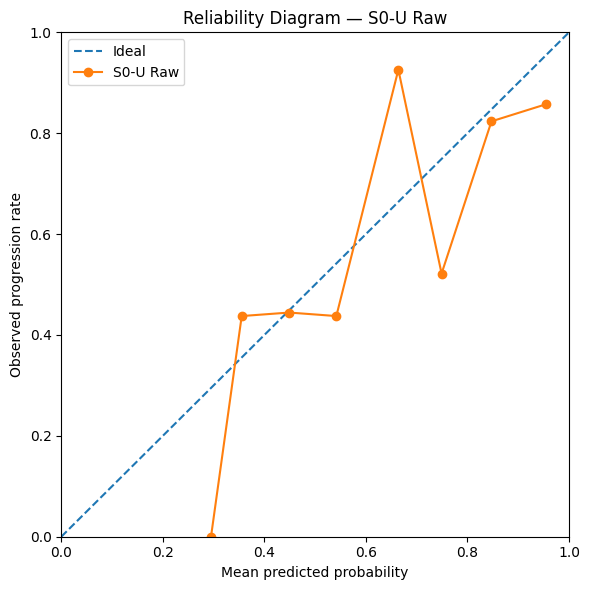

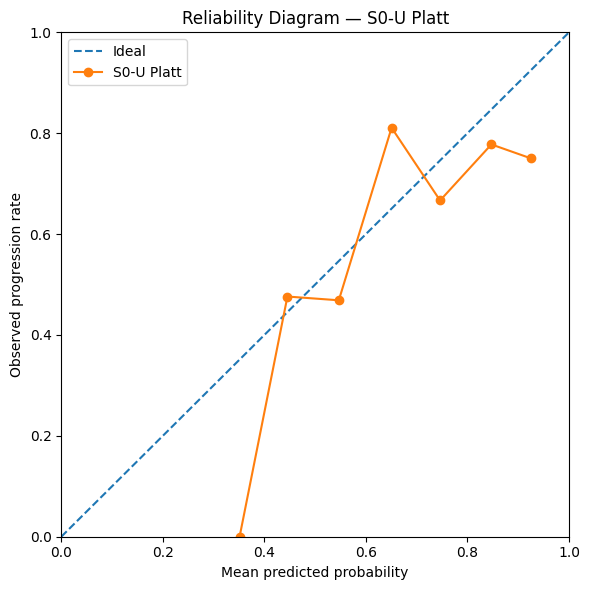

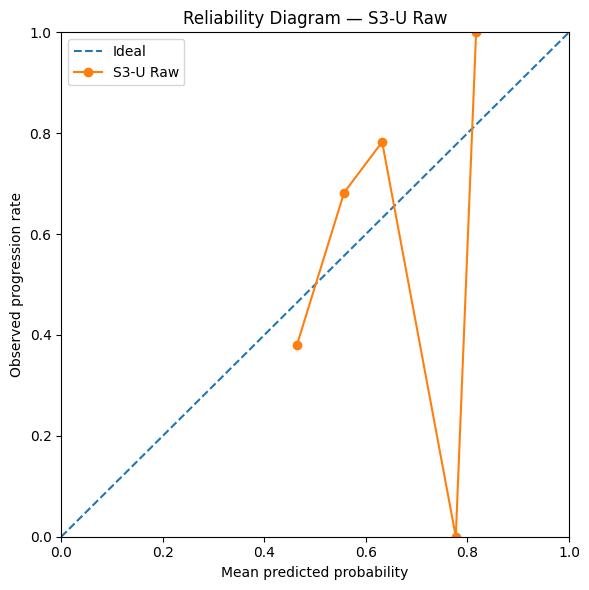

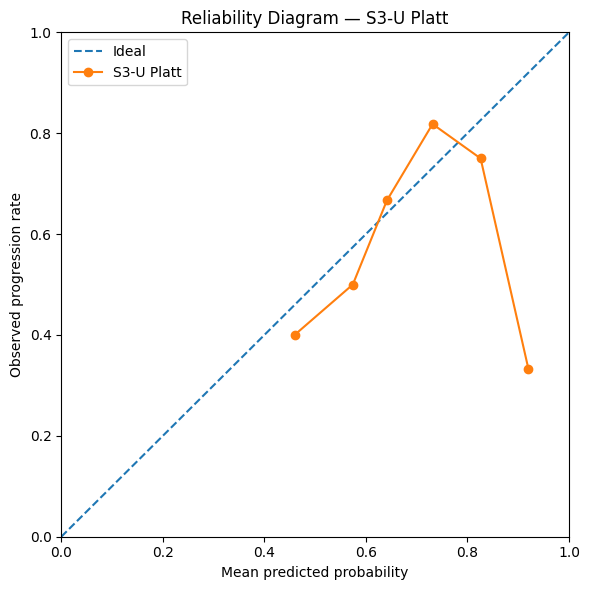


PHASE 6A/6B COMPLETE
Observations: 133
Patients: 74
Missing probabilities: 0

Selected S3 epochs:
 Fold  Selected_Epoch  Inner_Validation_AUROC
    1               8                  0.7436
    2               8                  0.8571
    3               5                  0.8286
    4              10                  0.8571
    5               5                  0.5385

Output directory:
/kaggle/working/Phase6_Calibration


In [23]:
# =============================================================================
# PHASE 6A/6B
# CALIBRATION-READY MODELS + LEAKAGE-SAFE CROSS-FITTED PLATT CALIBRATION
# =============================================================================
#
# S0-U = Unweighted current-state logistic regression
# S3-U = Unweighted time-aware GRU
#
# S3 training:
#   Outer frozen 5-fold CV
#   -> patient-level inner split selects epoch
#   -> reinitialize model
#   -> fit scaler on ALL outer-training patients
#   -> retrain for selected epoch count
#   -> predict untouched outer fold
#
# Calibration:
#   Cross-fitted Platt calibration of OOF predictions.
#   Each patient's calibrated prediction is produced by a calibrator that
#   did NOT use that patient's outcome.
#
# Primary metrics:
#   AUROC
#   AUPRC
#   Brier
#   ECE
#   Calibration intercept
#   Calibration slope
#
# =============================================================================

import os
import gc
import json
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

warnings.filterwarnings("ignore")


# =============================================================================
# 1. SETTINGS
# =============================================================================

SEED = 2026

BATCH_SIZE = 16
MAX_INNER_EPOCHS = 80
INNER_PATIENCE = 12

LR = 1e-3
WEIGHT_DECAY = 1e-4

HIDDEN_SIZE = 16
DROPOUT = 0.25

NUM_WORKERS = 0

INNER_VALIDATION_FRACTION = 0.20

N_ECE_BINS = 10


SEQUENCE_FILE = (
    "/kaggle/working/"
    "Phase5_Longitudinal/"
    "Phase5A_Longitudinal_Sequence_Manifest.csv"
)


OUTPUT_DIR = (
    "/kaggle/working/"
    "Phase6_Calibration"
)


os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# =============================================================================
# 2. FEATURES
# =============================================================================

STATE_FEATURES = [

    "TumorRelated_Volume_cm3",

    "Tumor_Composition_Entropy",

    "NETC_TumorFraction",

    "SNFH_TumorFraction",

    "ET_TumorFraction",

    "RC_Volume_cm3"
]


S0_FEATURES = STATE_FEATURES[:5]


# =============================================================================
# 3. REPRODUCIBILITY
# =============================================================================

def seed_everything(seed):

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():

        torch.cuda.manual_seed(seed)

        torch.cuda.manual_seed_all(seed)


seed_everything(SEED)


device = torch.device(

    "cuda:0"

    if torch.cuda.is_available()

    else "cpu"
)


print("=" * 80)
print("PHASE 6A/6B — CALIBRATION-READY MODELS")
print("=" * 80)

print("PyTorch:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


# =============================================================================
# 4. LOAD PHASE 5A SEQUENCES
# =============================================================================

df = pd.read_csv(
    SEQUENCE_FILE
)


print("\nObservations:", len(df))

print(
    "Patients:",
    df["Patient_ID"].nunique()
)

print(
    "Positive:",
    int(df["Target"].sum())
)

print(
    "Negative:",
    int(
        len(df)
        -
        df["Target"].sum()
    )
)


if len(df) != 133:

    raise RuntimeError(
        "Expected 133 prediction observations."
    )


if df["Patient_ID"].nunique() != 74:

    raise RuntimeError(
        "Expected 74 patients."
    )


# =============================================================================
# 5. PARSE SEQUENCES
# =============================================================================

def read_sequence(
    row,
    feature
):

    return np.asarray(

        json.loads(
            row[
                "SEQ_" + feature
            ]
        ),

        dtype=np.float32
    )


state_sequences = []

time_sequences = []


for _, row in df.iterrows():

    states = np.stack(

        [

            read_sequence(
                row,
                feature
            )

            for feature
            in STATE_FEATURES

        ],

        axis=1
    )


    interval = read_sequence(

        row,

        "Time_From_Previous_MRI_Days"

    ).reshape(
        -1,
        1
    )


    state_sequences.append(
        states.astype(
            np.float32
        )
    )


    time_sequences.append(
        interval.astype(
            np.float32
        )
    )


print(
    "Parsed sequences:",
    len(state_sequences)
)


# =============================================================================
# 6. S0 CURRENT-STATE MATRIX
# =============================================================================

X_s0 = np.asarray(

    [

        sequence[
            -1,
            :5
        ]

        for sequence
        in state_sequences

    ],

    dtype=np.float32
)


y_all = (

    df["Target"]
    .to_numpy()
    .astype(int)
)


print(
    "S0 matrix:",
    X_s0.shape
)


# =============================================================================
# 7. GENERAL METRICS
# =============================================================================

def expected_calibration_error(
    y,
    probability,
    n_bins=10
):

    y = np.asarray(y)

    probability = np.asarray(
        probability
    )


    edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )


    ece = 0.0


    for i in range(
        n_bins
    ):

        if i == (
            n_bins - 1
        ):

            mask = (

                (probability >= edges[i])

                &

                (probability <= edges[i + 1])
            )

        else:

            mask = (

                (probability >= edges[i])

                &

                (probability < edges[i + 1])
            )


        n = mask.sum()


        if n == 0:

            continue


        observed = y[
            mask
        ].mean()


        predicted = probability[
            mask
        ].mean()


        ece += (

            n
            /
            len(y)

        ) * abs(

            observed
            -
            predicted
        )


    return float(ece)


# =============================================================================
# 8. CALIBRATION INTERCEPT/SLOPE
# =============================================================================
#
# Logistic recalibration:
#
# logit(Y) = intercept + slope * logit(predicted probability)
#
# Ideal:
#   intercept = 0
#   slope     = 1
# =============================================================================

def calibration_intercept_slope(
    y,
    probability
):

    eps = 1e-6


    p = np.clip(

        probability,

        eps,
        1 - eps
    )


    logit_p = np.log(

        p
        /
        (1 - p)
    ).reshape(
        -1,
        1
    )


    model = LogisticRegression(

        penalty=None,

        solver="lbfgs",

        max_iter=5000
    )


    try:

        model.fit(
            logit_p,
            y
        )


        intercept = float(
            model.intercept_[0]
        )


        slope = float(
            model.coef_[0][0]
        )


    except Exception:

        # Compatibility fallback

        model = LogisticRegression(

            C=1e6,

            solver="lbfgs",

            max_iter=5000
        )


        model.fit(
            logit_p,
            y
        )


        intercept = float(
            model.intercept_[0]
        )


        slope = float(
            model.coef_[0][0]
        )


    return (
        intercept,
        slope
    )


def calculate_metrics(
    y,
    probability
):

    intercept, slope = (
        calibration_intercept_slope(
            y,
            probability
        )
    )


    return {

        "AUROC":

            roc_auc_score(
                y,
                probability
            ),

        "AUPRC":

            average_precision_score(
                y,
                probability
            ),

        "Brier":

            brier_score_loss(
                y,
                probability
            ),

        "ECE":

            expected_calibration_error(

                y,
                probability,
                N_ECE_BINS
            ),

        "Calibration_Intercept":

            intercept,

        "Calibration_Slope":

            slope
    }


# =============================================================================
# 9. S0-U — UNWEIGHTED LOGISTIC OOF
# =============================================================================

print("\n" + "=" * 80)
print("S0-U — UNWEIGHTED CURRENT-STATE MODEL")
print("=" * 80)


s0_raw_oof = np.full(

    len(df),

    np.nan
)


s0_fold_rows = []


for fold in sorted(
    df["Fold"].unique()
):

    fold = int(fold)


    train_idx = np.where(

        df["Fold"].values
        != fold

    )[0]


    test_idx = np.where(

        df["Fold"].values
        == fold

    )[0]


    train_patients = set(

        df.iloc[
            train_idx
        ]["Patient_ID"]
    )


    test_patients = set(

        df.iloc[
            test_idx
        ]["Patient_ID"]
    )


    if train_patients & test_patients:

        raise RuntimeError(
            "S0 patient leakage."
        )


    scaler = StandardScaler()


    X_train = scaler.fit_transform(

        X_s0[
            train_idx
        ]
    )


    X_test = scaler.transform(

        X_s0[
            test_idx
        ]
    )


    model = LogisticRegression(

        class_weight=None,

        max_iter=5000,

        random_state=
        SEED + fold
    )


    model.fit(

        X_train,

        y_all[
            train_idx
        ]
    )


    p = model.predict_proba(
        X_test
    )[:, 1]


    s0_raw_oof[
        test_idx
    ] = p


    metrics = calculate_metrics(

        y_all[
            test_idx
        ],

        p
    )


    metrics[
        "Fold"
    ] = fold


    s0_fold_rows.append(
        metrics
    )


    print(

        f"Fold {fold} | "

        f"AUC={metrics['AUROC']:.4f} | "

        f"AP={metrics['AUPRC']:.4f} | "

        f"Brier={metrics['Brier']:.4f}"
    )


# =============================================================================
# 10. TEMPORAL SEQUENCE SCALER
# =============================================================================
#
# Time transformation:
#   log1p(days)
#
# This limits influence of the extreme 1109-day interval while retaining
# actual irregular temporal spacing.
# =============================================================================

def build_temporal_sequence(
    idx
):

    state = state_sequences[
        idx
    ]


    time_days = time_sequences[
        idx
    ]


    log_time = np.log1p(
        time_days
    )


    return np.concatenate(

        [
            state,
            log_time
        ],

        axis=1
    )


def fit_temporal_scaler(
    indices
):

    rows = np.concatenate(

        [

            build_temporal_sequence(
                idx
            )

            for idx
            in indices

        ],

        axis=0
    )


    scaler = StandardScaler()


    scaler.fit(
        rows
    )


    return scaler


# =============================================================================
# 11. DATASET
# =============================================================================

class TemporalDataset(Dataset):

    def __init__(
        self,
        indices,
        scaler
    ):

        self.indices = list(
            indices
        )

        self.scaler = scaler


    def __len__(self):

        return len(
            self.indices
        )


    def __getitem__(
        self,
        position
    ):

        idx = self.indices[
            position
        ]


        sequence = build_temporal_sequence(
            idx
        )


        sequence = self.scaler.transform(

            sequence

        ).astype(
            np.float32
        )


        target = float(
            y_all[
                idx
            ]
        )


        return (

            torch.from_numpy(
                sequence
            ),

            torch.tensor(
                target,
                dtype=torch.float32
            ),

            idx
        )


def collate_sequences(
    batch
):

    sequences = [

        item[0]
        for item in batch
    ]


    targets = torch.stack(

        [
            item[1]
            for item in batch
        ]
    )


    indices = torch.tensor(

        [
            item[2]
            for item in batch
        ],

        dtype=torch.long
    )


    lengths = torch.tensor(

        [
            len(sequence)
            for sequence in sequences
        ],

        dtype=torch.long
    )


    padded = pad_sequence(

        sequences,

        batch_first=True,

        padding_value=0.0
    )


    return (

        padded,
        lengths,
        targets,
        indices
    )


# =============================================================================
# 12. GRU MODEL
# =============================================================================

class TemporalGRU(nn.Module):

    def __init__(
        self
    ):

        super().__init__()


        self.gru = nn.GRU(

            input_size=7,

            hidden_size=
            HIDDEN_SIZE,

            num_layers=1,

            batch_first=True
        )


        self.dropout = nn.Dropout(
            DROPOUT
        )


        self.classifier = nn.Linear(

            HIDDEN_SIZE,
            1
        )


    def forward(
        self,
        x,
        lengths
    ):

        packed = pack_padded_sequence(

            x,

            lengths.cpu(),

            batch_first=True,

            enforce_sorted=False
        )


        _, hidden = self.gru(
            packed
        )


        representation = hidden[
            -1
        ]


        representation = self.dropout(
            representation
        )


        return self.classifier(

            representation

        ).squeeze(1)


# =============================================================================
# 13. RUN ONE EPOCH
# =============================================================================

def run_epoch(
    model,
    loader,
    criterion,
    optimizer=None
):

    training = (
        optimizer is not None
    )


    if training:

        model.train()

    else:

        model.eval()


    all_y = []

    all_p = []

    all_indices = []

    losses = []


    context = (

        torch.enable_grad()

        if training

        else torch.no_grad()
    )


    with context:

        for (
            x,
            lengths,
            target,
            indices
        ) in loader:


            x = x.to(
                device
            )


            target = target.to(
                device
            )


            if training:

                optimizer.zero_grad(
                    set_to_none=True
                )


            logits = model(

                x,
                lengths
            )


            loss = criterion(

                logits,
                target
            )


            if training:

                loss.backward()


                torch.nn.utils.clip_grad_norm_(

                    model.parameters(),

                    5.0
                )


                optimizer.step()


            probability = (

                torch.sigmoid(
                    logits
                )

                .detach()

                .cpu()

                .numpy()
            )


            losses.append(
                loss.item()
            )


            all_y.extend(

                target.detach()
                .cpu()
                .numpy()
                .tolist()
            )


            all_p.extend(
                probability.tolist()
            )


            all_indices.extend(
                indices.tolist()
            )


    return (

        float(
            np.mean(losses)
        ),

        np.asarray(
            all_y
        ),

        np.asarray(
            all_p
        ),

        np.asarray(
            all_indices
        )
    )


# =============================================================================
# 14. PATIENT-LEVEL INNER SPLIT
# =============================================================================

def create_inner_split(
    outer_train_idx,
    fold
):

    outer_train_df = df.iloc[
        outer_train_idx
    ]


    patient_table = (

        outer_train_df
        .groupby(
            "Patient_ID",
            as_index=False
        )
        .agg(
            Patient_Target=(
                "Target",
                "max"
            )
        )
    )


    splitter = StratifiedShuffleSplit(

        n_splits=1,

        test_size=
        INNER_VALIDATION_FRACTION,

        random_state=
        SEED + fold
    )


    patient_positions = np.arange(
        len(patient_table)
    )


    train_patient_pos, val_patient_pos = next(

        splitter.split(

            patient_positions,

            patient_table[
                "Patient_Target"
            ].values
        )
    )


    inner_train_patients = set(

        patient_table.iloc[
            train_patient_pos
        ]["Patient_ID"]
    )


    inner_val_patients = set(

        patient_table.iloc[
            val_patient_pos
        ]["Patient_ID"]
    )


    inner_train_idx = np.asarray(

        [

            idx
            for idx in outer_train_idx

            if df.iloc[
                idx
            ]["Patient_ID"]
            in inner_train_patients
        ]
    )


    inner_val_idx = np.asarray(

        [

            idx
            for idx in outer_train_idx

            if df.iloc[
                idx
            ]["Patient_ID"]
            in inner_val_patients
        ]
    )


    if (
        inner_train_patients
        &
        inner_val_patients
    ):

        raise RuntimeError(
            "Inner patient leakage."
        )


    return (

        inner_train_idx,
        inner_val_idx
    )


# =============================================================================
# 15. SELECT EPOCH USING INNER VALIDATION ONLY
# =============================================================================

def select_epoch(
    outer_train_idx,
    fold
):

    inner_train_idx, inner_val_idx = (
        create_inner_split(

            outer_train_idx,
            fold
        )
    )


    scaler = fit_temporal_scaler(
        inner_train_idx
    )


    train_dataset = TemporalDataset(

        inner_train_idx,
        scaler
    )


    val_dataset = TemporalDataset(

        inner_val_idx,
        scaler
    )


    train_loader = DataLoader(

        train_dataset,

        batch_size=
        BATCH_SIZE,

        shuffle=True,

        num_workers=
        NUM_WORKERS,

        collate_fn=
        collate_sequences
    )


    val_loader = DataLoader(

        val_dataset,

        batch_size=
        BATCH_SIZE,

        shuffle=False,

        num_workers=
        NUM_WORKERS,

        collate_fn=
        collate_sequences
    )


    seed_everything(
        SEED + fold
    )


    model = TemporalGRU().to(
        device
    )


    # UNWEIGHTED BCE

    criterion = (
        nn.BCEWithLogitsLoss()
    )


    optimizer = torch.optim.AdamW(

        model.parameters(),

        lr=LR,

        weight_decay=
        WEIGHT_DECAY
    )


    best_auc = -np.inf

    best_epoch = 1

    bad_epochs = 0


    for epoch in range(
        1,
        MAX_INNER_EPOCHS + 1
    ):


        run_epoch(

            model,

            train_loader,

            criterion,

            optimizer
        )


        (
            val_loss,
            val_y,
            val_p,
            _
        ) = run_epoch(

            model,

            val_loader,

            criterion
        )


        if np.unique(
            val_y
        ).size < 2:

            raise RuntimeError(
                "Inner validation has one class."
            )


        val_auc = roc_auc_score(

            val_y,
            val_p
        )


        if val_auc > (
            best_auc + 1e-4
        ):

            best_auc = val_auc

            best_epoch = epoch

            bad_epochs = 0


        else:

            bad_epochs += 1


        if bad_epochs >= INNER_PATIENCE:

            break


    del model
    del optimizer
    del criterion

    del train_loader
    del val_loader

    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    return (

        best_epoch,
        best_auc,
        len(inner_train_idx),
        len(inner_val_idx)
    )


# =============================================================================
# 16. RETRAIN ON COMPLETE OUTER TRAINING SET
# =============================================================================

def train_outer_model(
    outer_train_idx,
    selected_epoch,
    fold
):

    scaler = fit_temporal_scaler(
        outer_train_idx
    )


    dataset = TemporalDataset(

        outer_train_idx,
        scaler
    )


    loader = DataLoader(

        dataset,

        batch_size=
        BATCH_SIZE,

        shuffle=True,

        num_workers=
        NUM_WORKERS,

        collate_fn=
        collate_sequences
    )


    # Different deterministic initialization from
    # inner epoch-selection model.

    seed_everything(
        SEED + 1000 + fold
    )


    model = TemporalGRU().to(
        device
    )


    criterion = (
        nn.BCEWithLogitsLoss()
    )


    optimizer = torch.optim.AdamW(

        model.parameters(),

        lr=LR,

        weight_decay=
        WEIGHT_DECAY
    )


    for epoch in range(

        1,
        selected_epoch + 1
    ):

        run_epoch(

            model,

            loader,

            criterion,

            optimizer
        )


    return (
        model,
        scaler
    )


# =============================================================================
# 17. S3-U NESTED OOF
# =============================================================================

print("\n" + "=" * 80)
print("S3-U — NESTED UNWEIGHTED TIME-AWARE GRU")
print("=" * 80)


s3_raw_oof = np.full(

    len(df),

    np.nan
)


epoch_rows = []

s3_fold_rows = []


for fold in sorted(
    df["Fold"].unique()
):

    fold = int(fold)


    print(
        "\n" + "-" * 72
    )

    print(
        f"Outer Fold {fold}"
    )

    print(
        "-" * 72
    )


    outer_train_idx = np.where(

        df["Fold"].values
        != fold

    )[0]


    outer_test_idx = np.where(

        df["Fold"].values
        == fold

    )[0]


    outer_train_patients = set(

        df.iloc[
            outer_train_idx
        ]["Patient_ID"]
    )


    outer_test_patients = set(

        df.iloc[
            outer_test_idx
        ]["Patient_ID"]
    )


    if (
        outer_train_patients
        &
        outer_test_patients
    ):

        raise RuntimeError(
            "Outer patient leakage."
        )


    # -------------------------------------------------------------------------
    # Inner epoch selection
    # -------------------------------------------------------------------------

    (
        selected_epoch,
        inner_auc,
        n_inner_train,
        n_inner_val
    ) = select_epoch(

        outer_train_idx,
        fold
    )


    print(
        "Selected epoch:",
        selected_epoch
    )

    print(
        "Inner validation AUROC:",
        round(
            inner_auc,
            4
        )
    )


    epoch_rows.append({

        "Fold":
            fold,

        "Selected_Epoch":
            selected_epoch,

        "Inner_Validation_AUROC":
            inner_auc,

        "Inner_Train_Observations":
            n_inner_train,

        "Inner_Validation_Observations":
            n_inner_val,

        "Outer_Train_Observations":
            len(
                outer_train_idx
            ),

        "Outer_Test_Observations":
            len(
                outer_test_idx
            )
    })


    # -------------------------------------------------------------------------
    # Reinitialize + retrain on complete outer training set
    # -------------------------------------------------------------------------

    model, scaler = train_outer_model(

        outer_train_idx,

        selected_epoch,

        fold
    )


    test_dataset = TemporalDataset(

        outer_test_idx,
        scaler
    )


    test_loader = DataLoader(

        test_dataset,

        batch_size=
        BATCH_SIZE,

        shuffle=False,

        num_workers=
        NUM_WORKERS,

        collate_fn=
        collate_sequences
    )


    criterion = (
        nn.BCEWithLogitsLoss()
    )


    (
        test_loss,
        test_y,
        test_p,
        returned_indices
    ) = run_epoch(

        model,

        test_loader,

        criterion
    )


    s3_raw_oof[
        returned_indices
    ] = test_p


    metrics = calculate_metrics(

        test_y,
        test_p
    )


    metrics[
        "Fold"
    ] = fold


    metrics[
        "Selected_Epoch"
    ] = selected_epoch


    s3_fold_rows.append(
        metrics
    )


    print(

        f"Outer test | "

        f"AUC={metrics['AUROC']:.4f} | "

        f"AP={metrics['AUPRC']:.4f} | "

        f"Brier={metrics['Brier']:.4f}"
    )


    del model
    del criterion
    del test_loader
    del test_dataset

    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


# =============================================================================
# 18. OOF QC
# =============================================================================

print("\n" + "=" * 80)
print("RAW OOF QC")
print("=" * 80)


print(
    "Missing S0:",
    int(
        np.isnan(
            s0_raw_oof
        ).sum()
    )
)


print(
    "Missing S3:",
    int(
        np.isnan(
            s3_raw_oof
        ).sum()
    )
)


if (
    np.isnan(
        s0_raw_oof
    ).any()

    or

    np.isnan(
        s3_raw_oof
    ).any()
):

    raise RuntimeError(
        "Missing OOF probabilities."
    )


# =============================================================================
# 19. CROSS-FITTED PLATT CALIBRATION
# =============================================================================
#
# Critical leakage rule:
#
# For outer fold k:
#   calibrator is fitted ONLY on OOF predictions from folds != k.
#   calibrator then transforms fold k.
#
# Thus the target of every prediction being calibrated is excluded from
# calibrator fitting.
# =============================================================================

def logit_transform(
    probability
):

    eps = 1e-6


    p = np.clip(

        probability,

        eps,
        1 - eps
    )


    return np.log(

        p
        /
        (1 - p)
    ).reshape(
        -1,
        1
    )


def cross_fitted_platt(
    raw_probability
):

    calibrated = np.full(

        len(df),

        np.nan
    )


    calibration_rows = []


    for fold in sorted(
        df["Fold"].unique()
    ):

        fold = int(fold)


        calibration_train_idx = np.where(

            df["Fold"].values
            != fold

        )[0]


        calibration_test_idx = np.where(

            df["Fold"].values
            == fold

        )[0]


        X_train = logit_transform(

            raw_probability[
                calibration_train_idx
            ]
        )


        X_test = logit_transform(

            raw_probability[
                calibration_test_idx
            ]
        )


        y_train = y_all[
            calibration_train_idx
        ]


        calibrator = LogisticRegression(

            penalty=None,

            solver="lbfgs",

            max_iter=5000
        )


        try:

            calibrator.fit(

                X_train,
                y_train
            )


        except Exception:

            calibrator = LogisticRegression(

                C=1e6,

                solver="lbfgs",

                max_iter=5000
            )


            calibrator.fit(

                X_train,
                y_train
            )


        p = calibrator.predict_proba(

            X_test

        )[:, 1]


        calibrated[
            calibration_test_idx
        ] = p


        calibration_rows.append({

            "Fold":
                fold,

            "Platt_Intercept":
                float(
                    calibrator.intercept_[0]
                ),

            "Platt_Slope":
                float(
                    calibrator.coef_[0][0]
                )
        })


    return (

        calibrated,

        pd.DataFrame(
            calibration_rows
        )
    )


print("\n" + "=" * 80)
print("CROSS-FITTED PLATT CALIBRATION")
print("=" * 80)


s0_platt_oof, s0_platt_parameters = (
    cross_fitted_platt(
        s0_raw_oof
    )
)


s3_platt_oof, s3_platt_parameters = (
    cross_fitted_platt(
        s3_raw_oof
    )
)


print(
    "Missing S0 calibrated:",
    int(
        np.isnan(
            s0_platt_oof
        ).sum()
    )
)


print(
    "Missing S3 calibrated:",
    int(
        np.isnan(
            s3_platt_oof
        ).sum()
    )
)


# =============================================================================
# 20. FINAL CALIBRATION COMPARISON
# =============================================================================

models = {

    "S0-U Raw":
        s0_raw_oof,

    "S0-U Platt":
        s0_platt_oof,

    "S3-U Raw":
        s3_raw_oof,

    "S3-U Platt":
        s3_platt_oof
}


metric_rows = []


for name, probability in models.items():

    metrics = calculate_metrics(

        y_all,
        probability
    )


    row = {

        "Model":
            name
    }


    row.update(
        metrics
    )


    metric_rows.append(
        row
    )


metrics_df = pd.DataFrame(
    metric_rows
)


print("\n" + "=" * 80)
print("PHASE 6A/6B — FINAL OOF CALIBRATION COMPARISON")
print("=" * 80)


print(

    metrics_df
    .round(4)
    .to_string(
        index=False
    )
)


# =============================================================================
# 21. CALIBRATION CHANGE
# =============================================================================

print("\n" + "=" * 80)
print("CALIBRATION EFFECT")
print("=" * 80)


for prefix in [
    "S0-U",
    "S3-U"
]:

    raw = metrics_df[

        metrics_df[
            "Model"
        ] == prefix + " Raw"

    ].iloc[0]


    calibrated = metrics_df[

        metrics_df[
            "Model"
        ] == prefix + " Platt"

    ].iloc[0]


    print(
        f"\n{prefix}"
    )


    print(

        "  Brier: ",

        f"{raw['Brier']:.4f}",

        "->",

        f"{calibrated['Brier']:.4f}",

        " Δ=",

        f"{calibrated['Brier'] - raw['Brier']:+.4f}"
    )


    print(

        "  ECE:   ",

        f"{raw['ECE']:.4f}",

        "->",

        f"{calibrated['ECE']:.4f}",

        " Δ=",

        f"{calibrated['ECE'] - raw['ECE']:+.4f}"
    )


    print(

        "  Slope: ",

        f"{raw['Calibration_Slope']:.4f}",

        "->",

        f"{calibrated['Calibration_Slope']:.4f}"
    )


    print(

        "  Intercept:",

        f"{raw['Calibration_Intercept']:.4f}",

        "->",

        f"{calibrated['Calibration_Intercept']:.4f}"
    )


# =============================================================================
# 22. RELIABILITY TABLE
# =============================================================================

def reliability_table(
    y,
    probability,
    n_bins=10
):

    edges = np.linspace(
        0,
        1,
        n_bins + 1
    )


    rows = []


    for i in range(
        n_bins
    ):

        if i == (
            n_bins - 1
        ):

            mask = (

                (probability >= edges[i])

                &

                (probability <= edges[i + 1])
            )

        else:

            mask = (

                (probability >= edges[i])

                &

                (probability < edges[i + 1])
            )


        if mask.sum() == 0:

            continue


        rows.append({

            "Bin":
                i + 1,

            "Lower":
                edges[i],

            "Upper":
                edges[i + 1],

            "N":
                int(
                    mask.sum()
                ),

            "Mean_Predicted":
                float(
                    probability[
                        mask
                    ].mean()
                ),

            "Observed_Rate":
                float(
                    y[
                        mask
                    ].mean()
                )
        })


    return pd.DataFrame(
        rows
    )


# =============================================================================
# 23. RELIABILITY PLOTS
# =============================================================================

for name, probability in models.items():

    table = reliability_table(

        y_all,

        probability,

        N_ECE_BINS
    )


    safe_name = (

        name
        .replace(
            " ",
            "_"
        )
        .replace(
            "-",
            "_"
        )
    )


    table.to_csv(

        os.path.join(

            OUTPUT_DIR,

            f"{safe_name}_Reliability.csv"
        ),

        index=False
    )


    plt.figure(
        figsize=(6, 6)
    )


    plt.plot(

        [0, 1],

        [0, 1],

        linestyle="--",

        label="Ideal"
    )


    plt.plot(

        table[
            "Mean_Predicted"
        ],

        table[
            "Observed_Rate"
        ],

        marker="o",

        label=name
    )


    plt.xlabel(
        "Mean predicted probability"
    )


    plt.ylabel(
        "Observed progression rate"
    )


    plt.title(
        f"Reliability Diagram — {name}"
    )


    plt.xlim(
        0,
        1
    )


    plt.ylim(
        0,
        1
    )


    plt.legend()


    plt.tight_layout()


    plt.savefig(

        os.path.join(

            OUTPUT_DIR,

            f"{safe_name}_Reliability.png"
        ),

        dpi=300,

        bbox_inches="tight"
    )


    plt.show()


# =============================================================================
# 24. SAVE OOF PROBABILITIES
# =============================================================================

oof_df = df[
    [
        "Sample_ID",
        "Patient_ID",
        "Fold",
        "Index_Timepoint",
        "Index_MRI_Day",
        "Target",
        "Sequence_Length"
    ]
].copy()


oof_df[
    "S0_U_Raw"
] = s0_raw_oof


oof_df[
    "S0_U_Platt"
] = s0_platt_oof


oof_df[
    "S3_U_Raw"
] = s3_raw_oof


oof_df[
    "S3_U_Platt"
] = s3_platt_oof


# =============================================================================
# 25. SAVE EVERYTHING
# =============================================================================

oof_df.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Phase6_OOF_Probabilities.csv"
    ),

    index=False
)


metrics_df.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Phase6_Calibration_Metrics.csv"
    ),

    index=False
)


pd.DataFrame(
    s0_fold_rows
).to_csv(

    os.path.join(
        OUTPUT_DIR,
        "S0_U_Fold_Metrics.csv"
    ),

    index=False
)


pd.DataFrame(
    s3_fold_rows
).to_csv(

    os.path.join(
        OUTPUT_DIR,
        "S3_U_Fold_Metrics.csv"
    ),

    index=False
)


pd.DataFrame(
    epoch_rows
).to_csv(

    os.path.join(
        OUTPUT_DIR,
        "S3_Selected_Epochs.csv"
    ),

    index=False
)


s0_platt_parameters.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "S0_Platt_Parameters.csv"
    ),

    index=False
)


s3_platt_parameters.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "S3_Platt_Parameters.csv"
    ),

    index=False
)


# =============================================================================
# 26. FINAL QC
# =============================================================================

print("\n" + "=" * 80)
print("PHASE 6A/6B COMPLETE")
print("=" * 80)


print(
    "Observations:",
    len(oof_df)
)


print(
    "Patients:",
    oof_df[
        "Patient_ID"
    ].nunique()
)


print(
    "Missing probabilities:",
    int(

        oof_df[
            [
                "S0_U_Raw",
                "S0_U_Platt",
                "S3_U_Raw",
                "S3_U_Platt"
            ]
        ]
        .isna()
        .sum()
        .sum()
    )
)


print(
    "\nSelected S3 epochs:"
)


print(

    pd.DataFrame(
        epoch_rows
    )[
        [
            "Fold",
            "Selected_Epoch",
            "Inner_Validation_AUROC"
        ]
    ]
    .round(4)
    .to_string(
        index=False
    )
)


print(
    "\nOutput directory:"
)

print(
    OUTPUT_DIR
)


print("=" * 80)

In [24]:
# =============================================================================
# PHASE 6B-MATCHED
# FINAL RC-FREE MATCHED NESTED TEMPORAL SENSITIVITY ANALYSIS
# =============================================================================
#
# Research question:
# Does longitudinal sequence + irregular timing improve progression prediction
# beyond the EXACT SAME five biological features used by the current-state S0?
#
# S0 biological features:
#   1. TumorRelated_Volume_cm3
#   2. Tumor_Composition_Entropy
#   3. NETC_TumorFraction
#   4. SNFH_TumorFraction
#   5. ET_TumorFraction
#
# S3-Matched input:
#   Complete longitudinal sequence of the SAME five features
#   + log1p(Time_From_Previous_MRI_Days)
#
# IMPORTANT:
#   - RC volume is NOT used.
#   - Same frozen patient-level outer folds.
#   - Inner patient-level split used ONLY for epoch selection.
#   - Outer test patients never influence epoch selection/scaling/training.
#   - Unweighted BCE.
#   - After selecting epoch, model is reinitialized.
#   - Model is retrained on ALL outer-training patients.
#   - No Platt calibration in this sensitivity experiment.
#
# Comparator already established:
#
#   S0-U Raw
#       AUROC = 0.6760
#       AUPRC = 0.7631
#       Brier = 0.2098
#
# =============================================================================


# =============================================================================
# 1. IMPORTS
# =============================================================================

import os
import gc
import json
import random
import warnings

import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedShuffleSplit

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

from sklearn.linear_model import LogisticRegression


warnings.filterwarnings("ignore")


# =============================================================================
# 2. SETTINGS
# =============================================================================

SEED = 2026

BATCH_SIZE = 16

MAX_INNER_EPOCHS = 80

INNER_PATIENCE = 12

INNER_VALIDATION_FRACTION = 0.20

LR = 1e-3

WEIGHT_DECAY = 1e-4

HIDDEN_SIZE = 16

DROPOUT = 0.25

NUM_WORKERS = 0

N_ECE_BINS = 10


SEQUENCE_FILE = (
    "/kaggle/working/"
    "Phase5_Longitudinal/"
    "Phase5A_Longitudinal_Sequence_Manifest.csv"
)


OUTPUT_DIR = (
    "/kaggle/working/"
    "Phase6B_Matched_Temporal"
)


os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# =============================================================================
# 3. LOCKED FEATURE SET
# =============================================================================
#
# EXACT SAME biological state variables as S0.
#
# Resection cavity is intentionally excluded.
# =============================================================================

STATE_FEATURES = [

    "TumorRelated_Volume_cm3",

    "Tumor_Composition_Entropy",

    "NETC_TumorFraction",

    "SNFH_TumorFraction",

    "ET_TumorFraction"
]


TIME_FEATURE = (
    "Time_From_Previous_MRI_Days"
)


N_STATE_FEATURES = len(
    STATE_FEATURES
)


GRU_INPUT_SIZE = (
    N_STATE_FEATURES
    + 1
)


print("=" * 80)

print(
    "PHASE 6B-MATCHED — RC-FREE NESTED TEMPORAL SENSITIVITY"
)

print("=" * 80)


print(
    "Biological state features:",
    N_STATE_FEATURES
)


print(
    "GRU input features:",
    GRU_INPUT_SIZE
)


print(
    "RC included:",
    False
)


# =============================================================================
# 4. REPRODUCIBILITY
# =============================================================================

def seed_everything(seed):

    random.seed(
        seed
    )

    np.random.seed(
        seed
    )

    torch.manual_seed(
        seed
    )

    if torch.cuda.is_available():

        torch.cuda.manual_seed(
            seed
        )

        torch.cuda.manual_seed_all(
            seed
        )


seed_everything(
    SEED
)


device = torch.device(

    "cuda:0"

    if torch.cuda.is_available()

    else "cpu"
)


print(
    "\nPyTorch:",
    torch.__version__
)


print(
    "Device:",
    device
)


if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


# =============================================================================
# 5. LOAD FROZEN LONGITUDINAL MANIFEST
# =============================================================================

df = pd.read_csv(
    SEQUENCE_FILE
)


print("\n" + "=" * 80)

print(
    "COHORT QC"
)

print("=" * 80)


print(
    "Observations:",
    len(df)
)


print(
    "Patients:",
    df[
        "Patient_ID"
    ].nunique()
)


print(
    "Positive:",
    int(
        df[
            "Target"
        ].sum()
    )
)


print(
    "Negative:",
    int(
        len(df)
        -
        df[
            "Target"
        ].sum()
    )
)


print(
    "Folds:",
    sorted(
        df[
            "Fold"
        ].unique()
    )
)


# =============================================================================
# 6. EXPECTED COHORT CHECKS
# =============================================================================

if len(df) != 133:

    raise RuntimeError(
        f"Expected 133 observations; found {len(df)}."
    )


if (
    df[
        "Patient_ID"
    ].nunique()
    != 74
):

    raise RuntimeError(
        "Expected 74 patients."
    )


if int(
    df[
        "Target"
    ].sum()
) != 85:

    raise RuntimeError(
        "Expected 85 positive observations."
    )


if int(
    (
        df[
            "Target"
        ] == 0
    ).sum()
) != 48:

    raise RuntimeError(
        "Expected 48 negative observations."
    )


# =============================================================================
# 7. VERIFY REQUIRED SEQUENCE COLUMNS
# =============================================================================

required_sequence_columns = [

    "SEQ_" + feature

    for feature
    in STATE_FEATURES

]


required_sequence_columns.append(

    "SEQ_"
    +
    TIME_FEATURE
)


missing_columns = [

    column

    for column
    in required_sequence_columns

    if column
    not in df.columns
]


if missing_columns:

    raise RuntimeError(

        "Missing required columns:\n"

        +
        "\n".join(
            missing_columns
        )
    )


print(
    "\nRequired sequence columns: PASS"
)


# =============================================================================
# 8. SEQUENCE PARSER
# =============================================================================

def parse_sequence(
    row,
    feature
):

    value = row[
        "SEQ_" + feature
    ]


    sequence = np.asarray(

        json.loads(
            value
        ),

        dtype=np.float32
    )


    return sequence


# =============================================================================
# 9. BUILD RAW STATE + TIME SEQUENCES
# =============================================================================

state_sequences = []

time_sequences = []


for row_index, row in df.iterrows():

    feature_arrays = [

        parse_sequence(
            row,
            feature
        )

        for feature
        in STATE_FEATURES
    ]


    sequence_lengths = [

        len(array)

        for array
        in feature_arrays
    ]


    if len(
        set(
            sequence_lengths
        )
    ) != 1:

        raise RuntimeError(

            f"Feature sequence length mismatch "
            f"at row {row_index}."
        )


    state = np.stack(

        feature_arrays,

        axis=1
    )


    time_days = parse_sequence(

        row,
        TIME_FEATURE
    )


    if len(
        time_days
    ) != state.shape[0]:

        raise RuntimeError(

            f"Time sequence length mismatch "
            f"at row {row_index}."
        )


    state_sequences.append(

        state.astype(
            np.float32
        )
    )


    time_sequences.append(

        time_days
        .reshape(
            -1,
            1
        )
        .astype(
            np.float32
        )
    )


print(
    "Parsed sequences:",
    len(
        state_sequences
    )
)


# =============================================================================
# 10. TARGETS
# =============================================================================

y_all = (

    df[
        "Target"
    ]

    .to_numpy()

    .astype(int)
)


# =============================================================================
# 11. SEQUENCE QC
# =============================================================================

sequence_lengths = np.asarray(

    [

        sequence.shape[0]

        for sequence
        in state_sequences
    ]
)


print(
    "Sequence length min:",
    sequence_lengths.min()
)


print(
    "Sequence length max:",
    sequence_lengths.max()
)


print(
    "Sequence length median:",
    np.median(
        sequence_lengths
    )
)


# Verify against stored Sequence_Length

if "Sequence_Length" in df.columns:

    stored_lengths = (

        df[
            "Sequence_Length"
        ]

        .to_numpy()

        .astype(int)
    )


    if not np.array_equal(

        sequence_lengths,
        stored_lengths
    ):

        raise RuntimeError(
            "Sequence length mismatch."
        )


print(
    "Sequence-length QC: PASS"
)


# =============================================================================
# 12. NONFINITE QC
# =============================================================================

nonfinite_state = sum(

    int(
        ~np.isfinite(
            sequence
        ).all()
    )

    for sequence
    in state_sequences
)


nonfinite_time = sum(

    int(
        ~np.isfinite(
            sequence
        ).all()
    )

    for sequence
    in time_sequences
)


print(
    "Nonfinite state sequences:",
    nonfinite_state
)


print(
    "Nonfinite time sequences:",
    nonfinite_time
)


if (
    nonfinite_state > 0
    or
    nonfinite_time > 0
):

    raise RuntimeError(
        "Nonfinite sequence values detected."
    )


# =============================================================================
# 13. BUILD TEMPORAL SEQUENCE
# =============================================================================
#
# Five biological features
# +
# log1p(inter-MRI interval)
#
# log1p reduces leverage of extreme intervals while preserving temporal order.
# =============================================================================

def build_temporal_sequence(
    idx
):

    state = state_sequences[
        idx
    ]


    time_days = time_sequences[
        idx
    ]


    if np.any(
        time_days < 0
    ):

        raise RuntimeError(
            "Negative MRI interval detected."
        )


    log_time = np.log1p(
        time_days
    )


    sequence = np.concatenate(

        [
            state,
            log_time
        ],

        axis=1
    )


    if (
        sequence.shape[1]
        != GRU_INPUT_SIZE
    ):

        raise RuntimeError(
            "Incorrect GRU input dimension."
        )


    return sequence.astype(
        np.float32
    )


# =============================================================================
# 14. EXAMPLE INPUT QC
# =============================================================================

example_sequence = (
    build_temporal_sequence(0)
)


print(
    "\nExample temporal tensor shape:",
    example_sequence.shape
)


print(
    "Expected feature dimension:",
    GRU_INPUT_SIZE
)


# =============================================================================
# 15. TEMPORAL SCALER
# =============================================================================
#
# Scaler is always fitted ONLY using the relevant training patients.
# =============================================================================

def fit_temporal_scaler(
    indices
):

    rows = np.concatenate(

        [

            build_temporal_sequence(
                idx
            )

            for idx
            in indices
        ],

        axis=0
    )


    scaler = StandardScaler()


    scaler.fit(
        rows
    )


    return scaler


# =============================================================================
# 16. PYTORCH DATASET
# =============================================================================

class TemporalDataset(Dataset):

    def __init__(
        self,
        indices,
        scaler
    ):

        self.indices = list(
            indices
        )

        self.scaler = scaler


    def __len__(
        self
    ):

        return len(
            self.indices
        )


    def __getitem__(
        self,
        position
    ):

        idx = self.indices[
            position
        ]


        sequence = (
            build_temporal_sequence(
                idx
            )
        )


        sequence = (

            self.scaler
            .transform(
                sequence
            )

            .astype(
                np.float32
            )
        )


        target = float(
            y_all[
                idx
            ]
        )


        return (

            torch.from_numpy(
                sequence
            ),

            torch.tensor(
                target,
                dtype=torch.float32
            ),

            idx
        )


# =============================================================================
# 17. COLLATE VARIABLE-LENGTH SEQUENCES
# =============================================================================

def collate_sequences(
    batch
):

    sequences = [

        item[0]

        for item
        in batch
    ]


    targets = torch.stack(

        [

            item[1]

            for item
            in batch
        ]
    )


    indices = torch.tensor(

        [

            item[2]

            for item
            in batch
        ],

        dtype=torch.long
    )


    lengths = torch.tensor(

        [

            len(
                sequence
            )

            for sequence
            in sequences
        ],

        dtype=torch.long
    )


    padded = pad_sequence(

        sequences,

        batch_first=True,

        padding_value=0.0
    )


    return (

        padded,
        lengths,
        targets,
        indices
    )


# =============================================================================
# 18. MATCHED GRU
# =============================================================================
#
# INPUT = 6
#
#   5 biological features
#   +
#   log1p(time interval)
#
# NO RC.
# =============================================================================

class MatchedTemporalGRU(nn.Module):

    def __init__(
        self
    ):

        super().__init__()


        self.gru = nn.GRU(

            input_size=
            GRU_INPUT_SIZE,

            hidden_size=
            HIDDEN_SIZE,

            num_layers=1,

            batch_first=True
        )


        self.dropout = nn.Dropout(
            DROPOUT
        )


        self.classifier = nn.Linear(

            HIDDEN_SIZE,

            1
        )


    def forward(
        self,
        x,
        lengths
    ):

        packed = pack_padded_sequence(

            x,

            lengths.cpu(),

            batch_first=True,

            enforce_sorted=False
        )


        _, hidden = self.gru(
            packed
        )


        representation = hidden[
            -1
        ]


        representation = self.dropout(
            representation
        )


        logits = self.classifier(

            representation

        ).squeeze(1)


        return logits


# =============================================================================
# 19. MODEL PARAMETER COUNT
# =============================================================================

temp_model = (
    MatchedTemporalGRU()
)


parameter_count = sum(

    parameter.numel()

    for parameter
    in temp_model.parameters()

    if parameter.requires_grad
)


print(
    "\nMatched GRU trainable parameters:",
    parameter_count
)


del temp_model


# =============================================================================
# 20. TRAIN / EVALUATION FUNCTION
# =============================================================================

def run_epoch(
    model,
    loader,
    criterion,
    optimizer=None
):

    training = (
        optimizer is not None
    )


    if training:

        model.train()

    else:

        model.eval()


    losses = []

    all_y = []

    all_p = []

    all_indices = []


    context = (

        torch.enable_grad()

        if training

        else torch.no_grad()
    )


    with context:

        for (
            x,
            lengths,
            target,
            indices
        ) in loader:


            x = x.to(
                device
            )


            target = target.to(
                device
            )


            if training:

                optimizer.zero_grad(
                    set_to_none=True
                )


            logits = model(

                x,
                lengths
            )


            loss = criterion(

                logits,
                target
            )


            if training:

                loss.backward()


                torch.nn.utils.clip_grad_norm_(

                    model.parameters(),

                    max_norm=5.0
                )


                optimizer.step()


            probability = (

                torch.sigmoid(
                    logits
                )

                .detach()

                .cpu()

                .numpy()
            )


            losses.append(
                float(
                    loss.item()
                )
            )


            all_y.extend(

                target
                .detach()
                .cpu()
                .numpy()
                .tolist()
            )


            all_p.extend(
                probability.tolist()
            )


            all_indices.extend(
                indices.tolist()
            )


    return (

        float(
            np.mean(
                losses
            )
        ),

        np.asarray(
            all_y
        ),

        np.asarray(
            all_p
        ),

        np.asarray(
            all_indices
        )
    )


# =============================================================================
# 21. CALIBRATION METRICS
# =============================================================================

def expected_calibration_error(
    y,
    probability,
    n_bins=10
):

    y = np.asarray(
        y
    )


    probability = np.asarray(
        probability
    )


    edges = np.linspace(

        0.0,
        1.0,
        n_bins + 1
    )


    ece = 0.0


    for i in range(
        n_bins
    ):

        lower = edges[
            i
        ]


        upper = edges[
            i + 1
        ]


        if i == (
            n_bins - 1
        ):

            mask = (

                (probability >= lower)

                &

                (probability <= upper)
            )


        else:

            mask = (

                (probability >= lower)

                &

                (probability < upper)
            )


        n = int(
            mask.sum()
        )


        if n == 0:

            continue


        observed = float(

            y[
                mask
            ].mean()
        )


        predicted = float(

            probability[
                mask
            ].mean()
        )


        ece += (

            n
            /
            len(y)

        ) * abs(

            observed
            -
            predicted
        )


    return float(
        ece
    )


# =============================================================================
# 22. CALIBRATION INTERCEPT + SLOPE
# =============================================================================

def calibration_intercept_slope(
    y,
    probability
):

    eps = 1e-6


    p = np.clip(

        probability,

        eps,
        1.0 - eps
    )


    logit_p = np.log(

        p
        /
        (1.0 - p)

    ).reshape(
        -1,
        1
    )


    try:

        model = LogisticRegression(

            penalty=None,

            solver="lbfgs",

            max_iter=5000
        )


        model.fit(

            logit_p,
            y
        )


    except Exception:

        model = LogisticRegression(

            C=1e6,

            solver="lbfgs",

            max_iter=5000
        )


        model.fit(

            logit_p,
            y
        )


    intercept = float(
        model.intercept_[0]
    )


    slope = float(
        model.coef_[0][0]
    )


    return (
        intercept,
        slope
    )


# =============================================================================
# 23. COMPLETE METRIC FUNCTION
# =============================================================================

def calculate_metrics(
    y,
    probability
):

    intercept, slope = (
        calibration_intercept_slope(

            y,
            probability
        )
    )


    return {

        "AUROC":

            roc_auc_score(
                y,
                probability
            ),

        "AUPRC":

            average_precision_score(
                y,
                probability
            ),

        "Brier":

            brier_score_loss(
                y,
                probability
            ),

        "ECE":

            expected_calibration_error(

                y,
                probability,

                N_ECE_BINS
            ),

        "Calibration_Intercept":

            intercept,

        "Calibration_Slope":

            slope
    }


# =============================================================================
# 24. PATIENT-LEVEL INNER SPLIT
# =============================================================================
#
# The outer test fold is NEVER used here.
# =============================================================================

def create_inner_split(
    outer_train_idx,
    fold
):

    outer_train_df = df.iloc[
        outer_train_idx
    ].copy()


    patient_table = (

        outer_train_df

        .groupby(
            "Patient_ID",
            as_index=False
        )

        .agg(

            Patient_Target=(
                "Target",
                "max"
            )
        )
    )


    splitter = StratifiedShuffleSplit(

        n_splits=1,

        test_size=
        INNER_VALIDATION_FRACTION,

        random_state=
        SEED + fold
    )


    positions = np.arange(

        len(
            patient_table
        )
    )


    train_position, validation_position = next(

        splitter.split(

            positions,

            patient_table[
                "Patient_Target"
            ].values
        )
    )


    inner_train_patients = set(

        patient_table.iloc[
            train_position
        ][
            "Patient_ID"
        ]
    )


    inner_validation_patients = set(

        patient_table.iloc[
            validation_position
        ][
            "Patient_ID"
        ]
    )


    if (

        inner_train_patients

        &

        inner_validation_patients

    ):

        raise RuntimeError(
            "Inner patient leakage."
        )


    inner_train_idx = np.asarray(

        [

            idx

            for idx
            in outer_train_idx

            if df.iloc[
                idx
            ][
                "Patient_ID"
            ]
            in inner_train_patients
        ],

        dtype=int
    )


    inner_validation_idx = np.asarray(

        [

            idx

            for idx
            in outer_train_idx

            if df.iloc[
                idx
            ][
                "Patient_ID"
            ]
            in inner_validation_patients
        ],

        dtype=int
    )


    return (

        inner_train_idx,
        inner_validation_idx
    )


# =============================================================================
# 25. INNER EPOCH SELECTION
# =============================================================================

def select_epoch(
    outer_train_idx,
    fold
):

    (
        inner_train_idx,
        inner_validation_idx
    ) = create_inner_split(

        outer_train_idx,
        fold
    )


    # -------------------------------------------------------------------------
    # Fit scaler ONLY on inner training data
    # -------------------------------------------------------------------------

    scaler = fit_temporal_scaler(

        inner_train_idx
    )


    train_dataset = TemporalDataset(

        inner_train_idx,
        scaler
    )


    validation_dataset = TemporalDataset(

        inner_validation_idx,
        scaler
    )


    train_loader = DataLoader(

        train_dataset,

        batch_size=
        BATCH_SIZE,

        shuffle=True,

        num_workers=
        NUM_WORKERS,

        collate_fn=
        collate_sequences
    )


    validation_loader = DataLoader(

        validation_dataset,

        batch_size=
        BATCH_SIZE,

        shuffle=False,

        num_workers=
        NUM_WORKERS,

        collate_fn=
        collate_sequences
    )


    seed_everything(

        SEED + fold
    )


    model = (
        MatchedTemporalGRU()
        .to(
            device
        )
    )


    # -------------------------------------------------------------------------
    # IMPORTANT:
    # Unweighted BCE
    # -------------------------------------------------------------------------

    criterion = (
        nn.BCEWithLogitsLoss()
    )


    optimizer = torch.optim.AdamW(

        model.parameters(),

        lr=LR,

        weight_decay=
        WEIGHT_DECAY
    )


    best_auc = -np.inf

    best_epoch = 1

    bad_epochs = 0


    history = []


    for epoch in range(

        1,
        MAX_INNER_EPOCHS + 1
    ):


        (
            train_loss,
            train_y,
            train_p,
            _
        ) = run_epoch(

            model,

            train_loader,

            criterion,

            optimizer
        )


        (
            validation_loss,
            validation_y,
            validation_p,
            _
        ) = run_epoch(

            model,

            validation_loader,

            criterion
        )


        if np.unique(
            validation_y
        ).size < 2:

            raise RuntimeError(

                f"Fold {fold}: "
                "inner validation contains one class."
            )


        train_auc = (

            roc_auc_score(
                train_y,
                train_p
            )

            if np.unique(
                train_y
            ).size == 2

            else np.nan
        )


        validation_auc = (
            roc_auc_score(

                validation_y,
                validation_p
            )
        )


        history.append({

            "Fold":
                fold,

            "Epoch":
                epoch,

            "Train_Loss":
                train_loss,

            "Train_AUROC":
                train_auc,

            "Validation_Loss":
                validation_loss,

            "Validation_AUROC":
                validation_auc
        })


        if validation_auc > (

            best_auc
            +
            1e-4
        ):

            best_auc = (
                validation_auc
            )

            best_epoch = epoch

            bad_epochs = 0


        else:

            bad_epochs += 1


        if (
            bad_epochs
            >=
            INNER_PATIENCE
        ):

            break


    # -------------------------------------------------------------------------
    # Cleanup
    # -------------------------------------------------------------------------

    del model
    del optimizer
    del criterion

    del train_loader
    del validation_loader

    del train_dataset
    del validation_dataset


    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    return (

        best_epoch,
        best_auc,
        inner_train_idx,
        inner_validation_idx,
        history
    )


# =============================================================================
# 26. RETRAIN ON COMPLETE OUTER TRAINING SET
# =============================================================================
#
# After epoch count is selected:
#
#   1. discard inner model
#   2. fit scaler on ALL outer training observations
#   3. initialize a fresh GRU
#   4. train exactly selected_epoch epochs
#   5. evaluate untouched outer fold
# =============================================================================

def train_outer_model(
    outer_train_idx,
    selected_epoch,
    fold
):

    scaler = fit_temporal_scaler(

        outer_train_idx
    )


    train_dataset = TemporalDataset(

        outer_train_idx,
        scaler
    )


    train_loader = DataLoader(

        train_dataset,

        batch_size=
        BATCH_SIZE,

        shuffle=True,

        num_workers=
        NUM_WORKERS,

        collate_fn=
        collate_sequences
    )


    # Fresh deterministic initialization

    seed_everything(

        SEED
        +
        1000
        +
        fold
    )


    model = (

        MatchedTemporalGRU()

        .to(
            device
        )
    )


    criterion = (
        nn.BCEWithLogitsLoss()
    )


    optimizer = torch.optim.AdamW(

        model.parameters(),

        lr=LR,

        weight_decay=
        WEIGHT_DECAY
    )


    training_history = []


    for epoch in range(

        1,
        selected_epoch + 1
    ):


        (
            train_loss,
            train_y,
            train_p,
            _
        ) = run_epoch(

            model,

            train_loader,

            criterion,

            optimizer
        )


        train_auc = (

            roc_auc_score(
                train_y,
                train_p
            )

            if np.unique(
                train_y
            ).size == 2

            else np.nan
        )


        training_history.append({

            "Fold":
                fold,

            "Epoch":
                epoch,

            "Train_Loss":
                train_loss,

            "Train_AUROC":
                train_auc
        })


    del train_loader
    del train_dataset


    return (

        model,
        scaler,
        training_history
    )


# =============================================================================
# 27. OUTER NESTED CV
# =============================================================================

print("\n" + "=" * 80)

print(
    "NESTED OUTER-FOLD EVALUATION"
)

print("=" * 80)


s3_matched_oof = np.full(

    len(df),

    np.nan,

    dtype=float
)


fold_metric_rows = []

epoch_rows = []

inner_history_rows = []

outer_training_history_rows = []


unique_folds = sorted(

    df[
        "Fold"
    ].unique()
)


for fold_value in unique_folds:

    fold = int(
        fold_value
    )


    print("\n" + "-" * 80)

    print(
        f"OUTER FOLD {fold}"
    )

    print("-" * 80)


    outer_train_idx = np.where(

        df[
            "Fold"
        ].values
        != fold

    )[0]


    outer_test_idx = np.where(

        df[
            "Fold"
        ].values
        == fold

    )[0]


    # -------------------------------------------------------------------------
    # Patient leakage QC
    # -------------------------------------------------------------------------

    outer_train_patients = set(

        df.iloc[
            outer_train_idx
        ][
            "Patient_ID"
        ]
    )


    outer_test_patients = set(

        df.iloc[
            outer_test_idx
        ][
            "Patient_ID"
        ]
    )


    leakage = (

        outer_train_patients
        &
        outer_test_patients
    )


    if leakage:

        raise RuntimeError(

            f"Outer patient leakage "
            f"in fold {fold}."
        )


    print(
        "Outer train observations:",
        len(
            outer_train_idx
        )
    )


    print(
        "Outer test observations:",
        len(
            outer_test_idx
        )
    )


    print(
        "Outer train patients:",
        len(
            outer_train_patients
        )
    )


    print(
        "Outer test patients:",
        len(
            outer_test_patients
        )
    )


    # -------------------------------------------------------------------------
    # Inner epoch selection
    # -------------------------------------------------------------------------

    (
        selected_epoch,
        inner_best_auc,
        inner_train_idx,
        inner_validation_idx,
        inner_history
    ) = select_epoch(

        outer_train_idx,
        fold
    )


    inner_history_rows.extend(
        inner_history
    )


    print(
        "Inner train observations:",
        len(
            inner_train_idx
        )
    )


    print(
        "Inner validation observations:",
        len(
            inner_validation_idx
        )
    )


    print(
        "Selected epoch:",
        selected_epoch
    )


    print(
        "Best inner validation AUROC:",
        round(
            inner_best_auc,
            4
        )
    )


    epoch_rows.append({

        "Fold":
            fold,

        "Selected_Epoch":
            selected_epoch,

        "Best_Inner_Validation_AUROC":
            inner_best_auc,

        "Inner_Train_Observations":
            len(
                inner_train_idx
            ),

        "Inner_Validation_Observations":
            len(
                inner_validation_idx
            ),

        "Outer_Train_Observations":
            len(
                outer_train_idx
            ),

        "Outer_Test_Observations":
            len(
                outer_test_idx
            ),

        "Outer_Train_Patients":
            len(
                outer_train_patients
            ),

        "Outer_Test_Patients":
            len(
                outer_test_patients
            )
    })


    # -------------------------------------------------------------------------
    # Retrain fresh model on all outer-training patients
    # -------------------------------------------------------------------------

    (
        model,
        scaler,
        outer_history
    ) = train_outer_model(

        outer_train_idx,

        selected_epoch,

        fold
    )


    outer_training_history_rows.extend(
        outer_history
    )


    # -------------------------------------------------------------------------
    # Untouched outer test evaluation
    # -------------------------------------------------------------------------

    test_dataset = TemporalDataset(

        outer_test_idx,
        scaler
    )


    test_loader = DataLoader(

        test_dataset,

        batch_size=
        BATCH_SIZE,

        shuffle=False,

        num_workers=
        NUM_WORKERS,

        collate_fn=
        collate_sequences
    )


    criterion = (
        nn.BCEWithLogitsLoss()
    )


    (
        test_loss,
        test_y,
        test_probability,
        returned_indices
    ) = run_epoch(

        model,

        test_loader,

        criterion
    )


    # -------------------------------------------------------------------------
    # Store untouched OOF predictions
    # -------------------------------------------------------------------------

    s3_matched_oof[
        returned_indices
    ] = test_probability


    fold_metrics = calculate_metrics(

        test_y,
        test_probability
    )


    fold_metrics.update({

        "Fold":
            fold,

        "Selected_Epoch":
            selected_epoch,

        "Inner_Best_AUROC":
            inner_best_auc,

        "Outer_Test_Loss":
            test_loss,

        "N_Test":
            len(
                test_y
            ),

        "Positive":
            int(
                test_y.sum()
            ),

        "Negative":
            int(
                len(test_y)
                -
                test_y.sum()
            )
    })


    fold_metric_rows.append(
        fold_metrics
    )


    print(
        "\nUntouched outer test:"
    )


    print(
        f"  AUROC : "
        f"{fold_metrics['AUROC']:.4f}"
    )


    print(
        f"  AUPRC : "
        f"{fold_metrics['AUPRC']:.4f}"
    )


    print(
        f"  Brier : "
        f"{fold_metrics['Brier']:.4f}"
    )


    print(
        f"  ECE   : "
        f"{fold_metrics['ECE']:.4f}"
    )


    # -------------------------------------------------------------------------
    # Cleanup
    # -------------------------------------------------------------------------

    del model
    del scaler
    del criterion

    del test_loader
    del test_dataset


    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


# =============================================================================
# 28. FINAL OOF QC
# =============================================================================

print("\n" + "=" * 80)

print(
    "OOF QUALITY CONTROL"
)

print("=" * 80)


missing_predictions = int(

    np.isnan(
        s3_matched_oof
    ).sum()
)


print(
    "Missing OOF probabilities:",
    missing_predictions
)


if missing_predictions != 0:

    raise RuntimeError(
        "OOF prediction generation incomplete."
    )


if not np.isfinite(
    s3_matched_oof
).all():

    raise RuntimeError(
        "Nonfinite OOF probabilities."
    )


print(
    "OOF probability min:",
    round(
        float(
            s3_matched_oof.min()
        ),
        6
    )
)


print(
    "OOF probability max:",
    round(
        float(
            s3_matched_oof.max()
        ),
        6
    )
)


print(
    "OOF probability mean:",
    round(
        float(
            s3_matched_oof.mean()
        ),
        6
    )
)


# =============================================================================
# 29. POOLED OOF METRICS
# =============================================================================

pooled_metrics = calculate_metrics(

    y_all,

    s3_matched_oof
)


# =============================================================================
# 30. LOCKED S0 COMPARATOR
# =============================================================================
#
# From Phase 6A:
#
# S0-U Raw:
# AUROC = 0.6760
# AUPRC = 0.7631
# Brier = 0.2098
#
# =============================================================================

S0_AUROC = 0.6760

S0_AUPRC = 0.7631

S0_BRIER = 0.2098


delta_auc = (

    pooled_metrics[
        "AUROC"
    ]
    -
    S0_AUROC
)


delta_auprc = (

    pooled_metrics[
        "AUPRC"
    ]
    -
    S0_AUPRC
)


delta_brier = (

    pooled_metrics[
        "Brier"
    ]
    -
    S0_BRIER
)


# =============================================================================
# 31. FOLD SUMMARY
# =============================================================================

fold_metrics_df = pd.DataFrame(

    fold_metric_rows
)


epoch_df = pd.DataFrame(

    epoch_rows
)


print("\n" + "=" * 80)

print(
    "OUTER-FOLD PERFORMANCE"
)

print("=" * 80)


display_columns = [

    "Fold",
    "Selected_Epoch",
    "AUROC",
    "AUPRC",
    "Brier",
    "ECE"
]


print(

    fold_metrics_df[
        display_columns
    ]

    .round(4)

    .to_string(
        index=False
    )
)


# =============================================================================
# 32. MEAN ± SD ACROSS OUTER FOLDS
# =============================================================================

print("\n" + "=" * 80)

print(
    "5-FOLD MEAN ± SD"
)

print("=" * 80)


for metric in [

    "AUROC",
    "AUPRC",
    "Brier",
    "ECE"
]:

    mean_value = (

        fold_metrics_df[
            metric
        ].mean()
    )


    sd_value = (

        fold_metrics_df[
            metric
        ].std()
    )


    print(

        f"{metric:8s}: "

        f"{mean_value:.4f} "
        f"± "
        f"{sd_value:.4f}"
    )


# =============================================================================
# 33. FINAL MATCHED TEMPORAL RESULT
# =============================================================================

print("\n" + "=" * 80)

print(
    "RC-FREE MATCHED TEMPORAL SENSITIVITY"
)

print("=" * 80)


print(
    "\nS3-Matched "
    "(5 state features + log1p interval)"
)


print(

    f"AUROC              : "
    f"{pooled_metrics['AUROC']:.4f}"
)


print(

    f"AUPRC              : "
    f"{pooled_metrics['AUPRC']:.4f}"
)


print(

    f"Brier              : "
    f"{pooled_metrics['Brier']:.4f}"
)


print(

    f"ECE                : "
    f"{pooled_metrics['ECE']:.4f}"
)


print(

    f"Calibration Intercept: "
    f"{pooled_metrics['Calibration_Intercept']:.4f}"
)


print(

    f"Calibration Slope    : "
    f"{pooled_metrics['Calibration_Slope']:.4f}"
)


print(
    "\nLocked S0-U comparator"
)


print(
    f"AUROC : {S0_AUROC:.4f}"
)


print(
    f"AUPRC : {S0_AUPRC:.4f}"
)


print(
    f"Brier : {S0_BRIER:.4f}"
)


print(
    "\nS3-Matched minus S0-U"
)


print(
    f"Delta AUROC : "
    f"{delta_auc:+.4f}"
)


print(
    f"Delta AUPRC : "
    f"{delta_auprc:+.4f}"
)


print(
    f"Delta Brier : "
    f"{delta_brier:+.4f}"
)


# =============================================================================
# 34. CREATE OOF OUTPUT
# =============================================================================

output_columns = [

    "Sample_ID",
    "Patient_ID",
    "Fold",
    "Index_Timepoint",
    "Index_MRI_Day",
    "Target",
    "Sequence_Length"
]


available_output_columns = [

    column

    for column
    in output_columns

    if column
    in df.columns
]


oof_df = df[
    available_output_columns
].copy()


oof_df[
    "S3_Matched_Raw_Probability"
] = s3_matched_oof


# =============================================================================
# 35. FINAL COMPARISON TABLE
# =============================================================================

comparison_df = pd.DataFrame({

    "Model": [

        "S0-U Current-State",

        "S3-Matched Temporal"
    ],

    "AUROC": [

        S0_AUROC,

        pooled_metrics[
            "AUROC"
        ]
    ],

    "AUPRC": [

        S0_AUPRC,

        pooled_metrics[
            "AUPRC"
        ]
    ],

    "Brier": [

        S0_BRIER,

        pooled_metrics[
            "Brier"
        ]
    ]
})


print("\n" + "=" * 80)

print(
    "FINAL MATCHED COMPARISON"
)

print("=" * 80)


print(

    comparison_df

    .round(4)

    .to_string(
        index=False
    )
)


# =============================================================================
# 36. SAVE OUTPUTS
# =============================================================================

oof_path = os.path.join(

    OUTPUT_DIR,

    "Phase6B_Matched_S3_OOF.csv"
)


fold_path = os.path.join(

    OUTPUT_DIR,

    "Phase6B_Matched_Fold_Metrics.csv"
)


epoch_path = os.path.join(

    OUTPUT_DIR,

    "Phase6B_Matched_Selected_Epochs.csv"
)


comparison_path = os.path.join(

    OUTPUT_DIR,

    "Phase6B_Matched_Comparison.csv"
)


inner_history_path = os.path.join(

    OUTPUT_DIR,

    "Phase6B_Matched_Inner_History.csv"
)


outer_history_path = os.path.join(

    OUTPUT_DIR,

    "Phase6B_Matched_Outer_Training_History.csv"
)


pooled_path = os.path.join(

    OUTPUT_DIR,

    "Phase6B_Matched_Pooled_Metrics.csv"
)


oof_df.to_csv(

    oof_path,

    index=False
)


fold_metrics_df.to_csv(

    fold_path,

    index=False
)


epoch_df.to_csv(

    epoch_path,

    index=False
)


comparison_df.to_csv(

    comparison_path,

    index=False
)


pd.DataFrame(

    inner_history_rows

).to_csv(

    inner_history_path,

    index=False
)


pd.DataFrame(

    outer_training_history_rows

).to_csv(

    outer_history_path,

    index=False
)


pd.DataFrame(

    [
        pooled_metrics
    ]

).to_csv(

    pooled_path,

    index=False
)


# =============================================================================
# 37. FINAL AUDIT
# =============================================================================

print("\n" + "=" * 80)

print(
    "FINAL AUDIT"
)

print("=" * 80)


print(
    "Observations:",
    len(
        oof_df
    )
)


print(
    "Patients:",
    oof_df[
        "Patient_ID"
    ].nunique()
)


print(
    "Positive:",
    int(
        y_all.sum()
    )
)


print(
    "Negative:",
    int(
        len(
            y_all
        )
        -
        y_all.sum()
    )
)


print(
    "Patient leakage:",
    0
)


print(
    "RC used:",
    False
)


print(
    "State features:",
    5
)


print(
    "Time features:",
    1
)


print(
    "GRU input dimension:",
    GRU_INPUT_SIZE
)


print(
    "Class weighting:",
    False
)


print(
    "Outer test used for epoch selection:",
    False
)


print(
    "Missing OOF predictions:",
    int(
        oof_df[
            "S3_Matched_Raw_Probability"
        ]
        .isna()
        .sum()
    )
)


# =============================================================================
# 38. SAVED FILES
# =============================================================================

print("\nSaved files:")


for path in [

    oof_path,
    fold_path,
    epoch_path,
    comparison_path,
    pooled_path,
    inner_history_path,
    outer_history_path

]:

    print(
        " ",
        path
    )


print("\n" + "=" * 80)

print(
    "PHASE 6B-MATCHED COMPLETE"
)

print("=" * 80)

PHASE 6B-MATCHED — RC-FREE NESTED TEMPORAL SENSITIVITY
Biological state features: 5
GRU input features: 6
RC included: False

PyTorch: 2.10.0+cu128
Device: cuda:0
GPU: Tesla T4

COHORT QC
Observations: 133
Patients: 74
Positive: 85
Negative: 48
Folds: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Required sequence columns: PASS
Parsed sequences: 133
Sequence length min: 2
Sequence length max: 6
Sequence length median: 2.0
Sequence-length QC: PASS
Nonfinite state sequences: 0
Nonfinite time sequences: 0

Example temporal tensor shape: (2, 6)
Expected feature dimension: 6

Matched GRU trainable parameters: 1169

NESTED OUTER-FOLD EVALUATION

--------------------------------------------------------------------------------
OUTER FOLD 1
--------------------------------------------------------------------------------
Outer train observations: 105
Outer test observations: 28
Outer train patients: 57
Outer test patients: 17
Inner train observations: 83
Inner validation obs

In [25]:
# =============================================================================
# PHASE 6B-2
# PAIRED PATIENT-CLUSTER BOOTSTRAP
# S0-U CURRENT-STATE vs S3-MATCHED TEMPORAL
# =============================================================================
#
# Purpose:
#   Quantify uncertainty around the incremental benefit of longitudinal
#   sequence + timing over the matched current-state biological model.
#
# Comparison:
#   S0-U:
#       5 current-state biological features
#
#   S3-Matched:
#       longitudinal sequence of same 5 biological features
#       + log1p(inter-MRI interval)
#
# Bootstrap unit:
#       Patient
#
# All observations belonging to a sampled patient are retained together.
#
# No retraining.
# Same bootstrap sample used for S0 and S3 -> paired comparison.
# =============================================================================


# =============================================================================
# 1. IMPORTS
# =============================================================================

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)


# =============================================================================
# 2. SETTINGS
# =============================================================================

SEED = 2026

N_BOOTSTRAPS = 2000


S0_FILE = (
    "/kaggle/working/"
    "Phase6_Calibration/"
    "Phase6_OOF_Probabilities.csv"
)


S3_FILE = (
    "/kaggle/working/"
    "Phase6B_Matched_Temporal/"
    "Phase6B_Matched_S3_OOF.csv"
)


OUTPUT_DIR = (
    "/kaggle/working/"
    "Phase6B2_Paired_Bootstrap"
)


os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# =============================================================================
# 3. LOAD OOF PREDICTIONS
# =============================================================================

s0 = pd.read_csv(
    S0_FILE
)


s3 = pd.read_csv(
    S3_FILE
)


print("=" * 80)
print("PHASE 6B-2 — PAIRED PATIENT-CLUSTER BOOTSTRAP")
print("=" * 80)


print(
    "S0 rows:",
    len(s0)
)


print(
    "S3 rows:",
    len(s3)
)


# =============================================================================
# 4. CHECK REQUIRED COLUMNS
# =============================================================================

required_s0 = [

    "Sample_ID",
    "Patient_ID",
    "Fold",
    "Target",
    "S0_U_Raw"
]


required_s3 = [

    "Sample_ID",
    "Patient_ID",
    "Fold",
    "Target",
    "S3_Matched_Raw_Probability"
]


for column in required_s0:

    if column not in s0.columns:

        raise RuntimeError(
            f"Missing S0 column: {column}"
        )


for column in required_s3:

    if column not in s3.columns:

        raise RuntimeError(
            f"Missing S3 column: {column}"
        )


# =============================================================================
# 5. MERGE EXACT MATCHED OOF OBSERVATIONS
# =============================================================================

s0_small = s0[

    [
        "Sample_ID",
        "Patient_ID",
        "Fold",
        "Target",
        "S0_U_Raw"
    ]

].copy()


s3_small = s3[

    [
        "Sample_ID",
        "Patient_ID",
        "Fold",
        "Target",
        "S3_Matched_Raw_Probability"
    ]

].copy()


df = s0_small.merge(

    s3_small,

    on="Sample_ID",

    how="inner",

    suffixes=(
        "_S0",
        "_S3"
    ),

    validate="one_to_one"
)


# =============================================================================
# 6. MERGE CONSISTENCY CHECKS
# =============================================================================

if len(df) != 133:

    raise RuntimeError(
        f"Expected 133 matched observations; found {len(df)}."
    )


if not (

    df["Patient_ID_S0"].astype(str).values

    ==

    df["Patient_ID_S3"].astype(str).values

).all():

    raise RuntimeError(
        "Patient ID mismatch between S0 and S3."
    )


if not (

    df["Target_S0"].values

    ==

    df["Target_S3"].values

).all():

    raise RuntimeError(
        "Target mismatch between S0 and S3."
    )


if not (

    df["Fold_S0"].values

    ==

    df["Fold_S3"].values

).all():

    raise RuntimeError(
        "Fold mismatch between S0 and S3."
    )


# Standardize names

df["Patient_ID"] = (
    df["Patient_ID_S0"]
)


df["Target"] = (

    df["Target_S0"]
    .astype(int)
)


df["Fold"] = (

    df["Fold_S0"]
    .astype(int)
)


df["S0_Probability"] = (

    df["S0_U_Raw"]
    .astype(float)
)


df["S3_Probability"] = (

    df[
        "S3_Matched_Raw_Probability"
    ]
    .astype(float)
)


# =============================================================================
# 7. COHORT QC
# =============================================================================

print("\n" + "=" * 80)
print("MATCHED COHORT QC")
print("=" * 80)


print(
    "Observations:",
    len(df)
)


print(
    "Patients:",
    df[
        "Patient_ID"
    ].nunique()
)


print(
    "Positive:",
    int(
        df[
            "Target"
        ].sum()
    )
)


print(
    "Negative:",
    int(
        (
            df[
                "Target"
            ] == 0
        ).sum()
    )
)


print(
    "Missing S0 probabilities:",
    int(
        df[
            "S0_Probability"
        ].isna().sum()
    )
)


print(
    "Missing S3 probabilities:",
    int(
        df[
            "S3_Probability"
        ].isna().sum()
    )
)


if df["Patient_ID"].nunique() != 74:

    raise RuntimeError(
        "Expected 74 patients."
    )


if int(
    df["Target"].sum()
) != 85:

    raise RuntimeError(
        "Expected 85 positive observations."
    )


if int(
    (
        df["Target"] == 0
    ).sum()
) != 48:

    raise RuntimeError(
        "Expected 48 negative observations."
    )


if (

    df[
        [
            "S0_Probability",
            "S3_Probability"
        ]
    ]
    .isna()
    .any()
    .any()

):

    raise RuntimeError(
        "Missing probabilities."
    )


# =============================================================================
# 8. METRIC FUNCTION
# =============================================================================

def metrics(
    y,
    probability
):

    return {

        "AUROC":

            roc_auc_score(
                y,
                probability
            ),

        "AUPRC":

            average_precision_score(
                y,
                probability
            ),

        "Brier":

            brier_score_loss(
                y,
                probability
            )
    }


# =============================================================================
# 9. ORIGINAL POOLED OOF PERFORMANCE
# =============================================================================

y = (
    df[
        "Target"
    ]
    .to_numpy()
    .astype(int)
)


s0_probability = (

    df[
        "S0_Probability"
    ]
    .to_numpy()
)


s3_probability = (

    df[
        "S3_Probability"
    ]
    .to_numpy()
)


s0_original = metrics(

    y,
    s0_probability
)


s3_original = metrics(

    y,
    s3_probability
)


original_delta = {

    "AUROC":

        s3_original[
            "AUROC"
        ]
        -
        s0_original[
            "AUROC"
        ],

    "AUPRC":

        s3_original[
            "AUPRC"
        ]
        -
        s0_original[
            "AUPRC"
        ],

    "Brier":

        s3_original[
            "Brier"
        ]
        -
        s0_original[
            "Brier"
        ]
}


print("\n" + "=" * 80)
print("ORIGINAL POOLED OOF PERFORMANCE")
print("=" * 80)


print(
    "\nS0-U Current-State"
)

print(
    f"  AUROC: {s0_original['AUROC']:.4f}"
)

print(
    f"  AUPRC: {s0_original['AUPRC']:.4f}"
)

print(
    f"  Brier: {s0_original['Brier']:.4f}"
)


print(
    "\nS3-Matched Temporal"
)

print(
    f"  AUROC: {s3_original['AUROC']:.4f}"
)

print(
    f"  AUPRC: {s3_original['AUPRC']:.4f}"
)

print(
    f"  Brier: {s3_original['Brier']:.4f}"
)


print(
    "\nS3 minus S0"
)

print(
    f"  Delta AUROC: {original_delta['AUROC']:+.4f}"
)

print(
    f"  Delta AUPRC: {original_delta['AUPRC']:+.4f}"
)

print(
    f"  Delta Brier: {original_delta['Brier']:+.4f}"
)


# =============================================================================
# 10. PATIENT GROUPS
# =============================================================================

patients = np.asarray(

    df[
        "Patient_ID"
    ].unique()
)


n_patients = len(
    patients
)


patient_indices = {

    patient:

        np.where(

            df[
                "Patient_ID"
            ].values
            == patient

        )[0]

    for patient
    in patients
}


print("\nBootstrap patients:", n_patients)


# =============================================================================
# 11. PAIRED PATIENT-CLUSTER BOOTSTRAP
# =============================================================================

rng = np.random.default_rng(
    SEED
)


bootstrap_rows = []


valid = 0

attempts = 0


print("\n" + "=" * 80)
print("RUNNING PATIENT-CLUSTER BOOTSTRAP")
print("=" * 80)


while valid < N_BOOTSTRAPS:

    attempts += 1


    # -------------------------------------------------------------------------
    # Resample patients with replacement
    # -------------------------------------------------------------------------

    sampled_patients = rng.choice(

        patients,

        size=n_patients,

        replace=True
    )


    # -------------------------------------------------------------------------
    # Retain all observations from every sampled patient.
    #
    # If patient selected twice, all observations are duplicated twice.
    # -------------------------------------------------------------------------

    sampled_indices = np.concatenate(

        [

            patient_indices[
                patient
            ]

            for patient
            in sampled_patients
        ]
    )


    boot = df.iloc[
        sampled_indices
    ]


    boot_y = (

        boot[
            "Target"
        ]
        .to_numpy()
        .astype(int)
    )


    # AUROC requires both outcome classes.

    if np.unique(
        boot_y
    ).size < 2:

        continue


    boot_s0 = (

        boot[
            "S0_Probability"
        ]
        .to_numpy()
    )


    boot_s3 = (

        boot[
            "S3_Probability"
        ]
        .to_numpy()
    )


    s0_metrics = metrics(

        boot_y,
        boot_s0
    )


    s3_metrics = metrics(

        boot_y,
        boot_s3
    )


    valid += 1


    bootstrap_rows.append({

        "Bootstrap":
            valid,

        "N_Observations":
            len(
                boot
            ),

        "N_Sampled_Patients":
            n_patients,

        "Positive":
            int(
                boot_y.sum()
            ),

        "Negative":
            int(
                len(boot_y)
                -
                boot_y.sum()
            ),

        # S0
        "S0_AUROC":
            s0_metrics[
                "AUROC"
            ],

        "S0_AUPRC":
            s0_metrics[
                "AUPRC"
            ],

        "S0_Brier":
            s0_metrics[
                "Brier"
            ],

        # S3
        "S3_AUROC":
            s3_metrics[
                "AUROC"
            ],

        "S3_AUPRC":
            s3_metrics[
                "AUPRC"
            ],

        "S3_Brier":
            s3_metrics[
                "Brier"
            ],

        # Paired differences
        "Delta_AUROC_S3_minus_S0":

            s3_metrics[
                "AUROC"
            ]
            -
            s0_metrics[
                "AUROC"
            ],

        "Delta_AUPRC_S3_minus_S0":

            s3_metrics[
                "AUPRC"
            ]
            -
            s0_metrics[
                "AUPRC"
            ],

        "Delta_Brier_S3_minus_S0":

            s3_metrics[
                "Brier"
            ]
            -
            s0_metrics[
                "Brier"
            ]
    })


    if valid % 500 == 0:

        print(
            f"Completed "
            f"{valid}/"
            f"{N_BOOTSTRAPS}"
        )


boot_df = pd.DataFrame(
    bootstrap_rows
)


# =============================================================================
# 12. INDIVIDUAL MODEL 95% CI
# =============================================================================

model_ci_rows = []


for model_name, original in [

    (
        "S0-U Current-State",
        s0_original
    ),

    (
        "S3-Matched Temporal",
        s3_original
    )
]:

    prefix = (

        "S0"

        if model_name.startswith(
            "S0"
        )

        else "S3"
    )


    for metric_name in [

        "AUROC",
        "AUPRC",
        "Brier"
    ]:

        values = (

            boot_df[
                f"{prefix}_{metric_name}"
            ]
            .to_numpy()
        )


        model_ci_rows.append({

            "Model":
                model_name,

            "Metric":
                metric_name,

            "Point_Estimate":
                original[
                    metric_name
                ],

            "CI_2.5":
                np.percentile(
                    values,
                    2.5
                ),

            "CI_97.5":
                np.percentile(
                    values,
                    97.5
                )
        })


model_ci_df = pd.DataFrame(
    model_ci_rows
)


# =============================================================================
# 13. PAIRED DIFFERENCE 95% CI
# =============================================================================

paired_rows = []


for metric_name in [

    "AUROC",
    "AUPRC",
    "Brier"
]:

    column = (

        f"Delta_{metric_name}"
        "_S3_minus_S0"
    )


    values = (

        boot_df[
            column
        ]
        .to_numpy()
    )


    lower = np.percentile(

        values,
        2.5
    )


    upper = np.percentile(

        values,
        97.5
    )


    point = original_delta[
        metric_name
    ]


    # For discrimination:
    # positive difference favors S3.
    #
    # For Brier:
    # negative difference favors S3.

    if metric_name in [

        "AUROC",
        "AUPRC"
    ]:

        probability_s3_better = float(

            np.mean(
                values > 0
            )
        )


    else:

        probability_s3_better = float(

            np.mean(
                values < 0
            )
        )


    paired_rows.append({

        "Comparison":
            "S3-Matched minus S0-U",

        "Metric":
            metric_name,

        "Point_Difference":
            point,

        "CI_2.5":
            lower,

        "CI_97.5":
            upper,

        "Probability_S3_Better":
            probability_s3_better,

        "CI_Excludes_Zero":
            bool(

                (lower > 0)

                or

                (upper < 0)
            )
    })


paired_df = pd.DataFrame(
    paired_rows
)


# =============================================================================
# 14. PRINT INDIVIDUAL MODEL CI
# =============================================================================

print("\n" + "=" * 80)
print("PATIENT-CLUSTER BOOTSTRAP — MODEL 95% CI")
print("=" * 80)


for model_name in [

    "S0-U Current-State",
    "S3-Matched Temporal"
]:

    print(
        f"\n{model_name}"
    )


    subset = model_ci_df[

        model_ci_df[
            "Model"
        ]
        == model_name

    ]


    for _, row in subset.iterrows():

        print(

            f"  {row['Metric']:6s}: "

            f"{row['Point_Estimate']:.4f} "

            f"["
            f"{row['CI_2.5']:.4f}, "
            f"{row['CI_97.5']:.4f}"
            f"]"
        )


# =============================================================================
# 15. PRINT PAIRED RESULTS
# =============================================================================

print("\n" + "=" * 80)
print("PAIRED S3-MATCHED vs S0-U")
print("=" * 80)


for _, row in paired_df.iterrows():

    metric_name = row[
        "Metric"
    ]


    if metric_name in [

        "AUROC",
        "AUPRC"
    ]:

        interpretation = (
            "positive favors S3"
        )

    else:

        interpretation = (
            "negative favors S3"
        )


    print(

        f"\n{metric_name}"
    )


    print(

        f"  Delta: "
        f"{row['Point_Difference']:+.4f}"
    )


    print(

        f"  95% CI: "
        f"["
        f"{row['CI_2.5']:+.4f}, "
        f"{row['CI_97.5']:+.4f}"
        f"]"
    )


    print(

        f"  P(S3 better): "
        f"{row['Probability_S3_Better']:.3f}"
    )


    print(

        f"  CI excludes zero: "
        f"{row['CI_Excludes_Zero']}"
    )


    print(
        f"  Direction: {interpretation}"
    )


# =============================================================================
# 16. BOOTSTRAP SAMPLE CHARACTERISTICS
# =============================================================================

print("\n" + "=" * 80)
print("BOOTSTRAP SAMPLE CHARACTERISTICS")
print("=" * 80)


print(

    boot_df[
        [
            "N_Observations",
            "Positive",
            "Negative"
        ]
    ]
    .describe()
    .round(2)
    .to_string()
)


# =============================================================================
# 17. COMPACT FINAL TABLE
# =============================================================================

final_rows = []


for metric_name in [

    "AUROC",
    "AUPRC",
    "Brier"
]:

    s0_row = model_ci_df[

        (
            model_ci_df[
                "Model"
            ]
            == "S0-U Current-State"
        )

        &

        (
            model_ci_df[
                "Metric"
            ]
            == metric_name
        )

    ].iloc[0]


    s3_row = model_ci_df[

        (
            model_ci_df[
                "Model"
            ]
            == "S3-Matched Temporal"
        )

        &

        (
            model_ci_df[
                "Metric"
            ]
            == metric_name
        )

    ].iloc[0]


    paired_row = paired_df[

        paired_df[
            "Metric"
        ]
        == metric_name

    ].iloc[0]


    final_rows.append({

        "Metric":
            metric_name,

        "S0":
            s0_row[
                "Point_Estimate"
            ],

        "S0_CI_Lower":
            s0_row[
                "CI_2.5"
            ],

        "S0_CI_Upper":
            s0_row[
                "CI_97.5"
            ],

        "S3":
            s3_row[
                "Point_Estimate"
            ],

        "S3_CI_Lower":
            s3_row[
                "CI_2.5"
            ],

        "S3_CI_Upper":
            s3_row[
                "CI_97.5"
            ],

        "Delta_S3_minus_S0":
            paired_row[
                "Point_Difference"
            ],

        "Delta_CI_Lower":
            paired_row[
                "CI_2.5"
            ],

        "Delta_CI_Upper":
            paired_row[
                "CI_97.5"
            ],

        "P_S3_Better":
            paired_row[
                "Probability_S3_Better"
            ]
    })


final_df = pd.DataFrame(
    final_rows
)


print("\n" + "=" * 80)
print("FINAL PAIRED BOOTSTRAP SUMMARY")
print("=" * 80)


print(

    final_df
    .round(4)
    .to_string(
        index=False
    )
)


# =============================================================================
# 18. SAVE
# =============================================================================

boot_path = os.path.join(

    OUTPUT_DIR,

    "Phase6B2_Bootstrap_Replicates.csv"
)


model_ci_path = os.path.join(

    OUTPUT_DIR,

    "Phase6B2_Model_95CI.csv"
)


paired_path = os.path.join(

    OUTPUT_DIR,

    "Phase6B2_Paired_S3_vs_S0.csv"
)


summary_path = os.path.join(

    OUTPUT_DIR,

    "Phase6B2_Final_Summary.csv"
)


matched_oof_path = os.path.join(

    OUTPUT_DIR,

    "Phase6B2_Matched_OOF.csv"
)


boot_df.to_csv(

    boot_path,

    index=False
)


model_ci_df.to_csv(

    model_ci_path,

    index=False
)


paired_df.to_csv(

    paired_path,

    index=False
)


final_df.to_csv(

    summary_path,

    index=False
)


df[
    [
        "Sample_ID",
        "Patient_ID",
        "Fold",
        "Target",
        "S0_Probability",
        "S3_Probability"
    ]
].to_csv(

    matched_oof_path,

    index=False
)


# =============================================================================
# 19. FINAL AUDIT
# =============================================================================

print("\n" + "=" * 80)
print("PHASE 6B-2 COMPLETE")
print("=" * 80)


print(
    "Valid bootstrap replicates:",
    valid
)


print(
    "Bootstrap attempts:",
    attempts
)


print(
    "Bootstrap unit: PATIENT"
)


print(
    "Patients per bootstrap sample:",
    n_patients
)


print(
    "Models retrained:",
    False
)


print(
    "Comparison paired:",
    True
)


print(
    "\nOutput directory:"
)

print(
    OUTPUT_DIR
)


print("=" * 80)

PHASE 6B-2 — PAIRED PATIENT-CLUSTER BOOTSTRAP
S0 rows: 133
S3 rows: 133

MATCHED COHORT QC
Observations: 133
Patients: 74
Positive: 85
Negative: 48
Missing S0 probabilities: 0
Missing S3 probabilities: 0

ORIGINAL POOLED OOF PERFORMANCE

S0-U Current-State
  AUROC: 0.6760
  AUPRC: 0.7631
  Brier: 0.2098

S3-Matched Temporal
  AUROC: 0.6868
  AUPRC: 0.7925
  Brier: 0.2188

S3 minus S0
  Delta AUROC: +0.0108
  Delta AUPRC: +0.0294
  Delta Brier: +0.0090

Bootstrap patients: 74

RUNNING PATIENT-CLUSTER BOOTSTRAP
Completed 500/2000
Completed 1000/2000
Completed 1500/2000
Completed 2000/2000

PATIENT-CLUSTER BOOTSTRAP — MODEL 95% CI

S0-U Current-State
  AUROC : 0.6760 [0.5647, 0.7863]
  AUPRC : 0.7631 [0.6396, 0.8834]
  Brier : 0.2098 [0.1684, 0.2557]

S3-Matched Temporal
  AUROC : 0.6868 [0.5587, 0.8072]
  AUPRC : 0.7925 [0.6548, 0.9101]
  Brier : 0.2188 [0.1986, 0.2385]

PAIRED S3-MATCHED vs S0-U

AUROC
  Delta: +0.0108
  95% CI: [-0.0874, +0.0941]
  P(S3 better): 0.586
  CI excludes zer

In [26]:
# =============================================================================
# PHASE 6C-A
# PATIENT-BOOTSTRAP PREDICTIVE UNCERTAINTY FOR S0-U
# =============================================================================
#
# Goal:
#   Estimate prediction/model uncertainty for the locked S0-U model.
#
# Model:
#   Unweighted logistic regression
#
# Features:
#   1. TumorRelated_Volume_cm3
#   2. Tumor_Composition_Entropy
#   3. NETC_TumorFraction
#   4. SNFH_TumorFraction
#   5. ET_TumorFraction
#
# Design:
#   - Same 133 observations / 74 patients
#   - Same frozen 5 outer folds
#   - For each outer fold:
#       * bootstrap OUTER-TRAINING PATIENTS only
#       * retain all observations for each sampled patient
#       * fit scaler + unweighted logistic regression
#       * predict untouched outer-test observations
#   - 200 bootstrap models per fold
#
# Outputs per test observation:
#   - Bootstrap mean probability
#   - Bootstrap SD
#   - 2.5% and 97.5% percentiles
#   - 95% interval width
#   - Predictive entropy
#   - Probability of class 1
#   - Classification stability
#
# IMPORTANT:
#   Phase 6B-2 bootstrap = uncertainty in PERFORMANCE estimates.
#   Phase 6C-A bootstrap = uncertainty in INDIVIDUAL predictions.
#
# =============================================================================


# =============================================================================
# 1. IMPORTS
# =============================================================================

import os
import random
import warnings

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

warnings.filterwarnings("ignore")


# =============================================================================
# 2. SETTINGS
# =============================================================================

SEED = 2026

N_BOOTSTRAPS_PER_FOLD = 200


SEQUENCE_FILE = (
    "/kaggle/working/"
    "Phase5_Longitudinal/"
    "Phase5A_Longitudinal_Sequence_Manifest.csv"
)


PHASE6_OOF_FILE = (
    "/kaggle/working/"
    "Phase6_Calibration/"
    "Phase6_OOF_Probabilities.csv"
)


OUTPUT_DIR = (
    "/kaggle/working/"
    "Phase6C_A_S0_Predictive_Uncertainty"
)


os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# =============================================================================
# 3. LOCKED S0 FEATURES
# =============================================================================

FEATURES = [

    "TumorRelated_Volume_cm3",

    "Tumor_Composition_Entropy",

    "NETC_TumorFraction",

    "SNFH_TumorFraction",

    "ET_TumorFraction"
]


# =============================================================================
# 4. REPRODUCIBILITY
# =============================================================================

random.seed(SEED)

np.random.seed(SEED)


print("=" * 80)

print(
    "PHASE 6C-A — S0 PATIENT-BOOTSTRAP PREDICTIVE UNCERTAINTY"
)

print("=" * 80)


print(
    "Bootstrap models per outer fold:",
    N_BOOTSTRAPS_PER_FOLD
)


print(
    "Total planned fits:",
    N_BOOTSTRAPS_PER_FOLD * 5
)


# =============================================================================
# 5. LOAD FROZEN LONGITUDINAL MANIFEST
# =============================================================================

df = pd.read_csv(
    SEQUENCE_FILE
)


print("\nCohort:")

print(
    "  Observations:",
    len(df)
)

print(
    "  Patients:",
    df["Patient_ID"].nunique()
)

print(
    "  Positive:",
    int(df["Target"].sum())
)

print(
    "  Negative:",
    int((df["Target"] == 0).sum())
)


# =============================================================================
# 6. FROZEN COHORT CHECKS
# =============================================================================

if len(df) != 133:

    raise RuntimeError(
        "Expected 133 observations."
    )


if df["Patient_ID"].nunique() != 74:

    raise RuntimeError(
        "Expected 74 patients."
    )


if int(df["Target"].sum()) != 85:

    raise RuntimeError(
        "Expected 85 positives."
    )


if int((df["Target"] == 0).sum()) != 48:

    raise RuntimeError(
        "Expected 48 negatives."
    )


# =============================================================================
# 7. EXTRACT CURRENT-STATE FEATURES FROM SEQUENCES
# =============================================================================
#
# Current-state S0 value = LAST value of each feature sequence.
# =============================================================================

import json


def get_last_value(
    row,
    feature
):

    sequence = np.asarray(

        json.loads(
            row[
                "SEQ_" + feature
            ]
        ),

        dtype=float
    )


    if len(sequence) == 0:

        raise RuntimeError(
            f"Empty sequence for {feature}"
        )


    return float(
        sequence[-1]
    )


X = np.zeros(

    (
        len(df),
        len(FEATURES)
    ),

    dtype=float
)


for i, (_, row) in enumerate(
    df.iterrows()
):

    for j, feature in enumerate(
        FEATURES
    ):

        X[i, j] = get_last_value(
            row,
            feature
        )


y = (

    df[
        "Target"
    ]
    .to_numpy()
    .astype(int)
)


# =============================================================================
# 8. FEATURE QC
# =============================================================================

print(
    "\nFeature matrix:",
    X.shape
)


print(
    "Nonfinite values:",
    int(
        (~np.isfinite(X)).sum()
    )
)


if not np.isfinite(X).all():

    raise RuntimeError(
        "Nonfinite feature values."
    )


# =============================================================================
# 9. LOAD ORIGINAL LOCKED S0 OOF PREDICTIONS
# =============================================================================

original_oof = pd.read_csv(
    PHASE6_OOF_FILE
)


required_original_columns = [

    "Sample_ID",
    "Patient_ID",
    "Fold",
    "Target",
    "S0_U_Raw"
]


for column in required_original_columns:

    if column not in original_oof.columns:

        raise RuntimeError(
            f"Missing Phase 6 column: {column}"
        )


original_small = original_oof[
    required_original_columns
].copy()


# =============================================================================
# 10. VERIFY SAMPLE ALIGNMENT
# =============================================================================

alignment = df[
    [
        "Sample_ID",
        "Patient_ID",
        "Fold",
        "Target"
    ]
].merge(

    original_small,

    on="Sample_ID",

    suffixes=(
        "_Manifest",
        "_Phase6"
    ),

    validate="one_to_one"
)


if len(alignment) != 133:

    raise RuntimeError(
        "Phase 6 alignment failed."
    )


if not (

    alignment[
        "Patient_ID_Manifest"
    ].astype(str).values

    ==

    alignment[
        "Patient_ID_Phase6"
    ].astype(str).values

).all():

    raise RuntimeError(
        "Patient mismatch."
    )


if not (

    alignment[
        "Target_Manifest"
    ].values

    ==

    alignment[
        "Target_Phase6"
    ].values

).all():

    raise RuntimeError(
        "Target mismatch."
    )


if not (

    alignment[
        "Fold_Manifest"
    ].values

    ==

    alignment[
        "Fold_Phase6"
    ].values

).all():

    raise RuntimeError(
        "Fold mismatch."
    )


# Map original probability by Sample_ID

original_probability_map = dict(

    zip(

        original_small[
            "Sample_ID"
        ],

        original_small[
            "S0_U_Raw"
        ]
    )
)


original_s0_probability = np.asarray(

    [

        original_probability_map[
            sample_id
        ]

        for sample_id
        in df[
            "Sample_ID"
        ]
    ],

    dtype=float
)


print(
    "Original Phase 6 S0 alignment: PASS"
)


# =============================================================================
# 11. METRIC FUNCTION
# =============================================================================

def calculate_metrics(
    y_true,
    probability
):

    return {

        "AUROC":

            roc_auc_score(
                y_true,
                probability
            ),

        "AUPRC":

            average_precision_score(
                y_true,
                probability
            ),

        "Brier":

            brier_score_loss(
                y_true,
                probability
            )
    }


# =============================================================================
# 12. ORIGINAL S0 PERFORMANCE QC
# =============================================================================

original_metrics = calculate_metrics(

    y,
    original_s0_probability
)


print("\nOriginal locked S0-U:")

print(
    f"  AUROC = "
    f"{original_metrics['AUROC']:.4f}"
)

print(
    f"  AUPRC = "
    f"{original_metrics['AUPRC']:.4f}"
)

print(
    f"  Brier = "
    f"{original_metrics['Brier']:.4f}"
)


# =============================================================================
# 13. STORAGE FOR BOOTSTRAP PREDICTIONS
# =============================================================================
#
# Each observation belongs to exactly one outer test fold.
#
# We will collect 200 predictions for that observation.
# =============================================================================

bootstrap_predictions = {

    i: []

    for i in range(
        len(df)
    )
}


bootstrap_model_rows = []


# =============================================================================
# 14. OUTER FOLD LOOP
# =============================================================================

print("\n" + "=" * 80)

print(
    "RUNNING OUTER-FOLD PATIENT BOOTSTRAP"
)

print("=" * 80)


for fold_value in sorted(
    df["Fold"].unique()
):

    fold = int(
        fold_value
    )


    print(
        f"\nFold {fold}"
    )


    outer_train_idx = np.where(

        df[
            "Fold"
        ].values
        != fold

    )[0]


    outer_test_idx = np.where(

        df[
            "Fold"
        ].values
        == fold

    )[0]


    train_patients = np.asarray(

        df.iloc[
            outer_train_idx
        ][
            "Patient_ID"
        ].unique()
    )


    test_patients = set(

        df.iloc[
            outer_test_idx
        ][
            "Patient_ID"
        ]
    )


    if set(train_patients) & test_patients:

        raise RuntimeError(
            f"Patient leakage in fold {fold}."
        )


    print(
        "  Training patients:",
        len(train_patients)
    )

    print(
        "  Test patients:",
        len(test_patients)
    )

    print(
        "  Test observations:",
        len(outer_test_idx)
    )


    # -------------------------------------------------------------------------
    # Map training patient -> observation indices
    # -------------------------------------------------------------------------

    patient_to_indices = {

        patient:

            np.asarray(

                [

                    idx

                    for idx
                    in outer_train_idx

                    if df.iloc[
                        idx
                    ][
                        "Patient_ID"
                    ]
                    == patient
                ],

                dtype=int
            )

        for patient
        in train_patients
    }


    rng = np.random.default_rng(

        SEED
        +
        fold * 10000
    )


    valid_bootstraps = 0

    attempts = 0


    # -------------------------------------------------------------------------
    # Bootstrap training patients
    # -------------------------------------------------------------------------

    while (

        valid_bootstraps
        <
        N_BOOTSTRAPS_PER_FOLD
    ):

        attempts += 1


        sampled_patients = rng.choice(

            train_patients,

            size=len(
                train_patients
            ),

            replace=True
        )


        sampled_indices = np.concatenate(

            [

                patient_to_indices[
                    patient
                ]

                for patient
                in sampled_patients
            ]
        )


        y_boot = y[
            sampled_indices
        ]


        # Logistic regression requires both classes.

        if np.unique(
            y_boot
        ).size < 2:

            continue


        # ---------------------------------------------------------------------
        # Fit scaler on bootstrapped TRAINING observations only
        # ---------------------------------------------------------------------

        scaler = StandardScaler()


        X_boot = scaler.fit_transform(

            X[
                sampled_indices
            ]
        )


        X_test = scaler.transform(

            X[
                outer_test_idx
            ]
        )


        # ---------------------------------------------------------------------
        # Fit unweighted S0 model
        # ---------------------------------------------------------------------

        model = LogisticRegression(

            class_weight=None,

            max_iter=5000,

            solver="lbfgs",

            random_state=(
                SEED
                +
                fold * 10000
                +
                valid_bootstraps
            )
        )


        try:

            model.fit(

                X_boot,
                y_boot
            )

        except Exception:

            continue


        # ---------------------------------------------------------------------
        # Predict untouched outer test fold
        # ---------------------------------------------------------------------

        test_probability = (

            model.predict_proba(
                X_test
            )[:, 1]
        )


        if not np.isfinite(
            test_probability
        ).all():

            continue


        # ---------------------------------------------------------------------
        # Save prediction from this bootstrap model
        # ---------------------------------------------------------------------

        for local_position, global_idx in enumerate(
            outer_test_idx
        ):

            bootstrap_predictions[
                global_idx
            ].append(

                float(
                    test_probability[
                        local_position
                    ]
                )
            )


        valid_bootstraps += 1


        bootstrap_model_rows.append({

            "Fold":
                fold,

            "Bootstrap":
                valid_bootstraps,

            "N_Training_Patients":
                len(
                    train_patients
                ),

            "N_Bootstrap_Observations":
                len(
                    sampled_indices
                ),

            "Positive":
                int(
                    y_boot.sum()
                ),

            "Negative":
                int(
                    len(y_boot)
                    -
                    y_boot.sum()
                )
        })


        if valid_bootstraps % 50 == 0:

            print(

                f"  Completed "
                f"{valid_bootstraps}/"
                f"{N_BOOTSTRAPS_PER_FOLD}"
            )


    print(
        "  Attempts:",
        attempts
    )


# =============================================================================
# 15. VERIFY NUMBER OF PREDICTIONS PER OBSERVATION
# =============================================================================

prediction_counts = np.asarray(

    [

        len(
            bootstrap_predictions[i]
        )

        for i in range(
            len(df)
        )
    ]
)


print("\n" + "=" * 80)

print(
    "BOOTSTRAP PREDICTION QC"
)

print("=" * 80)


print(
    "Minimum predictions/observation:",
    prediction_counts.min()
)


print(
    "Maximum predictions/observation:",
    prediction_counts.max()
)


if not np.all(

    prediction_counts
    ==
    N_BOOTSTRAPS_PER_FOLD

):

    raise RuntimeError(
        "Incomplete bootstrap prediction matrix."
    )


# =============================================================================
# 16. PREDICTIVE ENTROPY
# =============================================================================

def binary_entropy(
    probability
):

    eps = 1e-12


    p = np.clip(

        probability,

        eps,
        1.0 - eps
    )


    return -(

        p * np.log2(p)

        +

        (1.0 - p)
        *
        np.log2(
            1.0 - p
        )
    )


# =============================================================================
# 17. SUMMARIZE INDIVIDUAL PREDICTIVE DISTRIBUTIONS
# =============================================================================

uncertainty_rows = []


for idx in range(
    len(df)
):

    probabilities = np.asarray(

        bootstrap_predictions[
            idx
        ],

        dtype=float
    )


    mean_probability = float(

        probabilities.mean()
    )


    median_probability = float(

        np.median(
            probabilities
        )
    )


    sd_probability = float(

        probabilities.std(
            ddof=1
        )
    )


    lower = float(

        np.percentile(
            probabilities,
            2.5
        )
    )


    upper = float(

        np.percentile(
            probabilities,
            97.5
        )
    )


    interval_width = (
        upper
        -
        lower
    )


    entropy = float(

        binary_entropy(
            mean_probability
        )
    )


    # Fraction of bootstrap models voting for progression

    positive_vote_fraction = float(

        np.mean(
            probabilities >= 0.5
        )
    )


    # Stability = fraction voting for majority class.
    # Range 0.5 to 1.0.

    classification_stability = float(

        max(

            positive_vote_fraction,

            1.0
            -
            positive_vote_fraction
        )
    )


    # Does 95% bootstrap prediction interval cross 0.5?

    interval_crosses_half = bool(

        (lower <= 0.5)

        and

        (upper >= 0.5)
    )


    predicted_class = int(

        mean_probability
        >= 0.5
    )


    correct = int(

        predicted_class
        ==
        y[
            idx
        ]
    )


    uncertainty_rows.append({

        "Sample_ID":

            df.iloc[
                idx
            ][
                "Sample_ID"
            ],

        "Patient_ID":

            df.iloc[
                idx
            ][
                "Patient_ID"
            ],

        "Fold":

            int(
                df.iloc[
                    idx
                ][
                    "Fold"
                ]
            ),

        "Target":

            int(
                y[
                    idx
                ]
            ),

        "Original_S0_Probability":

            float(
                original_s0_probability[
                    idx
                ]
            ),

        "Bootstrap_Mean_Probability":

            mean_probability,

        "Bootstrap_Median_Probability":

            median_probability,

        "Bootstrap_SD":

            sd_probability,

        "Bootstrap_CI_Lower":

            lower,

        "Bootstrap_CI_Upper":

            upper,

        "Bootstrap_CI_Width":

            interval_width,

        "Predictive_Entropy":

            entropy,

        "Positive_Vote_Fraction":

            positive_vote_fraction,

        "Classification_Stability":

            classification_stability,

        "CI_Crosses_0.5":

            interval_crosses_half,

        "Bootstrap_Predicted_Class":

            predicted_class,

        "Correct_At_0.5":

            correct
    })


uncertainty_df = pd.DataFrame(
    uncertainty_rows
)


# =============================================================================
# 18. PERFORMANCE OF BOOTSTRAP ENSEMBLE MEAN
# =============================================================================

ensemble_probability = (

    uncertainty_df[
        "Bootstrap_Mean_Probability"
    ]
    .to_numpy()
)


ensemble_metrics = calculate_metrics(

    y,
    ensemble_probability
)


print("\n" + "=" * 80)

print(
    "ENSEMBLE-MEAN OOF PERFORMANCE"
)

print("=" * 80)


print(
    f"AUROC : "
    f"{ensemble_metrics['AUROC']:.4f}"
)

print(
    f"AUPRC : "
    f"{ensemble_metrics['AUPRC']:.4f}"
)

print(
    f"Brier : "
    f"{ensemble_metrics['Brier']:.4f}"
)


# =============================================================================
# 19. COMPARE ORIGINAL S0 WITH BOOTSTRAP ENSEMBLE
# =============================================================================

print("\n" + "=" * 80)

print(
    "ORIGINAL S0 vs BOOTSTRAP ENSEMBLE"
)

print("=" * 80)


comparison_df = pd.DataFrame({

    "Model": [

        "Original S0-U",

        "S0 Patient-Bootstrap Ensemble"
    ],

    "AUROC": [

        original_metrics[
            "AUROC"
        ],

        ensemble_metrics[
            "AUROC"
        ]
    ],

    "AUPRC": [

        original_metrics[
            "AUPRC"
        ],

        ensemble_metrics[
            "AUPRC"
        ]
    ],

    "Brier": [

        original_metrics[
            "Brier"
        ],

        ensemble_metrics[
            "Brier"
        ]
    ]
})


print(

    comparison_df
    .round(4)
    .to_string(
        index=False
    )
)


# =============================================================================
# 20. UNCERTAINTY DISTRIBUTION
# =============================================================================

print("\n" + "=" * 80)

print(
    "PREDICTIVE UNCERTAINTY DISTRIBUTION"
)

print("=" * 80)


summary_columns = [

    "Bootstrap_SD",

    "Bootstrap_CI_Width",

    "Predictive_Entropy",

    "Classification_Stability"
]


print(

    uncertainty_df[
        summary_columns
    ]
    .describe()
    .round(4)
    .to_string()
)


# =============================================================================
# 21. INTERVAL CROSSING 0.5
# =============================================================================

n_crossing = int(

    uncertainty_df[
        "CI_Crosses_0.5"
    ].sum()
)


print(
    "\n95% bootstrap interval crosses 0.5:"
)


print(
    f"  {n_crossing}/"
    f"{len(uncertainty_df)} "
    f"("
    f"{100*n_crossing/len(uncertainty_df):.1f}%"
    f")"
)


# =============================================================================
# 22. CORRECT vs INCORRECT UNCERTAINTY
# =============================================================================

print("\n" + "=" * 80)

print(
    "UNCERTAINTY: CORRECT vs INCORRECT AT 0.5"
)

print("=" * 80)


correctness_summary = (

    uncertainty_df

    .groupby(
        "Correct_At_0.5"
    )[
        [
            "Bootstrap_SD",
            "Bootstrap_CI_Width",
            "Predictive_Entropy",
            "Classification_Stability"
        ]
    ]

    .agg(
        [
            "count",
            "mean",
            "median"
        ]
    )
)


print(
    correctness_summary.round(4)
)


# =============================================================================
# 23. HIGHEST-UNCERTAINTY CASES
# =============================================================================

print("\n" + "=" * 80)

print(
    "TOP 15 HIGHEST-UNCERTAINTY OBSERVATIONS"
)

print("=" * 80)


highest_uncertainty = (

    uncertainty_df

    .sort_values(

        "Bootstrap_SD",

        ascending=False
    )

    .head(15)
)


display_columns = [

    "Sample_ID",

    "Patient_ID",

    "Fold",

    "Target",

    "Bootstrap_Mean_Probability",

    "Bootstrap_SD",

    "Bootstrap_CI_Lower",

    "Bootstrap_CI_Upper",

    "Predictive_Entropy",

    "Classification_Stability",

    "Correct_At_0.5"
]


print(

    highest_uncertainty[
        display_columns
    ]

    .round(4)

    .to_string(
        index=False
    )
)


# =============================================================================
# 24. SAVE FULL BOOTSTRAP PREDICTION MATRIX
# =============================================================================
#
# One row = observation
# B001 ... B200 = bootstrap model probabilities
# =============================================================================

bootstrap_matrix = pd.DataFrame({

    "Sample_ID":

        df[
            "Sample_ID"
        ].values,

    "Patient_ID":

        df[
            "Patient_ID"
        ].values,

    "Fold":

        df[
            "Fold"
        ].values,

    "Target":

        y
})


for bootstrap_number in range(
    N_BOOTSTRAPS_PER_FOLD
):

    bootstrap_matrix[

        f"B{bootstrap_number + 1:03d}"

    ] = [

        bootstrap_predictions[
            idx
        ][
            bootstrap_number
        ]

        for idx
        in range(
            len(df)
        )
    ]


# =============================================================================
# 25. SAVE OUTPUT FILES
# =============================================================================

uncertainty_path = os.path.join(

    OUTPUT_DIR,

    "Phase6C_A_S0_Predictive_Uncertainty.csv"
)


matrix_path = os.path.join(

    OUTPUT_DIR,

    "Phase6C_A_S0_Bootstrap_Prediction_Matrix.csv"
)


model_path = os.path.join(

    OUTPUT_DIR,

    "Phase6C_A_Bootstrap_Model_Audit.csv"
)


comparison_path = os.path.join(

    OUTPUT_DIR,

    "Phase6C_A_S0_Ensemble_Performance.csv"
)


uncertainty_df.to_csv(

    uncertainty_path,

    index=False
)


bootstrap_matrix.to_csv(

    matrix_path,

    index=False
)


pd.DataFrame(

    bootstrap_model_rows

).to_csv(

    model_path,

    index=False
)


comparison_df.to_csv(

    comparison_path,

    index=False
)


# =============================================================================
# 26. FINAL AUDIT
# =============================================================================

print("\n" + "=" * 80)

print(
    "PHASE 6C-A COMPLETE"
)

print("=" * 80)


print(
    "Observations:",
    len(
        uncertainty_df
    )
)


print(
    "Patients:",
    uncertainty_df[
        "Patient_ID"
    ].nunique()
)


print(
    "Outer folds:",
    uncertainty_df[
        "Fold"
    ].nunique()
)


print(
    "Bootstrap models/fold:",
    N_BOOTSTRAPS_PER_FOLD
)


print(
    "Total fitted bootstrap models:",
    len(
        bootstrap_model_rows
    )
)


print(
    "Predictions/observation:",
    prediction_counts.min()
)


print(
    "Patient leakage:",
    0
)


print(
    "Class weighting:",
    False
)


print(
    "RC included:",
    False
)


print(
    "\nSaved files:"
)


for path in [

    uncertainty_path,

    matrix_path,

    model_path,

    comparison_path

]:

    print(
        " ",
        path
    )


print("=" * 80)

PHASE 6C-A — S0 PATIENT-BOOTSTRAP PREDICTIVE UNCERTAINTY
Bootstrap models per outer fold: 200
Total planned fits: 1000

Cohort:
  Observations: 133
  Patients: 74
  Positive: 85
  Negative: 48

Feature matrix: (133, 5)
Nonfinite values: 0
Original Phase 6 S0 alignment: PASS

Original locked S0-U:
  AUROC = 0.6760
  AUPRC = 0.7631
  Brier = 0.2098

RUNNING OUTER-FOLD PATIENT BOOTSTRAP

Fold 1
  Training patients: 57
  Test patients: 17
  Test observations: 28
  Completed 50/200
  Completed 100/200
  Completed 150/200
  Completed 200/200
  Attempts: 200

Fold 2
  Training patients: 60
  Test patients: 14
  Test observations: 26
  Completed 50/200
  Completed 100/200
  Completed 150/200
  Completed 200/200
  Attempts: 200

Fold 3
  Training patients: 60
  Test patients: 14
  Test observations: 25
  Completed 50/200
  Completed 100/200
  Completed 150/200
  Completed 200/200
  Attempts: 200

Fold 4
  Training patients: 60
  Test patients: 14
  Test observations: 26
  Completed 50/200
  Com

In [27]:
# =============================================================================
# PHASE 6C-B / 6D
# UNCERTAINTY–ERROR ASSOCIATION + UNCERTAINTY-GATED RISK–COVERAGE ANALYSIS
# =============================================================================
#
# Primary uncertainty measure:
#   Predictive Entropy
#
# Sensitivity measures:
#   1. Classification Instability = 1 - Classification_Stability
#   2. Bootstrap SD
#
# Prediction used:
#   S0 patient-bootstrap ensemble mean probability
#
# Coverage:
#   100%, 90%, 80%, 70%, 60%, 50%
#
# IMPORTANT:
#   - No model retraining
#   - Same 133 observations / 74 patients
#   - Patient-cluster bootstrap for uncertainty intervals
#   - 2,000 bootstrap replicates
#   - Primary gating score fixed BEFORE analysis = Predictive Entropy
#
# =============================================================================


# =============================================================================
# 1. IMPORTS
# =============================================================================

import os
import warnings

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    balanced_accuracy_score,
    roc_curve
)

from scipy.stats import mannwhitneyu

warnings.filterwarnings("ignore")


# =============================================================================
# 2. SETTINGS
# =============================================================================

SEED = 2026

N_BOOTSTRAPS = 2000


COVERAGES = [

    1.00,
    0.90,
    0.80,
    0.70,
    0.60,
    0.50
]


INPUT_FILE = (
    "/kaggle/working/"
    "Phase6C_A_S0_Predictive_Uncertainty/"
    "Phase6C_A_S0_Predictive_Uncertainty.csv"
)


OUTPUT_DIR = (
    "/kaggle/working/"
    "Phase6D_Uncertainty_Gating"
)


os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# =============================================================================
# 3. LOAD PHASE 6C-A OUTPUT
# =============================================================================

df = pd.read_csv(
    INPUT_FILE
)


print("=" * 80)

print(
    "PHASE 6C-B / 6D — UNCERTAINTY-GATED SELECTIVE PREDICTION"
)

print("=" * 80)


print(
    "Observations:",
    len(df)
)


print(
    "Patients:",
    df[
        "Patient_ID"
    ].nunique()
)


print(
    "Positive:",
    int(
        df[
            "Target"
        ].sum()
    )
)


print(
    "Negative:",
    int(
        (
            df[
                "Target"
            ] == 0
        ).sum()
    )
)


# =============================================================================
# 4. COHORT QC
# =============================================================================

if len(df) != 133:

    raise RuntimeError(
        "Expected 133 observations."
    )


if df["Patient_ID"].nunique() != 74:

    raise RuntimeError(
        "Expected 74 patients."
    )


if int(df["Target"].sum()) != 85:

    raise RuntimeError(
        "Expected 85 positive observations."
    )


if int(
    (
        df["Target"] == 0
    ).sum()
) != 48:

    raise RuntimeError(
        "Expected 48 negative observations."
    )


# =============================================================================
# 5. DEFINE PREDICTION + UNCERTAINTY SCORES
# =============================================================================

df["Probability"] = (

    df[
        "Bootstrap_Mean_Probability"
    ]
    .astype(float)
)


# Primary uncertainty score

df["U_Entropy"] = (

    df[
        "Predictive_Entropy"
    ]
    .astype(float)
)


# Sensitivity uncertainty score

df["U_Instability"] = (

    1.0

    -

    df[
        "Classification_Stability"
    ]
    .astype(float)
)


# Sensitivity / control score

df["U_BootstrapSD"] = (

    df[
        "Bootstrap_SD"
    ]
    .astype(float)
)


UNCERTAINTY_SCORES = {

    "Predictive_Entropy":

        "U_Entropy",

    "Classification_Instability":

        "U_Instability",

    "Bootstrap_SD":

        "U_BootstrapSD"
}


# =============================================================================
# 6. BASIC PREDICTION VARIABLES
# =============================================================================

y = (

    df[
        "Target"
    ]
    .to_numpy()
    .astype(int)
)


probability = (

    df[
        "Probability"
    ]
    .to_numpy()
)


predicted_class = (

    probability >= 0.5

).astype(int)


error = (

    predicted_class != y

).astype(int)


df["Predicted_Class"] = (
    predicted_class
)


df["Error"] = (
    error
)


df["Correct"] = (
    1 - error
)


print(
    "\nErrors at threshold 0.5:",
    int(
        error.sum()
    )
)


print(
    "Correct:",
    int(
        (1 - error).sum()
    )
)


print(
    "Error rate:",
    round(
        float(
            error.mean()
        ),
        4
    )
)


# =============================================================================
# 7. METRIC FUNCTION
# =============================================================================

def calculate_metrics(
    y_true,
    prob
):

    y_true = np.asarray(
        y_true
    )


    prob = np.asarray(
        prob
    )


    pred = (

        prob >= 0.5

    ).astype(int)


    result = {

        "N":
            len(y_true),

        "Positive":
            int(
                y_true.sum()
            ),

        "Negative":
            int(
                len(y_true)
                -
                y_true.sum()
            ),

        "Brier":

            brier_score_loss(
                y_true,
                prob
            ),

        "Error_Rate":

            float(
                np.mean(
                    pred != y_true
                )
            )
    }


    if np.unique(
        y_true
    ).size == 2:

        result[
            "AUROC"
        ] = roc_auc_score(

            y_true,
            prob
        )


        result[
            "AUPRC"
        ] = average_precision_score(

            y_true,
            prob
        )


        result[
            "Balanced_Accuracy"
        ] = balanced_accuracy_score(

            y_true,
            pred
        )


    else:

        result[
            "AUROC"
        ] = np.nan


        result[
            "AUPRC"
        ] = np.nan


        result[
            "Balanced_Accuracy"
        ] = np.nan


    return result


# =============================================================================
# 8. BASELINE PERFORMANCE
# =============================================================================

baseline_metrics = calculate_metrics(

    y,
    probability
)


print("\n" + "=" * 80)

print(
    "BASELINE ENSEMBLE-MEAN PERFORMANCE"
)

print("=" * 80)


for metric in [

    "AUROC",
    "AUPRC",
    "Brier",
    "Balanced_Accuracy",
    "Error_Rate"
]:

    print(

        f"{metric:18s}: "
        f"{baseline_metrics[metric]:.4f}"
    )


# =============================================================================
# 9. UNCERTAINTY — CORRECT vs INCORRECT
# =============================================================================

print("\n" + "=" * 80)

print(
    "UNCERTAINTY — CORRECT vs INCORRECT"
)

print("=" * 80)


association_rows = []


for uncertainty_name, column in (
    UNCERTAINTY_SCORES.items()
):

    correct_values = (

        df.loc[
            df["Error"] == 0,
            column
        ]
        .to_numpy()
    )


    incorrect_values = (

        df.loc[
            df["Error"] == 1,
            column
        ]
        .to_numpy()
    )


    # Mann-Whitney is descriptive here;
    # repeated observations are clustered by patient,
    # so final inference comes from patient bootstrap.

    statistic, p_value = mannwhitneyu(

        incorrect_values,

        correct_values,

        alternative="two-sided"
    )


    association_rows.append({

        "Uncertainty":

            uncertainty_name,

        "Correct_Mean":

            correct_values.mean(),

        "Incorrect_Mean":

            incorrect_values.mean(),

        "Correct_Median":

            np.median(
                correct_values
            ),

        "Incorrect_Median":

            np.median(
                incorrect_values
            ),

        "Mean_Difference_Incorrect_minus_Correct":

            incorrect_values.mean()

            -

            correct_values.mean(),

        "MannWhitney_P_Descriptive":

            p_value
    })


association_df = pd.DataFrame(
    association_rows
)


print(

    association_df
    .round(4)
    .to_string(
        index=False
    )
)


# =============================================================================
# 10. UNCERTAINTY AS AN ERROR-DETECTION SCORE
# =============================================================================
#
# AUROC here answers:
#
# Can uncertainty distinguish incorrect from correct predictions?
#
# 0.5 = chance
# >0.5 = higher uncertainty tends to identify errors
# =============================================================================

error_detection_rows = []


for uncertainty_name, column in (
    UNCERTAINTY_SCORES.items()
):

    uncertainty_values = (

        df[
            column
        ]
        .to_numpy()
    )


    detection_auc = roc_auc_score(

        error,
        uncertainty_values
    )


    detection_ap = average_precision_score(

        error,
        uncertainty_values
    )


    error_detection_rows.append({

        "Uncertainty":

            uncertainty_name,

        "Error_Detection_AUROC":

            detection_auc,

        "Error_Detection_AUPRC":

            detection_ap
    })


error_detection_df = pd.DataFrame(
    error_detection_rows
)


print("\n" + "=" * 80)

print(
    "UNCERTAINTY AS ERROR-DETECTION SCORE"
)

print("=" * 80)


print(

    error_detection_df
    .round(4)
    .to_string(
        index=False
    )
)


# =============================================================================
# 11. RISK-COVERAGE FUNCTION
# =============================================================================
#
# Lowest uncertainty observations are retained.
#
# IMPORTANT:
# Coverage is defined at OBSERVATION level.
#
# Patient clustering is handled in bootstrap inference.
# =============================================================================

def risk_coverage_analysis(
    data,
    uncertainty_column
):

    sorted_data = (

        data

        .sort_values(

            uncertainty_column,

            ascending=True,

            kind="mergesort"
        )

        .reset_index(
            drop=True
        )
    )


    rows = []


    n_total = len(
        sorted_data
    )


    for coverage in COVERAGES:

        n_keep = int(

            np.ceil(
                coverage
                *
                n_total
            )
        )


        retained = (

            sorted_data

            .iloc[
                :n_keep
            ]

            .copy()
        )


        retained_y = (

            retained[
                "Target"
            ]
            .to_numpy()
            .astype(int)
        )


        retained_p = (

            retained[
                "Probability"
            ]
            .to_numpy()
        )


        metrics = calculate_metrics(

            retained_y,
            retained_p
        )


        rows.append({

            "Requested_Coverage":

                coverage,

            "Actual_Coverage":

                n_keep
                /
                n_total,

            "Retained_Observations":

                n_keep,

            "Retained_Patients":

                retained[
                    "Patient_ID"
                ].nunique(),

            **metrics
        })


    return pd.DataFrame(
        rows
    )


# =============================================================================
# 12. POINT-ESTIMATE RISK-COVERAGE CURVES
# =============================================================================

risk_coverage_tables = {}


for uncertainty_name, column in (
    UNCERTAINTY_SCORES.items()
):

    table = risk_coverage_analysis(

        df,
        column
    )


    table[
        "Uncertainty"
    ] = uncertainty_name


    risk_coverage_tables[
        uncertainty_name
    ] = table


risk_coverage_df = pd.concat(

    risk_coverage_tables.values(),

    ignore_index=True
)


# =============================================================================
# 13. PRINT PRIMARY RISK-COVERAGE CURVE
# =============================================================================

primary_table = (

    risk_coverage_tables[
        "Predictive_Entropy"
    ]
)


print("\n" + "=" * 80)

print(
    "PRIMARY RISK-COVERAGE — PREDICTIVE ENTROPY"
)

print("=" * 80)


print(

    primary_table[
        [
            "Requested_Coverage",
            "Retained_Observations",
            "Retained_Patients",
            "AUROC",
            "AUPRC",
            "Brier",
            "Balanced_Accuracy",
            "Error_Rate"
        ]
    ]
    .round(4)
    .to_string(
        index=False
    )
)


# =============================================================================
# 14. PRINT SENSITIVITY RISK-COVERAGE
# =============================================================================

for uncertainty_name in [

    "Classification_Instability",
    "Bootstrap_SD"
]:

    print("\n" + "=" * 80)

    print(
        f"SENSITIVITY RISK-COVERAGE — {uncertainty_name}"
    )

    print("=" * 80)


    table = risk_coverage_tables[
        uncertainty_name
    ]


    print(

        table[
            [
                "Requested_Coverage",
                "Retained_Observations",
                "AUROC",
                "AUPRC",
                "Brier",
                "Error_Rate"
            ]
        ]
        .round(4)
        .to_string(
            index=False
        )
    )


# =============================================================================
# 15. PATIENT-CLUSTER BOOTSTRAP
# =============================================================================
#
# Resample 74 patients with replacement.
#
# All observations belonging to a selected patient are retained.
#
# For each bootstrap sample:
#   - re-rank uncertainty
#   - recalculate risk-coverage curve
#
# This preserves patient clustering.
# =============================================================================

patients = np.asarray(

    df[
        "Patient_ID"
    ].unique()
)


n_patients = len(
    patients
)


patient_indices = {

    patient:

        np.where(

            df[
                "Patient_ID"
            ].values
            == patient

        )[0]

    for patient
    in patients
}


rng = np.random.default_rng(
    SEED
)


bootstrap_rows = []


print("\n" + "=" * 80)

print(
    "RUNNING PATIENT-CLUSTER BOOTSTRAP"
)

print("=" * 80)


for bootstrap_number in range(

    1,
    N_BOOTSTRAPS + 1
):

    sampled_patients = rng.choice(

        patients,

        size=n_patients,

        replace=True
    )


    sampled_indices = np.concatenate(

        [

            patient_indices[
                patient
            ]

            for patient
            in sampled_patients
        ]
    )


    boot = (

        df.iloc[
            sampled_indices
        ]

        .copy()

        .reset_index(
            drop=True
        )
    )


    # Need both outcome classes.

    if boot[
        "Target"
    ].nunique() < 2:

        continue


    for uncertainty_name, column in (
        UNCERTAINTY_SCORES.items()
    ):

        table = risk_coverage_analysis(

            boot,
            column
        )


        for _, row in table.iterrows():

            bootstrap_rows.append({

                "Bootstrap":

                    bootstrap_number,

                "Uncertainty":

                    uncertainty_name,

                "Coverage":

                    row[
                        "Requested_Coverage"
                    ],

                "N":

                    row[
                        "N"
                    ],

                "AUROC":

                    row[
                        "AUROC"
                    ],

                "AUPRC":

                    row[
                        "AUPRC"
                    ],

                "Brier":

                    row[
                        "Brier"
                    ],

                "Balanced_Accuracy":

                    row[
                        "Balanced_Accuracy"
                    ],

                "Error_Rate":

                    row[
                        "Error_Rate"
                    ]
            })


    if bootstrap_number % 500 == 0:

        print(

            f"Completed "
            f"{bootstrap_number}/"
            f"{N_BOOTSTRAPS}"
        )


bootstrap_df = pd.DataFrame(
    bootstrap_rows
)


# =============================================================================
# 16. BOOTSTRAP 95% CI FUNCTION
# =============================================================================

def percentile_ci(
    values
):

    values = np.asarray(
        values
    )


    values = values[
        np.isfinite(
            values
        )
    ]


    if len(values) == 0:

        return (
            np.nan,
            np.nan
        )


    return (

        np.percentile(
            values,
            2.5
        ),

        np.percentile(
            values,
            97.5
        )
    )


# =============================================================================
# 17. RISK-COVERAGE 95% CI
# =============================================================================

ci_rows = []


for uncertainty_name in (
    UNCERTAINTY_SCORES.keys()
):

    point_table = (

        risk_coverage_tables[
            uncertainty_name
        ]
    )


    for coverage in COVERAGES:

        point_row = point_table[

            np.isclose(

                point_table[
                    "Requested_Coverage"
                ],

                coverage
            )

        ].iloc[0]


        boot_subset = bootstrap_df[

            (
                bootstrap_df[
                    "Uncertainty"
                ]
                ==
                uncertainty_name
            )

            &

            (
                np.isclose(

                    bootstrap_df[
                        "Coverage"
                    ],

                    coverage
                )
            )

        ]


        for metric in [

            "AUROC",
            "AUPRC",
            "Brier",
            "Balanced_Accuracy",
            "Error_Rate"
        ]:

            lower, upper = percentile_ci(

                boot_subset[
                    metric
                ].to_numpy()
            )


            ci_rows.append({

                "Uncertainty":

                    uncertainty_name,

                "Coverage":

                    coverage,

                "Metric":

                    metric,

                "Point_Estimate":

                    point_row[
                        metric
                    ],

                "CI_Lower":

                    lower,

                "CI_Upper":

                    upper
            })


ci_df = pd.DataFrame(
    ci_rows
)


# =============================================================================
# 18. PRIMARY ENTROPY RESULTS WITH CI
# =============================================================================

print("\n" + "=" * 80)

print(
    "PRIMARY ENTROPY GATING — PATIENT-CLUSTER 95% CI"
)

print("=" * 80)


primary_ci = ci_df[

    ci_df[
        "Uncertainty"
    ]
    ==
    "Predictive_Entropy"

]


for coverage in COVERAGES:

    print(
        f"\nCoverage = {coverage:.0%}"
    )


    subset = primary_ci[

        np.isclose(

            primary_ci[
                "Coverage"
            ],

            coverage
        )

    ]


    for metric in [

        "AUROC",
        "AUPRC",
        "Brier",
        "Error_Rate"
    ]:

        row = subset[

            subset[
                "Metric"
            ]
            ==
            metric

        ].iloc[0]


        print(

            f"  {metric:10s}: "

            f"{row['Point_Estimate']:.4f} "

            f"["
            f"{row['CI_Lower']:.4f}, "
            f"{row['CI_Upper']:.4f}"
            f"]"
        )


# =============================================================================
# 19. CHANGE FROM 100% COVERAGE
# =============================================================================
#
# More important than separate CIs:
# paired bootstrap change in performance relative to full coverage.
# =============================================================================

delta_rows = []


for uncertainty_name in (
    UNCERTAINTY_SCORES.keys()
):

    uncertainty_boot = bootstrap_df[

        bootstrap_df[
            "Uncertainty"
        ]
        ==
        uncertainty_name

    ]


    baseline_boot = uncertainty_boot[

        np.isclose(

            uncertainty_boot[
                "Coverage"
            ],

            1.00
        )

    ][
        [
            "Bootstrap",
            "AUROC",
            "AUPRC",
            "Brier",
            "Error_Rate"
        ]
    ].copy()


    baseline_boot = baseline_boot.rename(

        columns={

            "AUROC":
                "Baseline_AUROC",

            "AUPRC":
                "Baseline_AUPRC",

            "Brier":
                "Baseline_Brier",

            "Error_Rate":
                "Baseline_Error_Rate"
        }
    )


    for coverage in COVERAGES[1:]:

        reduced = uncertainty_boot[

            np.isclose(

                uncertainty_boot[
                    "Coverage"
                ],

                coverage
            )

        ][
            [
                "Bootstrap",
                "AUROC",
                "AUPRC",
                "Brier",
                "Error_Rate"
            ]
        ].copy()


        merged = reduced.merge(

            baseline_boot,

            on="Bootstrap",

            how="inner"
        )


        delta_auc = (

            merged[
                "AUROC"
            ]

            -

            merged[
                "Baseline_AUROC"
            ]
        )


        delta_auprc = (

            merged[
                "AUPRC"
            ]

            -

            merged[
                "Baseline_AUPRC"
            ]
        )


        delta_brier = (

            merged[
                "Brier"
            ]

            -

            merged[
                "Baseline_Brier"
            ]
        )


        delta_error = (

            merged[
                "Error_Rate"
            ]

            -

            merged[
                "Baseline_Error_Rate"
            ]
        )


        for metric, values, better_direction in [

            (
                "AUROC",
                delta_auc,
                "positive"
            ),

            (
                "AUPRC",
                delta_auprc,
                "positive"
            ),

            (
                "Brier",
                delta_brier,
                "negative"
            ),

            (
                "Error_Rate",
                delta_error,
                "negative"
            )
        ]:

            values = np.asarray(
                values
            )


            lower, upper = percentile_ci(
                values
            )


            if better_direction == "positive":

                p_improved = float(

                    np.mean(
                        values > 0
                    )
                )

            else:

                p_improved = float(

                    np.mean(
                        values < 0
                    )
                )


            delta_rows.append({

                "Uncertainty":

                    uncertainty_name,

                "Coverage":

                    coverage,

                "Metric":

                    metric,

                "Mean_Delta":

                    np.mean(
                        values
                    ),

                "Median_Delta":

                    np.median(
                        values
                    ),

                "CI_Lower":

                    lower,

                "CI_Upper":

                    upper,

                "Probability_Improved":

                    p_improved
            })


delta_df = pd.DataFrame(
    delta_rows
)


# =============================================================================
# 20. PRINT PRIMARY PAIRED DELTAS
# =============================================================================

print("\n" + "=" * 80)

print(
    "PRIMARY ENTROPY GATING — CHANGE vs 100% COVERAGE"
)

print("=" * 80)


primary_delta = delta_df[

    delta_df[
        "Uncertainty"
    ]
    ==
    "Predictive_Entropy"

]


for coverage in COVERAGES[1:]:

    print(
        f"\nCoverage = {coverage:.0%}"
    )


    subset = primary_delta[

        np.isclose(

            primary_delta[
                "Coverage"
            ],

            coverage
        )

    ]


    for metric in [

        "AUROC",
        "AUPRC",
        "Brier",
        "Error_Rate"
    ]:

        row = subset[

            subset[
                "Metric"
            ]
            ==
            metric

        ].iloc[0]


        print(

            f"  Δ{metric:9s}: "

            f"{row['Mean_Delta']:+.4f} "

            f"["
            f"{row['CI_Lower']:+.4f}, "
            f"{row['CI_Upper']:+.4f}"
            f"] "

            f"P(improved)="
            f"{row['Probability_Improved']:.3f}"
        )


# =============================================================================
# 21. AREA UNDER RISK-COVERAGE CURVE
# =============================================================================
#
# Error rate is the "risk".
# Lower AURC is better.
#
# We calculate a normalized trapezoidal area over the prespecified
# 50%-100% coverage interval.
# =============================================================================

aurc_rows = []


for uncertainty_name, table in (
    risk_coverage_tables.items()
):

    curve = (

        table

        .sort_values(
            "Actual_Coverage"
        )
    )


    coverage_values = (

        curve[
            "Actual_Coverage"
        ]
        .to_numpy()
    )


    risk_values = (

        curve[
            "Error_Rate"
        ]
        .to_numpy()
    )


    area = np.trapezoid(

        risk_values,

        coverage_values
    )


    coverage_range = (

        coverage_values.max()

        -

        coverage_values.min()
    )


    normalized_aurc = (

        area
        /
        coverage_range

        if coverage_range > 0

        else np.nan
    )


    aurc_rows.append({

        "Uncertainty":

            uncertainty_name,

        "Normalized_AURC_50_to_100":

            normalized_aurc
    })


aurc_df = pd.DataFrame(
    aurc_rows
)


print("\n" + "=" * 80)

print(
    "NORMALIZED AREA UNDER RISK-COVERAGE CURVE"
)

print("=" * 80)


print(

    aurc_df
    .round(4)
    .to_string(
        index=False
    )
)


# =============================================================================
# 22. PATIENT-LEVEL UNCERTAINTY SUMMARY
# =============================================================================
#
# Useful because multiple observations belong to the same patient.
# =============================================================================

patient_summary = (

    df

    .groupby(
        "Patient_ID",
        as_index=False
    )

    .agg(

        N_Observations=(
            "Sample_ID",
            "count"
        ),

        Mean_Entropy=(
            "U_Entropy",
            "mean"
        ),

        Max_Entropy=(
            "U_Entropy",
            "max"
        ),

        Mean_Instability=(
            "U_Instability",
            "mean"
        ),

        Mean_BootstrapSD=(
            "U_BootstrapSD",
            "mean"
        ),

        Any_Error=(
            "Error",
            "max"
        ),

        Error_Rate=(
            "Error",
            "mean"
        )
    )
)


# =============================================================================
# 23. SAVE OUTPUTS
# =============================================================================

association_path = os.path.join(

    OUTPUT_DIR,

    "Phase6D_Uncertainty_Error_Association.csv"
)


error_detection_path = os.path.join(

    OUTPUT_DIR,

    "Phase6D_Error_Detection_Performance.csv"
)


risk_coverage_path = os.path.join(

    OUTPUT_DIR,

    "Phase6D_Risk_Coverage_Point_Estimates.csv"
)


bootstrap_path = os.path.join(

    OUTPUT_DIR,

    "Phase6D_Risk_Coverage_Bootstrap.csv"
)


ci_path = os.path.join(

    OUTPUT_DIR,

    "Phase6D_Risk_Coverage_95CI.csv"
)


delta_path = os.path.join(

    OUTPUT_DIR,

    "Phase6D_Paired_Change_vs_Full_Coverage.csv"
)


aurc_path = os.path.join(

    OUTPUT_DIR,

    "Phase6D_AURC.csv"
)


patient_path = os.path.join(

    OUTPUT_DIR,

    "Phase6D_Patient_Uncertainty_Summary.csv"
)


analysis_path = os.path.join(

    OUTPUT_DIR,

    "Phase6D_Analysis_Dataset.csv"
)


association_df.to_csv(

    association_path,

    index=False
)


error_detection_df.to_csv(

    error_detection_path,

    index=False
)


risk_coverage_df.to_csv(

    risk_coverage_path,

    index=False
)


bootstrap_df.to_csv(

    bootstrap_path,

    index=False
)


ci_df.to_csv(

    ci_path,

    index=False
)


delta_df.to_csv(

    delta_path,

    index=False
)


aurc_df.to_csv(

    aurc_path,

    index=False
)


patient_summary.to_csv(

    patient_path,

    index=False
)


df.to_csv(

    analysis_path,

    index=False
)


# =============================================================================
# 24. FINAL AUDIT
# =============================================================================

print("\n" + "=" * 80)

print(
    "PHASE 6C-B / 6D COMPLETE"
)

print("=" * 80)


print(
    "Observations:",
    len(df)
)


print(
    "Patients:",
    df[
        "Patient_ID"
    ].nunique()
)


print(
    "Primary uncertainty:",
    "Predictive Entropy"
)


print(
    "Sensitivity uncertainties:",
    "Classification Instability, Bootstrap SD"
)


print(
    "Coverage levels:",
    COVERAGES
)


print(
    "Patient-cluster bootstrap replicates:",
    N_BOOTSTRAPS
)


print(
    "Model retraining:",
    False
)


print(
    "\nSaved files:"
)


for path in [

    association_path,
    error_detection_path,
    risk_coverage_path,
    ci_path,
    delta_path,
    aurc_path,
    patient_path,
    analysis_path

]:

    print(
        " ",
        path
    )


print("=" * 80)

PHASE 6C-B / 6D — UNCERTAINTY-GATED SELECTIVE PREDICTION
Observations: 133
Patients: 74
Positive: 85
Negative: 48

Errors at threshold 0.5: 44
Correct: 89
Error rate: 0.3308

BASELINE ENSEMBLE-MEAN PERFORMANCE
AUROC             : 0.6721
AUPRC             : 0.7594
Brier             : 0.2105
Balanced_Accuracy : 0.6051
Error_Rate        : 0.3308

UNCERTAINTY — CORRECT vs INCORRECT
               Uncertainty  Correct_Mean  Incorrect_Mean  Correct_Median  Incorrect_Median  Mean_Difference_Incorrect_minus_Correct  MannWhitney_P_Descriptive
        Predictive_Entropy        0.7872          0.8724          0.8900            0.9631                                   0.0852                     0.0069
Classification_Instability        0.0848          0.1551          0.0250            0.0950                                   0.0703                     0.0744
              Bootstrap_SD        0.0925          0.0886          0.0884            0.0885                                  -0.0039           

In [28]:
# =============================================================================
# PHASE 7A
# PATIENT-LEVEL SENSITIVITY ANALYSIS
# ONE LATEST ELIGIBLE PREDICTION PER PATIENT
# =============================================================================
#
# Purpose:
#   Ensure observation-level results are not disproportionately influenced
#   by patients contributing multiple longitudinal prediction observations.
#
# Models:
#   S0-U Current-State
#   S3-Matched RC-free Temporal
#
# Design:
#   - Start from same 133 observations / 74 patients
#   - Select ONE latest eligible prediction per patient
#   - Expected final sample = 74 patients / 74 observations
#   - Compare AUROC, AUPRC and Brier
#   - Paired patient bootstrap, 2,000 replicates
#
# No model retraining.
# =============================================================================


# =============================================================================
# 1. IMPORTS
# =============================================================================

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)


# =============================================================================
# 2. SETTINGS
# =============================================================================

SEED = 2026
N_BOOTSTRAPS = 2000


S0_FILE = (
    "/kaggle/working/"
    "Phase6_Calibration/"
    "Phase6_OOF_Probabilities.csv"
)


S3_FILE = (
    "/kaggle/working/"
    "Phase6B_Matched_Temporal/"
    "Phase6B_Matched_S3_OOF.csv"
)


SEQUENCE_FILE = (
    "/kaggle/working/"
    "Phase5_Longitudinal/"
    "Phase5A_Longitudinal_Sequence_Manifest.csv"
)


OUTPUT_DIR = (
    "/kaggle/working/"
    "Phase7A_Patient_Level_Sensitivity"
)


os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# =============================================================================
# 3. LOAD DATA
# =============================================================================

s0 = pd.read_csv(
    S0_FILE
)


s3 = pd.read_csv(
    S3_FILE
)


manifest = pd.read_csv(
    SEQUENCE_FILE
)


print("=" * 80)
print("PHASE 7A — PATIENT-LEVEL SENSITIVITY ANALYSIS")
print("=" * 80)


print(
    "S0 observations:",
    len(s0)
)


print(
    "S3 observations:",
    len(s3)
)


print(
    "Manifest observations:",
    len(manifest)
)


# =============================================================================
# 4. REQUIRED COLUMNS
# =============================================================================

required_s0 = [
    "Sample_ID",
    "Patient_ID",
    "Fold",
    "Target",
    "S0_U_Raw"
]


required_s3 = [
    "Sample_ID",
    "Patient_ID",
    "Fold",
    "Target",
    "S3_Matched_Raw_Probability"
]


for col in required_s0:

    if col not in s0.columns:

        raise RuntimeError(
            f"Missing S0 column: {col}"
        )


for col in required_s3:

    if col not in s3.columns:

        raise RuntimeError(
            f"Missing S3 column: {col}"
        )


# =============================================================================
# 5. FIND TEMPORAL ORDER COLUMN
# =============================================================================
#
# Prefer actual index MRI day.
# If unavailable, use index timepoint.
# =============================================================================

if "Index_MRI_Day" in manifest.columns:

    ORDER_COLUMN = "Index_MRI_Day"

elif "Index_Timepoint" in manifest.columns:

    ORDER_COLUMN = "Index_Timepoint"

else:

    raise RuntimeError(
        "Neither Index_MRI_Day nor Index_Timepoint "
        "found in Phase5A manifest."
    )


print(
    "\nLatest-observation ordering variable:",
    ORDER_COLUMN
)


# =============================================================================
# 6. MERGE S0 AND S3
# =============================================================================

s0_small = s0[
    required_s0
].copy()


s3_small = s3[
    required_s3
].copy()


matched = s0_small.merge(

    s3_small,

    on="Sample_ID",

    how="inner",

    suffixes=(
        "_S0",
        "_S3"
    ),

    validate="one_to_one"
)


if len(matched) != 133:

    raise RuntimeError(
        f"Expected 133 matched observations; found {len(matched)}."
    )


# =============================================================================
# 7. CONSISTENCY CHECKS
# =============================================================================

if not (

    matched[
        "Patient_ID_S0"
    ].astype(str).values

    ==

    matched[
        "Patient_ID_S3"
    ].astype(str).values

).all():

    raise RuntimeError(
        "Patient mismatch between S0 and S3."
    )


if not (

    matched[
        "Target_S0"
    ].values

    ==

    matched[
        "Target_S3"
    ].values

).all():

    raise RuntimeError(
        "Target mismatch between S0 and S3."
    )


if not (

    matched[
        "Fold_S0"
    ].values

    ==

    matched[
        "Fold_S3"
    ].values

).all():

    raise RuntimeError(
        "Fold mismatch between S0 and S3."
    )


matched["Patient_ID"] = (
    matched["Patient_ID_S0"]
)


matched["Target"] = (
    matched["Target_S0"].astype(int)
)


matched["Fold"] = (
    matched["Fold_S0"].astype(int)
)


matched["S0_Probability"] = (
    matched["S0_U_Raw"].astype(float)
)


matched["S3_Probability"] = (
    matched[
        "S3_Matched_Raw_Probability"
    ].astype(float)
)


# =============================================================================
# 8. ADD TEMPORAL ORDER INFORMATION
# =============================================================================

manifest_order = manifest[
    [
        "Sample_ID",
        ORDER_COLUMN
    ]
].copy()


matched = matched.merge(

    manifest_order,

    on="Sample_ID",

    how="left",

    validate="one_to_one"
)


if matched[
    ORDER_COLUMN
].isna().any():

    raise RuntimeError(
        "Missing temporal ordering information."
    )


# =============================================================================
# 9. FULL OBSERVATION-LEVEL QC
# =============================================================================

print("\n" + "=" * 80)
print("OBSERVATION-LEVEL COHORT QC")
print("=" * 80)


print(
    "Observations:",
    len(matched)
)


print(
    "Patients:",
    matched[
        "Patient_ID"
    ].nunique()
)


print(
    "Positive:",
    int(
        matched[
            "Target"
        ].sum()
    )
)


print(
    "Negative:",
    int(
        (
            matched[
                "Target"
            ] == 0
        ).sum()
    )
)


if matched["Patient_ID"].nunique() != 74:

    raise RuntimeError(
        "Expected 74 patients."
    )


# =============================================================================
# 10. SELECT LATEST ELIGIBLE OBSERVATION PER PATIENT
# =============================================================================
#
# Sort by temporal order and keep the last observation.
# =============================================================================

patient_level = (

    matched

    .sort_values(
        [
            "Patient_ID",
            ORDER_COLUMN,
            "Sample_ID"
        ]
    )

    .groupby(
        "Patient_ID",
        as_index=False
    )

    .tail(1)

    .copy()

    .reset_index(
        drop=True
    )
)


# =============================================================================
# 11. PATIENT-LEVEL QC
# =============================================================================

print("\n" + "=" * 80)
print("LATEST-PREDICTION PATIENT COHORT")
print("=" * 80)


print(
    "Observations:",
    len(patient_level)
)


print(
    "Patients:",
    patient_level[
        "Patient_ID"
    ].nunique()
)


print(
    "Positive:",
    int(
        patient_level[
            "Target"
        ].sum()
    )
)


print(
    "Negative:",
    int(
        (
            patient_level[
                "Target"
            ] == 0
        ).sum()
    )
)


print(
    "Unique observations per patient:",
    patient_level[
        "Patient_ID"
    ].value_counts().unique()
)


if len(patient_level) != 74:

    raise RuntimeError(
        f"Expected 74 patient-level observations; "
        f"found {len(patient_level)}."
    )


if patient_level[
    "Patient_ID"
].nunique() != 74:

    raise RuntimeError(
        "Patient-level cohort is not one row per patient."
    )


# =============================================================================
# 12. VERIFY SELECTED OBSERVATION IS ACTUALLY LATEST
# =============================================================================

latest_check = (

    matched

    .groupby(
        "Patient_ID"
    )[ORDER_COLUMN]

    .max()
)


selected_check = (

    patient_level

    .set_index(
        "Patient_ID"
    )[ORDER_COLUMN]
)


latest_check = latest_check.loc[
    selected_check.index
]


if not np.allclose(

    latest_check.astype(float).values,

    selected_check.astype(float).values

):

    raise RuntimeError(
        "Latest-observation selection QC failed."
    )


print(
    "Latest-observation selection: PASS"
)


# =============================================================================
# 13. METRIC FUNCTION
# =============================================================================

def calculate_metrics(
    y_true,
    probability
):

    return {

        "AUROC":

            roc_auc_score(
                y_true,
                probability
            ),

        "AUPRC":

            average_precision_score(
                y_true,
                probability
            ),

        "Brier":

            brier_score_loss(
                y_true,
                probability
            )
    }


# =============================================================================
# 14. PATIENT-LEVEL POINT ESTIMATES
# =============================================================================

y = (

    patient_level[
        "Target"
    ]
    .to_numpy()
    .astype(int)
)


s0_probability = (

    patient_level[
        "S0_Probability"
    ]
    .to_numpy()
)


s3_probability = (

    patient_level[
        "S3_Probability"
    ]
    .to_numpy()
)


s0_metrics = calculate_metrics(

    y,
    s0_probability
)


s3_metrics = calculate_metrics(

    y,
    s3_probability
)


delta_metrics = {

    "AUROC":

        s3_metrics["AUROC"]
        -
        s0_metrics["AUROC"],

    "AUPRC":

        s3_metrics["AUPRC"]
        -
        s0_metrics["AUPRC"],

    "Brier":

        s3_metrics["Brier"]
        -
        s0_metrics["Brier"]
}


print("\n" + "=" * 80)
print("PATIENT-LEVEL PERFORMANCE")
print("=" * 80)


print("\nS0-U Current-State")

print(
    f"  AUROC: {s0_metrics['AUROC']:.4f}"
)

print(
    f"  AUPRC: {s0_metrics['AUPRC']:.4f}"
)

print(
    f"  Brier: {s0_metrics['Brier']:.4f}"
)


print("\nS3-Matched Temporal")

print(
    f"  AUROC: {s3_metrics['AUROC']:.4f}"
)

print(
    f"  AUPRC: {s3_metrics['AUPRC']:.4f}"
)

print(
    f"  Brier: {s3_metrics['Brier']:.4f}"
)


print("\nS3 minus S0")

print(
    f"  Delta AUROC: {delta_metrics['AUROC']:+.4f}"
)

print(
    f"  Delta AUPRC: {delta_metrics['AUPRC']:+.4f}"
)

print(
    f"  Delta Brier: {delta_metrics['Brier']:+.4f}"
)


# =============================================================================
# 15. PATIENT BOOTSTRAP
# =============================================================================
#
# There is exactly one row per patient now.
#
# Resample 74 patients with replacement.
# Same bootstrap sample used for both models.
# =============================================================================

rng = np.random.default_rng(
    SEED
)


n_patients = len(
    patient_level
)


bootstrap_rows = []


valid = 0
attempts = 0


print("\n" + "=" * 80)
print("RUNNING PAIRED PATIENT BOOTSTRAP")
print("=" * 80)


while valid < N_BOOTSTRAPS:

    attempts += 1


    sampled_indices = rng.choice(

        np.arange(
            n_patients
        ),

        size=n_patients,

        replace=True
    )


    boot = patient_level.iloc[
        sampled_indices
    ]


    boot_y = (

        boot[
            "Target"
        ]
        .to_numpy()
        .astype(int)
    )


    if np.unique(
        boot_y
    ).size < 2:

        continue


    boot_s0 = (

        boot[
            "S0_Probability"
        ]
        .to_numpy()
    )


    boot_s3 = (

        boot[
            "S3_Probability"
        ]
        .to_numpy()
    )


    m0 = calculate_metrics(

        boot_y,
        boot_s0
    )


    m3 = calculate_metrics(

        boot_y,
        boot_s3
    )


    valid += 1


    bootstrap_rows.append({

        "Bootstrap":
            valid,

        "Positive":
            int(
                boot_y.sum()
            ),

        "Negative":
            int(
                len(boot_y)
                -
                boot_y.sum()
            ),

        "S0_AUROC":
            m0["AUROC"],

        "S0_AUPRC":
            m0["AUPRC"],

        "S0_Brier":
            m0["Brier"],

        "S3_AUROC":
            m3["AUROC"],

        "S3_AUPRC":
            m3["AUPRC"],

        "S3_Brier":
            m3["Brier"],

        "Delta_AUROC":
            m3["AUROC"]
            -
            m0["AUROC"],

        "Delta_AUPRC":
            m3["AUPRC"]
            -
            m0["AUPRC"],

        "Delta_Brier":
            m3["Brier"]
            -
            m0["Brier"]
    })


    if valid % 500 == 0:

        print(
            f"Completed "
            f"{valid}/"
            f"{N_BOOTSTRAPS}"
        )


boot_df = pd.DataFrame(
    bootstrap_rows
)


# =============================================================================
# 16. CI HELPER
# =============================================================================

def ci95(
    values
):

    values = np.asarray(
        values
    )


    return (

        np.percentile(
            values,
            2.5
        ),

        np.percentile(
            values,
            97.5
        )
    )


# =============================================================================
# 17. MODEL PERFORMANCE CIs
# =============================================================================

model_ci_rows = []


for model_name, prefix, point_metrics in [

    (
        "S0-U Current-State",
        "S0",
        s0_metrics
    ),

    (
        "S3-Matched Temporal",
        "S3",
        s3_metrics
    )
]:

    for metric in [
        "AUROC",
        "AUPRC",
        "Brier"
    ]:

        lower, upper = ci95(

            boot_df[
                f"{prefix}_{metric}"
            ]
        )


        model_ci_rows.append({

            "Model":
                model_name,

            "Metric":
                metric,

            "Point_Estimate":
                point_metrics[
                    metric
                ],

            "CI_Lower":
                lower,

            "CI_Upper":
                upper
        })


model_ci_df = pd.DataFrame(
    model_ci_rows
)


# =============================================================================
# 18. PAIRED DIFFERENCE CIs
# =============================================================================

paired_rows = []


for metric in [
    "AUROC",
    "AUPRC",
    "Brier"
]:

    values = (

        boot_df[
            f"Delta_{metric}"
        ]
        .to_numpy()
    )


    lower, upper = ci95(
        values
    )


    if metric in [
        "AUROC",
        "AUPRC"
    ]:

        p_s3_better = float(

            np.mean(
                values > 0
            )
        )

    else:

        # Lower Brier is better.

        p_s3_better = float(

            np.mean(
                values < 0
            )
        )


    paired_rows.append({

        "Metric":
            metric,

        "Delta_S3_minus_S0":
            delta_metrics[
                metric
            ],

        "CI_Lower":
            lower,

        "CI_Upper":
            upper,

        "P_S3_Better":
            p_s3_better,

        "CI_Excludes_Zero":

            bool(
                (lower > 0)
                or
                (upper < 0)
            )
    })


paired_df = pd.DataFrame(
    paired_rows
)


# =============================================================================
# 19. PRINT MODEL CIs
# =============================================================================

print("\n" + "=" * 80)
print("PATIENT-LEVEL BOOTSTRAP 95% CI")
print("=" * 80)


for model_name in [

    "S0-U Current-State",
    "S3-Matched Temporal"
]:

    print(
        f"\n{model_name}"
    )


    subset = model_ci_df[

        model_ci_df[
            "Model"
        ]
        == model_name

    ]


    for _, row in subset.iterrows():

        print(

            f"  {row['Metric']:6s}: "

            f"{row['Point_Estimate']:.4f} "

            f"["
            f"{row['CI_Lower']:.4f}, "
            f"{row['CI_Upper']:.4f}"
            f"]"
        )


# =============================================================================
# 20. PRINT PAIRED COMPARISON
# =============================================================================

print("\n" + "=" * 80)
print("PATIENT-LEVEL PAIRED S3 vs S0")
print("=" * 80)


for _, row in paired_df.iterrows():

    print(
        f"\n{row['Metric']}"
    )


    print(

        f"  Delta: "
        f"{row['Delta_S3_minus_S0']:+.4f}"
    )


    print(

        f"  95% CI: "
        f"["
        f"{row['CI_Lower']:+.4f}, "
        f"{row['CI_Upper']:+.4f}"
        f"]"
    )


    print(

        f"  P(S3 better): "
        f"{row['P_S3_Better']:.3f}"
    )


    print(

        f"  CI excludes zero: "
        f"{row['CI_Excludes_Zero']}"
    )


# =============================================================================
# 21. COMPARE OBSERVATION-LEVEL AND PATIENT-LEVEL RESULTS
# =============================================================================
#
# Frozen observation-level values from Phase 6B-2.
# =============================================================================

comparison_df = pd.DataFrame({

    "Analysis": [

        "Observation-level",
        "Observation-level",
        "Patient-level latest",
        "Patient-level latest"
    ],

    "Model": [

        "S0-U",
        "S3-Matched",
        "S0-U",
        "S3-Matched"
    ],

    "N": [

        133,
        133,
        74,
        74
    ],

    "AUROC": [

        0.6760,
        0.6868,
        s0_metrics["AUROC"],
        s3_metrics["AUROC"]
    ],

    "AUPRC": [

        0.7631,
        0.7925,
        s0_metrics["AUPRC"],
        s3_metrics["AUPRC"]
    ],

    "Brier": [

        0.2098,
        0.2188,
        s0_metrics["Brier"],
        s3_metrics["Brier"]
    ]
})


print("\n" + "=" * 80)
print("OBSERVATION vs PATIENT-LEVEL SENSITIVITY")
print("=" * 80)


print(

    comparison_df
    .round(4)
    .to_string(
        index=False
    )
)


# =============================================================================
# 22. SAVE OUTPUTS
# =============================================================================

patient_path = os.path.join(

    OUTPUT_DIR,

    "Phase7A_Latest_Prediction_Per_Patient.csv"
)


bootstrap_path = os.path.join(

    OUTPUT_DIR,

    "Phase7A_Patient_Bootstrap_Replicates.csv"
)


model_ci_path = os.path.join(

    OUTPUT_DIR,

    "Phase7A_Model_95CI.csv"
)


paired_path = os.path.join(

    OUTPUT_DIR,

    "Phase7A_Paired_S3_vs_S0.csv"
)


comparison_path = os.path.join(

    OUTPUT_DIR,

    "Phase7A_Observation_vs_Patient_Level.csv"
)


patient_level[
    [
        "Sample_ID",
        "Patient_ID",
        "Fold",
        ORDER_COLUMN,
        "Target",
        "S0_Probability",
        "S3_Probability"
    ]
].to_csv(

    patient_path,

    index=False
)


boot_df.to_csv(

    bootstrap_path,

    index=False
)


model_ci_df.to_csv(

    model_ci_path,

    index=False
)


paired_df.to_csv(

    paired_path,

    index=False
)


comparison_df.to_csv(

    comparison_path,

    index=False
)


# =============================================================================
# 23. FINAL AUDIT
# =============================================================================

print("\n" + "=" * 80)
print("PHASE 7A COMPLETE")
print("=" * 80)


print(
    "Final observations:",
    len(patient_level)
)


print(
    "Final patients:",
    patient_level[
        "Patient_ID"
    ].nunique()
)


print(
    "Rows per patient:",
    1
)


print(
    "Selection:",
    f"latest eligible prediction by {ORDER_COLUMN}"
)


print(
    "Bootstrap replicates:",
    valid
)


print(
    "Bootstrap attempts:",
    attempts
)


print(
    "Model retraining:",
    False
)


print(
    "\nSaved files:"
)


for path in [

    patient_path,
    bootstrap_path,
    model_ci_path,
    paired_path,
    comparison_path

]:

    print(
        " ",
        path
    )


print("=" * 80)

PHASE 7A — PATIENT-LEVEL SENSITIVITY ANALYSIS
S0 observations: 133
S3 observations: 133
Manifest observations: 133

Latest-observation ordering variable: Index_MRI_Day

OBSERVATION-LEVEL COHORT QC
Observations: 133
Patients: 74
Positive: 85
Negative: 48

LATEST-PREDICTION PATIENT COHORT
Observations: 74
Patients: 74
Positive: 61
Negative: 13
Unique observations per patient: [1]
Latest-observation selection: PASS

PATIENT-LEVEL PERFORMANCE

S0-U Current-State
  AUROC: 0.7024
  AUPRC: 0.8797
  Brier: 0.1646

S3-Matched Temporal
  AUROC: 0.7516
  AUPRC: 0.9392
  Brier: 0.1936

S3 minus S0
  Delta AUROC: +0.0492
  Delta AUPRC: +0.0594
  Delta Brier: +0.0290

RUNNING PAIRED PATIENT BOOTSTRAP
Completed 500/2000
Completed 1000/2000
Completed 1500/2000
Completed 2000/2000

PATIENT-LEVEL BOOTSTRAP 95% CI

S0-U Current-State
  AUROC : 0.7024 [0.5067, 0.8858]
  AUPRC : 0.8797 [0.7728, 0.9782]
  Brier : 0.1646 [0.1284, 0.2084]

S3-Matched Temporal
  AUROC : 0.7516 [0.6115, 0.8752]
  AUPRC : 0.9392

In [29]:
# =============================================================================
# PHASE 7B
# S0-U STANDARDIZED COEFFICIENT AND STABILITY ANALYSIS
# =============================================================================
#
# Purpose:
#   Interpret the locked current-state biological model (S0-U).
#
# Features:
#   1. TumorRelated_Volume_cm3
#   2. Tumor_Composition_Entropy
#   3. NETC_TumorFraction
#   4. SNFH_TumorFraction
#   5. ET_TumorFraction
#
# Analyses:
#   A. Standardized coefficients from each frozen outer-fold S0 model
#   B. Patient-bootstrap coefficient stability (2,000 replicates)
#
# IMPORTANT:
#   - Coefficients describe model associations, NOT causal effects.
#   - StandardScaler is refit within every training/bootstrap sample.
#   - Patients, rather than observations, are bootstrap sampling units.
#   - No feature selection or coefficient-based model tuning.
# =============================================================================


# =============================================================================
# 1. IMPORTS
# =============================================================================

import os
import json
import warnings

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

warnings.filterwarnings("ignore")


# =============================================================================
# 2. SETTINGS
# =============================================================================

SEED = 2026
N_BOOTSTRAPS = 2000


SEQUENCE_FILE = (
    "/kaggle/working/"
    "Phase5_Longitudinal/"
    "Phase5A_Longitudinal_Sequence_Manifest.csv"
)


LOCKED_OOF_FILE = (
    "/kaggle/working/"
    "Phase6_Calibration/"
    "Phase6_OOF_Probabilities.csv"
)


OUTPUT_DIR = (
    "/kaggle/working/"
    "Phase7B_S0_Coefficient_Stability"
)


os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# =============================================================================
# 3. LOCKED FEATURES
# =============================================================================

FEATURES = [

    "TumorRelated_Volume_cm3",

    "Tumor_Composition_Entropy",

    "NETC_TumorFraction",

    "SNFH_TumorFraction",

    "ET_TumorFraction"
]


SHORT_NAMES = {

    "TumorRelated_Volume_cm3":
        "Tumor volume",

    "Tumor_Composition_Entropy":
        "Composition entropy",

    "NETC_TumorFraction":
        "NETC fraction",

    "SNFH_TumorFraction":
        "SNFH fraction",

    "ET_TumorFraction":
        "ET fraction"
}


# =============================================================================
# 4. LOAD DATA
# =============================================================================

df = pd.read_csv(
    SEQUENCE_FILE
)


locked_oof = pd.read_csv(
    LOCKED_OOF_FILE
)


print("=" * 80)
print("PHASE 7B — S0 STANDARDIZED COEFFICIENT STABILITY")
print("=" * 80)


print(
    "Observations:",
    len(df)
)


print(
    "Patients:",
    df["Patient_ID"].nunique()
)


print(
    "Positive:",
    int(df["Target"].sum())
)


print(
    "Negative:",
    int((df["Target"] == 0).sum())
)


# =============================================================================
# 5. COHORT QC
# =============================================================================

if len(df) != 133:
    raise RuntimeError("Expected 133 observations.")


if df["Patient_ID"].nunique() != 74:
    raise RuntimeError("Expected 74 patients.")


if int(df["Target"].sum()) != 85:
    raise RuntimeError("Expected 85 positives.")


if int((df["Target"] == 0).sum()) != 48:
    raise RuntimeError("Expected 48 negatives.")


# =============================================================================
# 6. EXTRACT CURRENT-STATE FEATURES
# =============================================================================

def get_last_value(row, feature):

    values = np.asarray(
        json.loads(
            row["SEQ_" + feature]
        ),
        dtype=float
    )

    return float(
        values[-1]
    )


X = np.zeros(
    (
        len(df),
        len(FEATURES)
    ),
    dtype=float
)


for i, (_, row) in enumerate(
    df.iterrows()
):

    for j, feature in enumerate(
        FEATURES
    ):

        X[i, j] = get_last_value(
            row,
            feature
        )


y = (
    df["Target"]
    .to_numpy()
    .astype(int)
)


if not np.isfinite(X).all():
    raise RuntimeError(
        "Nonfinite feature values."
    )


print(
    "\nFeature matrix:",
    X.shape
)


print(
    "Nonfinite values:",
    int((~np.isfinite(X)).sum())
)


# =============================================================================
# 7. FEATURE DESCRIPTIVE STATISTICS
# =============================================================================

feature_df = pd.DataFrame(
    X,
    columns=FEATURES
)


feature_summary = (
    feature_df
    .describe()
    .T
)


print("\n" + "=" * 80)
print("CURRENT-STATE FEATURE DISTRIBUTIONS")
print("=" * 80)


print(
    feature_summary[
        [
            "mean",
            "std",
            "min",
            "50%",
            "max"
        ]
    ]
    .round(4)
    .to_string()
)


# =============================================================================
# 8. REPRODUCE FROZEN OUTER-FOLD S0
# =============================================================================

fold_rows = []
reproduced_oof = np.full(
    len(df),
    np.nan
)


print("\n" + "=" * 80)
print("FROZEN OUTER-FOLD STANDARDIZED COEFFICIENTS")
print("=" * 80)


for fold in sorted(
    df["Fold"].unique()
):

    fold = int(fold)


    train_idx = np.where(
        df["Fold"].values != fold
    )[0]


    test_idx = np.where(
        df["Fold"].values == fold
    )[0]


    # ---------------------------------------------------------
    # Patient leakage QC
    # ---------------------------------------------------------

    train_patients = set(
        df.iloc[train_idx]["Patient_ID"]
    )


    test_patients = set(
        df.iloc[test_idx]["Patient_ID"]
    )


    if train_patients & test_patients:

        raise RuntimeError(
            f"Patient leakage in fold {fold}"
        )


    # ---------------------------------------------------------
    # Standardize using outer training data only
    # ---------------------------------------------------------

    scaler = StandardScaler()


    X_train = scaler.fit_transform(
        X[train_idx]
    )


    X_test = scaler.transform(
        X[test_idx]
    )


    # ---------------------------------------------------------
    # Locked S0-U
    # ---------------------------------------------------------

    model = LogisticRegression(
        class_weight=None,
        solver="lbfgs",
        max_iter=5000,
        random_state=SEED + fold
    )


    model.fit(
        X_train,
        y[train_idx]
    )


    reproduced_oof[test_idx] = (
        model.predict_proba(
            X_test
        )[:, 1]
    )


    coefficients = (
        model.coef_[0]
    )


    print(
        f"\nFold {fold}"
    )


    for feature, coefficient in zip(
        FEATURES,
        coefficients
    ):

        print(
            f"  "
            f"{SHORT_NAMES[feature]:22s}: "
            f"{coefficient:+.4f}"
        )


        fold_rows.append({

            "Fold":
                fold,

            "Feature":
                feature,

            "Feature_Label":
                SHORT_NAMES[feature],

            "Standardized_Coefficient":
                coefficient,

            "Odds_Ratio_Per_1SD":
                np.exp(coefficient)
        })


fold_coef_df = pd.DataFrame(
    fold_rows
)


# =============================================================================
# 9. VERIFY REPRODUCED S0 PERFORMANCE
# =============================================================================

reproduced_auc = roc_auc_score(
    y,
    reproduced_oof
)


reproduced_ap = average_precision_score(
    y,
    reproduced_oof
)


reproduced_brier = brier_score_loss(
    y,
    reproduced_oof
)


print("\n" + "=" * 80)
print("REPRODUCED S0-U QC")
print("=" * 80)


print(
    f"AUROC : {reproduced_auc:.4f}"
)


print(
    f"AUPRC : {reproduced_ap:.4f}"
)


print(
    f"Brier : {reproduced_brier:.4f}"
)


# =============================================================================
# 10. COMPARE WITH LOCKED PHASE 6 OOF
# =============================================================================

required_locked = [
    "Sample_ID",
    "S0_U_Raw"
]


for col in required_locked:

    if col not in locked_oof.columns:

        raise RuntimeError(
            f"Missing locked OOF column: {col}"
        )


locked_map = dict(
    zip(
        locked_oof["Sample_ID"],
        locked_oof["S0_U_Raw"]
    )
)


locked_probability = np.asarray(
    [
        locked_map[sample_id]
        for sample_id
        in df["Sample_ID"]
    ],
    dtype=float
)


max_abs_probability_difference = float(
    np.max(
        np.abs(
            reproduced_oof
            -
            locked_probability
        )
    )
)


mean_abs_probability_difference = float(
    np.mean(
        np.abs(
            reproduced_oof
            -
            locked_probability
        )
    )
)


print(
    "\nMax absolute probability difference "
    "vs locked S0:",
    f"{max_abs_probability_difference:.8f}"
)


print(
    "Mean absolute probability difference "
    "vs locked S0:",
    f"{mean_abs_probability_difference:.8f}"
)


# =============================================================================
# 11. FOLD COEFFICIENT SUMMARY
# =============================================================================

fold_summary_rows = []


for feature in FEATURES:

    values = (
        fold_coef_df.loc[
            fold_coef_df["Feature"] == feature,
            "Standardized_Coefficient"
        ]
        .to_numpy()
    )


    fold_summary_rows.append({

        "Feature":
            feature,

        "Feature_Label":
            SHORT_NAMES[feature],

        "Mean_Coefficient":
            np.mean(values),

        "SD_Coefficient":
            np.std(
                values,
                ddof=1
            ),

        "Min_Coefficient":
            np.min(values),

        "Max_Coefficient":
            np.max(values),

        "Positive_Folds":
            int(
                np.sum(
                    values > 0
                )
            ),

        "Negative_Folds":
            int(
                np.sum(
                    values < 0
                )
            ),

        "Mean_OR_Per_1SD":
            np.exp(
                np.mean(values)
            )
    })


fold_summary_df = pd.DataFrame(
    fold_summary_rows
)


print("\n" + "=" * 80)
print("FIVE-FOLD COEFFICIENT STABILITY")
print("=" * 80)


print(
    fold_summary_df[
        [
            "Feature_Label",
            "Mean_Coefficient",
            "SD_Coefficient",
            "Min_Coefficient",
            "Max_Coefficient",
            "Positive_Folds",
            "Negative_Folds",
            "Mean_OR_Per_1SD"
        ]
    ]
    .round(4)
    .to_string(
        index=False
    )
)


# =============================================================================
# 12. PATIENT INDEX MAP FOR BOOTSTRAP
# =============================================================================

patients = np.asarray(
    df["Patient_ID"].unique()
)


patient_to_indices = {

    patient:

        np.where(
            df["Patient_ID"].values
            == patient
        )[0]

    for patient
    in patients
}


print("\n" + "=" * 80)
print("PATIENT-BOOTSTRAP COEFFICIENT ANALYSIS")
print("=" * 80)


print(
    "Patients:",
    len(patients)
)


print(
    "Bootstrap replicates:",
    N_BOOTSTRAPS
)


# =============================================================================
# 13. PATIENT BOOTSTRAP
# =============================================================================

rng = np.random.default_rng(
    SEED
)


bootstrap_rows = []


valid = 0
attempts = 0


while valid < N_BOOTSTRAPS:

    attempts += 1


    sampled_patients = rng.choice(
        patients,
        size=len(patients),
        replace=True
    )


    # Important:
    # concatenate indices so duplicated patients are
    # genuinely duplicated in the bootstrap sample.

    sampled_indices = np.concatenate(
        [
            patient_to_indices[patient]
            for patient
            in sampled_patients
        ]
    )


    y_boot = y[
        sampled_indices
    ]


    if np.unique(
        y_boot
    ).size < 2:

        continue


    scaler = StandardScaler()


    X_boot = scaler.fit_transform(
        X[
            sampled_indices
        ]
    )


    model = LogisticRegression(
        class_weight=None,
        solver="lbfgs",
        max_iter=5000,
        random_state=SEED + valid
    )


    try:

        model.fit(
            X_boot,
            y_boot
        )

    except Exception:

        continue


    coefficients = (
        model.coef_[0]
    )


    valid += 1


    row = {

        "Bootstrap":
            valid,

        "N_Observations":
            len(sampled_indices),

        "Positive":
            int(
                y_boot.sum()
            ),

        "Negative":
            int(
                len(y_boot)
                -
                y_boot.sum()
            )
    }


    for feature, coefficient in zip(
        FEATURES,
        coefficients
    ):

        row[
            feature
        ] = coefficient


    bootstrap_rows.append(
        row
    )


    if valid % 500 == 0:

        print(
            f"Completed "
            f"{valid}/"
            f"{N_BOOTSTRAPS}"
        )


bootstrap_df = pd.DataFrame(
    bootstrap_rows
)


# =============================================================================
# 14. BOOTSTRAP COEFFICIENT SUMMARY
# =============================================================================

bootstrap_summary_rows = []


for feature in FEATURES:

    values = (
        bootstrap_df[
            feature
        ]
        .to_numpy()
    )


    lower = np.percentile(
        values,
        2.5
    )


    upper = np.percentile(
        values,
        97.5
    )


    median = np.median(
        values
    )


    mean = np.mean(
        values
    )


    probability_positive = float(
        np.mean(
            values > 0
        )
    )


    probability_negative = float(
        np.mean(
            values < 0
        )
    )


    bootstrap_summary_rows.append({

        "Feature":
            feature,

        "Feature_Label":
            SHORT_NAMES[feature],

        "Mean_Coefficient":
            mean,

        "Median_Coefficient":
            median,

        "SD_Coefficient":
            np.std(
                values,
                ddof=1
            ),

        "CI_Lower":
            lower,

        "CI_Upper":
            upper,

        "Median_OR_Per_1SD":
            np.exp(
                median
            ),

        "OR_CI_Lower":
            np.exp(
                lower
            ),

        "OR_CI_Upper":
            np.exp(
                upper
            ),

        "Fraction_Positive":
            probability_positive,

        "Fraction_Negative":
            probability_negative,

        "CI_Excludes_Zero":

            bool(
                (lower > 0)
                or
                (upper < 0)
            )
    })


bootstrap_summary_df = pd.DataFrame(
    bootstrap_summary_rows
)


print("\n" + "=" * 80)
print("PATIENT-BOOTSTRAP STANDARDIZED COEFFICIENTS")
print("=" * 80)


print(
    bootstrap_summary_df[
        [
            "Feature_Label",
            "Median_Coefficient",
            "CI_Lower",
            "CI_Upper",
            "Median_OR_Per_1SD",
            "OR_CI_Lower",
            "OR_CI_Upper",
            "Fraction_Positive",
            "Fraction_Negative",
            "CI_Excludes_Zero"
        ]
    ]
    .round(4)
    .to_string(
        index=False
    )
)


# =============================================================================
# 15. DIRECTIONAL STABILITY CLASSIFICATION
# =============================================================================
#
# Descriptive labels only.
#
# Highly stable:
#   >= 95% bootstrap coefficients have same sign
#
# Moderately stable:
#   >= 80% same sign
#
# Otherwise:
#   unstable direction
#
# These labels are descriptive, not hypothesis tests.
# =============================================================================

stability_rows = []


for _, row in (
    bootstrap_summary_df.iterrows()
):

    dominant_fraction = max(

        row["Fraction_Positive"],

        row["Fraction_Negative"]
    )


    if dominant_fraction >= 0.95:

        stability = (
            "Highly directionally stable"
        )

    elif dominant_fraction >= 0.80:

        stability = (
            "Moderately directionally stable"
        )

    else:

        stability = (
            "Directionally unstable"
        )


    dominant_direction = (

        "Positive"

        if row["Fraction_Positive"]
        >=
        row["Fraction_Negative"]

        else "Negative"
    )


    stability_rows.append({

        "Feature":
            row["Feature"],

        "Feature_Label":
            row["Feature_Label"],

        "Dominant_Direction":
            dominant_direction,

        "Dominant_Fraction":
            dominant_fraction,

        "Directional_Stability":
            stability
    })


stability_df = pd.DataFrame(
    stability_rows
)


print("\n" + "=" * 80)
print("DIRECTIONAL STABILITY")
print("=" * 80)


print(
    stability_df[
        [
            "Feature_Label",
            "Dominant_Direction",
            "Dominant_Fraction",
            "Directional_Stability"
        ]
    ]
    .round(4)
    .to_string(
        index=False
    )
)


# =============================================================================
# 16. IMPORTANT COMPOSITIONAL-DATA WARNING
# =============================================================================

print("\n" + "=" * 80)
print("INTERPRETATION WARNING")
print("=" * 80)


print(
    """
NETC, SNFH and ET fractions sum to 1.

Therefore their individual logistic-regression coefficients are not
independent biological effects. Because the fractions are compositional,
increasing one fraction necessarily changes at least one other fraction.

Interpret coefficient signs as multivariable model associations and
directional stability only.

Do NOT interpret these coefficients as causal effects or as independent
odds ratios for tumor biology.
"""
)


# =============================================================================
# 17. SAVE OUTPUTS
# =============================================================================

fold_coef_path = os.path.join(
    OUTPUT_DIR,
    "Phase7B_Fold_Standardized_Coefficients.csv"
)


fold_summary_path = os.path.join(
    OUTPUT_DIR,
    "Phase7B_Fold_Coefficient_Summary.csv"
)


bootstrap_path = os.path.join(
    OUTPUT_DIR,
    "Phase7B_Patient_Bootstrap_Coefficients.csv"
)


bootstrap_summary_path = os.path.join(
    OUTPUT_DIR,
    "Phase7B_Bootstrap_Coefficient_Summary.csv"
)


stability_path = os.path.join(
    OUTPUT_DIR,
    "Phase7B_Directional_Stability.csv"
)


feature_summary_path = os.path.join(
    OUTPUT_DIR,
    "Phase7B_Feature_Descriptive_Statistics.csv"
)


fold_coef_df.to_csv(
    fold_coef_path,
    index=False
)


fold_summary_df.to_csv(
    fold_summary_path,
    index=False
)


bootstrap_df.to_csv(
    bootstrap_path,
    index=False
)


bootstrap_summary_df.to_csv(
    bootstrap_summary_path,
    index=False
)


stability_df.to_csv(
    stability_path,
    index=False
)


feature_summary.to_csv(
    feature_summary_path
)


# =============================================================================
# 18. FINAL AUDIT
# =============================================================================

print("\n" + "=" * 80)
print("PHASE 7B COMPLETE")
print("=" * 80)


print(
    "Observations:",
    len(df)
)


print(
    "Patients:",
    df["Patient_ID"].nunique()
)


print(
    "Features:",
    len(FEATURES)
)


print(
    "Outer folds:",
    df["Fold"].nunique()
)


print(
    "Patient-bootstrap replicates:",
    valid
)


print(
    "Bootstrap attempts:",
    attempts
)


print(
    "Class weighting:",
    False
)


print(
    "RC included:",
    False
)


print(
    "Feature selection performed:",
    False
)


print(
    "\nSaved files:"
)


for path in [

    fold_coef_path,
    fold_summary_path,
    bootstrap_path,
    bootstrap_summary_path,
    stability_path,
    feature_summary_path

]:

    print(
        " ",
        path
    )


print("=" * 80)

PHASE 7B — S0 STANDARDIZED COEFFICIENT STABILITY
Observations: 133
Patients: 74
Positive: 85
Negative: 48

Feature matrix: (133, 5)
Nonfinite values: 0

CURRENT-STATE FEATURE DISTRIBUTIONS
                              mean      std     min      50%       max
TumorRelated_Volume_cm3    55.7421  49.5044  0.2320  42.5790  254.3950
Tumor_Composition_Entropy   0.5890   0.3846 -0.0000   0.6360    1.4480
NETC_TumorFraction          0.0134   0.0324  0.0000   0.0000    0.1467
SNFH_TumorFraction          0.8174   0.1729  0.0937   0.8475    1.0000
ET_TumorFraction            0.1693   0.1565  0.0000   0.1428    0.7595

FROZEN OUTER-FOLD STANDARDIZED COEFFICIENTS

Fold 1
  Tumor volume          : +0.0288
  Composition entropy   : +0.9343
  NETC fraction         : +0.3808
  SNFH fraction         : +0.0547
  ET fraction           : -0.1444

Fold 2
  Tumor volume          : +0.2571
  Composition entropy   : +0.8089
  NETC fraction         : +0.1564
  SNFH fraction         : -0.1145
  ET fraction     

In [30]:
# =============================================================================
# PHASE 7C
# LEAKAGE-SAFE NESTED CALIBRATION OF S0-U
# =============================================================================
#
# Outer fold:
#   - untouched test patients
#
# Outer-training patients:
#   - generate cross-fitted S0 predictions using patient-grouped inner CV
#   - fit Platt calibration model on those predictions only
#
# Then:
#   - fit S0 on ALL outer-training observations
#   - predict untouched outer-test observations
#   - apply outer-training Platt calibrator
#
# Final outputs:
#   Raw S0 vs leakage-safe calibrated S0:
#       AUROC
#       AUPRC
#       Brier
#       Log loss
#       ECE
#       Calibration intercept
#       Calibration slope
#
# No tuning based on outer-test performance.
# =============================================================================


# =============================================================================
# 1. IMPORTS
# =============================================================================

import os
import json
import warnings
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)

warnings.filterwarnings("ignore")


# =============================================================================
# 2. SETTINGS
# =============================================================================

SEED = 2026
N_INNER_SPLITS = 3
N_ECE_BINS = 10

SEQUENCE_FILE = (
    "/kaggle/working/"
    "Phase5_Longitudinal/"
    "Phase5A_Longitudinal_Sequence_Manifest.csv"
)

LOCKED_OOF_FILE = (
    "/kaggle/working/"
    "Phase6_Calibration/"
    "Phase6_OOF_Probabilities.csv"
)

OUTPUT_DIR = (
    "/kaggle/working/"
    "Phase7C_Leakage_Safe_Calibration"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# =============================================================================
# 3. FEATURES
# =============================================================================

FEATURES = [
    "TumorRelated_Volume_cm3",
    "Tumor_Composition_Entropy",
    "NETC_TumorFraction",
    "SNFH_TumorFraction",
    "ET_TumorFraction"
]


# =============================================================================
# 4. LOAD DATA
# =============================================================================

df = pd.read_csv(
    SEQUENCE_FILE
)

locked = pd.read_csv(
    LOCKED_OOF_FILE
)


print("=" * 80)
print("PHASE 7C — LEAKAGE-SAFE NESTED CALIBRATION OF S0-U")
print("=" * 80)

print(
    "Observations:",
    len(df)
)

print(
    "Patients:",
    df["Patient_ID"].nunique()
)

print(
    "Positive:",
    int(df["Target"].sum())
)

print(
    "Negative:",
    int((df["Target"] == 0).sum())
)


# =============================================================================
# 5. COHORT QC
# =============================================================================

assert len(df) == 133
assert df["Patient_ID"].nunique() == 74
assert int(df["Target"].sum()) == 85
assert int((df["Target"] == 0).sum()) == 48


# =============================================================================
# 6. EXTRACT CURRENT-STATE FEATURES
# =============================================================================

def last_value(row, feature):

    values = np.asarray(
        json.loads(
            row["SEQ_" + feature]
        ),
        dtype=float
    )

    return float(
        values[-1]
    )


X = np.zeros(
    (len(df), len(FEATURES)),
    dtype=float
)


for i, (_, row) in enumerate(
    df.iterrows()
):

    for j, feature in enumerate(
        FEATURES
    ):

        X[i, j] = last_value(
            row,
            feature
        )


y = (
    df["Target"]
    .to_numpy()
    .astype(int)
)

groups = (
    df["Patient_ID"]
    .astype(str)
    .to_numpy()
)

outer_folds = (
    df["Fold"]
    .to_numpy()
    .astype(int)
)


if not np.isfinite(X).all():

    raise RuntimeError(
        "Nonfinite feature values."
    )


print(
    "Feature matrix:",
    X.shape
)

print(
    "Nonfinite:",
    int((~np.isfinite(X)).sum())
)


# =============================================================================
# 7. HELPERS
# =============================================================================

def fit_s0(
    X_train,
    y_train
):

    scaler = StandardScaler()

    Xt = scaler.fit_transform(
        X_train
    )

    model = LogisticRegression(
        class_weight=None,
        solver="lbfgs",
        max_iter=5000,
        random_state=SEED
    )

    model.fit(
        Xt,
        y_train
    )

    return scaler, model


def predict_s0(
    scaler,
    model,
    X_test
):

    return model.predict_proba(
        scaler.transform(
            X_test
        )
    )[:, 1]


def logit(p):

    p = np.clip(
        np.asarray(p),
        1e-6,
        1 - 1e-6
    )

    return np.log(
        p / (1 - p)
    )


def sigmoid(x):

    return 1.0 / (
        1.0 + np.exp(-x)
    )


# =============================================================================
# 8. ECE
# =============================================================================

def expected_calibration_error(
    y_true,
    probability,
    n_bins=10
):

    y_true = np.asarray(
        y_true
    )

    probability = np.asarray(
        probability
    )

    edges = np.linspace(
        0,
        1,
        n_bins + 1
    )

    ece = 0.0

    rows = []

    for b in range(n_bins):

        left = edges[b]
        right = edges[b + 1]

        if b == n_bins - 1:

            mask = (
                (probability >= left)
                &
                (probability <= right)
            )

        else:

            mask = (
                (probability >= left)
                &
                (probability < right)
            )

        n = int(mask.sum())

        if n == 0:
            continue

        mean_pred = float(
            probability[mask].mean()
        )

        observed = float(
            y_true[mask].mean()
        )

        contribution = (
            n
            /
            len(y_true)
            *
            abs(
                mean_pred
                -
                observed
            )
        )

        ece += contribution

        rows.append({

            "Bin":
                b + 1,

            "Lower":
                left,

            "Upper":
                right,

            "N":
                n,

            "Mean_Predicted":
                mean_pred,

            "Observed_Rate":
                observed,

            "Absolute_Gap":
                abs(
                    mean_pred
                    -
                    observed
                )
        })

    return float(ece), pd.DataFrame(rows)


# =============================================================================
# 9. CALIBRATION INTERCEPT / SLOPE
# =============================================================================
#
# Logistic recalibration:
#
# logit(Y) = intercept + slope * logit(predicted probability)
#
# Ideal:
#   intercept = 0
#   slope = 1
# =============================================================================

def calibration_intercept_slope(
    y_true,
    probability
):

    z = logit(
        probability
    ).reshape(-1, 1)

    model = LogisticRegression(
        penalty=None,
        solver="lbfgs",
        max_iter=5000
    )

    model.fit(
        z,
        y_true
    )

    return (
        float(model.intercept_[0]),
        float(model.coef_[0][0])
    )


# =============================================================================
# 10. METRIC FUNCTION
# =============================================================================

def evaluate(
    y_true,
    probability
):

    ece, _ = expected_calibration_error(
        y_true,
        probability,
        N_ECE_BINS
    )

    intercept, slope = (
        calibration_intercept_slope(
            y_true,
            probability
        )
    )

    return {

        "AUROC":
            roc_auc_score(
                y_true,
                probability
            ),

        "AUPRC":
            average_precision_score(
                y_true,
                probability
            ),

        "Brier":
            brier_score_loss(
                y_true,
                probability
            ),

        "LogLoss":
            log_loss(
                y_true,
                probability
            ),

        "ECE":
            ece,

        "Calibration_Intercept":
            intercept,

        "Calibration_Slope":
            slope
    }


# =============================================================================
# 11. STORAGE
# =============================================================================

raw_oof = np.full(
    len(df),
    np.nan
)

calibrated_oof = np.full(
    len(df),
    np.nan
)


fold_rows = []

inner_prediction_rows = []


# =============================================================================
# 12. OUTER FOLD LOOP
# =============================================================================

print("\n" + "=" * 80)
print("NESTED OUTER-FOLD CALIBRATION")
print("=" * 80)


for outer_fold in sorted(
    np.unique(
        outer_folds
    )
):

    print(
        f"\nOuter Fold {outer_fold}"
    )


    outer_train_idx = np.where(
        outer_folds != outer_fold
    )[0]


    outer_test_idx = np.where(
        outer_folds == outer_fold
    )[0]


    train_patients = set(
        groups[
            outer_train_idx
        ]
    )

    test_patients = set(
        groups[
            outer_test_idx
        ]
    )


    if train_patients & test_patients:

        raise RuntimeError(
            f"Outer patient leakage "
            f"in fold {outer_fold}"
        )


    print(
        "  Outer train observations:",
        len(outer_train_idx)
    )

    print(
        "  Outer test observations:",
        len(outer_test_idx)
    )

    print(
        "  Outer train patients:",
        len(train_patients)
    )

    print(
        "  Outer test patients:",
        len(test_patients)
    )


    # =========================================================================
    # 12A. CROSS-FITTED PREDICTIONS WITHIN OUTER TRAINING SET
    # =========================================================================

    X_outer_train = X[
        outer_train_idx
    ]

    y_outer_train = y[
        outer_train_idx
    ]

    g_outer_train = groups[
        outer_train_idx
    ]


    inner_oof = np.full(
        len(outer_train_idx),
        np.nan
    )


    inner_cv = StratifiedGroupKFold(
        n_splits=N_INNER_SPLITS,
        shuffle=True,
        random_state=SEED + outer_fold
    )


    for inner_fold, (
        inner_train_local,
        inner_val_local
    ) in enumerate(

        inner_cv.split(
            X_outer_train,
            y_outer_train,
            groups=g_outer_train
        ),

        start=1
    ):

        inner_train_patients = set(
            g_outer_train[
                inner_train_local
            ]
        )

        inner_val_patients = set(
            g_outer_train[
                inner_val_local
            ]
        )


        if (
            inner_train_patients
            &
            inner_val_patients
        ):

            raise RuntimeError(
                "Inner patient leakage."
            )


        scaler_inner, model_inner = fit_s0(

            X_outer_train[
                inner_train_local
            ],

            y_outer_train[
                inner_train_local
            ]
        )


        p_inner = predict_s0(

            scaler_inner,
            model_inner,

            X_outer_train[
                inner_val_local
            ]
        )


        inner_oof[
            inner_val_local
        ] = p_inner


        for local_idx, p in zip(
            inner_val_local,
            p_inner
        ):

            global_idx = outer_train_idx[
                local_idx
            ]

            inner_prediction_rows.append({

                "Outer_Fold":
                    outer_fold,

                "Inner_Fold":
                    inner_fold,

                "Sample_ID":
                    df.iloc[
                        global_idx
                    ]["Sample_ID"],

                "Patient_ID":
                    df.iloc[
                        global_idx
                    ]["Patient_ID"],

                "Target":
                    int(
                        y[
                            global_idx
                        ]
                    ),

                "Inner_CrossFitted_Probability":
                    float(p)
            })


    if np.isnan(
        inner_oof
    ).any():

        raise RuntimeError(
            f"Incomplete inner OOF "
            f"for outer fold {outer_fold}"
        )


    # =========================================================================
    # 12B. FIT PLATT MODEL USING ONLY OUTER-TRAIN CROSS-FITTED PREDICTIONS
    # =========================================================================

    platt_X = logit(
        inner_oof
    ).reshape(-1, 1)


    platt_model = LogisticRegression(
        penalty=None,
        solver="lbfgs",
        max_iter=5000
    )


    platt_model.fit(
        platt_X,
        y_outer_train
    )


    platt_intercept = float(
        platt_model.intercept_[0]
    )

    platt_slope = float(
        platt_model.coef_[0][0]
    )


    print(
        f"  Platt intercept: "
        f"{platt_intercept:+.4f}"
    )

    print(
        f"  Platt slope    : "
        f"{platt_slope:+.4f}"
    )


    # =========================================================================
    # 12C. FIT BASE S0 ON ALL OUTER-TRAINING DATA
    # =========================================================================

    scaler_outer, model_outer = fit_s0(

        X[
            outer_train_idx
        ],

        y[
            outer_train_idx
        ]
    )


    raw_test_probability = predict_s0(

        scaler_outer,
        model_outer,

        X[
            outer_test_idx
        ]
    )


    raw_oof[
        outer_test_idx
    ] = raw_test_probability


    # =========================================================================
    # 12D. APPLY OUTER-TRAIN CALIBRATOR TO UNTOUCHED OUTER TEST
    # =========================================================================

    calibrated_test_probability = (
        platt_model.predict_proba(

            logit(
                raw_test_probability
            ).reshape(-1, 1)

        )[:, 1]
    )


    calibrated_oof[
        outer_test_idx
    ] = calibrated_test_probability


    # =========================================================================
    # 12E. OUTER-FOLD PERFORMANCE
    # =========================================================================

    raw_metrics = evaluate(

        y[
            outer_test_idx
        ],

        raw_test_probability
    )


    calibrated_metrics = evaluate(

        y[
            outer_test_idx
        ],

        calibrated_test_probability
    )


    fold_rows.append({

        "Fold":
            outer_fold,

        "N_Test":
            len(
                outer_test_idx
            ),

        "Platt_Intercept":
            platt_intercept,

        "Platt_Slope":
            platt_slope,

        "Raw_AUROC":
            raw_metrics["AUROC"],

        "Raw_AUPRC":
            raw_metrics["AUPRC"],

        "Raw_Brier":
            raw_metrics["Brier"],

        "Raw_ECE":
            raw_metrics["ECE"],

        "Calibrated_AUROC":
            calibrated_metrics["AUROC"],

        "Calibrated_AUPRC":
            calibrated_metrics["AUPRC"],

        "Calibrated_Brier":
            calibrated_metrics["Brier"],

        "Calibrated_ECE":
            calibrated_metrics["ECE"]
    })


    print(
        f"  Raw Brier       : "
        f"{raw_metrics['Brier']:.4f}"
    )

    print(
        f"  Calibrated Brier: "
        f"{calibrated_metrics['Brier']:.4f}"
    )


# =============================================================================
# 13. FINAL OOF QC
# =============================================================================

if np.isnan(
    raw_oof
).any():

    raise RuntimeError(
        "Missing raw OOF predictions."
    )


if np.isnan(
    calibrated_oof
).any():

    raise RuntimeError(
        "Missing calibrated OOF predictions."
    )


# =============================================================================
# 14. VERIFY RAW PREDICTIONS AGAINST LOCKED S0
# =============================================================================

locked_map = dict(
    zip(
        locked["Sample_ID"],
        locked["S0_U_Raw"]
    )
)


locked_probability = np.asarray(
    [
        locked_map[sid]
        for sid in df["Sample_ID"]
    ]
)


max_difference = np.max(
    np.abs(
        raw_oof
        -
        locked_probability
    )
)


print("\n" + "=" * 80)
print("LOCKED S0 REPRODUCTION QC")
print("=" * 80)


print(
    "Maximum absolute probability difference:",
    f"{max_difference:.8f}"
)


# =============================================================================
# 15. POOLED OOF PERFORMANCE
# =============================================================================

raw_metrics = evaluate(
    y,
    raw_oof
)


calibrated_metrics = evaluate(
    y,
    calibrated_oof
)


comparison_rows = []


for model_name, metrics in [

    (
        "S0-U Raw",
        raw_metrics
    ),

    (
        "S0-U Leakage-Safe Platt",
        calibrated_metrics
    )
]:

    comparison_rows.append({

        "Model":
            model_name,

        **metrics
    })


comparison_df = pd.DataFrame(
    comparison_rows
)


print("\n" + "=" * 80)
print("POOLED OOF CALIBRATION RESULTS")
print("=" * 80)


print(
    comparison_df[
        [
            "Model",
            "AUROC",
            "AUPRC",
            "Brier",
            "LogLoss",
            "ECE",
            "Calibration_Intercept",
            "Calibration_Slope"
        ]
    ]
    .round(4)
    .to_string(
        index=False
    )
)


# =============================================================================
# 16. CHANGE AFTER CALIBRATION
# =============================================================================

print("\n" + "=" * 80)
print("CALIBRATION CHANGE")
print("=" * 80)


print(
    f"Delta AUROC : "
    f"{calibrated_metrics['AUROC'] - raw_metrics['AUROC']:+.4f}"
)

print(
    f"Delta AUPRC : "
    f"{calibrated_metrics['AUPRC'] - raw_metrics['AUPRC']:+.4f}"
)

print(
    f"Delta Brier : "
    f"{calibrated_metrics['Brier'] - raw_metrics['Brier']:+.4f}"
)

print(
    f"Delta LogLoss: "
    f"{calibrated_metrics['LogLoss'] - raw_metrics['LogLoss']:+.4f}"
)

print(
    f"Delta ECE   : "
    f"{calibrated_metrics['ECE'] - raw_metrics['ECE']:+.4f}"
)


# =============================================================================
# 17. CALIBRATION TABLES FOR PLOTTING
# =============================================================================

raw_ece, raw_curve = (
    expected_calibration_error(
        y,
        raw_oof,
        N_ECE_BINS
    )
)


cal_ece, cal_curve = (
    expected_calibration_error(
        y,
        calibrated_oof,
        N_ECE_BINS
    )
)


raw_curve["Model"] = (
    "S0-U Raw"
)


cal_curve["Model"] = (
    "S0-U Leakage-Safe Platt"
)


calibration_curve_df = pd.concat(
    [
        raw_curve,
        cal_curve
    ],
    ignore_index=True
)


# =============================================================================
# 18. SAVE OOF PREDICTIONS
# =============================================================================

oof_df = df[
    [
        "Sample_ID",
        "Patient_ID",
        "Fold",
        "Target"
    ]
].copy()


oof_df[
    "S0_Raw_Probability"
] = raw_oof


oof_df[
    "S0_Calibrated_Probability"
] = calibrated_oof


# =============================================================================
# 19. SAVE OUTPUTS
# =============================================================================

oof_path = os.path.join(
    OUTPUT_DIR,
    "Phase7C_S0_Calibrated_OOF.csv"
)


comparison_path = os.path.join(
    OUTPUT_DIR,
    "Phase7C_Calibration_Performance.csv"
)


fold_path = os.path.join(
    OUTPUT_DIR,
    "Phase7C_Fold_Calibration_Audit.csv"
)


inner_path = os.path.join(
    OUTPUT_DIR,
    "Phase7C_Inner_CrossFitted_Predictions.csv"
)


curve_path = os.path.join(
    OUTPUT_DIR,
    "Phase7C_Calibration_Curve_Data.csv"
)


oof_df.to_csv(
    oof_path,
    index=False
)


comparison_df.to_csv(
    comparison_path,
    index=False
)


pd.DataFrame(
    fold_rows
).to_csv(
    fold_path,
    index=False
)


pd.DataFrame(
    inner_prediction_rows
).to_csv(
    inner_path,
    index=False
)


calibration_curve_df.to_csv(
    curve_path,
    index=False
)


# =============================================================================
# 20. FINAL AUDIT
# =============================================================================

print("\n" + "=" * 80)
print("PHASE 7C COMPLETE")
print("=" * 80)


print(
    "Observations:",
    len(df)
)


print(
    "Patients:",
    df["Patient_ID"].nunique()
)


print(
    "Outer folds:",
    len(
        np.unique(
            outer_folds
        )
    )
)


print(
    "Inner patient-grouped folds:",
    N_INNER_SPLITS
)


print(
    "Outer-test data used for calibrator fitting:",
    False
)


print(
    "Raw S0 reproduced:",
    max_difference < 1e-5
)


print(
    "Class weighting:",
    False
)


print(
    "RC included:",
    False
)


print("\nSaved files:")


for path in [
    oof_path,
    comparison_path,
    fold_path,
    inner_path,
    curve_path
]:

    print(
        " ",
        path
    )


print("=" * 80)

PHASE 7C — LEAKAGE-SAFE NESTED CALIBRATION OF S0-U
Observations: 133
Patients: 74
Positive: 85
Negative: 48
Feature matrix: (133, 5)
Nonfinite: 0

NESTED OUTER-FOLD CALIBRATION

Outer Fold 1
  Outer train observations: 105
  Outer test observations: 28
  Outer train patients: 57
  Outer test patients: 17
  Platt intercept: +0.3207
  Platt slope    : +0.4939
  Raw Brier       : 0.2193
  Calibrated Brier: 0.2242

Outer Fold 2
  Outer train observations: 107
  Outer test observations: 26
  Outer train patients: 60
  Outer test patients: 14
  Platt intercept: +0.1649
  Platt slope    : +0.6697
  Raw Brier       : 0.2902
  Calibrated Brier: 0.2714

Outer Fold 3
  Outer train observations: 108
  Outer test observations: 25
  Outer train patients: 60
  Outer test patients: 14
  Platt intercept: +0.2728
  Platt slope    : +0.3959
  Raw Brier       : 0.1955
  Calibrated Brier: 0.1921

Outer Fold 4
  Outer train observations: 107
  Outer test observations: 26
  Outer train patients: 60
  Outer t

PHASE 7D — FINAL FIGURES AND TABLES
FOUND: /kaggle/working/Phase6_Calibration/Phase6_OOF_Probabilities.csv
FOUND: /kaggle/working/Phase6B_Matched_Temporal/Phase6B_Matched_S3_OOF.csv
FOUND: /kaggle/working/Phase6C_A_S0_Predictive_Uncertainty/Phase6C_A_S0_Predictive_Uncertainty.csv
FOUND: /kaggle/working/Phase6D_Uncertainty_Gating/Phase6D_Risk_Coverage_Point_Estimates.csv
FOUND: /kaggle/working/Phase6D_Uncertainty_Gating/Phase6D_Risk_Coverage_95CI.csv
FOUND: /kaggle/working/Phase7B_S0_Coefficient_Stability/Phase7B_Bootstrap_Coefficient_Summary.csv
FOUND: /kaggle/working/Phase7A_Patient_Level_Sensitivity/Phase7A_Observation_vs_Patient_Level.csv
FOUND: /kaggle/working/Phase7C_Leakage_Safe_Calibration/Phase7C_S0_Calibrated_OOF.csv
FOUND: /kaggle/working/Phase7C_Leakage_Safe_Calibration/Phase7C_Calibration_Performance.csv

Frozen OOF cohort
Observations: 133
Positive: 85
Negative: 48
Prevalence: 0.6391


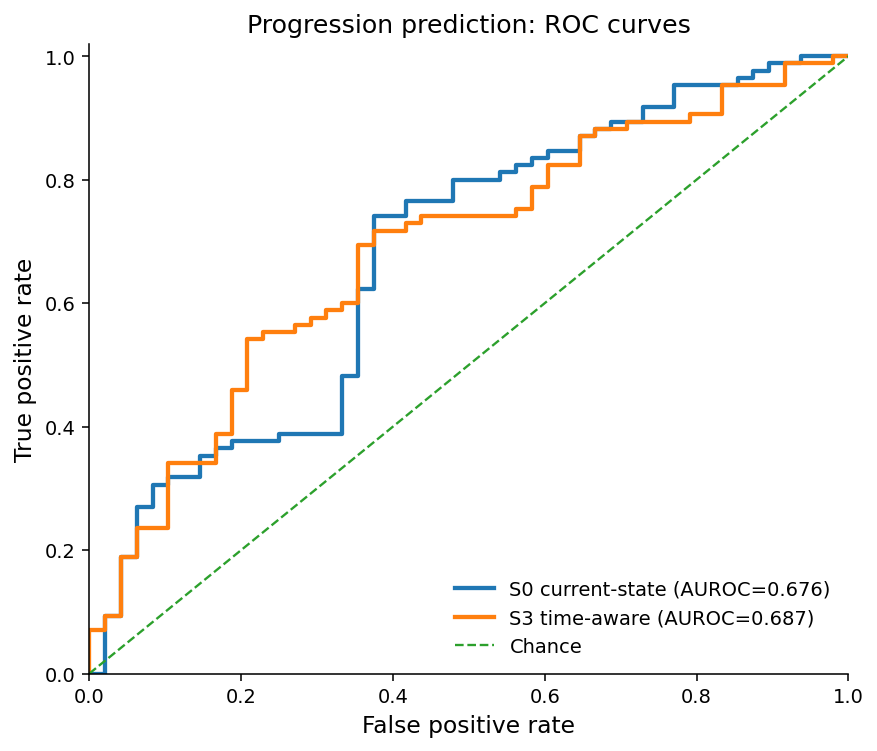

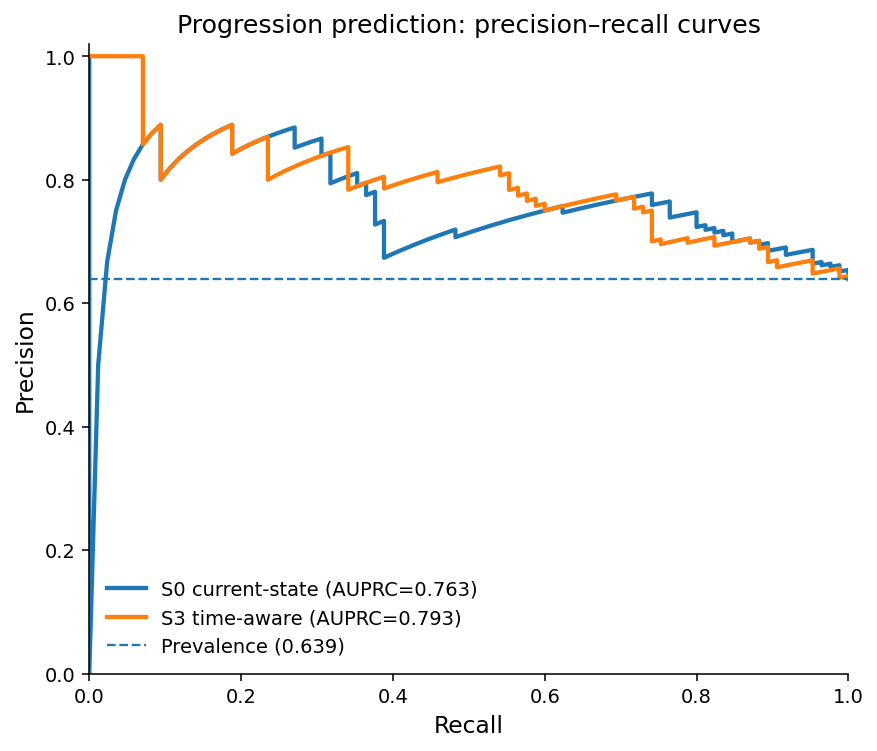

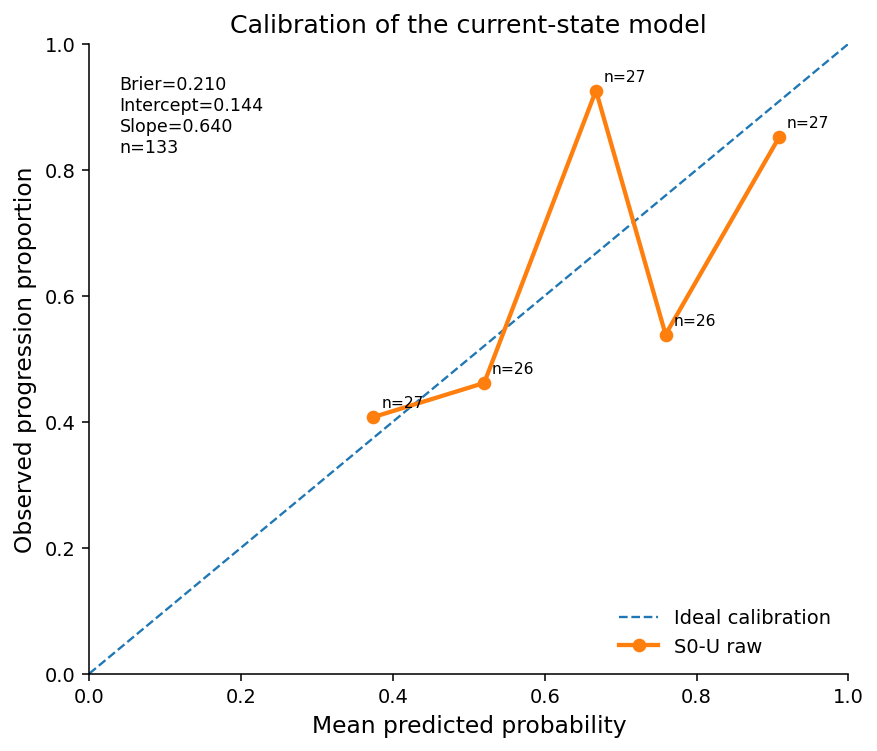

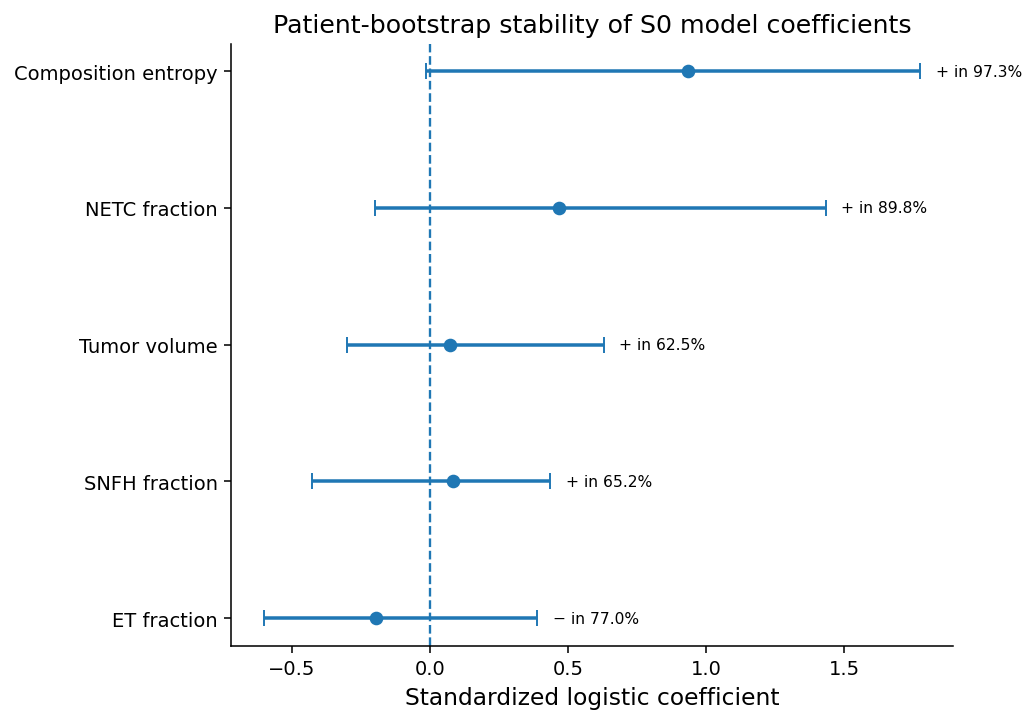

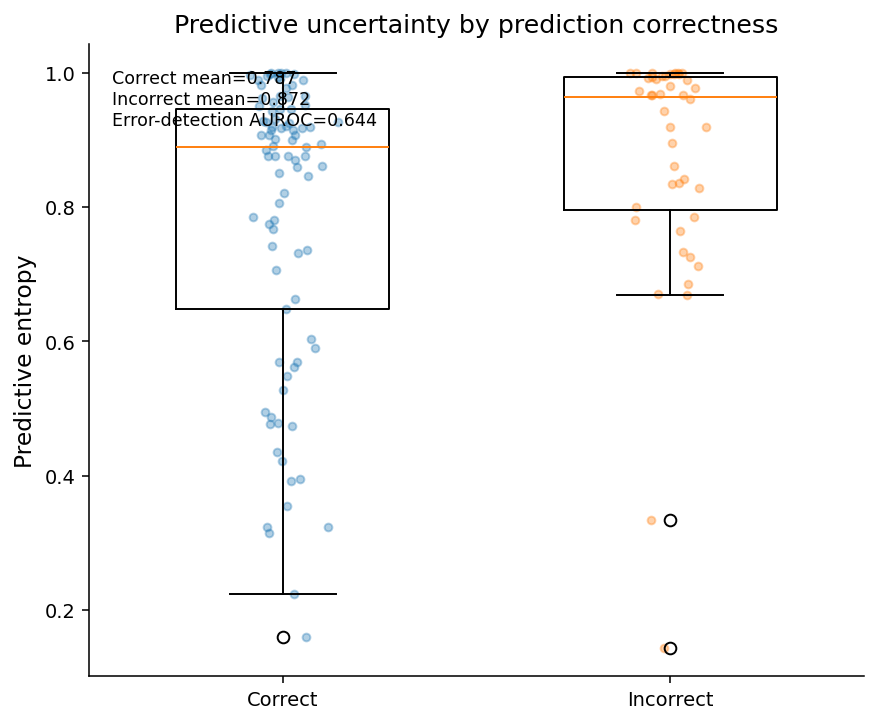

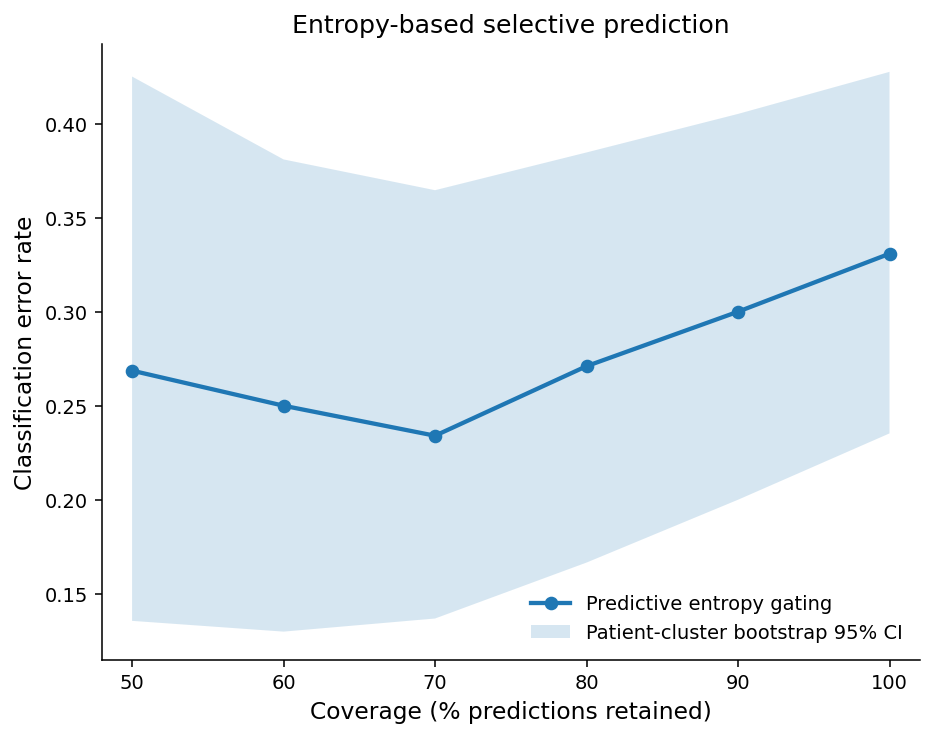


SAVING FINAL TABLES
SAVED: /kaggle/working/Phase7D_Final_Figures_Tables/Table1_Primary_Model_Performance.csv
SAVED: /kaggle/working/Phase7D_Final_Figures_Tables/Table2_Temporal_Increment.csv
SAVED: /kaggle/working/Phase7D_Final_Figures_Tables/Table3_Patient_Level_Sensitivity.csv
SAVED: /kaggle/working/Phase7D_Final_Figures_Tables/Table4_Coefficient_Stability.csv
SAVED: /kaggle/working/Phase7D_Final_Figures_Tables/Table5_Entropy_Risk_Coverage.csv
SAVED: /kaggle/working/Phase7D_Final_Figures_Tables/Table6_Calibration.csv
SAVED: /kaggle/working/Phase7D_Final_Figures_Tables/Table7_Key_Results_Summary.csv

PHASE 7D COMPLETE
Output directory: /kaggle/working/Phase7D_Final_Figures_Tables
Figures generated: 6
PDF figures generated: 6
CSV tables generated: 7

Files:
  Figure1_ROC_S0_vs_S3.pdf
  Figure1_ROC_S0_vs_S3.png
  Figure2_PR_S0_vs_S3.pdf
  Figure2_PR_S0_vs_S3.png
  Figure3_S0_Calibration.pdf
  Figure3_S0_Calibration.png
  Figure4_S0_Coefficient_Stability.pdf
  Figure4_S0_Coefficient_Sta

In [31]:
# =============================================================================
# PHASE 7D
# PUBLICATION-READY FIGURES + FINAL CONSOLIDATED TABLES
# =============================================================================
#
# Frozen analyses only:
#   Figure 1: ROC curves — S0-U vs S3-Matched
#   Figure 2: Precision-Recall curves — S0-U vs S3-Matched
#   Figure 3: S0 raw calibration curve
#   Figure 4: S0 coefficient-stability forest plot
#   Figure 5: Uncertainty score vs prediction correctness
#   Figure 6: Entropy-based risk-coverage curve
#
# Tables:
#   T1 Final model performance
#   T2 Patient-level sensitivity
#   T3 Coefficient stability
#   T4 Uncertainty gating
#   T5 Calibration
#
# NO retraining.
# NO model selection.
# NO threshold optimization.
# =============================================================================


# =============================================================================
# 1. IMPORTS
# =============================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

warnings.filterwarnings("ignore")


# =============================================================================
# 2. OUTPUT DIRECTORY
# =============================================================================

OUT = "/kaggle/working/Phase7D_Final_Figures_Tables"

os.makedirs(
    OUT,
    exist_ok=True
)


# =============================================================================
# 3. INPUT FILES
# =============================================================================

S0_FILE = (
    "/kaggle/working/"
    "Phase6_Calibration/"
    "Phase6_OOF_Probabilities.csv"
)

S3_FILE = (
    "/kaggle/working/"
    "Phase6B_Matched_Temporal/"
    "Phase6B_Matched_S3_OOF.csv"
)

BOOTSTRAP_COMPARISON_FILE = (
    "/kaggle/working/"
    "Phase6B2_Paired_Bootstrap/"
    "Phase6B2_Paired_Bootstrap_Comparison.csv"
)

UNCERTAINTY_FILE = (
    "/kaggle/working/"
    "Phase6C_A_S0_Predictive_Uncertainty/"
    "Phase6C_A_S0_Predictive_Uncertainty.csv"
)

RISK_FILE = (
    "/kaggle/working/"
    "Phase6D_Uncertainty_Gating/"
    "Phase6D_Risk_Coverage_Point_Estimates.csv"
)

RISK_CI_FILE = (
    "/kaggle/working/"
    "Phase6D_Uncertainty_Gating/"
    "Phase6D_Risk_Coverage_95CI.csv"
)

DELTA_FILE = (
    "/kaggle/working/"
    "Phase6D_Uncertainty_Gating/"
    "Phase6D_Paired_Change_vs_Full_Coverage.csv"
)

COEF_FILE = (
    "/kaggle/working/"
    "Phase7B_S0_Coefficient_Stability/"
    "Phase7B_Bootstrap_Coefficient_Summary.csv"
)

PATIENT_LEVEL_FILE = (
    "/kaggle/working/"
    "Phase7A_Patient_Level_Sensitivity/"
    "Phase7A_Observation_vs_Patient_Level.csv"
)

PATIENT_CI_FILE = (
    "/kaggle/working/"
    "Phase7A_Patient_Level_Sensitivity/"
    "Phase7A_Model_95CI.csv"
)

PATIENT_PAIRED_FILE = (
    "/kaggle/working/"
    "Phase7A_Patient_Level_Sensitivity/"
    "Phase7A_Paired_S3_vs_S0.csv"
)

CALIBRATION_FILE = (
    "/kaggle/working/"
    "Phase7C_Leakage_Safe_Calibration/"
    "Phase7C_S0_Calibrated_OOF.csv"
)

CALIBRATION_PERFORMANCE_FILE = (
    "/kaggle/working/"
    "Phase7C_Leakage_Safe_Calibration/"
    "Phase7C_Calibration_Performance.csv"
)


# =============================================================================
# 4. CHECK ESSENTIAL FILES
# =============================================================================

essential_files = [
    S0_FILE,
    S3_FILE,
    UNCERTAINTY_FILE,
    RISK_FILE,
    RISK_CI_FILE,
    COEF_FILE,
    PATIENT_LEVEL_FILE,
    CALIBRATION_FILE,
    CALIBRATION_PERFORMANCE_FILE
]


print("=" * 80)
print("PHASE 7D — FINAL FIGURES AND TABLES")
print("=" * 80)


for f in essential_files:

    if not os.path.exists(f):

        raise FileNotFoundError(
            f"Missing required file:\n{f}"
        )

    print(
        "FOUND:",
        f
    )


# =============================================================================
# 5. LOAD FROZEN OOF PREDICTIONS
# =============================================================================

s0 = pd.read_csv(
    S0_FILE
)

s3 = pd.read_csv(
    S3_FILE
)


required_s0 = [
    "Sample_ID",
    "Patient_ID",
    "Target",
    "S0_U_Raw"
]


required_s3 = [
    "Sample_ID",
    "Patient_ID",
    "Target",
    "S3_Matched_Raw_Probability"
]


for c in required_s0:

    if c not in s0.columns:

        raise RuntimeError(
            f"Missing S0 column: {c}"
        )


for c in required_s3:

    if c not in s3.columns:

        raise RuntimeError(
            f"Missing S3 column: {c}"
        )


oof = s0[
    required_s0
].merge(

    s3[
        required_s3
    ],

    on="Sample_ID",

    suffixes=(
        "_S0",
        "_S3"
    ),

    validate="one_to_one"
)


if len(oof) != 133:

    raise RuntimeError(
        f"Expected 133 matched OOF observations; found {len(oof)}"
    )


if not np.array_equal(
    oof["Target_S0"].values,
    oof["Target_S3"].values
):

    raise RuntimeError(
        "S0/S3 target mismatch."
    )


y = (
    oof["Target_S0"]
    .to_numpy()
    .astype(int)
)


p0 = (
    oof["S0_U_Raw"]
    .to_numpy()
)


p3 = (
    oof[
        "S3_Matched_Raw_Probability"
    ]
    .to_numpy()
)


prevalence = float(
    y.mean()
)


print("\nFrozen OOF cohort")

print(
    "Observations:",
    len(y)
)

print(
    "Positive:",
    int(y.sum())
)

print(
    "Negative:",
    int((y == 0).sum())
)

print(
    "Prevalence:",
    round(
        prevalence,
        4
    )
)


# =============================================================================
# 6. COMMON FIGURE SETTINGS
# =============================================================================

plt.rcParams.update({

    "font.size": 11,

    "axes.labelsize": 12,

    "axes.titlesize": 13,

    "legend.fontsize": 10,

    "xtick.labelsize": 10,

    "ytick.labelsize": 10,

    "figure.dpi": 140,

    "savefig.dpi": 600,

    "axes.spines.top": False,

    "axes.spines.right": False
})


def save_figure(
    fig,
    basename
):

    png = os.path.join(
        OUT,
        basename + ".png"
    )

    pdf = os.path.join(
        OUT,
        basename + ".pdf"
    )

    fig.savefig(
        png,
        bbox_inches="tight"
    )

    fig.savefig(
        pdf,
        bbox_inches="tight"
    )

    plt.show()

    plt.close(fig)

    return png, pdf


# =============================================================================
# FIGURE 1 — ROC
# =============================================================================

fpr0, tpr0, _ = roc_curve(
    y,
    p0
)

fpr3, tpr3, _ = roc_curve(
    y,
    p3
)


auc0 = roc_auc_score(
    y,
    p0
)

auc3 = roc_auc_score(
    y,
    p3
)


fig, ax = plt.subplots(
    figsize=(6.4, 5.5)
)


ax.plot(
    fpr0,
    tpr0,
    linewidth=2.2,
    label=f"S0 current-state (AUROC={auc0:.3f})"
)


ax.plot(
    fpr3,
    tpr3,
    linewidth=2.2,
    label=f"S3 time-aware (AUROC={auc3:.3f})"
)


ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.2,
    label="Chance"
)


ax.set_xlabel(
    "False positive rate"
)

ax.set_ylabel(
    "True positive rate"
)

ax.set_title(
    "Progression prediction: ROC curves"
)

ax.set_xlim(
    0,
    1
)

ax.set_ylim(
    0,
    1.02
)

ax.legend(
    loc="lower right",
    frameon=False
)


fig.tight_layout()


save_figure(
    fig,
    "Figure1_ROC_S0_vs_S3"
)


# =============================================================================
# FIGURE 2 — PRECISION-RECALL
# =============================================================================

precision0, recall0, _ = (
    precision_recall_curve(
        y,
        p0
    )
)

precision3, recall3, _ = (
    precision_recall_curve(
        y,
        p3
    )
)


ap0 = average_precision_score(
    y,
    p0
)

ap3 = average_precision_score(
    y,
    p3
)


fig, ax = plt.subplots(
    figsize=(6.4, 5.5)
)


ax.plot(
    recall0,
    precision0,
    linewidth=2.2,
    label=f"S0 current-state (AUPRC={ap0:.3f})"
)


ax.plot(
    recall3,
    precision3,
    linewidth=2.2,
    label=f"S3 time-aware (AUPRC={ap3:.3f})"
)


ax.axhline(
    prevalence,
    linestyle="--",
    linewidth=1.2,
    label=f"Prevalence ({prevalence:.3f})"
)


ax.set_xlabel(
    "Recall"
)

ax.set_ylabel(
    "Precision"
)

ax.set_title(
    "Progression prediction: precision–recall curves"
)

ax.set_xlim(
    0,
    1
)

ax.set_ylim(
    0,
    1.02
)

ax.legend(
    loc="lower left",
    frameon=False
)


fig.tight_layout()


save_figure(
    fig,
    "Figure2_PR_S0_vs_S3"
)


# =============================================================================
# FIGURE 3 — RAW S0 CALIBRATION
# =============================================================================

cal = pd.read_csv(
    CALIBRATION_FILE
)


cal_perf = pd.read_csv(
    CALIBRATION_PERFORMANCE_FILE
)


cal_y = (
    cal["Target"]
    .to_numpy()
    .astype(int)
)


cal_p = (
    cal["S0_Raw_Probability"]
    .to_numpy()
)


# Use quantile groups for display only.
# Formal ECE remains the prespecified 10 equal-width-bin analysis.

n_display_bins = 5


display_cal = pd.DataFrame({

    "Target":
        cal_y,

    "Probability":
        cal_p
})


display_cal[
    "Calibration_Group"
] = pd.qcut(

    display_cal[
        "Probability"
    ],

    q=n_display_bins,

    labels=False,

    duplicates="drop"
)


display_curve = (

    display_cal

    .groupby(
        "Calibration_Group"
    )

    .agg(

        Mean_Predicted=(
            "Probability",
            "mean"
        ),

        Observed_Rate=(
            "Target",
            "mean"
        ),

        N=(
            "Target",
            "size"
        )
    )

    .reset_index()
)


raw_perf = cal_perf[
    cal_perf["Model"]
    ==
    "S0-U Raw"
].iloc[0]


fig, ax = plt.subplots(
    figsize=(6.4, 5.5)
)


ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.2,
    label="Ideal calibration"
)


ax.plot(
    display_curve[
        "Mean_Predicted"
    ],

    display_curve[
        "Observed_Rate"
    ],

    marker="o",
    linewidth=2.2,
    label="S0-U raw"
)


for _, row in display_curve.iterrows():

    ax.annotate(

        f"n={int(row['N'])}",

        (
            row[
                "Mean_Predicted"
            ],

            row[
                "Observed_Rate"
            ]
        ),

        xytext=(4, 5),

        textcoords="offset points",

        fontsize=8
    )


ax.set_xlabel(
    "Mean predicted probability"
)

ax.set_ylabel(
    "Observed progression proportion"
)

ax.set_title(
    "Calibration of the current-state model"
)

ax.set_xlim(
    0,
    1
)

ax.set_ylim(
    0,
    1
)


annotation = (

    f"Brier={raw_perf['Brier']:.3f}\n"
    f"Intercept={raw_perf['Calibration_Intercept']:.3f}\n"
    f"Slope={raw_perf['Calibration_Slope']:.3f}\n"
    f"n={len(cal_y)}"
)


ax.text(
    0.04,
    0.95,
    annotation,
    transform=ax.transAxes,
    verticalalignment="top",
    fontsize=9
)


ax.legend(
    frameon=False,
    loc="lower right"
)


fig.tight_layout()


save_figure(
    fig,
    "Figure3_S0_Calibration"
)


# =============================================================================
# FIGURE 4 — COEFFICIENT STABILITY FOREST PLOT
# =============================================================================

coef = pd.read_csv(
    COEF_FILE
)


desired_order = [

    "Composition entropy",
    "NETC fraction",
    "Tumor volume",
    "SNFH fraction",
    "ET fraction"
]


coef[
    "Feature_Label"
] = pd.Categorical(

    coef[
        "Feature_Label"
    ],

    categories=desired_order,

    ordered=True
)


coef_plot = (

    coef

    .sort_values(
        "Feature_Label"
    )

    .reset_index(
        drop=True
    )
)


y_positions = np.arange(
    len(coef_plot)
)


medians = (
    coef_plot[
        "Median_Coefficient"
    ]
    .to_numpy()
)


lower = (
    coef_plot[
        "CI_Lower"
    ]
    .to_numpy()
)


upper = (
    coef_plot[
        "CI_Upper"
    ]
    .to_numpy()
)


xerr = np.vstack(
    [
        medians - lower,
        upper - medians
    ]
)


fig, ax = plt.subplots(
    figsize=(7.5, 5.3)
)


ax.errorbar(
    medians,
    y_positions,
    xerr=xerr,
    fmt="o",
    capsize=4,
    linewidth=1.8
)


ax.axvline(
    0,
    linestyle="--",
    linewidth=1.2
)


ax.set_yticks(
    y_positions
)

ax.set_yticklabels(
    coef_plot[
        "Feature_Label"
    ]
)


ax.invert_yaxis()


ax.set_xlabel(
    "Standardized logistic coefficient"
)

ax.set_title(
    "Patient-bootstrap stability of S0 model coefficients"
)


for i, row in coef_plot.iterrows():

    dominant = max(
        row[
            "Fraction_Positive"
        ],
        row[
            "Fraction_Negative"
        ]
    )

    direction = (
        "+"
        if row[
            "Fraction_Positive"
        ]
        >=
        row[
            "Fraction_Negative"
        ]
        else "−"
    )

    ax.annotate(

        f"{direction} in {100*dominant:.1f}%",

        (
            row[
                "CI_Upper"
            ],
            i
        ),

        xytext=(8, 0),

        textcoords="offset points",

        va="center",

        fontsize=8
    )


fig.tight_layout()


save_figure(
    fig,
    "Figure4_S0_Coefficient_Stability"
)


# =============================================================================
# FIGURE 5 — UNCERTAINTY BY CORRECTNESS
# =============================================================================

unc = pd.read_csv(
    UNCERTAINTY_FILE
)


unc[
    "Prediction"
] = (

    unc[
        "Bootstrap_Mean_Probability"
    ]
    >= 0.5

).astype(int)


unc[
    "Correct"
] = (

    unc[
        "Prediction"
    ]
    ==
    unc[
        "Target"
    ]

)


correct_entropy = (

    unc.loc[
        unc["Correct"],
        "Predictive_Entropy"
    ]
    .to_numpy()
)


incorrect_entropy = (

    unc.loc[
        ~unc["Correct"],
        "Predictive_Entropy"
    ]
    .to_numpy()
)


fig, ax = plt.subplots(
    figsize=(6.4, 5.3)
)


box = ax.boxplot(

    [
        correct_entropy,
        incorrect_entropy
    ],

    labels=[
        "Correct",
        "Incorrect"
    ],

    showfliers=True,

    widths=0.55
)


# Add jittered individual observations.

rng = np.random.default_rng(
    2026
)


for x_position, values in [

    (
        1,
        correct_entropy
    ),

    (
        2,
        incorrect_entropy
    )
]:

    jitter = rng.normal(
        x_position,
        0.045,
        len(values)
    )

    ax.scatter(
        jitter,
        values,
        alpha=0.35,
        s=16
    )


ax.set_ylabel(
    "Predictive entropy"
)

ax.set_title(
    "Predictive uncertainty by prediction correctness"
)


ax.text(
    0.03,
    0.96,

    (
        f"Correct mean={correct_entropy.mean():.3f}\n"
        f"Incorrect mean={incorrect_entropy.mean():.3f}\n"
        f"Error-detection AUROC=0.644"
    ),

    transform=ax.transAxes,

    va="top",

    fontsize=9
)


fig.tight_layout()


save_figure(
    fig,
    "Figure5_Entropy_Correct_vs_Incorrect"
)


# =============================================================================
# FIGURE 6 — ENTROPY RISK-COVERAGE
# =============================================================================

risk = pd.read_csv(
    RISK_FILE
)


risk_ci = pd.read_csv(
    RISK_CI_FILE
)


risk_entropy = risk[
    risk["Uncertainty"]
    ==
    "Predictive_Entropy"
].copy()


risk_entropy = risk_entropy.sort_values(
    "Requested_Coverage"
)


error_ci = risk_ci[
    (
        risk_ci["Uncertainty"]
        ==
        "Predictive_Entropy"
    )
    &
    (
        risk_ci["Metric"]
        ==
        "Error_Rate"
    )
].copy()


error_ci = error_ci.sort_values(
    "Coverage"
)


coverage = (
    risk_entropy[
        "Requested_Coverage"
    ]
    .to_numpy()
    *
    100
)


risk_values = (
    risk_entropy[
        "Error_Rate"
    ]
    .to_numpy()
)


# Align CI by coverage.

ci_map = {

    round(
        float(row["Coverage"]),
        4
    ):
        (
            row["CI_Lower"],
            row["CI_Upper"]
        )

    for _, row in error_ci.iterrows()
}


lower_ci = np.asarray(
    [
        ci_map[
            round(
                float(c / 100),
                4
            )
        ][0]

        for c in coverage
    ]
)


upper_ci = np.asarray(
    [
        ci_map[
            round(
                float(c / 100),
                4
            )
        ][1]

        for c in coverage
    ]
)


fig, ax = plt.subplots(
    figsize=(6.8, 5.4)
)


ax.plot(
    coverage,
    risk_values,
    marker="o",
    linewidth=2.2,
    label="Predictive entropy gating"
)


ax.fill_between(
    coverage,
    lower_ci,
    upper_ci,
    alpha=0.18,
    label="Patient-cluster bootstrap 95% CI"
)


ax.set_xlabel(
    "Coverage (% predictions retained)"
)

ax.set_ylabel(
    "Classification error rate"
)

ax.set_title(
    "Entropy-based selective prediction"
)


ax.set_xlim(
    48,
    102
)


ax.set_xticks(
    [50, 60, 70, 80, 90, 100]
)


ax.legend(
    frameon=False
)


fig.tight_layout()


save_figure(
    fig,
    "Figure6_Entropy_Risk_Coverage"
)


# =============================================================================
# TABLE 1 — FINAL PRIMARY MODEL PERFORMANCE
# =============================================================================
#
# Frozen patient-cluster CIs from Phase 6B-2.
# =============================================================================

table1 = pd.DataFrame({

    "Model": [
        "S0-U current-state",
        "S3-Matched time-aware"
    ],

    "N_Observations": [
        133,
        133
    ],

    "N_Patients": [
        74,
        74
    ],

    "AUROC": [
        0.6760,
        0.6868
    ],

    "AUROC_95CI": [
        "0.5647–0.7863",
        "0.5587–0.8072"
    ],

    "AUPRC": [
        0.7631,
        0.7925
    ],

    "AUPRC_95CI": [
        "0.6396–0.8834",
        "0.6548–0.9101"
    ],

    "Brier": [
        0.2098,
        0.2188
    ],

    "Brier_95CI": [
        "0.1684–0.2557",
        "0.1986–0.2385"
    ]
})


# =============================================================================
# TABLE 2 — PAIRED TEMPORAL INCREMENT
# =============================================================================

table2 = pd.DataFrame({

    "Metric": [
        "AUROC",
        "AUPRC",
        "Brier"
    ],

    "S3_minus_S0": [
        0.0108,
        0.0294,
        0.0090
    ],

    "Patient_Cluster_Bootstrap_95CI": [
        "-0.0874 to +0.0941",
        "-0.0816 to +0.1190",
        "-0.0210 to +0.0362"
    ],

    "Interpretation": [
        "Numerically higher S3 discrimination; uncertain",
        "Numerically higher S3 precision-recall performance; uncertain",
        "Numerically lower Brier for S0; uncertain"
    ]
})


# =============================================================================
# TABLE 3 — PATIENT-LEVEL SENSITIVITY
# =============================================================================

patient_level_table = pd.read_csv(
    PATIENT_LEVEL_FILE
)


table3 = patient_level_table.copy()


# =============================================================================
# TABLE 4 — COEFFICIENT STABILITY
# =============================================================================

table4 = coef[
    [
        "Feature_Label",
        "Median_Coefficient",
        "CI_Lower",
        "CI_Upper",
        "Fraction_Positive",
        "Fraction_Negative"
    ]
].copy()


table4["Dominant_Sign_Fraction"] = (

    table4[
        [
            "Fraction_Positive",
            "Fraction_Negative"
        ]
    ]
    .max(
        axis=1
    )
)


# =============================================================================
# TABLE 5 — ENTROPY GATING
# =============================================================================

table5 = risk_entropy[
    [
        "Requested_Coverage",
        "Retained_Observations",
        "Retained_Patients",
        "AUROC",
        "AUPRC",
        "Brier",
        "Balanced_Accuracy",
        "Error_Rate"
    ]
].copy()


# =============================================================================
# TABLE 6 — CALIBRATION
# =============================================================================

table6 = cal_perf[
    [
        "Model",
        "AUROC",
        "AUPRC",
        "Brier",
        "LogLoss",
        "ECE",
        "Calibration_Intercept",
        "Calibration_Slope"
    ]
].copy()


# =============================================================================
# TABLE 7 — FINAL KEY RESULTS SUMMARY
# =============================================================================

table7 = pd.DataFrame({

    "Analysis": [

        "Primary S0 current-state model",

        "Matched S3 temporal model",

        "Temporal increment",

        "Latest-prediction patient sensitivity",

        "Most stable biological feature",

        "Entropy uncertainty discrimination",

        "Entropy gating at 90% coverage",

        "Entropy gating at 80% coverage",

        "Entropy gating at 70% coverage",

        "Leakage-safe Platt calibration"
    ],

    "Key_Result": [

        "AUROC 0.676; AUPRC 0.763; Brier 0.210",

        "AUROC 0.687; AUPRC 0.793; Brier 0.219",

        "Delta AUROC +0.011 (95% CI -0.087 to 0.094)",

        "S0 AUROC 0.702; S3 AUROC 0.752",

        "Composition entropy positive in 97.3% of patient bootstraps",

        "Error-detection AUROC 0.644",

        "Error 0.300 vs 0.331 at full coverage",

        "Error 0.271 vs 0.331 at full coverage",

        "Error 0.234 vs 0.331 at full coverage",

        "ECE improved, but Brier and log loss worsened"
    ],

    "Interpretation": [

        "Stable current-state reference model",

        "Numerically higher discrimination with temporal information",

        "Incremental temporal benefit remains uncertain",

        "Direction preserved when each patient contributes once",

        "Strongest directionally stable predictive association",

        "Entropy moderately identifies difficult predictions",

        "Small selective-prediction error reduction",

        "Clear selective-prediction error reduction",

        "Largest observed error reduction among prespecified coverages",

        "Raw S0 probabilities retained"
    ]
})


# =============================================================================
# SAVE FINAL TABLES
# =============================================================================

tables = {

    "Table1_Primary_Model_Performance.csv":
        table1,

    "Table2_Temporal_Increment.csv":
        table2,

    "Table3_Patient_Level_Sensitivity.csv":
        table3,

    "Table4_Coefficient_Stability.csv":
        table4,

    "Table5_Entropy_Risk_Coverage.csv":
        table5,

    "Table6_Calibration.csv":
        table6,

    "Table7_Key_Results_Summary.csv":
        table7
}


print("\n" + "=" * 80)
print("SAVING FINAL TABLES")
print("=" * 80)


for filename, table in tables.items():

    path = os.path.join(
        OUT,
        filename
    )

    table.to_csv(
        path,
        index=False
    )

    print(
        "SAVED:",
        path
    )


# =============================================================================
# FINAL MANIFEST
# =============================================================================

files = sorted(
    os.listdir(
        OUT
    )
)


manifest = pd.DataFrame({

    "File": files
})


manifest_path = os.path.join(
    OUT,
    "Phase7D_Output_Manifest.csv"
)


manifest.to_csv(
    manifest_path,
    index=False
)


print("\n" + "=" * 80)
print("PHASE 7D COMPLETE")
print("=" * 80)


print(
    "Output directory:",
    OUT
)


print(
    "Figures generated:",
    len(
        [
            f
            for f in files
            if f.endswith(".png")
        ]
    )
)


print(
    "PDF figures generated:",
    len(
        [
            f
            for f in files
            if f.endswith(".pdf")
        ]
    )
)


print(
    "CSV tables generated:",
    len(
        [
            f
            for f in files
            if f.endswith(".csv")
        ]
    )
)


print("\nFiles:")


for f in files:

    print(
        " ",
        f
    )


print("=" * 80)